In [1]:
!pip install -q pdfplumber
import pdfplumber

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 62.3 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 99.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 63.8 MB/s eta 0:00:00:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 5.50.0 requires pillow<12.0,>=8.0, but you have pillow 12.3.0 which is incompatible.


In [2]:
import os, re, glob, cv2, time, numpy as np, pandas as pd, pdfplumber
from collections import Counter, defaultdict
from PIL import Image

BASE   = '/kaggle/input/datasets/roharathor'
TARGET = 1024
EXTS   = ('.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp')

# ---------- 1. DIRECTORIES ----------
NORMAL_DIRS = {
    'normal 1'        : f'{BASE}/last-final-test-dataset/normal 1/normal 1',
    'normal_new'      : f'{BASE}/last-final-test-dataset/normal_new/normal_new',
    'normal_testdata' : f'{BASE}/last-final-test-dataset/normal_testdata/normal_testdata',
    'aditi_part1'     : f'{BASE}/aditi-dataset/aitit_part1/aitit_part1',
    'aditi_part2'     : f'{BASE}/aditi-dataset/aditi_part2/aditi_part2',
    'iit_part1'       : f'{BASE}/iit-dataset/iit2_part1/iit2_part1',
    'iit_part2'       : f'{BASE}/iit-dataset/iit2_part2/New folder',
    'omkar_part1'     : f'{BASE}/omkar-dataset/omkar_part1/New folder (2)',
    'omkar_part2'     : f'{BASE}/omkar-dataset/omkar_part2/New folder',
}

ABNORMAL_DIRS = {
    'abn_old_1'     : f'{BASE}/last-final-test-dataset/abnormal 1 (2)/abnormal 1',
    'abn_old_2'     : f'{BASE}/last-final-test-dataset/abnormal_testdata/abnormal_testdata',
    'tsetan_dolker' : f'{BASE}/again-data-set/11)Tsetan dolker',
    'rida_ashraf'   : f'{BASE}/last-data-final/18)Rida ashraf',
    'tanya_mittal'  : f'{BASE}/machine-dataset/1)Tanya mittal',
}
ABNORMAL_DIRS.update({d: f'{BASE}/new-data/{d}/{d}'
                      for d in sorted(os.listdir(f'{BASE}/new-data'))})

for tag, d in {**NORMAL_DIRS, **ABNORMAL_DIRS}.items():
    if not os.path.isdir(d): print(f"  !! MISSING: {tag} -> {d}")

# ---------- 2. GENE SHEET ----------
PDF = f'{BASE}/final-gean-data-set/FINAL SHEET  .pdf'
sheet = {}
with pdfplumber.open(PDF) as pdf:
    for p in pdf.pages:
        for ln in (p.extract_text() or '').split('\n'):
            ln = ln.strip()
            m = re.search(r'(\d{2,3})-([RL])\s+(.+?)\s+([A-Z0-9]+)\s+(\d+)\s*$', ln)
            if not m: continue
            code, eye, ph_, gn, _ = m.groups()
            nm = re.sub(r'\s+', ' ', re.sub(r'^\d+\s+', '', ln[:m.start()].strip()).upper()).strip()
            if nm: sheet[nm] = (gn, ph_.strip(), code)
print(f"sheet: {len(sheet)} patients, {len(set(v[0] for v in sheet.values()))} genes")

# ---------- 3. NAME MATCHING ----------
def nkey(s):
    s = re.sub(r'\.(jpg|jpeg|png|bmp|tif|tiff|webp)$', '', str(s), flags=re.I)
    s = re.sub(r'[_\-\s]+(L|R)$', '', s, flags=re.I)
    return re.sub(r'[^a-z]', '', s.lower())

def eye_of(s):
    m = re.search(r'[_\-\s]+(L|R)(?:\.\w+)?$', str(s), flags=re.I)
    return m.group(1).upper() if m else None

sk = {nkey(k): k for k in sheet}

FIX = {'aarav':'aaravsuryav', 'anjuam':'anjumbano', 'mohmanadabbs':'mohammedabbas',
       'rubi':'ruby', 'santosh':'santhoshjha', 'satyendra':'satendrayadav',
       'shubam':'shubhammishra', 'aarnav':'arnavgupta', 'aranav':'arnavgupta',
       'ayan':'mohammedayan', 'rupan':'rupamkumar', 'tanaya':'tanyamittal',
       'vickey':'vickykumar', 'oushkarjha':'pushkarjha', 'anushhree':'anushree',
       'rajskumari':'rajkumari', 'tamnanah':'tamannah', 'fajjian':'faijjan',
       'dindayalsharama':'dindayalsharma', 'ridaasraf':'ridaashraf'}

def resolve(k):
    k = FIX.get(k, k)
    if k in sk: return sk[k]
    hit = [v for kk, v in sk.items() if kk.startswith(k) or k.startswith(kk)]
    return hit[0] if len(hit) == 1 else None

# ---------- 4. ABNORMAL: one image per (patient, eye) ----------
best, unres, noeye = {}, [], []
for tag, d in sorted(ABNORMAL_DIRS.items()):
    if not os.path.isdir(d): continue
    for f in sorted(os.listdir(d)):
        if not f.lower().endswith(EXTS): continue
        nm, e = resolve(nkey(f)), eye_of(f)
        if   nm is None: unres.append(f'{tag}/{f}')
        elif e  is None: noeye.append(f'{tag}/{f}')
        else: best.setdefault((nm, e), (os.path.join(d, f), tag))

print(f"\nABNORMAL  pairs {len(best)}/173   patients {len(set(p for p,_ in best))}/88"
      f"   genes {len(set(sheet[p][0] for p,_ in best))}/39")
print(f"  eyes/patient: {dict(Counter(Counter(p for p,_ in best).values()))}")
print(f"  sheet me hai, image nahi: {sorted(set(sheet)-set(p for p,_ in best))}")
print(f"  unresolved ({len(unres)}), no-eye ({len(noeye)})  <- abn_old junk")

# ---------- 5. NORMAL: pixel dedup ----------
def phash_file(p):
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if im is None:
        try: im = np.array(Image.open(p).convert('L'))
        except Exception: return None
    import hashlib
    return hashlib.md5(cv2.resize(im, (64,64), interpolation=cv2.INTER_AREA).tobytes()).hexdigest()

nrows, seen = [], {}
for tag, d in sorted(NORMAL_DIRS.items()):
    for f in sorted(os.listdir(d)):
        if not f.lower().endswith(EXTS): continue
        p = os.path.join(d, f)
        h = phash_file(p)
        if h is None: print("  decode fail:", p); continue
        if h in seen: continue
        seen[h] = p
        nrows.append(dict(path=p, batch=tag, fname=f, label=0,
                          patient=f'N_{tag}', gene='', pheno=''))
print(f"\nNORMAL    {len(nrows)}/393 unique")

# ---------- 6. MANIFEST ----------
arows = [dict(path=pth, batch=tg, fname=os.path.basename(pth), label=1,
              patient=nm, gene=sheet[nm][0], pheno=sheet[nm][1])
         for (nm, e), (pth, tg) in sorted(best.items())]
man = pd.DataFrame(arows + nrows).reset_index(drop=True)

# ---------- 7. LOAD IMAGES ----------
def load_resized(path):
    raw = cv2.imread(path, cv2.IMREAD_REDUCED_COLOR_2)
    if raw is None: raw = cv2.imread(path)
    if raw is None:
        try: raw = cv2.cvtColor(np.array(Image.open(path).convert('RGB')), cv2.COLOR_RGB2BGR)
        except Exception: return None
    h, w = raw.shape[:2]; s = TARGET / max(h, w)
    return cv2.cvtColor(cv2.resize(raw, (int(round(w*s)), int(round(h*s))),
                        interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)

imgs, ok, t0 = [], [], time.time()
for i, p in enumerate(man.path):
    im = load_resized(p)
    if im is None: print("FAIL:", p); continue
    imgs.append(im); ok.append(i)
    if (i+1) % 150 == 0 or i == len(man)-1:
        print(f"  {i+1}/{len(man)} ({time.time()-t0:.0f}s)")

man     = man.iloc[ok].reset_index(drop=True)
labels  = man.label.values
patient = man.patient.values
gene    = man.gene.values
pheno   = man.pheno.values
batch   = man.batch.values
names   = man.fname.values

print(f"\n{'='*54}")
print(f"images  {len(imgs)}   normal {(labels==0).sum()}   abnormal {(labels==1).sum()}")
print(f"patients {len(set(patient[labels==1]))}   genes {len(set(gene[labels==1]))}"
      f"   pheno {len(set(pheno[labels==1]))}")
print(f"RAM {sum(im.nbytes for im in imgs)/1e9:.2f} GB")
print('='*54)

os.makedirs('/kaggle/working/results/features', exist_ok=True)
man.to_csv('/kaggle/working/results/features/manifest.csv', index=False)

sheet: 88 patients, 39 genes

ABNORMAL  pairs 173/173   patients 88/88   genes 39/39
  eyes/patient: {2: 85, 1: 3}
  sheet me hai, image nahi: []
  unresolved (24), no-eye (2)  <- abn_old junk

NORMAL    393/393 unique
  150/566 (76s)
  300/566 (139s)
  450/566 (184s)
  566/566 (231s)

images  566   normal 393   abnormal 173
patients 88   genes 39   pheno 7
RAM 1.76 GB


preprocess ready



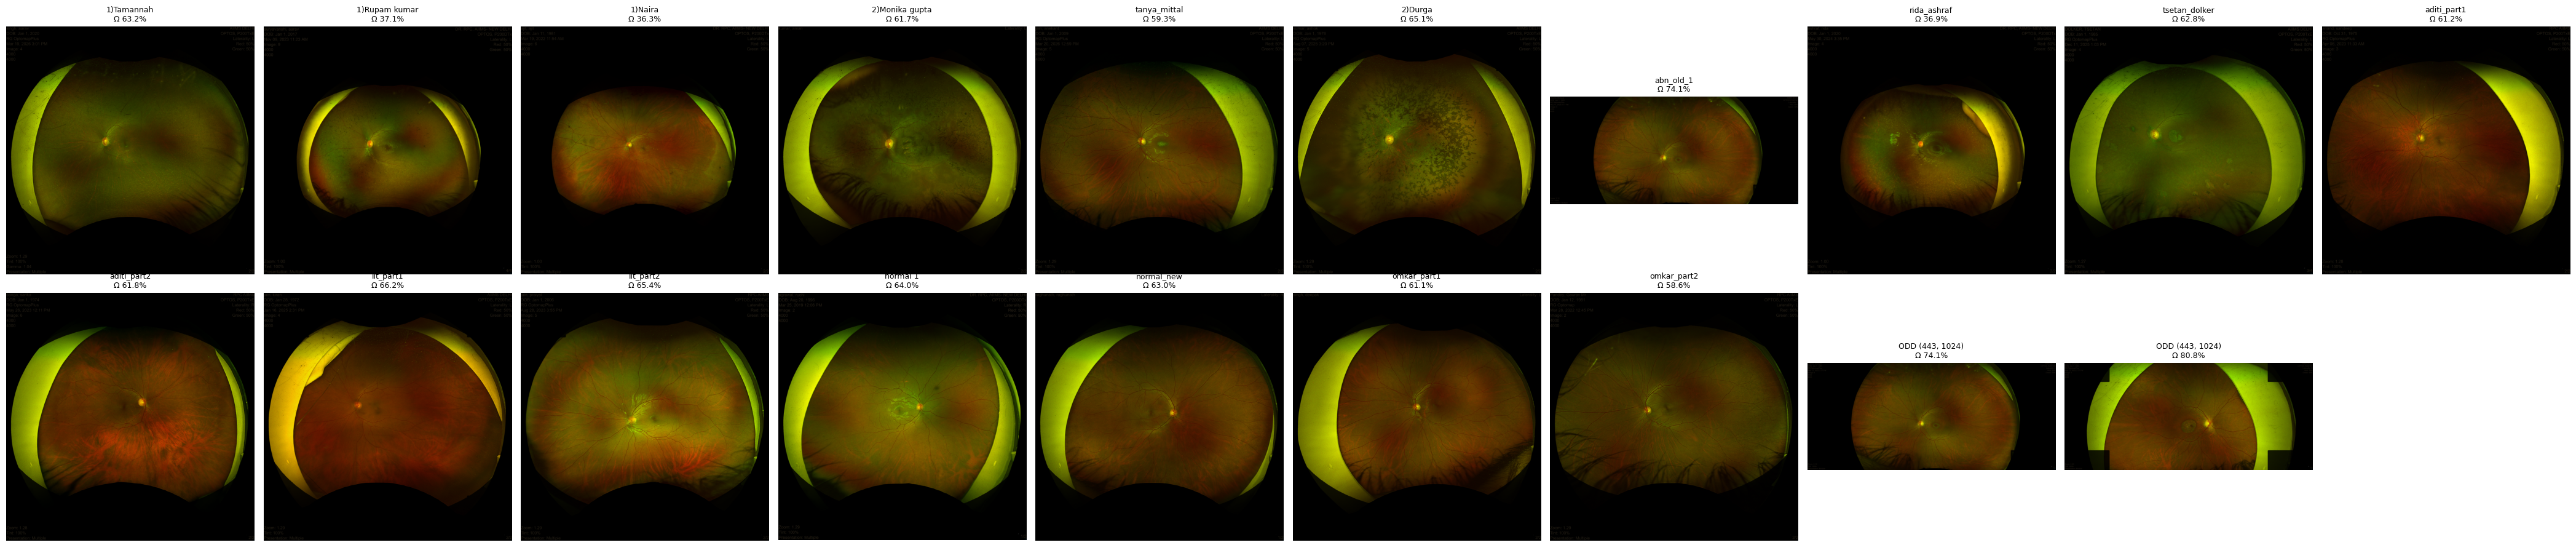

Checking retina mask on all images...
  150/566 (18s)
  300/566 (45s)
  450/566 (65s)

Omega fraction: mean 58.5%  min 32.9%  max 86.8%

Lowest 8 (possible mask failures):
   32.9%  Kumari_arti_Rani_R.jpg               1)Tamannah
   33.6%  Neeraj_Kumar_R.jpg                   tanya_mittal
   33.7%  Robin_R.jpg                          2)Durga
   34.4%  Asha_L.jpg                           1)Tamannah
   35.4%  shree_pal_L.jpg                      2)Monika gupta
   35.4%  export44.jpg                         normal_new
   35.6%  export11.jpg                         normal 1
   35.6%  export56.jpg                         normal_new


In [3]:
import numpy as np, cv2, matplotlib.pyplot as plt

TARGET = 1024

def _resize_keep(img, target=TARGET):
    h, w = img.shape[:2]
    if max(h, w) == target: return img
    s = target / max(h, w)
    return cv2.resize(img, (int(round(w*s)), int(round(h*s))), interpolation=cv2.INTER_AREA)

def _retina_mask(img_rgb, thresh=18, scale=1.02):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    _, th = cv2.threshold(gray, thresh, 255, cv2.THRESH_BINARY)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9,9))
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, k, iterations=3)
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN,  k, iterations=1)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(th, connectivity=8)
    if n <= 1: return (th > 0).astype(np.uint8)
    big = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    mask = (lab == big).astype(np.uint8) * 255
    ff = mask.copy(); hh, ww = mask.shape
    cv2.floodFill(ff, np.zeros((hh+2, ww+2), np.uint8), (0,0), 255)
    mask = cv2.bitwise_or(mask, cv2.bitwise_not(ff))
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        c = max(cnts, key=cv2.contourArea)
        if len(c) >= 5:
            (cx, cy), (MA, ma), ang = cv2.fitEllipse(c)
            em = np.zeros_like(mask)
            cv2.ellipse(em, ((cx,cy),(MA*scale, ma*scale), ang), 255, -1)
            mask = em
    return (mask > 0).astype(np.uint8)

def _text_mask(img_rgb, corner_frac=0.18):
    h, w = img_rgb.shape[:2]
    ch, cw = int(h*corner_frac), int(w*corner_frac)
    corner = np.zeros((h, w), np.uint8)
    corner[0:ch,0:cw]=1; corner[0:ch,w-cw:w]=1
    corner[h-ch:h,0:cw]=1; corner[h-ch:h,w-cw:w]=1
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    hsv  = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    yellow = ((hsv[:,:,0]>15)&(hsv[:,:,0]<45)&(hsv[:,:,1]>80)&(hsv[:,:,2]>120)).astype(np.uint8)
    cand = cv2.bitwise_and(cv2.bitwise_and(yellow, (gray>180).astype(np.uint8)), corner)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(cand, connectivity=8)
    comp = np.zeros((h,w), np.uint8); amax = 0.002*h*w
    for i in range(1, n):
        a  = stats[i, cv2.CC_STAT_AREA]
        ar = stats[i, cv2.CC_STAT_WIDTH]/(stats[i, cv2.CC_STAT_HEIGHT]+1e-6)
        if a < amax and 0.1 < ar < 15: comp[lab==i] = 1
    return cv2.dilate(cv2.bitwise_or(corner, comp),
                      cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5)), 1)

def preprocess(raw_img):
    """Omega = retina(ellipse) - text.  No disc removal, fully automatic."""
    img = _resize_keep(raw_img)
    omega = (_retina_mask(img).astype(bool) & ~_text_mask(img).astype(bool)).astype(np.uint8)
    return img, omega

print("preprocess ready\n")

# ---- sanity check across all batches + odd-shaped images ----
picks = []
seen = set()
for i, b in enumerate(batch):
    if b not in seen: picks.append((i, b)); seen.add(b)
odd = [i for i, im in enumerate(imgs) if im.shape[0] < 600]
picks += [(i, f'ODD {imgs[i].shape[:2]}') for i in odd[:2]]

fig, ax = plt.subplots(2, (len(picks)+1)//2, figsize=(4.2*((len(picks)+1)//2), 9))
ax = ax.ravel()
for j, (idx, tag) in enumerate(picks):
    img, om = preprocess(imgs[idx])
    sh = img.copy(); sh[om==0] = (sh[om==0]*0.15).astype(np.uint8)
    ax[j].imshow(sh); ax[j].axis('off')
    ax[j].set_title(f'{tag.split(":")[-1][:18]}\nΩ {om.sum()/om.size*100:.1f}%', fontsize=9)
for j in range(len(picks), len(ax)): ax[j].axis('off')
plt.tight_layout(); plt.show()

# ---- Ω fraction distribution, to catch failures ----
print("Checking retina mask on all images...")
import time
fracs = []; t0 = time.time()
for i, im in enumerate(imgs):
    _, om = preprocess(im)
    fracs.append(om.sum()/om.size)
    if (i+1) % 150 == 0: print(f"  {i+1}/{len(imgs)} ({time.time()-t0:.0f}s)")
fracs = np.array(fracs)
print(f"\nOmega fraction: mean {fracs.mean()*100:.1f}%  min {fracs.min()*100:.1f}%  max {fracs.max()*100:.1f}%")
low = np.argsort(fracs)[:8]
print(f"\nLowest 8 (possible mask failures):")
for i in low: print(f"  {fracs[i]*100:5.1f}%  {names[i][:34]:36s} {batch[i]}")

In [4]:
!pip install -q --force-reinstall --no-cache-dir "pillow==11.3.0"



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 78.3 MB/s eta 0:00:00a 0:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pdfplumber 0.11.10 requires Pillow>=12.2.0, but you have pillow 11.3.0 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [5]:
import torch, timm, numpy as np, cv2, time

device = torch.device('cuda')
dino = timm.create_model('vit_small_patch14_dinov2.lvd142m',
                         pretrained=True, num_classes=0,
                         dynamic_img_size=True).to(device).eval()
for p in dino.parameters(): p.requires_grad = False

N_PREFIX, EMB, PATCH, IMG_SIZE, DARK = \
    getattr(dino,'num_prefix_tokens',1), dino.embed_dim, 14, 980, 12
_MEAN = torch.tensor([0.485,0.456,0.406], device=device).view(1,3,1,1)
_STD  = torch.tensor([0.229,0.224,0.225], device=device).view(1,3,1,1)

@torch.no_grad()
def valid_cells(raw):
    img, om = preprocess(raw)
    h0, w0 = img.shape[:2]; s = IMG_SIZE/max(h0,w0)
    nh, nw = (int(round(h0*s))//PATCH)*PATCH, (int(round(w0*s))//PATCH)*PATCH
    im = cv2.resize(img, (nw,nh), interpolation=cv2.INTER_AREA)
    t = (torch.from_numpy(im).permute(2,0,1).float().div(255.)[None].to(device)-_MEAN)/_STD
    tok = dino.forward_features(t)[:, N_PREFIX:, :]
    gh, gw = nh//PATCH, nw//PATCH
    f = tok.reshape(1,gh,gw,EMB)[0].cpu().numpy().astype(np.float32)
    om_s = cv2.resize(om.astype(np.uint8),(gw,gh),interpolation=cv2.INTER_AREA)>0
    grn  = cv2.resize(img[:,:,1],(gw,gh),interpolation=cv2.INTER_AREA)
    return img, om, f, om_s & ~((grn < DARK) & om_s)

# descriptors for genotype/phenotype  +  cell counts
X768, ncells = [], []
t0 = time.time()
for i, im in enumerate(imgs):
    _,_,f,v = valid_cells(im)
    c = f[v]
    X768.append(np.concatenate([c.mean(0), c.std(0)]))
    ncells.append(int(v.sum()))
    if (i+1)%100==0 or i==len(imgs)-1:
        el=time.time()-t0
        print(f"  {i+1}/{len(imgs)} ({el:.0f}s, ~{el/(i+1)*(len(imgs)-i-1):.0f}s left)")

X768 = np.array(X768, np.float32); ncells = np.array(ncells)
print(f"\nX768 {X768.shape} | NaN {np.isnan(X768).any()}")
print(f"valid cells: mean {ncells.mean():.0f}  min {ncells.min()}  max {ncells.max()}")

np.savez('/kaggle/working/results/features/feat980.npz',
         X768=X768, ncells=ncells,
         labels=labels, patient=patient, gene=gene, pheno=pheno,
         batch=batch, names=names)
print("saved -> results/features/feat980.npz")


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

  100/566 (34s, ~159s left)
  200/566 (72s, ~132s left)
  300/566 (115s, ~102s left)
  400/566 (156s, ~65s left)
  500/566 (190s, ~25s left)
  566/566 (217s, ~0s left)

X768 (566, 768) | NaN False
valid cells: mean 2447  min 683  max 3962
saved -> results/features/feat980.npz


In [6]:
import torch, timm, numpy as np, cv2, time, pickle, os

device = torch.device('cuda')
dino = timm.create_model('vit_small_patch14_dinov2.lvd142m',
                         pretrained=True, num_classes=0,
                         dynamic_img_size=True).to(device).eval()
for p in dino.parameters(): p.requires_grad = False

N_PREFIX, EMB, PATCH, IMG_SIZE, DARK = \
    getattr(dino,'num_prefix_tokens',1), dino.embed_dim, 14, 980, 12
_MEAN = torch.tensor([0.485,0.456,0.406], device=device).view(1,3,1,1)
_STD  = torch.tensor([0.229,0.224,0.225], device=device).view(1,3,1,1)
print(f"DINOv2 | dim {EMB} | trainable {sum(p.numel() for p in dino.parameters() if p.requires_grad)}")

@torch.no_grad()
def valid_cells(raw):
    img, om = preprocess(raw)
    h0, w0 = img.shape[:2]; s = IMG_SIZE/max(h0,w0)
    nh, nw = (int(round(h0*s))//PATCH)*PATCH, (int(round(w0*s))//PATCH)*PATCH
    im = cv2.resize(img, (nw,nh), interpolation=cv2.INTER_AREA)
    t = (torch.from_numpy(im).permute(2,0,1).float().div(255.)[None].to(device)-_MEAN)/_STD
    tok = dino.forward_features(t)[:, N_PREFIX:, :]
    gh, gw = nh//PATCH, nw//PATCH
    f = tok.reshape(1,gh,gw,EMB)[0].cpu().numpy().astype(np.float32)
    om_s = cv2.resize(om.astype(np.uint8),(gw,gh),interpolation=cv2.INTER_AREA)>0
    grn  = cv2.resize(img[:,:,1],(gw,gh),interpolation=cv2.INTER_AREA)
    return img, om, f, om_s & ~((grn < DARK) & om_s)

# quick test
img, om, f, v = valid_cells(imgs[0])
print(f"grid {f.shape} | valid cells {v.sum()}")

# ---- cache: subsampled cells (for GMM pool) + mean/std descriptor ----
CELLS_PER_IMG = 2500
rng = np.random.RandomState(0)
cells_cache, X768, ncells = [], [], []
t0 = time.time()
for i, im in enumerate(imgs):
    _, _, f, v = valid_cells(im)
    c = f[v]
    X768.append(np.concatenate([c.mean(0), c.std(0)]))
    ncells.append(int(v.sum()))
    if len(c) > CELLS_PER_IMG:
        c = c[rng.choice(len(c), CELLS_PER_IMG, replace=False)]
    cells_cache.append(c.astype(np.float32))
    if (i+1) % 50 == 0 or i == len(imgs)-1:
        el = time.time()-t0
        print(f"  {i+1}/{len(imgs)}  ({el:.0f}s, ~{el/(i+1)*(len(imgs)-i-1):.0f}s left)")

X768   = np.array(X768, np.float32)
ncells = np.array(ncells)
print(f"\nX768 {X768.shape} | NaN {np.isnan(X768).any()}")
print(f"valid cells: mean {ncells.mean():.0f}  min {ncells.min()}  max {ncells.max()}")
print(f"cells_cache memory: {sum(c.nbytes for c in cells_cache)/1e9:.2f} GB")

os.makedirs('/kaggle/working/results/features', exist_ok=True)
np.savez('/kaggle/working/results/features/feat980.npz',
         X768=X768, ncells=ncells,
         labels=labels, patient=patient, gene=gene, pheno=pheno,
         batch=batch, names=names)
with open('/kaggle/working/results/features/cells_cache.pkl','wb') as fh:
    pickle.dump(cells_cache, fh)
print("saved -> results/features/feat980.npz + cells_cache.pkl")

DINOv2 | dim 384 | trainable 0
grid (69, 70, 384) | valid cells 2681
  50/566  (17s, ~176s left)
  100/566  (36s, ~169s left)
  150/566  (55s, ~153s left)
  200/566  (76s, ~140s left)
  250/566  (98s, ~124s left)
  300/566  (120s, ~107s left)
  350/566  (143s, ~88s left)
  400/566  (162s, ~67s left)
  450/566  (179s, ~46s left)
  500/566  (196s, ~26s left)
  550/566  (217s, ~6s left)
  566/566  (223s, ~0s left)

X768 (566, 768) | NaN False
valid cells: mean 2447  min 683  max 3962
cells_cache memory: 2.00 GB
saved -> results/features/feat980.npz + cells_cache.pkl


In [7]:
import numpy as np, time
from collections import Counter
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

# ---------- folds: patient-level for abnormal, batch-stratified for normal ----------
def make_folds(n_splits=5, seed=42):
    rng = np.random.RandomState(seed)
    fold = np.full(len(imgs), -1)
    ab_pats = np.array(sorted(set(p for p in patient[labels==1])))
    ph_ = np.array([pheno[patient==p][0] for p in ab_pats])
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for f, (_, te) in enumerate(skf.split(ab_pats, ph_)):
        for p in ab_pats[te]: fold[patient == p] = f
    for b in np.unique(batch[labels==0]):
        idx = np.where((labels==0) & (batch==b))[0]
        rng.shuffle(idx)
        for k, i in enumerate(idx): fold[i] = k % n_splits
    return fold

fold = make_folds()
print(f"{'fold':>5s} {'normal':>8s} {'abnormal':>10s}")
for f in range(5):
    print(f"{f:5d} {int(((fold==f)&(labels==0)).sum()):8d} "
          f"{int(((fold==f)&(labels==1)).sum()):10d}")
leaks = [p for p in set(patient[labels==1]) if len(set(fold[patient==p]))>1]
print(f"Patients spanning folds: {len(leaks)}")

def metrics(y, p, th):
    yh = (p > th).astype(int)
    tn,fp,fn,tp = confusion_matrix(y, yh, labels=[0,1]).ravel()
    return dict(acc=accuracy_score(y,yh), prec=precision_score(y,yh,zero_division=0),
                sens=recall_score(y,yh,zero_division=0),
                spec=tn/(tn+fp) if (tn+fp) else 0., f1=f1_score(y,yh,zero_division=0),
                tn=tn, fp=fp, fn=fn, tp=tp)

# ---------- one-class fold ----------
def oneclass_fold(f, K=8, npca=64, cal_frac=0.25, seed=0):
    tr_n = np.where((fold != f) & (labels == 0))[0]
    te_i = np.where(fold == f)[0]
    rng = np.random.RandomState(seed + f)
    rng.shuffle(tr_n)
    n_cal = int(round(cal_frac * len(tr_n)))
    cal_i, pool_i = tr_n[:n_cal], tr_n[n_cal:]

    pool = np.vstack([cells_cache[i] for i in pool_i])
    sc = StandardScaler().fit(pool)
    pca = PCA(npca, whiten=True, random_state=0).fit(sc.transform(pool))
    W = pca.transform(sc.transform(pool))
    gmm = GaussianMixture(K, covariance_type='full', reg_covar=1e-3,
                          random_state=0).fit(W)
    tau = np.percentile(-gmm.score_samples(W), 95)

    def frac_tau(i):
        s = -gmm.score_samples(pca.transform(sc.transform(cells_cache[i])))
        return (s > tau).mean()

    cal_s = np.array([frac_tau(i) for i in cal_i])
    th90, th95 = np.percentile(cal_s, 90), np.percentile(cal_s, 95)
    te_s = np.array([frac_tau(i) for i in te_i])
    te_y = labels[te_i]

    return dict(fold=f, tau=tau, th90=th90, th95=th95,
                n_pool=len(pool_i), n_cal=len(cal_i), n_te=len(te_i),
                s=te_s, y=te_y, te_i=te_i,
                auc=roc_auc_score(te_y, te_s),
                m90=metrics(te_y, te_s, th90), m95=metrics(te_y, te_s, th95))

print(f"\n{'='*72}\nDETECTION -- one-class (GMM on normals only), 5-fold\n{'='*72}")
print(f"{'fold':>4s} {'pool':>5s} {'cal':>4s} {'test':>5s} {'tau':>7s} {'th90':>7s} "
      f"{'AUC':>6s} {'acc':>6s} {'sens':>6s} {'spec':>6s} {'F1':>6s} {'time':>6s}")
oc = []
for f in range(5):
    t0 = time.time(); r = oneclass_fold(f); m = r['m90']
    print(f"{f:4d} {r['n_pool']:5d} {r['n_cal']:4d} {r['n_te']:5d} {r['tau']:7.2f} "
          f"{r['th90']:7.4f} {r['auc']:6.3f} {m['acc']:6.3f} {m['sens']:6.3f} "
          f"{m['spec']:6.3f} {m['f1']:6.3f} {time.time()-t0:5.0f}s")
    oc.append(r)

S = np.concatenate([r['s'] for r in oc]); Yv = np.concatenate([r['y'] for r in oc])
print("-"*72)
for lab, key in [('@90th pct','m90'), ('@95th pct','m95')]:
    agg = {k: np.array([r[key][k] for r in oc]) for k in ['acc','prec','sens','spec','f1']}
    print(f"{lab:12s} " + "  ".join(f"{k} {agg[k].mean():.3f}±{agg[k].std():.3f}" for k in agg))
print(f"\nPooled AUC ({len(Yv)} images): {roc_auc_score(Yv, S):.3f}")
th_pool = np.mean([r['th90'] for r in oc])
mp = metrics(Yv, S, th_pool)
print(f"Pooled @mean-th90 ({th_pool:.4f}): acc {mp['acc']:.3f}  prec {mp['prec']:.3f}  "
      f"sens {mp['sens']:.3f}  spec {mp['spec']:.3f}  F1 {mp['f1']:.3f}")
print(f"Confusion: TN {mp['tn']}  FP {mp['fp']}  FN {mp['fn']}  TP {mp['tp']}")

import pickle
pickle.dump(dict(oc=oc, fold=fold), open('/kaggle/working/results/ml_detect_oneclass.pkl','wb'))
print("\nsaved ml_detect_oneclass.pkl")


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


 fold   normal   abnormal
    0       82         35
    1       80         36
    2       78         35
    3       77         34
    4       76         33
Patients spanning folds: 0

DETECTION -- one-class (GMM on normals only), 5-fold
fold  pool  cal  test     tau    th90    AUC    acc   sens   spec     F1   time
   0   233   78   117   89.62  0.1111  0.950  0.906  0.886  0.915  0.849   340s
   1   235   78   116   89.85  0.1004  0.972  0.905  0.917  0.900  0.857   181s
   2   236   79   113   88.80  0.0926  0.981  0.876  0.943  0.846  0.825   230s
   3   237   79   111   89.24  0.0921  0.950  0.874  0.882  0.870  0.811   234s
   4   238   79   109   89.89  0.1013  0.957  0.890  0.970  0.855  0.842   320s
------------------------------------------------------------------------
@90th pct    acc 0.890±0.014  prec 0.770±0.034  sens 0.919±0.033  spec 0.877±0.026  f1 0.837±0.017
@95th pct    acc 0.914±0.016  prec 0.844±0.014  sens 0.879±0.052  spec 0.929±0.006  f1 0.861±0.029

Pooled AUC 

In [9]:
import numpy as np, time, pickle
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import roc_auc_score

# ---------- single split: patient-level abnormal, batch-stratified normal ----------
SEED = 42
rng = np.random.RandomState(SEED)

ab_pats = np.array(sorted(set(p for p in patient[labels==1])))
ph_ = np.array([pheno[patient==p][0] for p in ab_pats])
rng.shuffle(ab_pats)                      # all abnormal -> test (one-class)

split = np.array(['train']*len(imgs), dtype=object)
split[labels == 1] = 'test'
for b in np.unique(batch[labels==0]):
    idx = np.where((labels==0) & (batch==b))[0]
    rng.shuffle(idx)
    k = max(1, int(round(0.20*len(idx))))
    split[idx[:k]] = 'test'
    split[idx[k:]] = 'train'

tr_n = np.where((split=='train') & (labels==0))[0]
te_i = np.where(split=='test')[0]
print(f"Train normals : {len(tr_n)}")
print(f"Test          : {len(te_i)}  ({int((labels[te_i]==0).sum())} normal + "
      f"{int((labels[te_i]==1).sum())} abnormal)")

# ---------- calibration split ----------
rng2 = np.random.RandomState(1)
order = rng2.permutation(len(tr_n))
n_cal = int(round(0.25*len(tr_n)))
cal_i, pool_i = tr_n[order[:n_cal]], tr_n[order[n_cal:]]
print(f"GMM pool {len(pool_i)} | calibration {len(cal_i)}")

# ---------- fit ----------
t0 = time.time()
pool = np.vstack([cells_cache[i] for i in pool_i])
print(f"pool cells: {pool.shape}")
sc  = StandardScaler().fit(pool)
pca = PCA(64, whiten=True, random_state=0).fit(sc.transform(pool))
W   = pca.transform(sc.transform(pool))
print(f"PCA variance: {pca.explained_variance_ratio_.sum():.3f}")
gmm = GaussianMixture(8, covariance_type='full', reg_covar=1e-3,
                      random_state=0).fit(W)
tau = np.percentile(-gmm.score_samples(W), 95)
print(f"GMM iters {gmm.n_iter_} | converged {gmm.converged_} | tau {tau:.2f} "
      f"({time.time()-t0:.0f}s)")

def frac_tau(i):
    s = -gmm.score_samples(pca.transform(sc.transform(cells_cache[i])))
    return (s > tau).mean()

cal_s = np.array([frac_tau(i) for i in cal_i])
th90, th95 = np.percentile(cal_s, 90), np.percentile(cal_s, 95)
print(f"conformal thresholds: 90th {th90:.4f} | 95th {th95:.4f}")

te_s = np.array([frac_tau(i) for i in te_i]); te_y = labels[te_i]

print(f"\n{'='*70}")
print(f"DETECTION -- one-class, single split  ({len(te_i)} test images)")
print("="*70)
print(f"AUC {roc_auc_score(te_y, te_s):.3f}")
print(f"\n{'threshold':>14s} {'value':>8s} {'acc':>7s} {'prec':>7s} {'sens':>7s} {'spec':>7s} {'F1':>7s}")
for nm, th in [('90th pct', th90), ('95th pct', th95)]:
    m = metrics(te_y, te_s, th)
    print(f"{nm:>14s} {th:8.4f} {m['acc']:7.3f} {m['prec']:7.3f} {m['sens']:7.3f} "
          f"{m['spec']:7.3f} {m['f1']:7.3f}")
m90 = metrics(te_y, te_s, th90)
print(f"\nConfusion @90th: TN {m90['tn']}  FP {m90['fp']}  FN {m90['fn']}  TP {m90['tp']}")
print(f"\nNormal   frac_tau: mean {te_s[te_y==0].mean():.3f}  max {te_s[te_y==0].max():.3f}")
print(f"Abnormal frac_tau: mean {te_s[te_y==1].mean():.3f}  min {te_s[te_y==1].min():.3f}")

# ---------- calibration check ----------
print(f"\n--- conformal calibration on held-out test normals ---")
from scipy.stats import binomtest
tn_s = te_s[te_y==0]; n_tn = len(tn_s)
print(f"{'target':>8s} {'threshold':>10s} {'observed':>10s} {'p':>8s}")
for tgt in [0.70, 0.80, 0.90, 0.95]:
    th = np.percentile(cal_s, tgt*100)
    k = int((tn_s <= th).sum())
    p = binomtest(k, n_tn, tgt).pvalue
    print(f"{tgt*100:7.0f}% {th:10.4f} {k/n_tn*100:9.1f}% {p:8.3f}")

print(f"\n{'='*70}")
print("COMPARISON")
print("="*70)
print(f"  5-fold CV      : AUC {roc_auc_score(Yv, S):.3f}")
print(f"  Single split   : AUC {roc_auc_score(te_y, te_s):.3f}  acc {m90['acc']:.3f}  "
      f"sens {m90['sens']:.3f}  spec {m90['spec']:.3f}")

pickle.dump(dict(split=split, te_s=te_s, te_y=te_y, te_i=te_i,
                 tau=tau, th90=th90, th95=th95, cal_s=cal_s),
            open('/kaggle/working/results/ml_detect_single.pkl','wb'))
print("\nsaved ml_detect_single.pkl")


Train normals : 315
Test          : 251  (78 normal + 173 abnormal)
GMM pool 236 | calibration 79
pool cells: (572673, 384)
PCA variance: 0.885
GMM iters 31 | converged True | tau 89.86 (257s)
conformal thresholds: 90th 0.1086 | 95th 0.1474

DETECTION -- one-class, single split  (251 test images)
AUC 0.974

     threshold    value     acc    prec    sens    spec      F1
      90th pct   0.1086   0.904   0.946   0.913   0.885   0.929
      95th pct   0.1474   0.904   0.975   0.884   0.949   0.927

Confusion @90th: TN 69  FP 9  FN 15  TP 158

Normal   frac_tau: mean 0.051  max 0.245
Abnormal frac_tau: mean 0.485  min 0.015

--- conformal calibration on held-out test normals ---
  target  threshold   observed        p
     70%     0.0769      79.5%    0.083
     80%     0.0842      80.8%    1.000
     90%     0.1086      88.5%    0.574
     95%     0.1474      94.9%    0.797

COMPARISON
  5-fold CV      : AUC 0.961
  Single split   : AUC 0.974  acc 0.904  sens 0.913  spec 0.885

saved ml_

In [10]:
import numpy as np, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

# ---------- cohort ----------
gi      = np.where(labels == 1)[0]
X       = X768[gi]
g_pat   = patient[gi]; g_gene = gene[gi]; g_pheno = pheno[gi]
uniq_pat  = np.array(sorted(set(g_pat)))
pat_gene  = {p: g_gene[g_pat==p][0] for p in uniq_pat}
gene_list = np.array(sorted(set(g_gene)))
g2i  = {g:i for i,g in enumerate(gene_list)}
y    = np.array([g2i[g] for g in g_gene])
gcount = Counter(pat_gene.values())
maj = gcount.most_common(1)[0]

print(f"Images {len(gi)} | patients {len(uniq_pat)} | genes {len(gene_list)}")
print(f"Baseline (always {maj[0]}): {maj[1]/len(uniq_pat)*100:.1f}%  "
      f"| chance {100/len(gene_list):.1f}%")
print(f"\nPatients per gene:")
for g,n in gcount.most_common(8): print(f"  {n:3d}  {g}")
print(f"  ... {sum(1 for v in gcount.values() if v==1)} genes with 1 patient")

CLFS = {
 'LogReg'  : lambda: LogisticRegression(C=0.5, max_iter=2000, class_weight='balanced', random_state=0),
 'SVM-lin' : lambda: SVC(kernel='linear', C=0.5, probability=True, class_weight='balanced', random_state=0),
 'SVM-rbf' : lambda: SVC(kernel='rbf', C=1.0, probability=True, class_weight='balanced', random_state=0),
 'LDA'     : lambda: LinearDiscriminantAnalysis(),
 'RF'      : lambda: RandomForestClassifier(n_estimators=300, max_depth=6,
                       class_weight='balanced', random_state=0, n_jobs=-1),
 'kNN-5'   : lambda: KNeighborsClassifier(n_neighbors=5),
}

def run_eval(Xm, ym, pats, cls_names, fold_of=None, mk=None, npca=15):
    """fold_of=None -> patient-level LOO;  else dict patient->fold"""
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in sorted(set(fold_of.values()))])
    for grp in groups:
        te = np.isin(pats, grp)
        if te.sum() == 0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(Xm[~te], ym[~te])
        pr = pipe.predict_proba(Xm[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pats[te] == p
            if m.sum() == 0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = ym[pats == p][0]
            r = order.index(t) if t in order else 999
            rows.append((p, int(t), int(order[0]), r))
    return rows

def report(rows, cls_names, n_cls, tag):
    rk = np.array([x[3] for x in rows]); n = len(rk)
    print(f"{tag:22s} top1 {(rk==0).mean()*100:5.1f}%  top3 {(rk<3).mean()*100:5.1f}%  "
          f"top5 {(rk<5).mean()*100:5.1f}%  (n={n})")
    return rk

# ---------- 5-fold assignment (same scheme as DL) ----------
rng = np.random.RandomState(42); fold_of = {}
for g in gene_list:
    ps = [p for p in uniq_pat if pat_gene[p]==g]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_of[p] = (s+k) % 5

print(f"\n{'='*78}\nGENOTYPE 39-class -- LOO\n{'='*78}")
res_loo = {}
for nm, mk in CLFS.items():
    res_loo[nm] = run_eval(X, y, g_pat, gene_list, None, mk)
    report(res_loo[nm], gene_list, len(gene_list), nm)

print(f"\n{'='*78}\nGENOTYPE 39-class -- 5-fold\n{'='*78}")
res_cv = {}
for nm, mk in CLFS.items():
    res_cv[nm] = run_eval(X, y, g_pat, gene_list, fold_of, mk)
    report(res_cv[nm], gene_list, len(gene_list), nm)

print(f"\n  baseline {maj[1]/len(uniq_pat)*100:.1f}%  |  chance {100/len(gene_list):.1f}%")

# ---------- stratified, primary classifier ----------
print(f"\n{'='*78}\nSTRATIFIED BY GENE REPRESENTATION (LogReg)\n{'='*78}")
print(f"{'group':16s} {'n':>4s} {'LOO top1':>10s} {'LOO top3':>10s} "
      f"{'CV top1':>9s} {'CV top3':>9s}")
for lo, hi, nm in [(6,99,'>=6 patients'), (3,5,'3-5 patients'), (1,2,'1-2 patients')]:
    sl = [x for x in res_loo['LogReg'] if lo <= gcount[gene_list[x[1]]] <= hi]
    sc_ = [x for x in res_cv['LogReg']  if lo <= gcount[gene_list[x[1]]] <= hi]
    a = np.array([x[3] for x in sl]); b = np.array([x[3] for x in sc_])
    print(f"{nm:16s} {len(a):4d} {(a==0).mean()*100:9.1f}% {(a<3).mean()*100:9.1f}% "
          f"{(b==0).mean()*100:8.1f}% {(b<3).mean()*100:8.1f}%")

# ---------- per gene (LogReg, LOO) ----------
print(f"\n--- per gene (LogReg, LOO) ---")
pg = {}
for p,t,pr,r in res_loo['LogReg']:
    c = gene_list[t]; pg.setdefault(c,[0,0]); pg[c][1]+=1; pg[c][0]+=(r==0)
for c in sorted(pg, key=lambda x:-pg[x][1]):
    if pg[c][1] >= 2: print(f"  {c:10s} {pg[c][0]}/{pg[c][1]}")

# ---------- one-vs-rest AUC ----------
print(f"\n{'='*78}\nONE-VS-REST AUC (LogReg, patient-level LOO)\n{'='*78}")
print(f"{'gene':10s} {'n':>3s} {'AUC':>7s}")
for g in [c for c,n in gcount.most_common() if n >= 4]:
    yt = (g_gene == g).astype(int); pr = np.zeros(len(yt))
    for p in uniq_pat:
        te = g_pat == p
        pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0), CLFS['LogReg']())
        pipe.fit(X[~te], yt[~te]); pr[te] = pipe.predict_proba(X[te])[:,1]
    sc_ = np.array([pr[g_pat==p].mean() for p in uniq_pat])
    lb  = np.array([1 if pat_gene[p]==g else 0 for p in uniq_pat])
    print(f"{g:10s} {gcount[g]:3d} {roc_auc_score(lb, sc_):7.3f}")

import pickle
pickle.dump(dict(res_loo=res_loo, res_cv=res_cv, fold_of=fold_of,
                 gene_list=gene_list, gcount=dict(gcount)),
            open('/kaggle/working/results/ml_genotype39.pkl','wb'))
print("\nsaved ml_genotype39.pkl")

Images 173 | patients 88 | genes 39
Baseline (always ABCA4): 23.9%  | chance 2.6%

Patients per gene:
   21  ABCA4
    6  RPE65
    4  EYS
    4  USH2A
    3  CERKL
    3  RP1
    3  PRPF8
    3  CDHR1
  ... 21 genes with 1 patient

GENOTYPE 39-class -- LOO
LogReg                 top1  12.5%  top3  31.8%  top5  35.2%  (n=88)
SVM-lin                top1  25.0%  top3  31.8%  top5  36.4%  (n=88)
SVM-rbf                top1  25.0%  top3  34.1%  top5  37.5%  (n=88)
LDA                    top1  22.7%  top3  34.1%  top5  35.2%  (n=88)
RF                     top1  19.3%  top3  30.7%  top5  36.4%  (n=88)
kNN-5                  top1  22.7%  top3  28.4%  top5  33.0%  (n=88)

GENOTYPE 39-class -- 5-fold
LogReg                 top1  13.6%  top3  33.0%  top5  34.1%  (n=88)
SVM-lin                top1  22.7%  top3  34.1%  top5  38.6%  (n=88)
SVM-rbf                top1  22.7%  top3  34.1%  top5  38.6%  (n=88)
LDA                    top1  22.7%  top3  34.1%  top5  40.9%  (n=88)
RF                     

In [11]:
def run4_nested(fold_of, npca=15):
    """Outer 5-fold; classifier chosen inside each training fold by LOO.
    Test fold never participates in selection. Ties broken by name."""
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in up4 if fold_of[p] == f]
        tr_pat = [p for p in up4 if fold_of[p] != f]
        if not te_pat:
            continue

        # ---- inner: leave-one-patient-out over training patients only ----
        scores = {}
        for nm, mk in sorted(CLFS.items()):          # sorted -> deterministic ties
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(pat4_, [p for p in tr_pat if p != q])
                ite = pat4_ == q
                if ite.sum() == 0 or len(set(y4[itr])) < 2:
                    continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X4[itr], y4[itr])
                pr = pipe.predict_proba(X4[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))] == y4[ite][0]); n += 1
            scores[nm] = ok / max(n, 1)
        best = max(sorted(scores), key=lambda k: scores[k])
        picks.append(best)

        # ---- outer: refit chosen classifier on all of Tf, apply once ----
        tr = np.isin(pat4_, tr_pat); te = np.isin(pat4_, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X4[tr], y4[tr])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = pat4_[te] == p
            if m.sum() == 0:
                continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_ == p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

In [13]:
nrows, npicks = run4_nested(f4)
nr = np.array([x[3] for x in nrows])
print(f"\n--- nested CV (selection inside training folds) ---")
print(f"  nested top1      : {(nr==0).mean()*100:.1f}%   ({(nr==0).sum()}/{len(nr)})")
print(f"  nested top2      : {(nr<2).mean()*100:.1f}%")
print(f"  selected per fold: {npicks}")
print(f"  optimism (best individual - nested): "
      f"{max((v['cv']==0).mean()*100 for v in r4.values()) - (nr==0).mean()*100:+.1f} pp")

NameError: name 'f4' is not defined

In [12]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter

KEEP = ['ABCA4','RPE65','EYS','USH2A']
m4 = np.isin(g_gene, KEEP)
X4, pat4_, gene4_ = X[m4], g_pat[m4], g_gene[m4]
cls4 = np.array(sorted(set(gene4_)))
y4 = np.array([{c:i for i,c in enumerate(cls4)}[g] for g in gene4_])
up4 = np.array(sorted(set(pat4_)))
pg4 = {p: gene4_[pat4_==p][0] for p in up4}
gc4 = Counter(pg4.values()); maj4 = gc4.most_common(1)[0]

print(f"Images {len(X4)} | patients {len(up4)} | classes {len(cls4)}")
for c,n in gc4.most_common(): print(f"  {n:3d}  {c}")
print(f"Baseline {maj4[1]/len(up4)*100:.1f}%  | chance {100/len(cls4):.1f}%")

rng = np.random.RandomState(42); f4 = {}
for c in cls4:
    ps = [p for p in up4 if pg4[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): f4[p] = (s+k) % 5

def run4(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in up4] if fold_of is None
              else [[p for p in up4 if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(pat4_, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X4[~te], y4[~te])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

print(f"\n{'='*66}\nGENOTYPE 4-class\n{'='*66}")
print(f"{'classifier':12s} {'LOO top1':>10s} {'LOO top2':>10s} {'CV top1':>9s} {'CV top2':>9s}")
r4 = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run4(mk, None)])
    b = np.array([x[3] for x in run4(mk, f4)])
    r4[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:9.1f}% {(a<2).mean()*100:9.1f}% "
          f"{(b==0).mean()*100:8.1f}% {(b<2).mean()*100:8.1f}%")
print(f"{'baseline':12s} {maj4[1]/len(up4)*100:9.1f}%")
print(f"{'chance':12s} {100/len(cls4):9.1f}%")

rows = run4(CLFS['LogReg'], f4)
print(f"\n--- per class (LogReg, 5-fold) ---")
pc = {}
for p,t,pr,r in rows:
    c = cls4[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r==0)
for c in sorted(pc, key=lambda x:-pc[x][1]):
    a,b = pc[c]; print(f"  {c:8s} {a}/{b}  ({a/b*100:.0f}%)")

from sklearn.metrics import confusion_matrix
yt = np.array([x[1] for x in rows]); yh = np.array([x[2] for x in rows])
cm = confusion_matrix(yt, yh, labels=range(len(cls4)))
print(f"\n--- confusion (rows=true) ---")
print(f"{'':10s}" + "".join(f"{c[:7]:>9s}" for c in cls4))
for i,c in enumerate(cls4):
    print(f"  {c:8s}" + "".join(f"{cm[i,j]:9d}" for j in range(len(cls4))))

print(f"\n--- comparison ---")
print(f"  ML LogReg LOO    : {(r4['LogReg']['loo']==0).mean()*100:.1f}%")
print(f"  ML LogReg 5-fold : {(r4['LogReg']['cv']==0).mean()*100:.1f}%")
print(f"  ML best 5-fold   : {max((v['cv']==0).mean()*100 for v in r4.values()):.1f}%")
print(f"  baseline         : {maj4[1]/len(up4)*100:.1f}%")

pickle.dump(dict(r4=r4, rows=rows, cls4=cls4, gc4=dict(gc4)),
            open('/kaggle/working/results/ml_genotype4.pkl','wb'))
print("\nsaved ml_genotype4.pkl")

Images 69 | patients 35 | classes 4
   21  ABCA4
    6  RPE65
    4  EYS
    4  USH2A
Baseline 60.0%  | chance 25.0%

GENOTYPE 4-class
classifier     LOO top1   LOO top2   CV top1   CV top2
LogReg            68.6%      71.4%     62.9%     80.0%
SVM-lin           68.6%      74.3%     60.0%     80.0%
SVM-rbf           68.6%      71.4%     65.7%     80.0%
LDA               65.7%      74.3%     65.7%     71.4%
RF                62.9%      77.1%     60.0%     80.0%
kNN-5             68.6%      74.3%     65.7%     77.1%
baseline          60.0%
chance            25.0%

--- per class (LogReg, 5-fold) ---
  ABCA4    18/21  (86%)
  RPE65    2/6  (33%)
  EYS      0/4  (0%)
  USH2A    2/4  (50%)

--- confusion (rows=true) ---
              ABCA4      EYS    RPE65    USH2A
  ABCA4          18        1        0        2
  EYS             2        0        1        1
  RPE65           2        1        2        1
  USH2A           1        0        1        2

--- comparison ---
  ML LogReg LOO    : 

In [13]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter

KEEP = ['ABCA4','RPE65','EYS','USH2A']
m4 = np.isin(g_gene, KEEP)
X4, pat4_, gene4_ = X[m4], g_pat[m4], g_gene[m4]
cls4 = np.array(sorted(set(gene4_)))
y4 = np.array([{c:i for i,c in enumerate(cls4)}[g] for g in gene4_])
up4 = np.array(sorted(set(pat4_)))
pg4 = {p: gene4_[pat4_==p][0] for p in up4}
gc4 = Counter(pg4.values()); maj4 = gc4.most_common(1)[0]

print(f"Images {len(X4)} | patients {len(up4)} | classes {len(cls4)}")
for c,n in gc4.most_common(): print(f"  {n:3d}  {c}")
print(f"Baseline {maj4[1]/len(up4)*100:.1f}%  | chance {100/len(cls4):.1f}%")

rng = np.random.RandomState(42); f4 = {}
for c in cls4:
    ps = [p for p in up4 if pg4[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): f4[p] = (s+k) % 5

def run4(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in up4] if fold_of is None
              else [[p for p in up4 if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(pat4_, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X4[~te], y4[~te])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

def run4_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in up4 if fold_of[p]==f]
        tr_pat = [p for p in up4 if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(pat4_, [p for p in tr_pat if p!=q])
                ite = pat4_==q
                if ite.sum()==0 or len(set(y4[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X4[itr], y4[itr])
                pr = pipe.predict_proba(X4[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y4[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k])
        picks.append(best)
        tr = np.isin(pat4_, tr_pat); te = np.isin(pat4_, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X4[tr], y4[tr])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows, picks

print(f"\n{'='*66}\nGENOTYPE 4-class\n{'='*66}")
print(f"{'classifier':12s} {'LOO top1':>10s} {'LOO top2':>10s} {'CV top1':>9s} {'CV top2':>9s}")
r4 = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run4(mk, None)])
    b = np.array([x[3] for x in run4(mk, f4)])
    r4[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:9.1f}% {(a<2).mean()*100:9.1f}% "
          f"{(b==0).mean()*100:8.1f}% {(b<2).mean()*100:8.1f}%")

nrows, npicks = run4_nested(f4)
nr = np.array([x[3] for x in nrows])
print(f"{'nested CV':12s} {'-':>10s} {'-':>10s} "
      f"{(nr==0).mean()*100:8.1f}% {(nr<2).mean()*100:8.1f}%")
print(f"{'baseline':12s} {maj4[1]/len(up4)*100:9.1f}%")
print(f"{'chance':12s} {100/len(cls4):9.1f}%")
print(f"\n  selected per fold : {npicks}")
print(f"  optimism (best CV - nested) : "
      f"{max((v['cv']==0).mean()*100 for v in r4.values()) - (nr==0).mean()*100:+.1f} pp")

rows = run4(CLFS['LogReg'], f4)
print(f"\n--- per class (LogReg, 5-fold) ---")
pc = {}
for p,t,pr,r in rows:
    c = cls4[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r==0)
for c in sorted(pc, key=lambda x:-pc[x][1]):
    a,b = pc[c]; print(f"  {c:8s} {a}/{b}  ({a/b*100:.0f}%)")

print(f"\n--- per class (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows:
    c = cls4[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c:8s} {a}/{b}  ({a/b*100:.0f}%)")

from sklearn.metrics import confusion_matrix
yt = np.array([x[1] for x in rows]); yh = np.array([x[2] for x in rows])
cm = confusion_matrix(yt, yh, labels=range(len(cls4)))
print(f"\n--- confusion (rows=true) ---")
print(f"{'':10s}" + "".join(f"{c[:7]:>9s}" for c in cls4))
for i,c in enumerate(cls4):
    print(f"  {c:8s}" + "".join(f"{cm[i,j]:9d}" for j in range(len(cls4))))

ytn = np.array([x[1] for x in nrows]); yhn = np.array([x[2] for x in nrows])
cmn = confusion_matrix(ytn, yhn, labels=range(len(cls4)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':10s}" + "".join(f"{c[:7]:>9s}" for c in cls4))
for i,c in enumerate(cls4):
    print(f"  {c:8s}" + "".join(f"{cmn[i,j]:9d}" for j in range(len(cls4))))

print(f"\n--- comparison ---")
print(f"  ML LogReg LOO    : {(r4['LogReg']['loo']==0).mean()*100:.1f}%")
print(f"  ML LogReg 5-fold : {(r4['LogReg']['cv']==0).mean()*100:.1f}%")
print(f"  ML best 5-fold   : {max((v['cv']==0).mean()*100 for v in r4.values()):.1f}%")
print(f"  ML nested 5-fold : {(nr==0).mean()*100:.1f}%")
print(f"  baseline         : {maj4[1]/len(up4)*100:.1f}%")

pickle.dump(dict(r4=r4, rows=rows, cls4=cls4, gc4=dict(gc4),
                 nested_rows=nrows, nested_picks=npicks),
            open('/kaggle/working/results/ml_genotype4.pkl','wb'))
print("\nsaved ml_genotype4.pkl")

Images 69 | patients 35 | classes 4
   21  ABCA4
    6  RPE65
    4  EYS
    4  USH2A
Baseline 60.0%  | chance 25.0%

GENOTYPE 4-class
classifier     LOO top1   LOO top2   CV top1   CV top2
LogReg            68.6%      71.4%     62.9%     80.0%
SVM-lin           68.6%      74.3%     60.0%     80.0%
SVM-rbf           68.6%      71.4%     65.7%     80.0%
LDA               65.7%      74.3%     65.7%     71.4%
RF                62.9%      77.1%     60.0%     80.0%
kNN-5             68.6%      74.3%     65.7%     77.1%
nested CV             -          -     62.9%     71.4%
baseline          60.0%
chance            25.0%

  selected per fold : ['LDA', 'LogReg', 'LogReg', 'LDA', 'LogReg']
  optimism (best CV - nested) : +2.9 pp

--- per class (LogReg, 5-fold) ---
  ABCA4    18/21  (86%)
  RPE65    2/6  (33%)
  EYS      0/4  (0%)
  USH2A    2/4  (50%)

--- per class (nested CV) ---
  ABCA4    18/21  (86%)
  RPE65    2/6  (33%)
  EYS      0/4  (0%)
  USH2A    2/4  (50%)

--- confusion (rows=tru

In [14]:
import numpy as np, pickle, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.model_selection import StratifiedKFold

ph_list = np.array(sorted(set(g_pheno)))
p2i = {p:i for i,p in enumerate(ph_list)}
yph = np.array([p2i[p] for p in g_pheno])
pat_ph = {p: g_pheno[g_pat==p][0] for p in uniq_pat}
phc = Counter(pat_ph.values()); majp = phc.most_common(1)[0]

print(f"Patients {len(uniq_pat)} | classes {len(ph_list)}")
for c,n in phc.most_common(): print(f"  {n:3d}  {c}")
print(f"Baseline {majp[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(ph_list):.1f}%")

skf = StratifiedKFold(5, shuffle=True, random_state=42)
fph = {}
for f,(_,te) in enumerate(skf.split(uniq_pat, np.array([pat_ph[p] for p in uniq_pat]))):
    for p in uniq_pat[te]: fph[p] = f

def run_ph(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(g_pat, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X[~te], yph[~te])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in grp:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yph[g_pat==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

print(f"\n{'='*70}\nPHENOTYPE 7-class\n{'='*70}")
print(f"{'classifier':12s} {'LOO top1':>10s} {'LOO top2':>10s} {'CV top1':>9s} {'CV top2':>9s}")
rph = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run_ph(mk, None)])
    b = np.array([x[3] for x in run_ph(mk, fph)])
    rph[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:9.1f}% {(a<2).mean()*100:9.1f}% "
          f"{(b==0).mean()*100:8.1f}% {(b<2).mean()*100:8.1f}%")
print(f"{'baseline':12s} {majp[1]/len(uniq_pat)*100:9.1f}%")
print(f"{'chance':12s} {100/len(ph_list):9.1f}%")

rows_ph = run_ph(CLFS['LogReg'], None)
pickle.dump(dict(rph=rph, rows_ph=rows_ph, ph_list=ph_list, phc=dict(phc), fph=fph),
            open('/kaggle/working/ml_phenotype.pkl','wb'))
print("\nsaved ml_phenotype.pkl")




Patients 88 | classes 7
   25  HYPER RP
   23  HYPO
   15  CONE DYSTROPHY
   11  CONE ROD DYSTROPHY
    5  STARGARDTS
    5  LCA HYPER
    4  LCA HYPO
Baseline 28.4%  | chance 14.3%

PHENOTYPE 7-class
classifier     LOO top1   LOO top2   CV top1   CV top2
LogReg            58.0%      86.4%     56.8%     84.1%
SVM-lin           69.3%      86.4%     64.8%     89.8%
SVM-rbf           61.4%      80.7%     64.8%     77.3%
LDA               71.6%      88.6%     67.0%     85.2%
RF                62.5%      80.7%     63.6%     78.4%
kNN-5             54.5%      76.1%     61.4%     79.5%
baseline          28.4%
chance            14.3%

saved ml_phenotype.pkl


In [51]:
import numpy as np, pickle, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter

assert 'fph' in dir() and 'fold_of' in dir(), "pehle phenotype aur genotype39 cells chalao"
print(f"using folds from flat CV cells  |  fph {len(fph)} patients, fold_of {len(fold_of)} patients")

def nested(Xm, ym, pats, uniq, fold_of, cls_n, topk_sel=1, n_inner=12, npca=15, seed=0):
    """Classifier chosen inside each training fold."""
    rows, chosen = [], Counter()
    for f in range(5):
        te_p = sorted([p for p in uniq if fold_of[p]==f])
        tr_p = sorted([p for p in uniq if fold_of[p]!=f])
        te = np.isin(pats, te_p)

        rng = np.random.RandomState(seed+f)
        sub = rng.choice(tr_p, min(n_inner, len(tr_p)), replace=False)
        sc_ = {}
        for nm, mk in CLFS.items():
            c = 0
            for p in sub:
                ite = pats == p
                itr = np.isin(pats, [q for q in tr_p if q != p])
                if len(set(ym[itr])) < 2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(Xm[itr], ym[itr])
                pr = pipe.predict_proba(Xm[ite]).mean(0)
                order = list(pipe[-1].classes_[np.argsort(pr)[::-1]])
                t = ym[ite][0]
                c += (order.index(t) < topk_sel) if t in order else 0
            sc_[nm] = c
        best = sorted(sc_, key=lambda k: (-sc_[k], k))[0]; chosen[best] += 1

        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(Xm[~te], ym[~te])
        pr = pipe.predict_proba(Xm[te]); cl = pipe[-1].classes_
        for p in te_p:
            m = pats[te] == p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = ym[pats==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows, chosen

print("="*66); print("NESTED CV"); print("="*66)

t0 = time.time()
rows_np, ch_np = nested(X, yph, g_pat, uniq_pat, fph, len(ph_list), topk_sel=1)
rk = np.array([x[3] for x in rows_np])
print(f"\nPHENOTYPE 7-class  ({time.time()-t0:.0f}s)")
print(f"  top-1 {(rk==0).mean()*100:.1f}%   top-2 {(rk<2).mean()*100:.1f}%   "
      f"baseline {majp[1]/len(uniq_pat)*100:.1f}%")
print(f"  chosen: {dict(ch_np)}")

t0 = time.time()
rows_ng, ch_ng = nested(X, y, g_pat, uniq_pat, fold_of, len(gene_list), topk_sel=3)
rk2 = np.array([x[3] for x in rows_ng])
print(f"\nGENOTYPE 39-class  ({time.time()-t0:.0f}s)")
print(f"  top-1 {(rk2==0).mean()*100:.1f}%   top-3 {(rk2<3).mean()*100:.1f}%   "
      f"baseline {maj[1]/len(uniq_pat)*100:.1f}%")
print(f"  chosen: {dict(ch_ng)}")

# ---------- selection optimism (same folds, so directly comparable) ----------
ph_flat = {nm: (v['cv']==0).mean()*100 for nm, v in rph.items()}
gn_flat = {nm: (np.array([x[3] for x in v])==0).mean()*100 for nm, v in res_cv.items()}
ph_best = max(ph_flat, key=ph_flat.get); gn_best = max(gn_flat, key=gn_flat.get)

print(f"\n{'='*66}")
print("SELECTION OPTIMISM  (identical folds throughout)")
print("="*66)
print(f"{'task':12s} {'fixed LogReg':>14s} {'best-of-6':>20s} {'nested':>10s} {'optimism':>10s}")
print(f"{'Phenotype':12s} {ph_flat['LogReg']:13.1f}% "
      f"{ph_best+' '+format(ph_flat[ph_best],'.1f')+'%':>20s} "
      f"{(rk==0).mean()*100:9.1f}% {ph_flat[ph_best]-(rk==0).mean()*100:9.1f}pp")
print(f"{'Genotype':12s} {gn_flat['LogReg']:13.1f}% "
      f"{gn_best+' '+format(gn_flat[gn_best],'.1f')+'%':>20s} "
      f"{(rk2==0).mean()*100:9.1f}% {gn_flat[gn_best]-(rk2==0).mean()*100:9.1f}pp")

print(f"\nper-classifier flat CV top-1:")
print(f"  {'':10s}" + "".join(f"{nm:>10s}" for nm in CLFS))
print(f"  {'phenotype':10s}" + "".join(f"{ph_flat[nm]:9.1f}%" for nm in CLFS))
print(f"  {'genotype':10s}" + "".join(f"{gn_flat[nm]:9.1f}%" for nm in CLFS))

pickle.dump(dict(rows_np=rows_np, ch_np=dict(ch_np),
                 rows_ng=rows_ng, ch_ng=dict(ch_ng),
                 ph_flat=ph_flat, gn_flat=gn_flat),
            open('/kaggle/working/results/ml_nested.pkl','wb'))
print("\nsaved ml_nested.pkl")

using folds from flat CV cells  |  fph 88 patients, fold_of 88 patients
NESTED CV

PHENOTYPE 7-class  (105s)
  top-1 55.7%   top-2 75.0%   baseline 28.4%
  chosen: {'LogReg': 1, 'RF': 2, 'SVM-rbf': 1, 'LDA': 1}

GENOTYPE 39-class  (115s)
  top-1 19.3%   top-3 27.3%   baseline 23.9%
  chosen: {'LDA': 3, 'RF': 2}

SELECTION OPTIMISM  (identical folds throughout)
task           fixed LogReg            best-of-6     nested   optimism
Phenotype             56.8%            LDA 67.0%      55.7%      11.4pp
Genotype              13.6%        SVM-lin 22.7%      19.3%       3.4pp

per-classifier flat CV top-1:
                LogReg   SVM-lin   SVM-rbf       LDA        RF     kNN-5
  phenotype      56.8%     64.8%     64.8%     67.0%     63.6%     61.4%
  genotype       13.6%     22.7%     22.7%     22.7%     18.2%     18.2%

saved ml_nested.pkl


In [52]:
import numpy as np, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from scipy.stats import binomtest

def wilson(k, n, z=1.96):
    if n == 0: return (0,0)
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n))/d
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0,c-h), min(1,c+h)

def full_stats(rows, cls_names, cnt_map, baseline_n, tag, topk=(1,3), strata=None):
    n = len(rows); rk = np.array([x[3] for x in rows])
    rng = np.random.RandomState(0)
    out = dict(tag=tag, n=n)
    print(f"\n{'='*70}\n{tag}\n{'='*70}")

    for k in topk:
        c = int((rk < k).sum()); lo, hi = wilson(c, n)
        out[f'top{k}'] = (c/n, lo, hi, c)
        print(f"  Top-{k}: {c/n*100:5.1f}%  95% CI [{lo*100:.1f}, {hi*100:.1f}]  ({c}/{n})")
    out['baseline'] = baseline_n/n; out['chance'] = 1/len(cls_names)
    print(f"  Baseline {baseline_n/n*100:.1f}%  |  chance {100/len(cls_names):.1f}%")

    truth = np.array([x[1] for x in rows]); pred = np.array([x[2] for x in rows])
    obs = np.mean(truth == pred)
    null = np.array([np.mean(rng.permutation(truth) == pred) for _ in range(10000)])
    pv = (np.sum(null >= obs) + 1)/10001
    out['perm_p'] = pv
    print(f"\n  Permutation (10k): observed {obs*100:.1f}%  null {null.mean()*100:.1f}"
          f"±{null.std()*100:.1f}%  p {'<0.0001' if pv<1e-4 else f'={pv:.4f}'}")

    mok = rk == 0
    bok = np.array([cnt_map[cls_names[t]] == max(cnt_map.values()) for t in truth])
    b_, c_ = int((mok & ~bok).sum()), int((~mok & bok).sum())
    pmc = binomtest(b_, b_+c_, 0.5).pvalue if (b_+c_) else 1.
    out['mcnemar_p'] = pmc
    print(f"  McNemar vs baseline: model-only {b_}, baseline-only {c_}, "
          f"p {'<0.0001' if pmc<1e-4 else f'={pmc:.4f}'}")

    print(f"\n  --- per class ---")
    pg = {}
    for p,t,pr,r in rows:
        c2 = cls_names[t]; pg.setdefault(c2,[0,0]); pg[c2][1]+=1; pg[c2][0]+=(r==0)
    pvals, keys = [], []
    for c2 in sorted(pg, key=lambda x:-pg[x][1]):
        a,b2 = pg[c2]
        if b2 < 2: continue
        lo,hi = wilson(a,b2)
        pb = binomtest(a, b2, 1/len(cls_names), alternative='greater').pvalue
        pvals.append(pb); keys.append(c2)
        print(f"  {c2:22s} {a:2d}/{b2:<3d} {a/b2*100:5.1f}%  [{lo*100:5.1f},{hi*100:5.1f}]  p={pb:.4f}")
    out['per_class'] = pg
    if pvals:
        try:
            from scipy.stats import false_discovery_control
            q = false_discovery_control(pvals, method='bh')
        except Exception:
            o = np.argsort(pvals); q = np.array(pvals,float); m_=len(pvals)
            for r_,i_ in enumerate(o): q[i_] = min(1., pvals[i_]*m_/(r_+1))
        sig = [k for k,qq in zip(keys,q) if qq<0.05]
        out['bh_significant'] = sig
        print(f"\n  BH-corrected significant: {sig}")

    if strata:
        print(f"\n  --- stratified ---")
        st = {}
        for lo_, hi_, nm in strata:
            sel = [x for x in rows if lo_ <= cnt_map[cls_names[x[1]]] <= hi_]
            if not sel: continue
            r2 = np.array([x[3] for x in sel]); m2 = len(sel)
            k1 = int((r2==0).sum()); ci = wilson(k1, m2)
            t2 = np.array([x[1] for x in sel]); p2 = np.array([x[2] for x in sel])
            o2 = np.mean(t2 == p2)
            nl = np.array([np.mean(rng.permutation(t2)==p2) for _ in range(5000)])
            pp = (np.sum(nl >= o2)+1)/5001
            st[nm] = (k1/m2, ci[0], ci[1], m2, pp)
            print(f"  {nm:16s} {k1/m2*100:5.1f}%  [{ci[0]*100:.1f},{ci[1]*100:.1f}]  "
                  f"p {'<0.001' if pp<0.001 else f'{pp:.3f}'}  (n={m2})")
        out['strata'] = st

    from sklearn.metrics import f1_score, cohen_kappa_score, balanced_accuracy_score
    yt = np.array([x[1] for x in rows]); yh = np.array([x[2] for x in rows])
    out['macro_f1'] = f1_score(yt,yh,average='macro')
    out['bal_acc']  = balanced_accuracy_score(yt,yh)
    out['kappa']    = cohen_kappa_score(yt,yh)
    print(f"\n  Macro F1 {out['macro_f1']:.3f}  |  "
          f"Weighted F1 {f1_score(yt,yh,average='weighted'):.3f}  |  "
          f"Balanced acc {out['bal_acc']*100:.1f}%  |  "
          f"kappa {out['kappa']:.3f}")
    return out

st_ph = full_stats(rows_np, ph_list, dict(phc), majp[1],
                   'PHENOTYPE 7-class -- nested CV', topk=(1,2),
                   strata=[(15,99,'>=15 patients'), (10,14,'10-14'), (1,9,'<=9')])

st_gn = full_stats(rows_ng, gene_list, dict(gcount), maj[1],
                   'GENOTYPE 39-class -- nested CV', topk=(1,3,5),
                   strata=[(6,99,'>=6 patients'), (3,5,'3-5'), (1,2,'1-2')])

import pickle
pickle.dump(dict(st_ph=st_ph, st_gn=st_gn),
            open('/kaggle/working/results/ml_stats.pkl','wb'))
print("\nsaved ml_stats.pkl")


PHENOTYPE 7-class -- nested CV
  Top-1:  55.7%  95% CI [45.3, 65.6]  (49/88)
  Top-2:  75.0%  95% CI [65.0, 82.9]  (66/88)
  Baseline 28.4%  |  chance 14.3%

  Permutation (10k): observed 55.7%  null 21.9±4.2%  p <0.0001
  McNemar vs baseline: model-only 28, baseline-only 4, p <0.0001

  --- per class ---
  HYPER RP               21/25   84.0%  [ 65.3, 93.6]  p=0.0000
  HYPO                   13/23   56.5%  [ 36.8, 74.4]  p=0.0000
  CONE DYSTROPHY         12/15   80.0%  [ 54.8, 93.0]  p=0.0000
  CONE ROD DYSTROPHY      3/11   27.3%  [  9.7, 56.6]  p=0.1998
  STARGARDTS              0/5     0.0%  [  0.0, 43.4]  p=1.0000
  LCA HYPER               0/5     0.0%  [  0.0, 43.4]  p=1.0000
  LCA HYPO                0/4     0.0%  [  0.0, 49.0]  p=1.0000

  BH-corrected significant: [np.str_('HYPER RP'), np.str_('HYPO'), np.str_('CONE DYSTROPHY')]

  --- stratified ---
  >=15 patients     73.0%  [61.0,82.4]  p <0.001  (n=63)
  10-14             27.3%  [9.7,56.6]  p 1.000  (n=11)
  <=9          

In [53]:
import numpy as np
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, accuracy_score, classification_report)

def full_report(rows, cls_names, cnt_map, tag):
    yt = np.array([x[1] for x in rows]); yh = np.array([x[2] for x in rows])
    L = np.arange(len(cls_names))
    print(f"\n{'='*82}\n{tag}\n{'='*82}")

    print(f"{'class':22s} {'n':>4s} {'prec':>7s} {'recall':>7s} {'F1':>7s} {'support':>8s}")
    p = precision_score(yt, yh, labels=L, average=None, zero_division=0)
    r = recall_score(yt, yh, labels=L, average=None, zero_division=0)
    f = f1_score(yt, yh, labels=L, average=None, zero_division=0)
    sup = np.bincount(yt, minlength=len(cls_names))
    order = np.argsort(-sup)
    for i in order:
        if sup[i] == 0: continue
        print(f"{cls_names[i]:22s} {cnt_map[cls_names[i]]:4d} "
              f"{p[i]:7.3f} {r[i]:7.3f} {f[i]:7.3f} {sup[i]:8d}")

    print(f"\n{'accuracy':22s} {accuracy_score(yt,yh):.3f}")
    for avg in ['macro','weighted']:
        print(f"{avg+' avg':22s} prec {precision_score(yt,yh,average=avg,zero_division=0):.3f}  "
              f"recall {recall_score(yt,yh,average=avg,zero_division=0):.3f}  "
              f"F1 {f1_score(yt,yh,average=avg,zero_division=0):.3f}")

    cm = confusion_matrix(yt, yh, labels=L)
    keep = [i for i in range(len(cls_names)) if sup[i] > 0 or cm[:,i].sum() > 0]
    print(f"\n--- confusion matrix (rows = true) ---")
    print(f"{'':22s}" + "".join(f"{cls_names[j][:7]:>9s}" for j in keep))
    for i in keep:
        print(f"  {cls_names[i]:20s}" + "".join(f"{cm[i,j]:9d}" for j in keep))
    return cm

cm_ph = full_report(rows_np, ph_list, dict(phc),
                    'PHENOTYPE 7-class -- nested CV -- full metrics')

cm_g = full_report(rows_ng, gene_list, dict(gcount),
                   'GENOTYPE 39-class -- nested CV -- full metrics')

# genotype: restricted to genes with >=2 patients (readable matrix)
print(f"\n{'='*82}\nGENOTYPE -- genes with >=2 patients only\n{'='*82}")
big = [g for g,n in gcount.items() if n >= 2]
sel = [x for x in rows_ng if gene_list[x[1]] in big]
rk = np.array([x[3] for x in sel])
print(f"n = {len(sel)} patients across {len(big)} genes")
print(f"top-1 {(rk==0).mean()*100:.1f}%  top-3 {(rk<3).mean()*100:.1f}%")

import pickle
pickle.dump(dict(cm_ph=cm_ph, cm_g=cm_g, big=big,
                 ph_list=ph_list, gene_list=gene_list),
            open('/kaggle/working/results/ml_confusion.pkl','wb'))
print("\nsaved ml_confusion.pkl")


PHENOTYPE 7-class -- nested CV -- full metrics
class                     n    prec  recall      F1  support
HYPER RP                 25   0.700   0.840   0.764       25
HYPO                     23   0.619   0.565   0.591       23
CONE DYSTROPHY           15   0.600   0.800   0.686       15
CONE ROD DYSTROPHY       11   0.231   0.273   0.250       11
LCA HYPER                 5   0.000   0.000   0.000        5
STARGARDTS                5   0.000   0.000   0.000        5
LCA HYPO                  4   0.000   0.000   0.000        4

accuracy               0.557
macro avg              prec 0.307  recall 0.354  F1 0.327
weighted avg           prec 0.492  recall 0.557  F1 0.520

--- confusion matrix (rows = true) ---
                        CONE DY  CONE RO  HYPER R     HYPO  LCA HYP  LCA HYP  STARGAR
  CONE DYSTROPHY             12        1        0        1        0        0        1
  CONE ROD DYSTROPHY          0        3        2        5        0        0        1
  HYPER RP          

In [29]:
grp = {'HYPER RP':'HYPER', 'LCA HYPER':'HYPER',
       'HYPO':'HYPO', 'LCA HYPO':'HYPO',
       'CONE DYSTROPHY':'CONE', 'CONE ROD DYSTROPHY':'CONE',
       'STARGARDTS':'STARGARDT'}
yt = np.array([grp[ph_list[x[1]]] for x in rows_np])
yh = np.array([grp[ph_list[x[2]]] for x in rows_np])
print(f"collapsed 4-group top-1: {(yt==yh).mean()*100:.1f}%  (n={len(yt)})")
for g in sorted(set(yt)):
    m = yt==g; print(f"  {g:10s} {(yh[m]==g).sum()}/{m.sum()}")

collapsed 4-group top-1: 71.6%  (n=88)
  CONE       17/26
  HYPER      27/30
  HYPO       19/27
  STARGARDT  0/5


In [30]:
sg = [x for x in rows_np if ph_list[x[1]]=='STARGARDTS']
print("STARGARDT patients — predicted as:")
for p,t,pr,r in sg:
    print(f"  {p:22s} -> {ph_list[pr]:22s}  (true rank {r})")

STARGARDT patients — predicted as:
  AJIT                   -> CONE DYSTROPHY          (true rank 1)
  ALIYA SIDDIQUI         -> CONE DYSTROPHY          (true rank 2)
  SARFARAZ SAHK          -> CONE DYSTROPHY          (true rank 3)
  ROHIT THAKUR           -> CONE DYSTROPHY          (true rank 1)
  NAIRA                  -> CONE ROD DYSTROPHY      (true rank 3)


In [31]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from scipy.stats import binomtest
from sklearn.metrics import (roc_auc_score, confusion_matrix, precision_score,
                             recall_score, f1_score, accuracy_score)

oc_d = pickle.load(open('/kaggle/working/results/ml_detect_oneclass.pkl','rb'))
sg_d = pickle.load(open('/kaggle/working/results/ml_detect_single.pkl','rb'))
oc = oc_d['oc']

def boot_auc_ci(y, s, n_boot=2000, seed=0):
    rng = np.random.RandomState(seed); n = len(y); a = []
    for _ in range(n_boot):
        i = rng.randint(0, n, n)
        if len(set(y[i])) < 2: continue
        a.append(roc_auc_score(y[i], s[i]))
    return np.percentile(a, [2.5, 97.5])

def perm_auc(y, s, n_perm=5000, seed=0):
    rng = np.random.RandomState(seed)
    obs = roc_auc_score(y, s)
    null = np.array([roc_auc_score(rng.permutation(y), s) for _ in range(n_perm)])
    return obs, (np.sum(null >= obs)+1)/(n_perm+1)

def wilson(k, n, z=1.96):
    if n == 0: return (0,0)
    p = k/n; d = 1+z*z/n
    c = (p+z*z/(2*n))/d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0,c-h), min(1,c+h)

# ---------- 5-fold pooled ----------
S = np.concatenate([r['s'] for r in oc]); Y = np.concatenate([r['y'] for r in oc])
th = np.mean([r['th90'] for r in oc])
auc, pv = perm_auc(Y, S); ci = boot_auc_ci(Y, S)

print("="*72); print("DETECTION -- one-class, 5-fold pooled"); print("="*72)
print(f"  n = {len(Y)}  ({int((Y==0).sum())} normal, {int((Y==1).sum())} abnormal)")
print(f"  AUC {auc:.3f}  95% CI [{ci[0]:.3f}, {ci[1]:.3f}]  "
      f"p {'<0.001' if pv<0.001 else f'={pv:.4f}'}")

yh = (S > th).astype(int)
tn,fp,fn,tp = confusion_matrix(Y, yh, labels=[0,1]).ravel()
for nm, k, n_ in [('accuracy', tn+tp, len(Y)), ('sensitivity', tp, tp+fn),
                  ('specificity', tn, tn+fp), ('precision', tp, tp+fp)]:
    lo, hi = wilson(k, n_)
    print(f"  {nm:12s} {k/n_*100:5.1f}%  95% CI [{lo*100:.1f}, {hi*100:.1f}]  ({k}/{n_})")
print(f"  F1           {f1_score(Y,yh):.3f}")
print(f"  Confusion: TN {tn}  FP {fp}  FN {fn}  TP {tp}")

print(f"\n  --- per fold (mean ± SD) ---")
for key, lab in [('m90','@90th pct'), ('m95','@95th pct')]:
    agg = {k: np.array([r[key][k] for r in oc]) for k in ['acc','prec','sens','spec','f1']}
    print(f"  {lab:12s} " + "  ".join(f"{k} {agg[k].mean():.3f}±{agg[k].std():.3f}" for k in agg))
aucs = np.array([r['auc'] for r in oc])
print(f"  {'AUC':12s} {aucs.mean():.3f}±{aucs.std():.3f}   folds: {np.round(aucs,3)}")

# ---------- per-batch specificity ----------
print(f"\n  --- specificity across acquisition batches ---")
IDX = np.concatenate([r['te_i'] for r in oc])
nb = batch[IDX]; msk = Y == 0
rows_b = []
for b in np.unique(nb[msk]):
    m = (nb == b) & msk
    ok = int((S[m] <= th).sum()); n_ = int(m.sum())
    rows_b.append((b, ok, n_))
    print(f"    {b.split(':')[-1][:22]:24s} {ok:3d}/{n_:<3d} {ok/n_*100:5.1f}%")
from scipy.stats import chi2_contingency
tab = np.array([[ok, n_-ok] for _, ok, n_ in rows_b])
chi2, pchi, dof, _ = chi2_contingency(tab)
print(f"    chi-square: {chi2:.2f}, df {dof}, p = {pchi:.4f}  "
      f"{'-> no batch effect' if pchi>0.05 else '-> batch effect present'}")

# ---------- calibration, single split ----------
print(f"\n{'='*72}\nCONFORMAL CALIBRATION -- single split\n{'='*72}")
cal_s = sg_d['cal_s']; te_s = sg_d['te_s']; te_y = sg_d['te_y']
tn_s = te_s[te_y == 0]; n_tn = len(tn_s)
print(f"  held-out test normals: {n_tn}")
print(f"\n  {'target':>8s} {'threshold':>10s} {'observed':>10s} {'p':>8s}")
for tgt in [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]:
    t_ = np.percentile(cal_s, tgt*100)
    k = int((tn_s <= t_).sum())
    p_ = binomtest(k, n_tn, tgt).pvalue
    print(f"  {tgt*100:7.0f}% {t_:10.4f} {k/n_tn*100:9.1f}% {p_:8.3f}")

auc_s, pv_s = perm_auc(te_y, te_s); ci_s = boot_auc_ci(te_y, te_s)
print(f"\n  Single-split AUC {auc_s:.3f}  95% CI [{ci_s[0]:.3f}, {ci_s[1]:.3f}]  "
      f"p {'<0.001' if pv_s<0.001 else f'={pv_s:.4f}'}")

print(f"\n{'='*72}\nSUMMARY\n{'='*72}")
print(f"  ML one-class, 5-fold  : AUC {auc:.3f} [{ci[0]:.3f},{ci[1]:.3f}]  "
      f"acc {(tn+tp)/len(Y)*100:.1f}%")
print(f"  ML one-class, single  : AUC {auc_s:.3f} [{ci_s[0]:.3f},{ci_s[1]:.3f}]")

pickle.dump(dict(auc=auc, ci=ci, pv=pv, S=S, Y=Y, th=th,
                 auc_single=auc_s, ci_single=ci_s,
                 batch_spec=rows_b, chi2_p=pchi),
            open('/kaggle/working/results/ml_detect_stats.pkl','wb'))
print("\nsaved ml_detect_stats.pkl")

DETECTION -- one-class, 5-fold pooled
  n = 566  (393 normal, 173 abnormal)
  AUC 0.961  95% CI [0.944, 0.977]  p <0.001
  accuracy      89.2%  95% CI [86.4, 91.5]  (505/566)
  sensitivity   91.9%  95% CI [86.9, 95.1]  (159/173)
  specificity   88.0%  95% CI [84.5, 90.9]  (346/393)
  precision     77.2%  95% CI [71.0, 82.4]  (159/206)
  F1           0.839
  Confusion: TN 346  FP 47  FN 14  TP 159

  --- per fold (mean ± SD) ---
  @90th pct    acc 0.890±0.014  prec 0.770±0.034  sens 0.919±0.033  spec 0.877±0.026  f1 0.837±0.017
  @95th pct    acc 0.914±0.016  prec 0.844±0.014  sens 0.879±0.052  spec 0.929±0.006  f1 0.861±0.029
  AUC          0.962±0.012   folds: [0.95  0.972 0.981 0.95  0.957]

  --- specificity across acquisition batches ---
    aditi_part1               47/55   85.5%
    aditi_part2               41/44   93.2%
    iit_part1                 34/43   79.1%
    iit_part2                 39/41   95.1%
    normal 1                  32/36   88.9%
    normal_new              

In [32]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')

d4 = pickle.load(open('/kaggle/working/results/ml_genotype4.pkl','rb'))
rows4 = d4['rows']; cls4 = d4['cls4']; gc4 = d4['gc4']
maj4n = max(gc4.values())

st4 = full_stats(rows4, cls4, gc4, maj4n,
                 'GENOTYPE 4-class -- LogReg, 5-fold', topk=(1,2),
                 strata=[(6,99,'>=6 patients'), (1,5,'<=5 patients')])

cm4 = full_report(rows4, cls4, gc4, 'GENOTYPE 4-class -- full metrics')

pickle.dump(dict(st4=st4, cm4=cm4, cls4=cls4),
            open('/kaggle/working/results/ml_genotype4_stats.pkl','wb'))
print("\nsaved ml_genotype4_stats.pkl")




GENOTYPE 4-class -- LogReg, 5-fold
  Top-1:  62.9%  95% CI [46.3, 76.8]  (22/35)
  Top-2:  80.0%  95% CI [64.1, 90.0]  (28/35)
  Baseline 60.0%  |  chance 25.0%

  Permutation (10k): observed 62.9%  null 44.0±6.0%  p =0.0037
  McNemar vs baseline: model-only 4, baseline-only 3, p =1.0000

  --- per class ---
  ABCA4                  18/21   85.7%  [ 65.4, 95.0]  p=0.0000
  RPE65                   2/6    33.3%  [  9.7, 70.0]  p=0.4661
  EYS                     0/4     0.0%  [  0.0, 49.0]  p=1.0000
  USH2A                   2/4    50.0%  [ 15.0, 85.0]  p=0.2617

  BH-corrected significant: [np.str_('ABCA4')]

  --- stratified ---
  >=6 patients      74.1%  [55.3,86.8]  p 0.007  (n=27)
  <=5 patients      25.0%  [7.1,59.1]  p 0.503  (n=8)

  Macro F1 0.405  |  Weighted F1 0.605  |  Balanced acc 42.3%  |  kappa 0.337

GENOTYPE 4-class -- full metrics
class                     n    prec  recall      F1  support
ABCA4                    21   0.783   0.857   0.818       21
RPE65             

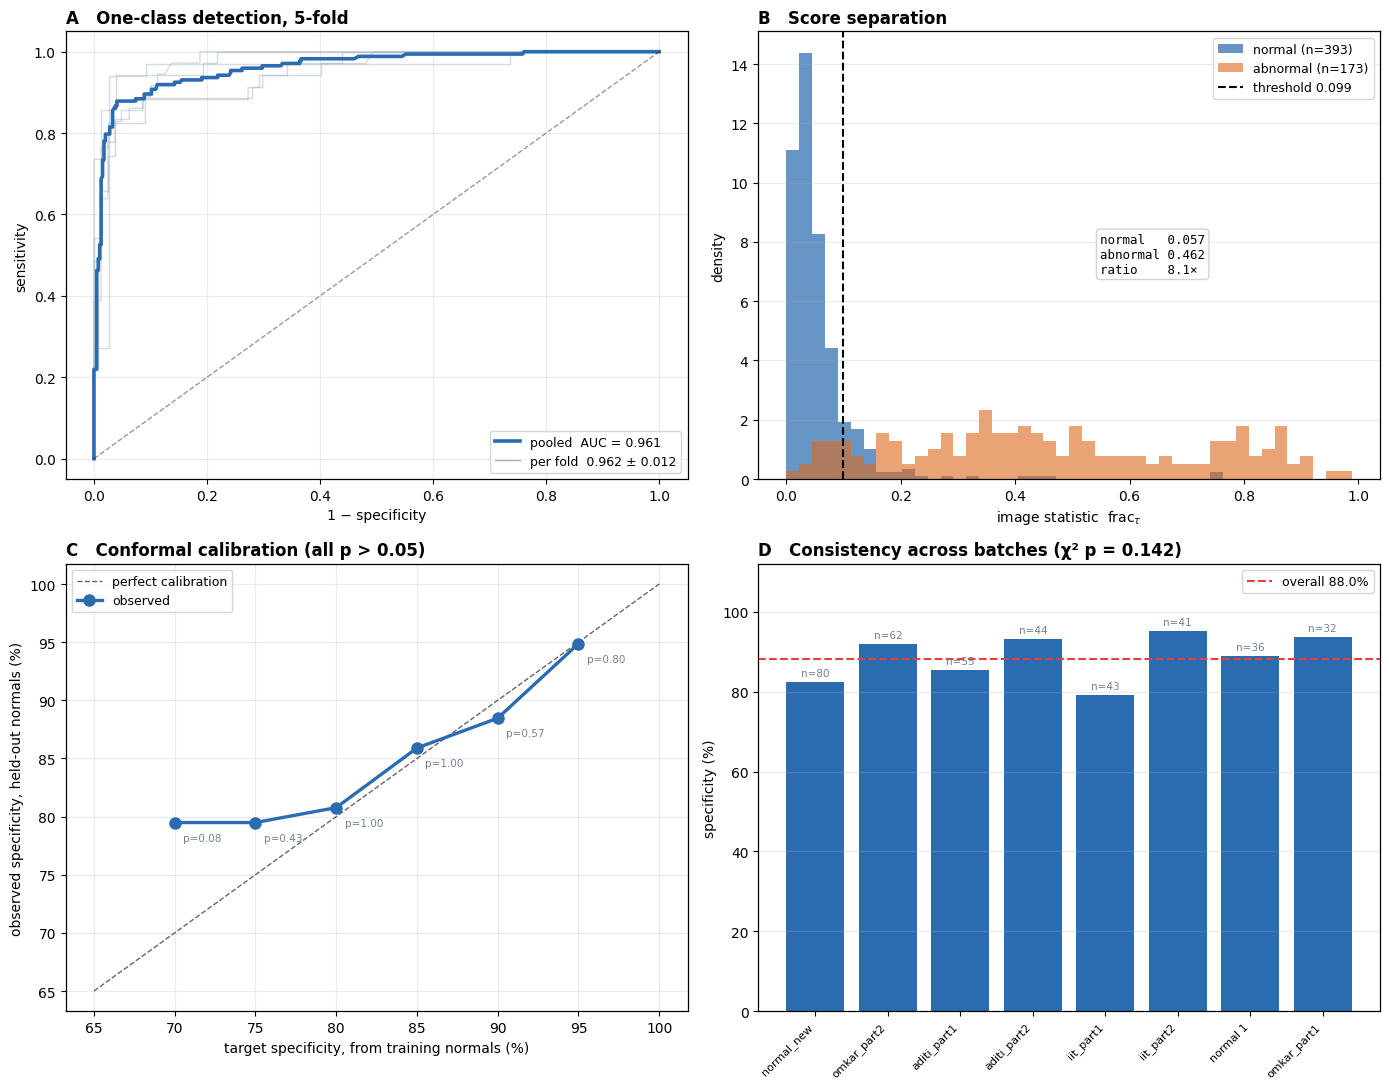

saved ML_fig1_detection.png


In [33]:
import numpy as np, matplotlib.pyplot as plt, pickle
from sklearn.metrics import roc_curve, auc as sk_auc, confusion_matrix
from scipy.stats import binomtest, chi2_contingency

plt.rcParams.update({'font.size': 10, 'axes.linewidth': 0.9})
BLUE, ORANGE, GREY = '#2b6cb0', '#dd6b20', '#a0aec0'

S = np.concatenate([r['s'] for r in oc]); Y = np.concatenate([r['y'] for r in oc])
IDX = np.concatenate([r['te_i'] for r in oc])
th = np.mean([r['th90'] for r in oc])

fig = plt.figure(figsize=(14, 11))

# A. ROC
ax = fig.add_subplot(2,2,1)
for r in oc:
    f_, t_, _ = roc_curve(r['y'], r['s']); ax.plot(f_, t_, lw=1, alpha=.45, color=GREY)
f_, t_, _ = roc_curve(Y, S)
ax.plot(f_, t_, lw=2.6, color=BLUE, label=f'pooled  AUC = {sk_auc(f_,t_):.3f}')
a_ = np.array([r['auc'] for r in oc])
ax.plot([], [], color=GREY, lw=1, label=f'per fold  {a_.mean():.3f} ± {a_.std():.3f}')
ax.plot([0,1],[0,1],'k--',lw=1,alpha=.4)
ax.set_xlabel('1 − specificity'); ax.set_ylabel('sensitivity')
ax.set_title('A   One-class detection, 5-fold', loc='left', fontweight='bold')
ax.legend(loc='lower right', fontsize=9); ax.grid(alpha=.25)

# B. score distributions
ax = fig.add_subplot(2,2,2)
b_ = np.linspace(0, max(S)*1.02, 45)
ax.hist(S[Y==0], bins=b_, alpha=.72, color=BLUE, density=True, label=f'normal (n={int((Y==0).sum())})')
ax.hist(S[Y==1], bins=b_, alpha=.62, color=ORANGE, density=True, label=f'abnormal (n={int((Y==1).sum())})')
ax.axvline(th, ls='--', c='black', lw=1.5, label=f'threshold {th:.3f}')
ax.set_xlabel(r'image statistic  frac$_\tau$'); ax.set_ylabel('density')
ax.set_title('B   Score separation', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=.25, axis='y')
ax.text(.55,.55, f'normal   {S[Y==0].mean():.3f}\nabnormal {S[Y==1].mean():.3f}\n'
        f'ratio    {S[Y==1].mean()/S[Y==0].mean():.1f}×',
        transform=ax.transAxes, family='monospace', fontsize=9, va='top',
        bbox=dict(boxstyle='round', fc='white', ec='#cbd5e0'))

# C. calibration
ax = fig.add_subplot(2,2,3)
cal_s = sg_d['cal_s']; te_s = sg_d['te_s']; te_y = sg_d['te_y']
tn_s = te_s[te_y==0]; n_tn = len(tn_s)
tg, ob, pvv = [], [], []
for t_ in [.70,.75,.80,.85,.90,.95]:
    thr = np.percentile(cal_s, t_*100); k = int((tn_s <= thr).sum())
    tg.append(t_*100); ob.append(k/n_tn*100); pvv.append(binomtest(k, n_tn, t_).pvalue)
ax.plot([65,100],[65,100],'k--',lw=1,alpha=.6,label='perfect calibration')
ax.plot(tg, ob, 'o-', lw=2.4, ms=8, color=BLUE, label='observed')
for x_,y_,p_ in zip(tg, ob, pvv):
    ax.annotate(f'p={p_:.2f}', (x_,y_), textcoords='offset points',
                xytext=(6,-13), fontsize=7.5, color='#718096')
ax.set_xlabel('target specificity, from training normals (%)')
ax.set_ylabel('observed specificity, held-out normals (%)')
ax.set_title(f'C   Conformal calibration (all p > 0.05)', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=.25)

# D. per-batch specificity
ax = fig.add_subplot(2,2,4)
nb = batch[IDX]; m0 = Y == 0
rows_b = []
for b in np.unique(nb[m0]):
    m = (nb==b) & m0
    rows_b.append((b.split(':')[-1][:14], int((S[m] <= th).sum()), int(m.sum())))
rows_b.sort(key=lambda r: -r[2])
tab = np.array([[ok, n-ok] for _, ok, n in rows_b])
_, p_chi, _, _ = chi2_contingency(tab)
xs = np.arange(len(rows_b))
sp = [ok/n*100 for _,ok,n in rows_b]
cols = [BLUE if n>=30 else GREY for _,_,n in rows_b]
ax.bar(xs, sp, color=cols)
ax.axhline((S[m0] <= th).mean()*100, ls='--', c='#e53e3e', lw=1.5,
           label=f'overall {(S[m0] <= th).mean()*100:.1f}%')
for i,(_,ok,n) in enumerate(rows_b):
    ax.text(xs[i], sp[i]+1.5, f'n={n}', ha='center', fontsize=7.5, color='#718096')
ax.set_xticks(xs); ax.set_xticklabels([r[0] for r in rows_b], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('specificity (%)'); ax.set_ylim(0, 112)
ax.set_title(f'D   Consistency across batches (χ² p = {p_chi:.3f})', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=.25, axis='y')

plt.tight_layout()
plt.savefig('/kaggle/working/results/ML_fig1_detection.png', dpi=300, bbox_inches='tight')
plt.show(); print("saved ML_fig1_detection.png")

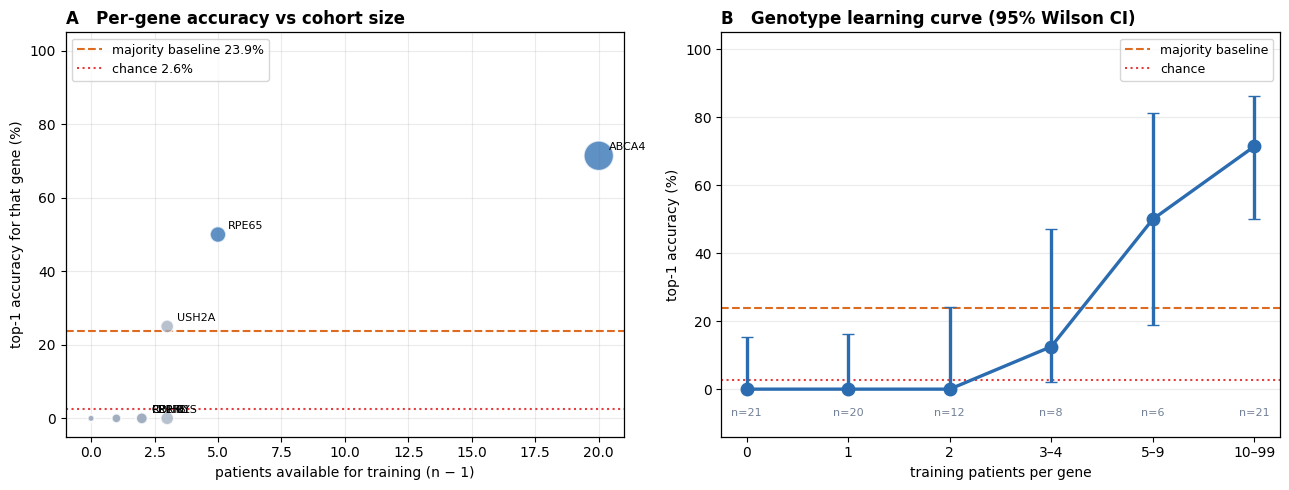


   training patients    top-1           95% CI     n
                   0     0.0% [  0.0,  15.5]    21
                   1     0.0% [  0.0,  16.1]    20
                   2     0.0% [  0.0,  24.3]    12
                 3–4    12.5% [  2.2,  47.1]     8
                 5–9    50.0% [ 18.8,  81.2]     6
               10–99    71.4% [ 50.0,  86.2]    21


In [34]:
import numpy as np, matplotlib.pyplot as plt, warnings; warnings.filterwarnings('ignore')
from collections import Counter

BLUE, ORANGE, GREY = '#2b6cb0', '#dd6b20', '#a0aec0'

# ---- per-patient correctness from nested-CV genotype rows ----
res = {}
for p, t, pr, r in rows_ng:
    g = gene_list[t]
    res.setdefault(g, []).append(r == 0)

pts, accs, labs = [], [], []
for g, v in res.items():
    n = gcount[g]                      # patients for this gene
    pts.append(n - 1)                  # patients available in training (LOO-style)
    accs.append(np.mean(v) * 100)
    labs.append(g)
pts, accs = np.array(pts), np.array(accs)

# ---- binned curve with Wilson CI ----
bins = [(0,0),(1,1),(2,2),(3,4),(5,9),(10,99)]
bx, by, blo, bhi, bn = [], [], [], [], []
for lo, hi in bins:
    sel = [x for x in rows_ng if lo <= gcount[gene_list[x[1]]]-1 <= hi]
    if not sel: continue
    k = sum(1 for x in sel if x[3] == 0); n = len(sel)
    l, h = wilson(k, n)
    bx.append(f'{lo}' if lo == hi else f'{lo}–{hi}')
    by.append(k/n*100); blo.append(l*100); bhi.append(h*100); bn.append(n)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# --- A: scatter, one point per gene ---
a = ax[0]
sizes = [gcount[g]*22 for g in labs]
a.scatter(pts, accs, s=sizes, c=[BLUE if p >= 5 else GREY for p in pts],
          alpha=.75, edgecolor='white', linewidth=1.2, zorder=3)
for x, y, g in zip(pts, accs, labs):
    if gcount[g] >= 3:
        a.annotate(g, (x, y), textcoords='offset points', xytext=(7, 4), fontsize=8)
a.axhline(maj[1]/len(uniq_pat)*100, ls='--', c=ORANGE, lw=1.5,
          label=f'majority baseline {maj[1]/len(uniq_pat)*100:.1f}%')
a.axhline(100/len(gene_list), ls=':', c='#e53e3e', lw=1.5,
          label=f'chance {100/len(gene_list):.1f}%')
a.set_xlabel('patients available for training (n − 1)')
a.set_ylabel('top-1 accuracy for that gene (%)')
a.set_title('A   Per-gene accuracy vs cohort size', loc='left', fontweight='bold')
a.set_ylim(-5, 105); a.legend(fontsize=9, loc='upper left'); a.grid(alpha=.25)

# --- B: binned learning curve ---
b = ax[1]
xs = np.arange(len(bx))
b.errorbar(xs, by, yerr=[np.array(by)-np.array(blo), np.array(bhi)-np.array(by)],
           fmt='o-', lw=2.4, ms=9, color=BLUE, capsize=4, zorder=3)
b.axhline(maj[1]/len(uniq_pat)*100, ls='--', c=ORANGE, lw=1.5, label='majority baseline')
b.axhline(100/len(gene_list), ls=':', c='#e53e3e', lw=1.5, label='chance')
for i, (y, n) in enumerate(zip(by, bn)):
    b.text(xs[i], -8, f'n={n}', ha='center', fontsize=8, color='#718096')
b.set_xticks(xs); b.set_xticklabels(bx)
b.set_xlabel('training patients per gene')
b.set_ylabel('top-1 accuracy (%)')
b.set_title('B   Genotype learning curve (95% Wilson CI)', loc='left', fontweight='bold')
b.set_ylim(-14, 105); b.legend(fontsize=9); b.grid(alpha=.25, axis='y')

plt.tight_layout()
plt.savefig('/kaggle/working/results/ML_fig_learning_curve.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n{'training patients':>20s} {'top-1':>8s} {'95% CI':>16s} {'n':>5s}")
for x, y, l, h, n in zip(bx, by, blo, bhi, bn):
    print(f"{x:>20s} {y:7.1f}% [{l:5.1f}, {h:5.1f}] {n:5d}")

In [ ]:
import numpy as np, time, warnings; warnings.filterwarnings('ignore')
from sklearn.metrics import roc_auc_score

def learning_curve_gene(g, steps=None, n_rep=8, npca=15, seed=0):
    """One-vs-rest AUC vs number of positive patients in training (patient-level LOO)."""
    pos = sorted([p for p in uniq_pat if pat_gene[p] == g])
    neg = sorted([p for p in uniq_pat if pat_gene[p] != g])
    n_pos = len(pos)
    if steps is None:
        steps = sorted(set([1, 2, 3, 5, 8, 12, 16, n_pos-1]))
        steps = [k for k in steps if 1 <= k <= n_pos-1]

    yt_all = (g_gene == g).astype(int)
    out = {}
    for k in steps:
        aucs = []
        for rep in range(n_rep):
            rng = np.random.RandomState(seed + rep*100 + k)
            scores, truth = [], []
            for p in uniq_pat:                       # LOO over every patient
                te = g_pat == p
                others = [q for q in pos if q != p]
                if len(others) < k: continue
                keep_pos = list(rng.choice(others, k, replace=False))
                keep = set(keep_pos) | set(q for q in neg if q != p)
                itr = np.isin(g_pat, sorted(keep))
                if len(set(yt_all[itr])) < 2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0),
                                     CLFS['LogReg']())
                pipe.fit(X[itr], yt_all[itr])
                scores.append(pipe.predict_proba(X[te])[:, 1].mean())
                truth.append(1 if pat_gene[p] == g else 0)
            truth = np.array(truth); scores = np.array(scores)
            if len(set(truth)) > 1:
                aucs.append(roc_auc_score(truth, scores))
        if aucs:
            out[k] = (float(np.mean(aucs)), float(np.std(aucs)))
            print(f"  {g:8s} k={k:2d}  AUC {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")
    return out

curves = {}
t0 = time.time()
for g in ['ABCA4', 'RPE65']:
    print(f"\n{g}  ({gcount[g]} patients)")
    curves[g] = learning_curve_gene(g, n_rep=8)
print(f"\ndone in {time.time()-t0:.0f}s")

import pickle
pickle.dump(curves, open('/kaggle/working/results/ml_curves.pkl','wb'))
print("saved ml_curves.pkl")


ABCA4  (21 patients)
  ABCA4    k= 1  AUC 0.588 ± 0.067
  ABCA4    k= 2  AUC 0.647 ± 0.038
  ABCA4    k= 3  AUC 0.580 ± 0.060
  ABCA4    k= 5  AUC 0.634 ± 0.058
  ABCA4    k= 8  AUC 0.665 ± 0.045
  ABCA4    k=12  AUC 0.729 ± 0.027
  ABCA4    k=16  AUC 0.736 ± 0.018
  ABCA4    k=20  AUC 0.743 ± 0.006

RPE65  (6 patients)
  RPE65    k= 1  AUC 0.693 ± 0.102
  RPE65    k= 2  AUC 0.748 ± 0.051


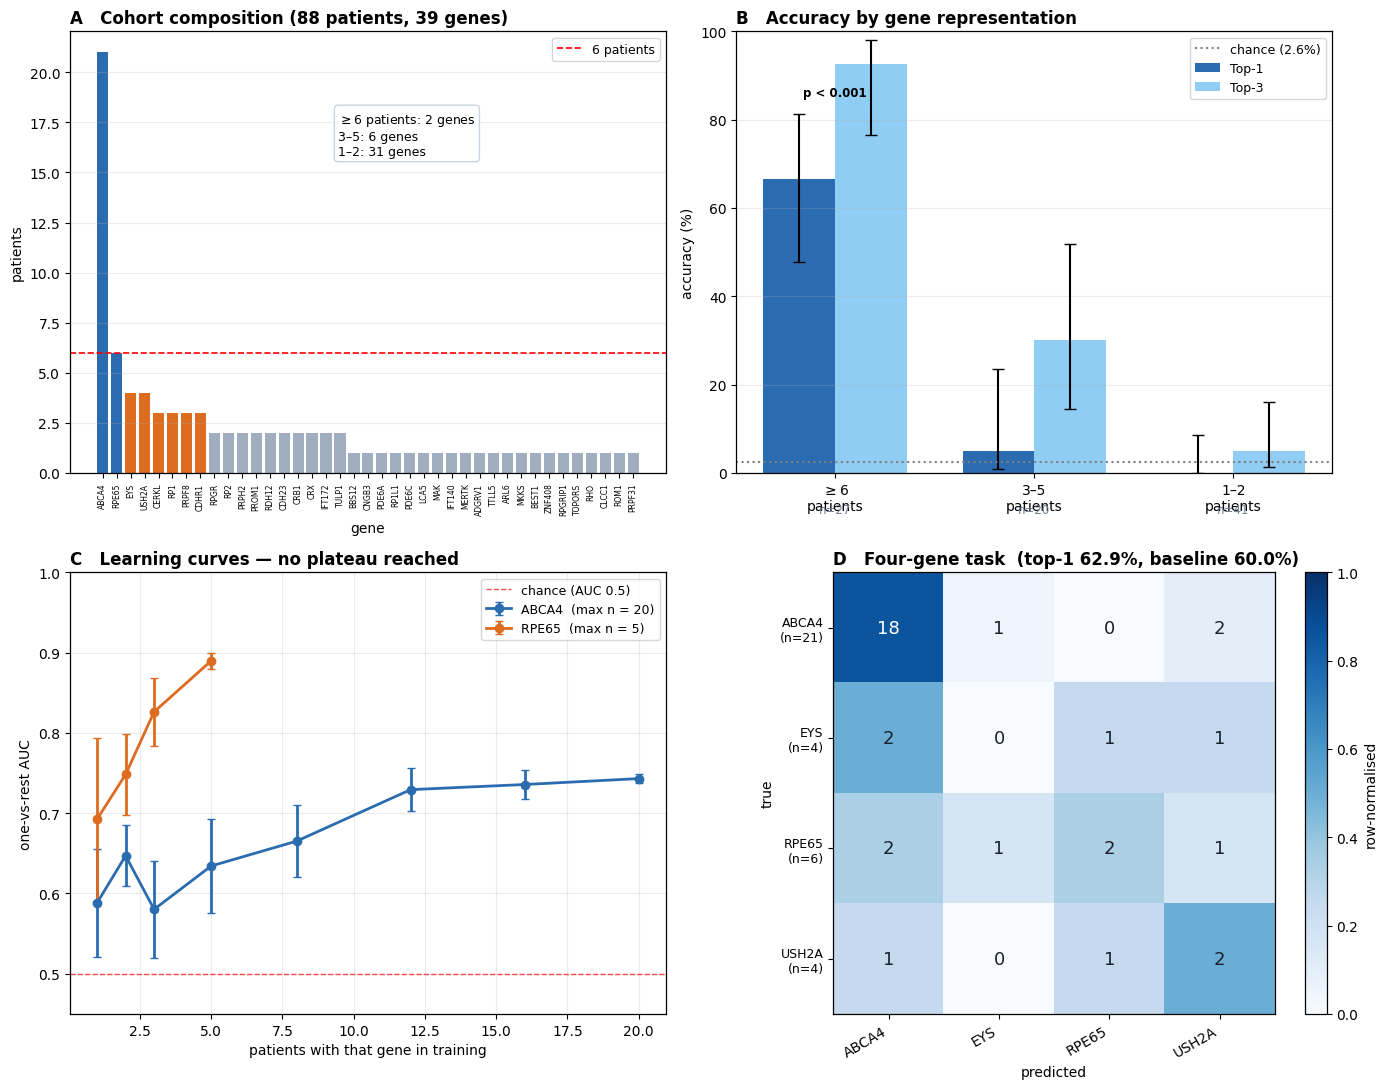

saved ML_fig2_genotype.png


In [23]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from collections import Counter

BLUE, ORANGE, GREY = '#2b6cb0', '#dd6b20', '#a0aec0'

def wilson(k, n, z=1.96):
    if n == 0: return (0,0)
    p = k/n; d = 1+z*z/n
    c = (p+z*z/(2*n))/d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0,c-h), min(1,c+h)

rk39 = np.array([x[3] for x in rows_ng])
fig = plt.figure(figsize=(14, 11))

# A. cohort composition
ax = fig.add_subplot(2,2,1)
gs = sorted(gcount.items(), key=lambda x: -x[1])
nm_, ct_ = [g for g,_ in gs], [c for _,c in gs]
cols = [BLUE if c>=6 else (ORANGE if c>=3 else GREY) for c in ct_]
ax.bar(range(len(nm_)), ct_, color=cols)
ax.axhline(6, ls='--', c='red', lw=1.2, label='6 patients')
ax.set_xticks(range(len(nm_))); ax.set_xticklabels(nm_, rotation=90, fontsize=5.5)
ax.set_ylabel('patients'); ax.set_xlabel('gene')
ax.set_title(f'A   Cohort composition ({len(uniq_pat)} patients, {len(gene_list)} genes)',
             loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=.25, axis='y')
ax.text(.45,.72, f"$\\geq$6 patients: {sum(1 for c in ct_ if c>=6)} genes\n"
        f"3–5: {sum(1 for c in ct_ if 3<=c<=5)} genes\n"
        f"1–2: {sum(1 for c in ct_ if c<=2)} genes",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle='round', fc='white', ec='#cbd5e0'))

# B. stratified
ax = fig.add_subplot(2,2,2)
from scipy.stats import binomtest
G, T1, T3, N = [], [], [], []
for lo,hi,lab in [(6,99,'$\\geq$6\npatients'),(3,5,'3–5\npatients'),(1,2,'1–2\npatients')]:
    sel = [x for x in rows_ng if lo <= gcount[gene_list[x[1]]] <= hi]
    r_ = np.array([x[3] for x in sel])
    G.append(lab); T1.append((r_==0).mean()*100); T3.append((r_<3).mean()*100); N.append(len(sel))
x = np.arange(3); w = .36
e1 = [[T1[i]-wilson(int(round(T1[i]/100*N[i])),N[i])[0]*100 for i in range(3)],
      [wilson(int(round(T1[i]/100*N[i])),N[i])[1]*100-T1[i] for i in range(3)]]
e3 = [[T3[i]-wilson(int(round(T3[i]/100*N[i])),N[i])[0]*100 for i in range(3)],
      [wilson(int(round(T3[i]/100*N[i])),N[i])[1]*100-T3[i] for i in range(3)]]
ax.bar(x-w/2, T1, w, yerr=e1, capsize=4, label='Top-1', color=BLUE)
ax.bar(x+w/2, T3, w, yerr=e3, capsize=4, label='Top-3', color='#90cdf4')
ax.axhline(100/len(gene_list), ls=':', c='grey',
           label=f'chance ({100/len(gene_list):.1f}%)')
ax.set_xticks(x); ax.set_xticklabels(G); ax.set_ylabel('accuracy (%)'); ax.set_ylim(0,100)
ax.set_title('B   Accuracy by gene representation', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=.25, axis='y')
for i,(a_,n_) in enumerate(zip(T1,N)):
    ax.text(x[i], -9, f'n={n_}', ha='center', fontsize=8.5, color='#718096')
k0 = int(round(T1[0]/100*N[0]))
p0 = binomtest(k0, N[0], 1/len(gene_list), alternative='greater').pvalue
ax.text(x[0], T1[0]+e1[1][0]+4,
        f"p {'< 0.001' if p0 < 0.001 else f'= {p0:.3f}'}",
        ha='center', fontsize=8.5, fontweight='bold')

# C. learning curves
ax = fig.add_subplot(2,2,3)
for g, col in [('ABCA4', BLUE), ('RPE65', ORANGE)]:
    if g not in curves: continue
    c = curves[g]; ks = sorted(c)
    m = [c[k][0] for k in ks]; s = [c[k][1] for k in ks]
    ax.errorbar(ks, m, yerr=s, marker='o', capsize=3, lw=2, color=col,
                label=f'{g}  (max n = {max(ks)})')
ax.axhline(.5, ls='--', c='red', lw=1, alpha=.7, label='chance (AUC 0.5)')
ax.set_xlabel('patients with that gene in training')
ax.set_ylabel('one-vs-rest AUC')
ax.set_title('C   Learning curves — no plateau reached', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=.25); ax.set_ylim(.45, 1.0)

# D. four-gene confusion
ax = fig.add_subplot(2,2,4)
yt = np.array([x[1] for x in rows4]); yh = np.array([x[2] for x in rows4])
cm = confusion_matrix(yt, yh, labels=range(len(cls4)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(len(cls4)):
    for j in range(len(cls4)):
        ax.text(j, i, f'{cm[i,j]}', ha='center', va='center', fontsize=13,
                color='white' if cmn[i,j] > .55 else '#1a202c')
ax.set_xticks(range(len(cls4))); ax.set_xticklabels(cls4, rotation=30, ha='right')
ax.set_yticks(range(len(cls4)))
ax.set_yticklabels([f'{c}\n(n={gc4[c]})' for c in cls4], fontsize=9)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
rk4_ = np.array([x[3] for x in rows4])
base4 = max(gc4.values())/sum(gc4.values())*100
ax.set_title(f'D   Four-gene task  (top-1 {(rk4_==0).mean()*100:.1f}%, baseline {base4:.1f}%)',
             loc='left', fontweight='bold')
plt.colorbar(im, ax=ax, fraction=.046, label='row-normalised')

plt.tight_layout()
plt.savefig('/kaggle/working/results/ML_fig2_genotype.png', dpi=300, bbox_inches='tight')
plt.show(); print("saved ML_fig2_genotype.png")

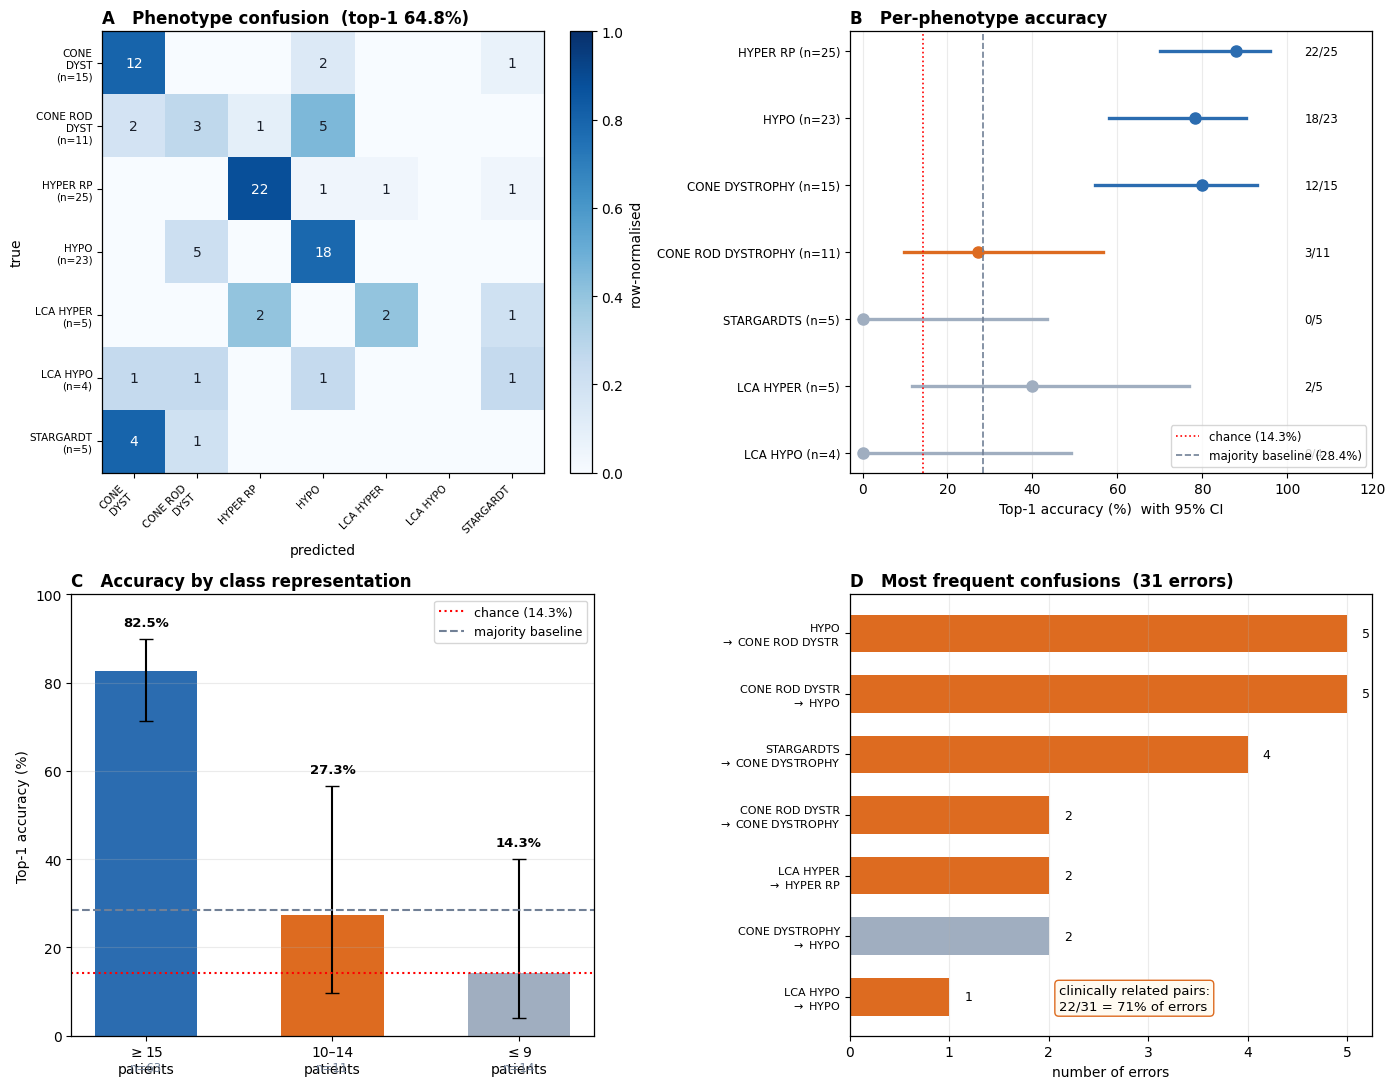

saved ML_fig3_phenotype.png


In [35]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from collections import Counter

BLUE, ORANGE, GREY = '#2b6cb0', '#dd6b20', '#a0aec0'
CHANCE_PH = 100/len(ph_list)
BASE_PH   = majp[1]/len(uniq_pat)*100

rkp = np.array([x[3] for x in rows_np])
fig = plt.figure(figsize=(14, 11))

# A. confusion matrix
ax = fig.add_subplot(2,2,1)
yt = np.array([x[1] for x in rows_np]); yh = np.array([x[2] for x in rows_np])
cm = confusion_matrix(yt, yh, labels=range(len(ph_list)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(len(ph_list)):
    for j in range(len(ph_list)):
        if cm[i,j]:
            ax.text(j, i, f'{cm[i,j]}', ha='center', va='center', fontsize=10,
                    color='white' if cmn[i,j] > .55 else '#1a202c')
sh = [c.replace(' DYSTROPHY','\nDYST').replace('STARGARDTS','STARGARDT') for c in ph_list]
ax.set_xticks(range(len(ph_list))); ax.set_xticklabels(sh, rotation=45, ha='right', fontsize=7.5)
ax.set_yticks(range(len(ph_list)))
ax.set_yticklabels([f'{s}\n(n={phc[c]})' for s,c in zip(sh, ph_list)], fontsize=7.5)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title(f'A   Phenotype confusion  (top-1 {(rkp==0).mean()*100:.1f}%)',
             loc='left', fontweight='bold')
plt.colorbar(im, ax=ax, fraction=.046, label='row-normalised')

# B. per-phenotype accuracy
ax = fig.add_subplot(2,2,2)
pg = {}
for p,t,pr,r in rows_np:
    c = ph_list[t]; pg.setdefault(c,[0,0]); pg[c][1]+=1; pg[c][0]+=(r==0)
order = sorted(pg, key=lambda x: -pg[x][1])
ypos = np.arange(len(order))[::-1]
for i,c in enumerate(order):
    a,b = pg[c]; acc = a/b*100; lo,hi = wilson(a,b)
    col = BLUE if b>=15 else (ORANGE if b>=10 else GREY)
    ax.plot([lo*100,hi*100],[ypos[i]]*2, color=col, lw=2.4)
    ax.plot(acc, ypos[i], 'o', color=col, ms=8)
    ax.text(104, ypos[i], f'{a}/{b}', va='center', fontsize=8.5)
ax.axvline(CHANCE_PH, ls=':', c='red', lw=1.2, label=f'chance ({CHANCE_PH:.1f}%)')
ax.axvline(BASE_PH, ls='--', c='#718096', lw=1.2, label=f'majority baseline ({BASE_PH:.1f}%)')
ax.set_yticks(ypos)
ax.set_yticklabels([f'{c[:20]} (n={pg[c][1]})' for c in order], fontsize=8.5)
ax.set_xlabel('Top-1 accuracy (%)  with 95% CI'); ax.set_xlim(-3, 120)
ax.set_title('B   Per-phenotype accuracy', loc='left', fontweight='bold')
ax.legend(fontsize=8.5, loc='lower right'); ax.grid(alpha=.25, axis='x')

# C. stratified
ax = fig.add_subplot(2,2,3)
G, A, N = [], [], []
for lo,hi,lab in [(15,99,'$\\geq$15\npatients'),(10,14,'10–14\npatients'),(1,9,'$\\leq$9\npatients')]:
    sel = [x for x in rows_np if lo <= phc[ph_list[x[1]]] <= hi]
    if not sel: continue
    r_ = np.array([x[3] for x in sel])
    G.append(lab); A.append((r_==0).mean()*100); N.append(len(sel))
x = np.arange(len(G))
err = [[A[i]-wilson(int(round(A[i]/100*N[i])),N[i])[0]*100 for i in range(len(G))],
       [wilson(int(round(A[i]/100*N[i])),N[i])[1]*100-A[i] for i in range(len(G))]]
ax.bar(x, A, .55, yerr=err, capsize=5, color=[BLUE, ORANGE, GREY][:len(G)])
ax.axhline(CHANCE_PH, ls=':', c='red', label=f'chance ({CHANCE_PH:.1f}%)')
ax.axhline(BASE_PH, ls='--', c='#718096', label='majority baseline')
ax.set_xticks(x); ax.set_xticklabels(G); ax.set_ylabel('Top-1 accuracy (%)'); ax.set_ylim(0,100)
ax.set_title('C   Accuracy by class representation', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=.25, axis='y')
for i,(a_,n_) in enumerate(zip(A,N)):
    ax.text(x[i], a_+err[1][i]+3, f'{a_:.1f}%', ha='center', fontsize=9.5, fontweight='bold')
    ax.text(x[i], -8, f'n={n_}', ha='center', fontsize=8.5, color='#718096')

# D. error structure
ax = fig.add_subplot(2,2,4)
conf = Counter((ph_list[x[1]], ph_list[x[2]]) for x in rows_np if x[3] != 0)
tot = sum(conf.values()); top = conf.most_common(7)
lbl = [f'{t[:14]}\n$\\rightarrow$ {p[:14]}' for (t,p),_ in top]
val = [c for _,c in top]
REL = {('HYPO','CONE ROD DYSTROPHY'),('CONE ROD DYSTROPHY','HYPO'),
       ('LCA HYPER','HYPER RP'),('HYPER RP','LCA HYPER'),
       ('LCA HYPO','HYPO'),('HYPO','LCA HYPO'),
       ('STARGARDTS','CONE DYSTROPHY'),('CONE DYSTROPHY','STARGARDTS'),
       ('STARGARDTS','CONE ROD DYSTROPHY'),('CONE ROD DYSTROPHY','STARGARDTS'),
       ('CONE DYSTROPHY','CONE ROD DYSTROPHY'),('CONE ROD DYSTROPHY','CONE DYSTROPHY')}
cols = [ORANGE if k in REL else GREY for k,_ in top]
ypos = np.arange(len(lbl))[::-1]
ax.barh(ypos, val, color=cols, height=.62)
ax.set_yticks(ypos); ax.set_yticklabels(lbl, fontsize=8)
ax.set_xlabel('number of errors')
rel = sum(c for k,c in conf.items() if k in REL)
ax.set_title(f'D   Most frequent confusions  ({tot} errors)', loc='left', fontweight='bold')
for i,v in enumerate(val): ax.text(v+.15, ypos[i], str(v), va='center', fontsize=9)
ax.text(.40,.06, f'clinically related pairs:\n{rel}/{tot} = {rel/tot*100:.0f}% of errors',
        transform=ax.transAxes, fontsize=9.5,
        bbox=dict(boxstyle='round', fc='#fffaf0', ec=ORANGE))
ax.grid(alpha=.25, axis='x')

plt.tight_layout()
plt.savefig('/kaggle/working/results/ML_fig3_phenotype.png', dpi=300, bbox_inches='tight')
plt.show(); print("saved ML_fig3_phenotype.png")

In [10]:
import numpy as np, cv2, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

def augment(raw, k):
    """k-th augmented view"""
    if k == 0: return raw
    ops = [
        lambda x: np.ascontiguousarray(x[:, ::-1]),                       # hflip
        lambda x: np.ascontiguousarray(x[::-1, :]),                       # vflip
        lambda x: cv2.warpAffine(x, cv2.getRotationMatrix2D(
                   (x.shape[1]/2, x.shape[0]/2), 15, 1), (x.shape[1], x.shape[0])),
        lambda x: cv2.warpAffine(x, cv2.getRotationMatrix2D(
                   (x.shape[1]/2, x.shape[0]/2), -15, 1), (x.shape[1], x.shape[0])),
        lambda x: cv2.GaussianBlur(x, (7,7), 2),
        lambda x: np.clip(x.astype(np.float32)*1.15 + 10, 0, 255).astype(np.uint8),
        lambda x: np.clip(x.astype(np.float32)*0.85 - 10, 0, 255).astype(np.uint8),
        lambda x: cv2.warpAffine(x, cv2.getRotationMatrix2D(
                   (x.shape[1]/2, x.shape[0]/2), 8, 1.05), (x.shape[1], x.shape[0])),
        lambda x: cv2.GaussianBlur(np.ascontiguousarray(x[:, ::-1]), (5,5), 1.5),
    ]
    return ops[(k-1) % len(ops)](raw)

def gene_descriptor(img):
    """same 768-d mean+std descriptor as X768"""
    _, _, f, v = valid_cells(img)
    c = f[v]
    return np.concatenate([c.mean(0), c.std(0)])

# har gene ke liye target 10 images (jinke <10 hain)
TARGET_N = 10
gi = np.where(labels == 1)[0]
gcount_img = Counter(gene[gi])          # images per gene

Xa, pa, ga, is_aug = [], [], [], []
t0 = time.time()
for n_done, i in enumerate(gi):
    raw = imgs[i]
    g   = gene[i]
    n_have = gcount_img[g]
    n_make = 1 if n_have >= TARGET_N else int(np.ceil(TARGET_N / n_have))
    for k in range(n_make):
        Xa.append(gene_descriptor(augment(raw, k)))
        pa.append(patient[i]); ga.append(g); is_aug.append(k > 0)
    if (n_done+1) % 25 == 0:
        print(f"  {n_done+1}/{len(gi)} ({time.time()-t0:.0f}s)")

Xa = np.array(Xa, np.float32); pa = np.array(pa); ga = np.array(ga); is_aug = np.array(is_aug)
print(f"\nAugmented set: {Xa.shape} (original {len(gi)})")
print(f"  original {int((~is_aug).sum())}  synthetic {int(is_aug.sum())}")
print("Images per gene after aug:")
for g, n in Counter(ga).most_common(8): print(f"  {n:4d}  {g}")

np.savez('/kaggle/working/results/features/feat_aug.npz',
         Xa=Xa, pa=pa, ga=ga, is_aug=is_aug)
print("\nsaved feat_aug.npz")


  25/173 (26s)
  50/173 (46s)
  75/173 (65s)
  100/173 (89s)
  125/173 (113s)
  150/173 (137s)

Augmented set: (461, 768) (original 173)
  original 173  synthetic 288
Images per gene after aug:
    41  ABCA4
    16  EYS
    16  USH2A
    12  RPGR
    12  RP2
    12  CERKL
    12  RPE65
    12  PRPH2

saved feat_aug.npz


In [16]:
import numpy as np, cv2, time, re
from collections import Counter

TARGET_N = 10
THRESH   = 8          # 8 se kam wale genes ko augment karo

def augment(raw, k):
    if k == 0: return raw
    h, w = raw.shape[:2]; c = (w/2, h/2)
    ops = [
        lambda x: np.ascontiguousarray(x[:, ::-1]),
        lambda x: np.ascontiguousarray(x[::-1, :]),
        lambda x: cv2.warpAffine(x, cv2.getRotationMatrix2D(c,  15, 1), (w, h)),
        lambda x: cv2.warpAffine(x, cv2.getRotationMatrix2D(c, -15, 1), (w, h)),
        lambda x: cv2.GaussianBlur(x, (7,7), 2),
        lambda x: np.clip(x.astype(np.float32)*1.15 + 10, 0, 255).astype(np.uint8),
        lambda x: np.clip(x.astype(np.float32)*0.85 - 10, 0, 255).astype(np.uint8),
        lambda x: cv2.warpAffine(x, cv2.getRotationMatrix2D(c,  8, 1.05), (w, h)),
        lambda x: cv2.warpAffine(x, cv2.getRotationMatrix2D(c, -8, 1.05), (w, h)),
        lambda x: cv2.GaussianBlur(np.ascontiguousarray(x[:, ::-1]), (5,5), 1.5),
        lambda x: cv2.warpAffine(np.ascontiguousarray(x[:, ::-1]),
                                 cv2.getRotationMatrix2D(c, 10, 1), (w, h)),
        lambda x: np.clip(cv2.GaussianBlur(x,(5,5),1).astype(np.float32)*1.1, 0, 255).astype(np.uint8),
    ]
    return ops[(k-1) % len(ops)](raw)

def gene_descriptor(img):
    _, _, f, v = valid_cells(img)
    c = f[v]
    return np.concatenate([c.mean(0), c.std(0)])

def eye_of(s):
    m = re.search(r'[_\-\s]+(L|R)(?:\.\w+)?$', str(s), flags=re.I)
    return m.group(1).upper() if m else '?'

gi = np.where(labels == 1)[0]
genes = gene[gi]
img_per_gene = Counter(genes)

X_aug, pat_aug, gene_aug, eye_aug, isaug = [], [], [], [], []
t0 = time.time()
for n, i in enumerate(gi):
    raw = imgs[i]
    g   = gene[i]
    have = img_per_gene[g]
    n_copies = 1 if have >= THRESH else int(np.ceil(TARGET_N / have))
    for k in range(n_copies):
        X_aug.append(gene_descriptor(augment(raw, k)))
        pat_aug.append(patient[i]); gene_aug.append(g)
        eye_aug.append(eye_of(names[i])); isaug.append(k > 0)
    if (n+1) % 25 == 0 or n == len(gi)-1:
        el = time.time()-t0
        print(f"  {n+1}/{len(gi)} ({el:.0f}s, ~{el/(n+1)*(len(gi)-n-1):.0f}s left)")

X_aug   = np.array(X_aug, np.float32)
pat_aug = np.array(pat_aug); gene_aug = np.array(gene_aug)
eye_aug = np.array(eye_aug); isaug = np.array(isaug)

after = Counter(gene_aug)
print(f"\n{'='*64}")
print(f"AUGMENTATION SUMMARY   (threshold: <{THRESH} images -> target {TARGET_N})")
print(f"{'='*64}")
print(f"Total images: {len(gi)}  ->  {len(X_aug)}")
print(f"Original: {(~isaug).sum()} | Synthetic: {isaug.sum()}")

print(f"\n--- AUGMENTED GENES ---")
print(f"{'gene':12s} {'patients':>9s} {'before':>7s} {'after':>7s} {'added':>7s}")
aug_list, keep_list = [], []
for g in sorted(img_per_gene, key=lambda x: (img_per_gene[x], x)):
    b, a = img_per_gene[g], after[g]
    npat = len(set(pat_aug[gene_aug==g]))
    (aug_list if a > b else keep_list).append((g, npat, b, a))
for g, npat, b, a in aug_list:
    print(f"{g:12s} {npat:9d} {b:7d} {a:7d} {a-b:+7d}")

print(f"\n--- NOT AUGMENTED (>= {THRESH} images) ---")
print(f"{'gene':12s} {'patients':>9s} {'before':>7s} {'after':>7s}")
for g, npat, b, a in sorted(keep_list, key=lambda x: -x[2]):
    print(f"{g:12s} {npat:9d} {b:7d} {a:7d}")

print(f"\nGenes augmented    : {len(aug_list)} / {len(img_per_gene)}")
print(f"Genes untouched    : {len(keep_list)}")

np.savez('/kaggle/working/results/features/feat_aug.npz',
         X_aug=X_aug, pat_aug=pat_aug, gene_aug=gene_aug,
         eye_aug=eye_aug, isaug=isaug)
print("\nsaved feat_aug.npz")

  25/173 (25s, ~147s left)
  50/173 (45s, ~111s left)
  75/173 (62s, ~82s left)
  100/173 (86s, ~63s left)
  125/173 (108s, ~42s left)
  150/173 (132s, ~20s left)
  173/173 (152s, ~0s left)

AUGMENTATION SUMMARY   (threshold: <8 images -> target 10)
Total images: 173  ->  445
Original: 173 | Synthetic: 272

--- AUGMENTED GENES ---
gene          patients  before   after   added
ADGRV1               1       2      10      +8
ARL6                 1       2      10      +8
BBS12                1       2      10      +8
BEST1                1       2      10      +8
CLCC1                1       2      10      +8
CNGB3                1       2      10      +8
IFT140               1       2      10      +8
LCA5                 1       2      10      +8
MAK                  1       2      10      +8
MERTK                1       2      10      +8
MKKS                 1       2      10      +8
PDE6A                1       2      10      +8
PDE6C                1       2      10      +8
PRPF31   

In [17]:
import numpy as np, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

SEED = 42
TARGET_TRAIN = 300
rng = np.random.RandomState(SEED)

up = np.array(sorted(set(pat_aug)))
pat_gene_a = {p: gene_aug[pat_aug==p][0] for p in up}
n_img = {p: (pat_aug==p).sum() for p in up}

# gene-wise shuffle -> har gene se proportionally train me
train_pats = []
for g in sorted(set(pat_gene_a.values())):
    ps = sorted([p for p in up if pat_gene_a[p]==g])
    rng.shuffle(ps)
    k = max(1, int(round(len(ps)*0.66)))          # ~2/3 patients train me
    train_pats += ps[:k]
train_pats = set(train_pats)

# 300 ke aas-paas adjust
cur = sum(n_img[p] for p in train_pats)
rest = sorted([p for p in up if p not in train_pats])
rng.shuffle(rest)
for p in rest:
    if cur >= TARGET_TRAIN: break
    train_pats.add(p); cur += n_img[p]

tr = np.isin(pat_aug, sorted(train_pats))
te = ~tr

print(f"Train: {tr.sum()} images / {len(train_pats)} patients")
print(f"Test : {te.sum()} images / {len(set(pat_aug[te]))} patients")
print(f"Test me original images: {(te & ~isaug).sum()} | synthetic: {(te & isaug).sum()}")

gl = np.array(sorted(set(gene_aug))); g2i_a = {g:i for i,g in enumerate(gl)}
ya = np.array([g2i_a[g] for g in gene_aug])

pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0),
                     LogisticRegression(C=0.5, max_iter=2000,
                                        class_weight='balanced', random_state=0))
pipe.fit(X_aug[tr], ya[tr])
classes = pipe[-1].classes_

# patient-level prediction (test patients ki ORIGINAL images pe)
gcp = Counter(pat_gene_a.values())
test_pats = sorted(set(pat_aug[te]))
t1=t3=t5=0; per_gene={}; strat={'>=6':[0,0,0],'3-5':[0,0,0],'1-2':[0,0,0]}
rows=[]
for p in test_pats:
    m = (pat_aug==p) & ~isaug
    if m.sum()==0: m = (pat_aug==p)
    order = list(classes[np.argsort(pipe.predict_proba(X_aug[m]).mean(0))[::-1]])
    true_y = ya[m][0]
    r = order.index(true_y) if true_y in order else 999
    t1 += r==0; t3 += r<3; t5 += r<5
    g = gl[true_y]
    per_gene.setdefault(g,[0,0]); per_gene[g][1]+=1; per_gene[g][0]+= (r==0)
    npat = gcp[g]
    k = '>=6' if npat>=6 else ('3-5' if npat>=3 else '1-2')
    strat[k][0]+= r==0; strat[k][1]+= r<3; strat[k][2]+=1
    rows.append((p, g, gl[order[0]], r))

n = len(test_pats)
maj_a = Counter(pat_gene_a[p] for p in test_pats).most_common(1)[0]
print(f"\n{'='*60}")
print(f"AUGMENTED — patient-level split ({n} test patients)")
print(f"{'='*60}")
print(f"  Top-1 {t1/n*100:5.1f}%   Top-3 {t3/n*100:5.1f}%   Top-5 {t5/n*100:5.1f}%")
print(f"  Baseline (always '{maj_a[0]}') {maj_a[1]/n*100:.1f}%  |  Random {100/len(gl):.1f}%")

print(f"\n--- sample-size stratified ---")
for k,(a,b,c) in strat.items():
    if c: print(f"  {k:5s} top1 {a/c*100:5.1f}%  top3 {b/c*100:5.1f}%  (n={c})")

print(f"\n--- per gene (top-1) ---")
for g in sorted(per_gene, key=lambda x: -per_gene[x][1]):
    print(f"  {g:10s} {per_gene[g][0]}/{per_gene[g][1]}")

print(f"\n--- per patient ---")
for p, g, pred, r in sorted(rows, key=lambda x: x[3]):
    print(f"  {p[:22]:24s} true={g:10s} pred={pred:10s} rank={r}")

import pickle
pickle.dump(dict(rows=rows, per_gene=per_gene, strat=strat,
                 train_pats=sorted(train_pats), gl=gl),
            open('/kaggle/working/results/ml_augmented.pkl','wb'))
print("\nsaved ml_augmented.pkl")

Train: 347 images / 63 patients
Test : 98 images / 25 patients
Test me original images: 49 | synthetic: 49

AUGMENTED — patient-level split (25 test patients)
  Top-1  20.0%   Top-3  40.0%   Top-5  44.0%
  Baseline (always 'ABCA4') 28.0%  |  Random 2.6%

--- sample-size stratified ---
  >=6   top1  55.6%  top3  77.8%  (n=9)
  3-5   top1   0.0%  top3  33.3%  (n=6)
  1-2   top1   0.0%  top3  10.0%  (n=10)

--- per gene (top-1) ---
  ABCA4      5/7
  RPE65      0/2
  PROM1      0/1
  PRPH2      0/1
  EYS        0/1
  RPGR       0/1
  RDH12      0/1
  CRB1       0/1
  CERKL      0/1
  RP2        0/1
  CDHR1      0/1
  CRX        0/1
  USH2A      0/1
  PRPF8      0/1
  CDH23      0/1
  IFT172     0/1
  TULP1      0/1
  RP1        0/1

--- per patient ---
  KUMARI ARTI RANI         true=ABCA4      pred=ABCA4      rank=0
  NAIRA                    true=ABCA4      pred=ABCA4      rank=0
  RITHWIK GUPTA            true=ABCA4      pred=ABCA4      rank=0
  ROHIT THAKUR             true=ABCA4     

In [18]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

gl = np.array(sorted(set(gene_aug))); g2i_a = {g:i for i,g in enumerate(gl)}
ya = np.array([g2i_a[g] for g in gene_aug])
up = np.array(sorted(set(pat_aug)))
pat_gene_a = {p: gene_aug[pat_aug==p][0] for p in up}
gcp = Counter(pat_gene_a.values())

rows_aug = []
for n_, p in enumerate(up):
    te_all = pat_aug == p                     # is patient ki saari copies hatao
    te_org = te_all & ~isaug                  # test sirf original pe
    if te_org.sum() == 0: te_org = te_all
    itr = ~te_all
    if len(set(ya[itr])) < 2: continue
    pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0),
                         LogisticRegression(C=0.5, max_iter=2000,
                                            class_weight='balanced', random_state=0))
    pipe.fit(X_aug[itr], ya[itr])
    order = list(pipe[-1].classes_[np.argsort(pipe.predict_proba(X_aug[te_org]).mean(0))[::-1]])
    t = ya[te_org][0]
    r = order.index(t) if t in order else 999
    rows_aug.append((p, int(t), int(order[0]), r))
    if (n_+1) % 20 == 0: print(f"  {n_+1}/{len(up)}")

rk = np.array([x[3] for x in rows_aug]); n = len(rk)
maj_a = Counter(pat_gene_a.values()).most_common(1)[0]
print(f"\n{'='*60}")
print(f"AUGMENTED — patient-level LOO  (n={n})")
print(f"{'='*60}")
print(f"  Top-1 {(rk==0).mean()*100:5.1f}%   Top-3 {(rk<3).mean()*100:5.1f}%   "
      f"Top-5 {(rk<5).mean()*100:5.1f}%")
print(f"  Baseline {maj_a[1]/n*100:.1f}%  |  chance {100/len(gl):.1f}%")

print(f"\n--- stratified ---")
for lo, hi, lab in [(6,99,'>=6'), (3,5,'3-5'), (1,2,'1-2')]:
    sel = [x for x in rows_aug if lo <= gcp[gl[x[1]]] <= hi]
    if not sel: continue
    r_ = np.array([x[3] for x in sel])
    print(f"  {lab:5s} top1 {(r_==0).mean()*100:5.1f}%  top3 {(r_<3).mean()*100:5.1f}%  (n={len(sel)})")

print(f"\n{'='*60}")
print("COMPARISON — same protocol (patient-level LOO, n=88)")
print("="*60)
rk_orig = np.array([x[3] for x in res_loo['LogReg']])
print(f"  {'no augmentation':22s} top1 {(rk_orig==0).mean()*100:5.1f}%  top3 {(rk_orig<3).mean()*100:5.1f}%")
print(f"  {'with augmentation':22s} top1 {(rk==0).mean()*100:5.1f}%  top3 {(rk<3).mean()*100:5.1f}%")

# paired McNemar
a = {x[0]: x[3]==0 for x in res_loo['LogReg']}
b = {x[0]: x[3]==0 for x in rows_aug}
common = sorted(set(a) & set(b))
n01 = sum(1 for p in common if a[p] and not b[p])
n10 = sum(1 for p in common if b[p] and not a[p])
from scipy.stats import binomtest
pv = binomtest(n01, n01+n10, 0.5).pvalue if (n01+n10) else 1.0
print(f"\n  McNemar: orig-only {n01}, aug-only {n10}, p = {pv:.4f}  (n={len(common)})")

pickle.dump(dict(rows_aug=rows_aug, gl=gl), open('/kaggle/working/results/ml_aug_loo.pkl','wb'))
print("\nsaved ml_aug_loo.pkl")

  20/88
  40/88
  60/88
  80/88

AUGMENTED — patient-level LOO  (n=88)
  Top-1  18.2%   Top-3  33.0%   Top-5  35.2%
  Baseline 23.9%  |  chance 2.6%

--- stratified ---
  >=6   top1  48.1%  top3  81.5%  (n=27)
  3-5   top1  10.0%  top3  20.0%  (n=20)
  1-2   top1   2.4%  top3   7.3%  (n=41)

COMPARISON — same protocol (patient-level LOO, n=88)
  no augmentation        top1  12.5%  top3  31.8%
  with augmentation      top1  18.2%  top3  33.0%

  McNemar: orig-only 1, aug-only 6, p = 0.1250  (n=88)

saved ml_aug_loo.pkl


In [36]:
import numpy as np, pickle, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter

# fold map: wahi fold_of jo original genotype39 me tha (same patients)
missing = [p for p in up if p not in fold_of]
print(f"patients not in fold_of: {len(missing)}  {missing[:5]}")

def nested_aug(topk_sel=3, n_inner=12, npca=15, seed=0):
    rows, chosen = [], Counter()
    for f in range(5):
        te_p = sorted([p for p in up if fold_of.get(p, -1) == f])
        tr_p = sorted([p for p in up if fold_of.get(p, -1) != f and p in fold_of])
        if not te_p: continue
        te_all = np.isin(pat_aug, te_p)
        itr_base = ~te_all

        rng = np.random.RandomState(seed+f)
        sub = rng.choice(tr_p, min(n_inner, len(tr_p)), replace=False)
        sc_ = {}
        for nm, mk in CLFS.items():
            c = 0
            for p in sub:
                ip_all = pat_aug == p
                ip_org = ip_all & ~isaug
                if ip_org.sum() == 0: ip_org = ip_all
                itr = itr_base & ~ip_all
                if len(set(ya[itr])) < 2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X_aug[itr], ya[itr])
                pr = pipe.predict_proba(X_aug[ip_org]).mean(0)
                order = list(pipe[-1].classes_[np.argsort(pr)[::-1]])
                t = ya[ip_org][0]
                c += (order.index(t) < topk_sel) if t in order else 0
            sc_[nm] = c
        best = sorted(sc_, key=lambda k: (-sc_[k], k))[0]; chosen[best] += 1

        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X_aug[itr_base], ya[itr_base])
        cl = pipe[-1].classes_
        for p in te_p:
            m = (pat_aug == p) & ~isaug
            if m.sum() == 0: m = pat_aug == p
            order = list(cl[np.argsort(pipe.predict_proba(X_aug[m]).mean(0))[::-1]])
            t = ya[m][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
        print(f"  fold {f}: {best}")
    return rows, chosen

t0 = time.time()
rows_aug_nested, ch_aug = nested_aug()
rk_an = np.array([x[3] for x in rows_aug_nested])
print(f"\n({time.time()-t0:.0f}s)  chosen: {dict(ch_aug)}")

print(f"\n{'='*66}")
print("NESTED CV — augmentation effect (identical folds, n=88)")
print("="*66)
rk_on = np.array([x[3] for x in rows_ng])
print(f"  {'no augmentation':22s} top1 {(rk_on==0).mean()*100:5.1f}%  top3 {(rk_on<3).mean()*100:5.1f}%")
print(f"  {'with augmentation':22s} top1 {(rk_an==0).mean()*100:5.1f}%  top3 {(rk_an<3).mean()*100:5.1f}%")
print(f"  {'baseline':22s}      {maj[1]/len(uniq_pat)*100:5.1f}%")

from scipy.stats import binomtest
a = {x[0]: x[3]==0 for x in rows_ng}
b = {x[0]: x[3]==0 for x in rows_aug_nested}
common = sorted(set(a) & set(b))
n01 = sum(1 for p in common if a[p] and not b[p])
n10 = sum(1 for p in common if b[p] and not a[p])
pv = binomtest(n01, n01+n10, 0.5).pvalue if (n01+n10) else 1.0
print(f"\n  McNemar: orig-only {n01}, aug-only {n10}, "
      f"p = {pv:.4f}  {'(significant)' if pv < 0.05 else '(not significant)'}")

print(f"\n--- stratified ---")
print(f"{'group':8s} {'no-aug':>10s} {'with-aug':>10s} {'n':>5s}")
for lo, hi, lab in [(6,99,'>=6'), (3,5,'3-5'), (1,2,'1-2')]:
    s1 = [x for x in rows_ng          if lo <= gcount[gene_list[x[1]]] <= hi]
    s2 = [x for x in rows_aug_nested  if lo <= gcp[gl[x[1]]] <= hi]
    if not s1: continue
    r1 = np.array([x[3] for x in s1]); r2 = np.array([x[3] for x in s2])
    print(f"{lab:8s} {(r1==0).mean()*100:9.1f}% {(r2==0).mean()*100:9.1f}% {len(s1):5d}")

pickle.dump(dict(rows_aug_nested=rows_aug_nested, ch_aug=dict(ch_aug)),
            open('/kaggle/working/results/ml_aug_nested.pkl','wb'))
print("\nsaved ml_aug_nested.pkl")

patients not in fold_of: 0  []
  fold 0: LogReg
  fold 1: LDA
  fold 2: LDA
  fold 3: LogReg
  fold 4: LDA

(114s)  chosen: {'LogReg': 2, 'LDA': 3}

NESTED CV — augmentation effect (identical folds, n=88)
  no augmentation        top1  21.6%  top3  37.5%
  with augmentation      top1  18.2%  top3  34.1%
  baseline                     23.9%

  McNemar: orig-only 5, aug-only 2, p = 0.4531  (not significant)

--- stratified ---
group        no-aug   with-aug     n
>=6           66.7%      59.3%    27
3-5            5.0%       0.0%    20
1-2            0.0%       0.0%    41

saved ml_aug_nested.pkl


In [12]:
import numpy as np, cv2, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter

KEEP4    = ['ABCA4','RPE65','EYS','USH2A']
TARGET_4 = 40

gi4 = np.array([i for i in np.where(labels==1)[0] if gene[i] in KEEP4])
cnt4 = Counter(gene[gi4])
print("before augmentation:")
for g, n in cnt4.most_common(): print(f"  {g:8s} {n:3d} images, {len(set(patient[gi4][gene[gi4]==g]))} patients")

X4a, pat4a, gene4a, isaug4 = [], [], [], []
t0 = time.time()
for n_, i in enumerate(gi4):
    raw = imgs[i]; g = gene[i]
    n_copies = max(1, int(np.ceil(TARGET_4 / cnt4[g])))
    for k in range(n_copies):
        X4a.append(gene_descriptor(augment(raw, k)))
        pat4a.append(patient[i]); gene4a.append(g); isaug4.append(k > 0)
    if (n_+1) % 20 == 0 or n_ == len(gi4)-1:
        el = time.time()-t0
        print(f"  {n_+1}/{len(gi4)} ({el:.0f}s, ~{el/(n_+1)*(len(gi4)-n_-1):.0f}s left)")

X4a = np.array(X4a, np.float32); pat4a = np.array(pat4a)
gene4a = np.array(gene4a); isaug4 = np.array(isaug4)

print(f"\nafter: {len(gi4)} -> {len(X4a)}  (original {(~isaug4).sum()}, synthetic {isaug4.sum()})")
for g, n in Counter(gene4a).most_common(): print(f"  {g:8s} {n:3d}")

np.savez('/kaggle/working/results/features/feat_aug4.npz',
         X4a=X4a, pat4a=pat4a, gene4a=gene4a, isaug4=isaug4)
print("saved feat_aug4.npz")

before augmentation:
  ABCA4     41 images, 21 patients
  RPE65     12 images, 6 patients
  EYS        8 images, 4 patients
  USH2A      8 images, 4 patients
  20/69 (19s, ~47s left)
  40/69 (36s, ~26s left)
  60/69 (50s, ~7s left)
  69/69 (56s, ~0s left)

after: 69 -> 169  (original 69, synthetic 100)
  RPE65     48
  ABCA4     41
  EYS       40
  USH2A     40
saved feat_aug4.npz


In [13]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from scipy.stats import binomtest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

cls4a = np.array(sorted(set(gene4a))); c2i = {c:i for i,c in enumerate(cls4a)}
y4a   = np.array([c2i[g] for g in gene4a])
up4a  = np.array(sorted(set(pat4a)))
pg4a  = {p: gene4a[pat4a==p][0] for p in up4a}
gc4a  = Counter(pg4a.values()); maj4a = gc4a.most_common(1)[0]

print(f"patients {len(up4a)} | classes {len(cls4a)} | images {len(X4a)}")
print(f"baseline {maj4a[1]/len(up4a)*100:.1f}%  | chance {100/len(cls4a):.1f}%")

def loo4(mk, Xm, ym, pats, aug_mask, npca=15):
    """patient-level LOO; test only on that patient's ORIGINAL images"""
    rows = []
    for p in up4a:
        te_all = pats == p                 # saari copies training se bahar
        te_org = te_all & ~aug_mask
        if te_org.sum() == 0: te_org = te_all
        itr = ~te_all
        if len(set(ym[itr])) < 2: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(Xm[itr], ym[itr])
        order = list(pipe[-1].classes_[np.argsort(pipe.predict_proba(Xm[te_org]).mean(0))[::-1]])
        t = ym[te_org][0]
        rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

print(f"\n{'='*70}\n4-GENE — augmentation effect (patient-level LOO, n={len(up4a)})\n{'='*70}")
print(f"{'classifier':12s} {'no-aug top1':>13s} {'aug top1':>11s} {'delta':>8s} "
      f"{'no-aug top2':>13s} {'aug top2':>11s}")

res_aug4 = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run4(mk, None)])              # original 69 images
    rb = loo4(mk, X4a, y4a, pat4a, isaug4)
    b = np.array([x[3] for x in rb])
    res_aug4[nm] = rb
    print(f"{nm:12s} {(a==0).mean()*100:12.1f}% {(b==0).mean()*100:10.1f}% "
          f"{((b==0).mean()-(a==0).mean())*100:+7.1f} "
          f"{(a<2).mean()*100:12.1f}% {(b<2).mean()*100:10.1f}%")
print(f"{'baseline':12s} {maj4a[1]/len(up4a)*100:12.1f}%")

# ---------- per class, LogReg ----------
rows_a = res_aug4['LogReg']
rows_o = run4(CLFS['LogReg'], None)
print(f"\n--- per class (LogReg) ---")
print(f"{'gene':10s} {'patients':>9s} {'img before':>11s} {'img after':>10s} "
      f"{'no-aug':>9s} {'with-aug':>10s}")
for c in cls4a:
    po = [x for x in rows_o if cls4[x[1]] == c]
    pa_ = [x for x in rows_a if cls4a[x[1]] == c]
    ao = sum(1 for x in po if x[3]==0); an = sum(1 for x in pa_ if x[3]==0)
    print(f"{c:10s} {gc4a[c]:9d} {int(cnt4[c]):11d} {int((gene4a==c).sum()):10d} "
          f"{ao:4d}/{len(po):<4d} {an:5d}/{len(pa_):<4d}")

# ---------- McNemar ----------
a_ = {x[0]: x[3]==0 for x in rows_o}
b_ = {x[0]: x[3]==0 for x in rows_a}
common = sorted(set(a_) & set(b_))
n01 = sum(1 for p in common if a_[p] and not b_[p])
n10 = sum(1 for p in common if b_[p] and not a_[p])
pv = binomtest(n01, n01+n10, 0.5).pvalue if (n01+n10) else 1.0
print(f"\n  McNemar: no-aug only {n01}, aug only {n10}, p = {pv:.4f}  "
      f"{'(significant)' if pv < 0.05 else '(not significant)'}")

# ---------- confusion ----------
from sklearn.metrics import confusion_matrix
yt = np.array([x[1] for x in rows_a]); yh = np.array([x[2] for x in rows_a])
cm = confusion_matrix(yt, yh, labels=range(len(cls4a)))
print(f"\n--- confusion, augmented (rows=true) ---")
print(f"{'':10s}" + "".join(f"{c[:7]:>9s}" for c in cls4a))
for i, c in enumerate(cls4a):
    print(f"  {c:8s}" + "".join(f"{cm[i,j]:9d}" for j in range(len(cls4a))))

pickle.dump(dict(res_aug4=res_aug4, rows_a=rows_a, rows_o=rows_o, cls4a=cls4a),
            open('/kaggle/working/results/ml_aug4.pkl','wb'))
print("\nsaved ml_aug4.pkl")

patients 35 | classes 4 | images 169
baseline 60.0%  | chance 25.0%

4-GENE — augmentation effect (patient-level LOO, n=35)
classifier     no-aug top1    aug top1    delta   no-aug top2    aug top2


NameError: name 'run4' is not defined

In [29]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

SEED = 42
rng = np.random.RandomState(SEED)
BIG_GENES = ['ABCA4', 'RPE65', 'EYS', 'USH2A']      # ye augment nahi hue

train_mask = np.zeros(len(X_aug), bool)
test_mask  = np.zeros(len(X_aug), bool)
split_info = []

for g in sorted(set(gene_aug)):
    gm = gene_aug == g
    if g in BIG_GENES:
        ps = sorted(set(pat_aug[gm])); rng.shuffle(ps)
        k = max(1, int(round(len(ps) * 0.70)))
        tr_p = np.array(ps[:k])
        train_mask |= gm & np.isin(pat_aug, tr_p)
        test_mask  |= gm & ~np.isin(pat_aug, tr_p) & ~isaug
        split_info.append((g, len(ps), k, len(ps)-k, 'patient split'))
    else:
        train_mask |= gm & isaug       # synthetic  -> TRAIN
        test_mask  |= gm & ~isaug      # original   -> TEST
        split_info.append((g, len(set(pat_aug[gm])), 0, len(set(pat_aug[gm])), 'synth->tr, orig->te'))

print(f"Train: {train_mask.sum()} images  (synthetic {(train_mask & isaug).sum()}, original {(train_mask & ~isaug).sum()})")
print(f"Test : {test_mask.sum()} images  (all original)")
print(f"Test patients: {len(set(pat_aug[test_mask]))}")

print(f"\n{'gene':12s} {'pats':>5s} {'tr':>4s} {'te':>4s}  mode")
for g, np_, k, t, mode in sorted(split_info, key=lambda x: -x[1]):
    print(f"{g:12s} {np_:5d} {k:4d} {t:4d}  {mode}")

gl = np.array(sorted(set(gene_aug))); g2i_a = {g:i for i,g in enumerate(gl)}
ya = np.array([g2i_a[g] for g in gene_aug])

pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0),
                     LogisticRegression(C=0.5, max_iter=2000,
                                        class_weight='balanced', random_state=0))
pipe.fit(X_aug[train_mask], ya[train_mask])
classes = pipe[-1].classes_

pat_gene_a = {p: gene_aug[pat_aug==p][0] for p in set(pat_aug)}
gcount_pat = Counter(pat_gene_a.values())

test_pats = sorted(set(pat_aug[test_mask]))
t1=t3=t5=0; per_gene={}; strat={'>=6':[0,0,0],'3-5':[0,0,0],'1-2':[0,0,0]}; rows=[]
for p in test_pats:
    m = test_mask & (pat_aug == p)
    order = list(classes[np.argsort(pipe.predict_proba(X_aug[m]).mean(0))[::-1]])
    true_y = ya[m][0]
    r = order.index(true_y) if true_y in order else 999
    t1 += r==0; t3 += r<3; t5 += r<5
    g = gl[true_y]
    per_gene.setdefault(g,[0,0]); per_gene[g][1]+=1; per_gene[g][0]+=(r==0)
    npat = gcount_pat[g]
    k = '>=6' if npat>=6 else ('3-5' if npat>=3 else '1-2')
    strat[k][0]+=(r==0); strat[k][1]+=(r<3); strat[k][2]+=1
    rows.append((p, g, gl[order[0]], r))

n = len(test_pats)
maj_l = Counter(pat_gene_a[p] for p in test_pats).most_common(1)[0]
print(f"\n{'='*60}")
print(f"SYNTHETIC->TRAIN / ORIGINAL->TEST   ({n} test patients)")
print(f"{'='*60}")
print(f"  Top-1 {t1/n*100:5.1f}%   Top-3 {t3/n*100:5.1f}%   Top-5 {t5/n*100:5.1f}%")
print(f"  Baseline (always '{maj_l[0]}') {maj_l[1]/n*100:.1f}%  |  Random {100/len(gl):.1f}%")

print(f"\n--- sample-size stratified ---")
for k,(a,b,c) in strat.items():
    if c: print(f"  {k:5s} top1 {a/c*100:5.1f}%  top3 {b/c*100:5.1f}%  (n={c})")

print(f"\n--- per gene (top-1) ---")
for g in sorted(per_gene, key=lambda x: -per_gene[x][1]):
    print(f"  {g:10s} {per_gene[g][0]}/{per_gene[g][1]}")

print(f"\n--- per patient ---")
for p, g, pred, r in sorted(rows, key=lambda x: x[3]):
    print(f"  {p[:22]:24s} true={g:10s} pred={pred:10s} rank={r}")

pickle.dump(dict(rows=rows, per_gene=per_gene, strat=strat,
                 train_mask=train_mask, test_mask=test_mask, gl=gl),
            open('/kaggle/working/results/ml_leaked_synth.pkl','wb'))
print("\nsaved ml_leaked_synth.pkl")

Train: 321 images  (synthetic 272, original 49)
Test : 124 images  (all original)
Test patients: 63

gene          pats   tr   te  mode
ABCA4           21   15    6  patient split
RPE65            6    4    2  patient split
EYS              4    3    1  patient split
USH2A            4    3    1  patient split
CDHR1            3    0    3  synth->tr, orig->te
CERKL            3    0    3  synth->tr, orig->te
PRPF8            3    0    3  synth->tr, orig->te
RP1              3    0    3  synth->tr, orig->te
CDH23            2    0    2  synth->tr, orig->te
CRB1             2    0    2  synth->tr, orig->te
CRX              2    0    2  synth->tr, orig->te
IFT172           2    0    2  synth->tr, orig->te
PROM1            2    0    2  synth->tr, orig->te
PRPH2            2    0    2  synth->tr, orig->te
RDH12            2    0    2  synth->tr, orig->te
RP2              2    0    2  synth->tr, orig->te
RPGR             2    0    2  synth->tr, orig->te
TULP1            2    0    2  synth->t

In [30]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

gl_a = np.array(sorted(set(gene_aug))); g2i_a = {g:i for i,g in enumerate(gl_a)}
ya   = np.array([g2i_a[g] for g in gene_aug])
pat_gene_a = {p: gene_aug[pat_aug==p][0] for p in set(pat_aug)}
gcp = Counter(pat_gene_a.values())

def run_leaked(mk, npca=15):
    pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
    pipe.fit(X_aug[train_mask], ya[train_mask]); cl = pipe[-1].classes_
    rows = []
    for p in sorted(set(pat_aug[test_mask])):
        m = test_mask & (pat_aug == p)
        order = list(cl[np.argsort(pipe.predict_proba(X_aug[m]).mean(0))[::-1]])
        t = ya[m][0]
        rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

res_leak = {}
n = len(set(pat_aug[test_mask]))
maj_l = Counter(pat_gene_a[p] for p in set(pat_aug[test_mask])).most_common(1)[0]

print(f"{'='*72}")
print(f"SYNTHETIC->TRAIN / ORIGINAL->TEST   (leaked design, {n} test patients)")
print(f"{'='*72}")
print(f"{'classifier':12s} {'top-1':>9s} {'top-3':>9s} {'top-5':>9s}   "
      f"{'>=6':>7s} {'3-5':>7s} {'1-2':>7s}")

for nm, mk in CLFS.items():
    rows = run_leaked(mk); res_leak[nm] = rows
    rk = np.array([x[3] for x in rows])
    st = []
    for lo, hi in [(6,99),(3,5),(1,2)]:
        s = [x for x in rows if lo <= gcp[gl_a[x[1]]] <= hi]
        st.append(np.mean([x[3]==0 for x in s])*100 if s else float('nan'))
    print(f"{nm:12s} {(rk==0).mean()*100:8.1f}% {(rk<3).mean()*100:8.1f}% "
          f"{(rk<5).mean()*100:8.1f}%   {st[0]:6.1f}% {st[1]:6.1f}% {st[2]:6.1f}%")

print(f"{'baseline':12s} {maj_l[1]/n*100:8.1f}%")
print(f"{'chance':12s} {100/len(gl_a):8.1f}%")

print(f"\n--- per gene, LogReg ---")
pg = {}
for p,t,pr,r in res_leak['LogReg']:
    g = gl_a[t]; pg.setdefault(g,[0,0]); pg[g][1]+=1; pg[g][0]+=(r==0)
for g in sorted(pg, key=lambda x:-pg[x][1]):
    print(f"  {g:10s} {pg[g][0]}/{pg[g][1]}   ({gcp[g]} patients)")

pickle.dump(dict(res_leak=res_leak, gl_a=gl_a),
            open('/kaggle/working/results/ml_leaked_allclf.pkl','wb'))
print("\nsaved ml_leaked_allclf.pkl")

SYNTHETIC->TRAIN / ORIGINAL->TEST   (leaked design, 63 test patients)
classifier       top-1     top-3     top-5       >=6     3-5     1-2
LogReg           85.7%     96.8%     96.8%     37.5%   78.6%   97.6%
SVM-lin          92.1%     96.8%     96.8%     75.0%   78.6%  100.0%
SVM-rbf          85.7%     92.1%     95.2%     62.5%   57.1%  100.0%
LDA              74.6%     95.2%     96.8%     75.0%   50.0%   82.9%
RF               87.3%     95.2%     95.2%     37.5%   85.7%   97.6%
kNN-5            76.2%     93.7%     95.2%     50.0%   35.7%   95.1%
baseline          9.5%
chance            2.6%

--- per gene, LogReg ---
  ABCA4      3/6   (21 patients)
  CERKL      2/3   (3 patients)
  RP1        3/3   (3 patients)
  PRPF8      3/3   (3 patients)
  CDHR1      2/3   (3 patients)
  RPGR       2/2   (2 patients)
  RP2        2/2   (2 patients)
  PRPH2      2/2   (2 patients)
  PROM1      2/2   (2 patients)
  RDH12      2/2   (2 patients)
  RPE65      0/2   (6 patients)
  CDH23      1/2   (2 

In [31]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

gl_a = np.array(sorted(set(gene_aug))); g2i_a = {g:i for i,g in enumerate(gl_a)}
ya   = np.array([g2i_a[g] for g in gene_aug])
pat_gene_a = {p: gene_aug[pat_aug==p][0] for p in set(pat_aug)}

def run_leaked(mk, npca=15):
    pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
    pipe.fit(X_aug[train_mask], ya[train_mask]); cl = pipe[-1].classes_
    rows = []
    for p in sorted(set(pat_aug[test_mask])):
        m = test_mask & (pat_aug == p)
        order = list(cl[np.argsort(pipe.predict_proba(X_aug[m]).mean(0))[::-1]])
        t = ya[m][0]
        rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

n = len(set(pat_aug[test_mask]))
maj_l = Counter(pat_gene_a[p] for p in set(pat_aug[test_mask])).most_common(1)[0]

print(f"SYNTHETIC->TRAIN / ORIGINAL->TEST  ({n} test patients)")
print(f"{'classifier':12s} {'top-1':>9s} {'top-3':>9s} {'top-5':>9s}")
res_leak = {}
for nm, mk in CLFS.items():
    rows = run_leaked(mk); res_leak[nm] = rows
    rk = np.array([x[3] for x in rows])
    print(f"{nm:12s} {(rk==0).mean()*100:8.1f}% {(rk<3).mean()*100:8.1f}% {(rk<5).mean()*100:8.1f}%")
print(f"{'baseline':12s} {maj_l[1]/n*100:8.1f}%")
print(f"{'chance':12s} {100/len(gl_a):8.1f}%")

pickle.dump(res_leak, open('/kaggle/working/results/ml_leaked_allclf.pkl','wb'))
print("\nsaved ml_leaked_allclf.pkl")

SYNTHETIC->TRAIN / ORIGINAL->TEST  (63 test patients)
classifier       top-1     top-3     top-5
LogReg           85.7%     96.8%     96.8%
SVM-lin          92.1%     96.8%     96.8%
SVM-rbf          85.7%     92.1%     95.2%
LDA              74.6%     95.2%     96.8%
RF               87.3%     95.2%     95.2%
kNN-5            76.2%     93.7%     95.2%
baseline          9.5%
chance            2.6%

saved ml_leaked_allclf.pkl


In [32]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

gl_a = np.array(sorted(set(gene_aug))); g2i_a = {g:i for i,g in enumerate(gl_a)}
ya   = np.array([g2i_a[g] for g in gene_aug])
pat_gene_a = {p: gene_aug[pat_aug==p][0] for p in set(pat_aug)}

def run_leaked(mk, npca=15):
    pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
    pipe.fit(X_aug[train_mask], ya[train_mask]); cl = pipe[-1].classes_
    rows = []
    for p in sorted(set(pat_aug[test_mask])):
        m = test_mask & (pat_aug == p)
        order = list(cl[np.argsort(pipe.predict_proba(X_aug[m]).mean(0))[::-1]])
        t = ya[m][0]
        rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

def nested_leaked(npca=15, seed=0, frac=0.25):
    """classifier selection inside training data only, then apply to test"""
    rng = np.random.RandomState(seed)
    tr_idx = np.where(train_mask)[0]
    hold = rng.choice(tr_idx, max(20, int(len(tr_idx)*frac)), replace=False)
    fit_i = np.setdiff1d(tr_idx, hold)
    sc_ = {}
    for nm, mk in CLFS.items():
        if len(set(ya[fit_i])) < 2: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X_aug[fit_i], ya[fit_i])
        sc_[nm] = float((pipe.predict(X_aug[hold]) == ya[hold]).mean())
    best = sorted(sc_, key=lambda k: (-sc_[k], k))[0]
    return run_leaked(CLFS[best]), best, sc_

n = len(set(pat_aug[test_mask]))
maj_l = Counter(pat_gene_a[p] for p in set(pat_aug[test_mask])).most_common(1)[0]

print(f"SYNTHETIC->TRAIN / ORIGINAL->TEST  ({n} test patients)")
print(f"{'classifier':12s} {'top-1':>9s} {'top-3':>9s} {'top-5':>9s}")
res_leak = {}
for nm, mk in CLFS.items():
    rows = run_leaked(mk); res_leak[nm] = rows
    rk = np.array([x[3] for x in rows])
    print(f"{nm:12s} {(rk==0).mean()*100:8.1f}% {(rk<3).mean()*100:8.1f}% {(rk<5).mean()*100:8.1f}%")

rows_leak_nested, best_l, inner = nested_leaked()
rkn = np.array([x[3] for x in rows_leak_nested])
print("-"*45)
print(f"{'NESTED':12s} {(rkn==0).mean()*100:8.1f}% {(rkn<3).mean()*100:8.1f}% "
      f"{(rkn<5).mean()*100:8.1f}%   -> {best_l}")
print(f"{'baseline':12s} {maj_l[1]/n*100:8.1f}%")
print(f"{'chance':12s} {100/len(gl_a):8.1f}%")
print(f"\ninner selection scores: { {k: round(v,3) for k,v in inner.items()} }")

pickle.dump(dict(res_leak=res_leak, rows_leak_nested=rows_leak_nested,
                 best_l=best_l, gl_a=gl_a),
            open('/kaggle/working/results/ml_leaked_allclf.pkl','wb'))
print("\nsaved ml_leaked_allclf.pkl")

SYNTHETIC->TRAIN / ORIGINAL->TEST  (63 test patients)
classifier       top-1     top-3     top-5
LogReg           85.7%     96.8%     96.8%
SVM-lin          92.1%     96.8%     96.8%
SVM-rbf          85.7%     92.1%     95.2%
LDA              74.6%     95.2%     96.8%
RF               87.3%     95.2%     95.2%
kNN-5            76.2%     93.7%     95.2%
---------------------------------------------
NESTED           92.1%     96.8%     96.8%   -> SVM-lin
baseline          9.5%
chance            2.6%

inner selection scores: {'LogReg': 0.838, 'SVM-lin': 0.875, 'SVM-rbf': 0.738, 'LDA': 0.688, 'RF': 0.713, 'kNN-5': 0.637}

saved ml_leaked_allclf.pkl


In [33]:
def has(name):
    return name in globals() and globals()[name] is not None

status = {
    ('Genotype 39', 'no aug')      : has('res_loo') and has('res_cv'),
    ('Genotype 39', 'aug clean')   : has('rows_aug'),
    ('Genotype 39', 'aug LEAKED')  : has('res_leak'),
    ('Genotype 4',  'no aug')      : has('r4'),
    ('Genotype 4',  'aug clean')   : has('res_aug4'),
    ('Genotype 4',  'aug LEAKED')  : False,
    ('Phenotype 7', 'no aug')      : has('rph'),
    ('Phenotype 7', 'aug clean')   : False,
    ('Phenotype 7', 'aug LEAKED')  : False,
}
nested = {
    ('Genotype 39', 'no aug')      : has('rows_ng'),
    ('Genotype 39', 'aug clean')   : has('rows_aug_nested'),
    ('Genotype 39', 'aug LEAKED')  : has('rows_leak_nested'),
    ('Genotype 4',  'no aug')      : False,
    ('Genotype 4',  'aug clean')   : False,
    ('Genotype 4',  'aug LEAKED')  : False,
    ('Phenotype 7', 'no aug')      : has('rows_np'),
    ('Phenotype 7', 'aug clean')   : False,
    ('Phenotype 7', 'aug LEAKED')  : False,
}

print(f"{'task':14s} {'design':14s} {'6 classifiers':>15s} {'nested CV':>11s}")
print("-"*58)
for k in status:
    print(f"{k[0]:14s} {k[1]:14s} {'DONE' if status[k] else 'pending':>15s} "
          f"{'DONE' if nested[k] else 'pending':>11s}")

task           design           6 classifiers   nested CV
----------------------------------------------------------
Genotype 39    no aug                    DONE        DONE
Genotype 39    aug clean                 DONE        DONE
Genotype 39    aug LEAKED                DONE        DONE
Genotype 4     no aug                    DONE     pending
Genotype 4     aug clean                 DONE     pending
Genotype 4     aug LEAKED             pending     pending
Phenotype 7    no aug                    DONE        DONE
Phenotype 7    aug clean              pending     pending
Phenotype 7    aug LEAKED             pending     pending


In [34]:
import numpy as np, pickle, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter

def nested4(fold_map, Xm, ym, pats, uniq, topk_sel=1, n_inner=8, npca=15, seed=0):
    rows, chosen = [], Counter()
    for f in range(5):
        te_p = sorted([p for p in uniq if fold_map[p]==f])
        tr_p = sorted([p for p in uniq if fold_map[p]!=f])
        if not te_p: continue
        te = np.isin(pats, te_p)

        rng = np.random.RandomState(seed+f)
        sub = rng.choice(tr_p, min(n_inner, len(tr_p)), replace=False)
        sc_ = {}
        for nm, mk in CLFS.items():
            c = 0
            for p in sub:
                ite = pats == p
                itr = np.isin(pats, [q for q in tr_p if q != p])
                if len(set(ym[itr])) < 2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(Xm[itr], ym[itr])
                order = list(pipe[-1].classes_[np.argsort(pipe.predict_proba(Xm[ite]).mean(0))[::-1]])
                t = ym[ite][0]
                c += (order.index(t) < topk_sel) if t in order else 0
            sc_[nm] = c
        best = sorted(sc_, key=lambda k: (-sc_[k], k))[0]; chosen[best] += 1

        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(Xm[~te], ym[~te]); cl = pipe[-1].classes_
        for p in te_p:
            m = pats[te] == p
            if m.sum()==0: continue
            pr = pipe.predict_proba(Xm[te])[m].mean(0)
            order = list(cl[np.argsort(pr)[::-1]])
            t = ym[pats==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows, chosen

t0 = time.time()
rows_4_nested, ch_4 = nested4(f4, X4, y4, pat4_, up4)
rk = np.array([x[3] for x in rows_4_nested])

print(f"GENOTYPE 4-class -- nested CV, no augmentation  ({time.time()-t0:.0f}s)")
print(f"  top-1 {(rk==0).mean()*100:.1f}%   top-2 {(rk<2).mean()*100:.1f}%   (n={len(rk)})")
print(f"  baseline {maj4[1]/len(up4)*100:.1f}%  |  chance {100/len(cls4):.1f}%")
print(f"  chosen: {dict(ch_4)}")

print(f"\n--- per class ---")
pc = {}
for p,t,pr,r in rows_4_nested:
    c = cls4[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r==0)
for c in sorted(pc, key=lambda x:-pc[x][1]):
    a,b = pc[c]; print(f"  {c:8s} {a}/{b}")

pickle.dump(dict(rows_4_nested=rows_4_nested, ch_4=dict(ch_4)),
            open('/kaggle/working/results/ml_geno4_nested.pkl','wb'))
print("\nsaved ml_geno4_nested.pkl")

GENOTYPE 4-class -- nested CV, no augmentation  (46s)
  top-1 62.9%   top-2 68.6%   (n=35)
  baseline 60.0%  |  chance 25.0%
  chosen: {'LDA': 4, 'LogReg': 1}

--- per class ---
  ABCA4    18/21
  RPE65    2/6
  EYS      0/4
  USH2A    2/4

saved ml_geno4_nested.pkl


In [35]:
import numpy as np, pickle, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter

cls4a = np.array(sorted(set(gene4a))); c2i4a = {c:i for i,c in enumerate(cls4a)}
y4a   = np.array([c2i4a[g] for g in gene4a])
up4a  = np.array(sorted(set(pat4a)))
pg4a  = {p: gene4a[pat4a==p][0] for p in up4a}
maj4a = Counter(pg4a.values()).most_common(1)[0]

# same folds as no-aug 4-gene run
f4a = {p: f4[p] for p in up4a if p in f4}
print(f"patients {len(up4a)} | in fold map {len(f4a)}")

def nested4_aug(topk_sel=1, n_inner=8, npca=15, seed=0):
    rows, chosen = [], Counter()
    for f in range(5):
        te_p = sorted([p for p in up4a if f4a.get(p,-1)==f])
        tr_p = sorted([p for p in up4a if f4a.get(p,-1)!=f and p in f4a])
        if not te_p: continue
        te_all = np.isin(pat4a, te_p); itr_base = ~te_all

        rng = np.random.RandomState(seed+f)
        sub = rng.choice(tr_p, min(n_inner, len(tr_p)), replace=False)
        sc_ = {}
        for nm, mk in CLFS.items():
            c = 0
            for p in sub:
                ip_all = pat4a == p
                ip_org = ip_all & ~isaug4
                if ip_org.sum()==0: ip_org = ip_all
                itr = itr_base & ~ip_all
                if len(set(y4a[itr])) < 2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X4a[itr], y4a[itr])
                pr = pipe.predict_proba(X4a[ip_org]).mean(0)
                order = list(pipe[-1].classes_[np.argsort(pr)[::-1]])
                t = y4a[ip_org][0]
                c += (order.index(t) < topk_sel) if t in order else 0
            sc_[nm] = c
        best = sorted(sc_, key=lambda k: (-sc_[k], k))[0]; chosen[best] += 1

        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X4a[itr_base], y4a[itr_base]); cl = pipe[-1].classes_
        for p in te_p:
            m = (pat4a==p) & ~isaug4
            if m.sum()==0: m = pat4a==p
            order = list(cl[np.argsort(pipe.predict_proba(X4a[m]).mean(0))[::-1]])
            t = y4a[m][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
        print(f"  fold {f}: {best}")
    return rows, chosen

t0 = time.time()
rows_4a_nested, ch_4a = nested4_aug()
rk = np.array([x[3] for x in rows_4a_nested])

print(f"\nGENOTYPE 4-class -- nested CV, augmented (clean)  ({time.time()-t0:.0f}s)")
print(f"  top-1 {(rk==0).mean()*100:.1f}%   top-2 {(rk<2).mean()*100:.1f}%   (n={len(rk)})")
print(f"  baseline {maj4a[1]/len(up4a)*100:.1f}%  |  chance {100/len(cls4a):.1f}%")
print(f"  chosen: {dict(ch_4a)}")

print(f"\n--- per class ---")
pc = {}
for p,t,pr,r in rows_4a_nested:
    c = cls4a[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r==0)
for c in sorted(pc, key=lambda x:-pc[x][1]):
    a,b = pc[c]; print(f"  {c:8s} {a}/{b}")

pickle.dump(dict(rows_4a_nested=rows_4a_nested, ch_4a=dict(ch_4a)),
            open('/kaggle/working/results/ml_geno4_aug_nested.pkl','wb'))
print("\nsaved ml_geno4_aug_nested.pkl")

patients 35 | in fold map 35
  fold 0: LDA
  fold 1: LDA
  fold 2: LDA
  fold 3: LDA
  fold 4: LogReg

GENOTYPE 4-class -- nested CV, augmented (clean)  (59s)
  top-1 71.4%   top-2 80.0%   (n=35)
  baseline 60.0%  |  chance 25.0%
  chosen: {'LDA': 4, 'LogReg': 1}

--- per class ---
  ABCA4    18/21
  RPE65    4/6
  EYS      1/4
  USH2A    2/4

saved ml_geno4_aug_nested.pkl


In [36]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

SEED = 42
rng = np.random.RandomState(SEED)
NOT_AUG_4 = [g for g in cls4a if (gene4a==g).sum() == cnt4[g]]   # jinme synthetic nahi
print(f"not augmented: {NOT_AUG_4}")

tr4_mask = np.zeros(len(X4a), bool)
te4_mask = np.zeros(len(X4a), bool)
info = []
for g in cls4a:
    gm = gene4a == g
    if g in NOT_AUG_4:
        ps = sorted(set(pat4a[gm])); rng.shuffle(ps)
        k = max(1, int(round(len(ps)*0.70)))
        trp = np.array(ps[:k])
        tr4_mask |= gm & np.isin(pat4a, trp)
        te4_mask |= gm & ~np.isin(pat4a, trp) & ~isaug4
        info.append((g, len(ps), k, len(ps)-k, 'patient split'))
    else:
        tr4_mask |= gm & isaug4        # synthetic -> TRAIN
        te4_mask |= gm & ~isaug4       # original  -> TEST
        info.append((g, len(set(pat4a[gm])), 0, len(set(pat4a[gm])), 'synth->tr, orig->te'))

print(f"\nTrain: {tr4_mask.sum()} images (synthetic {(tr4_mask & isaug4).sum()}, "
      f"original {(tr4_mask & ~isaug4).sum()})")
print(f"Test : {te4_mask.sum()} images (all original), "
      f"{len(set(pat4a[te4_mask]))} patients")
print(f"\n{'gene':10s} {'pats':>5s} {'tr':>4s} {'te':>4s}  mode")
for g, np_, k, t, mode in info:
    print(f"{g:10s} {np_:5d} {k:4d} {t:4d}  {mode}")

def run_leaked4(mk, npca=15):
    pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
    pipe.fit(X4a[tr4_mask], y4a[tr4_mask]); cl = pipe[-1].classes_
    rows = []
    for p in sorted(set(pat4a[te4_mask])):
        m = te4_mask & (pat4a == p)
        order = list(cl[np.argsort(pipe.predict_proba(X4a[m]).mean(0))[::-1]])
        t = y4a[m][0]
        rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

def nested_leaked4(npca=15, seed=0, frac=0.25):
    rng2 = np.random.RandomState(seed)
    tr_idx = np.where(tr4_mask)[0]
    hold = rng2.choice(tr_idx, max(12, int(len(tr_idx)*frac)), replace=False)
    fit_i = np.setdiff1d(tr_idx, hold)
    sc_ = {}
    for nm, mk in CLFS.items():
        if len(set(y4a[fit_i])) < 2: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X4a[fit_i], y4a[fit_i])
        sc_[nm] = float((pipe.predict(X4a[hold]) == y4a[hold]).mean())
    best = sorted(sc_, key=lambda k: (-sc_[k], k))[0]
    return run_leaked4(CLFS[best]), best, sc_

n = len(set(pat4a[te4_mask]))
majl4 = Counter(pg4a[p] for p in set(pat4a[te4_mask])).most_common(1)[0]

print(f"\n{'='*60}")
print(f"GENOTYPE 4-class — augmentation LEAKED  ({n} test patients)")
print("="*60)
print(f"{'classifier':12s} {'top-1':>9s} {'top-2':>9s}")
res_leak4 = {}
for nm, mk in CLFS.items():
    rows = run_leaked4(mk); res_leak4[nm] = rows
    rk = np.array([x[3] for x in rows])
    print(f"{nm:12s} {(rk==0).mean()*100:8.1f}% {(rk<2).mean()*100:8.1f}%")

rows_leak4_nested, best_l4, inner4 = nested_leaked4()
rkn = np.array([x[3] for x in rows_leak4_nested])
print("-"*32)
print(f"{'NESTED':12s} {(rkn==0).mean()*100:8.1f}% {(rkn<2).mean()*100:8.1f}%   -> {best_l4}")
print(f"{'baseline':12s} {majl4[1]/n*100:8.1f}%")
print(f"{'chance':12s} {100/len(cls4a):8.1f}%")

print(f"\n--- per class (nested) ---")
pc = {}
for p,t,pr,r in rows_leak4_nested:
    c = cls4a[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r==0)
for c in sorted(pc, key=lambda x:-pc[x][1]):
    a,b = pc[c]; print(f"  {c:8s} {a}/{b}")
print(f"\ninner scores: { {k: round(v,3) for k,v in inner4.items()} }")

pickle.dump(dict(res_leak4=res_leak4, rows_leak4_nested=rows_leak4_nested,
                 best_l4=best_l4, tr4_mask=tr4_mask, te4_mask=te4_mask),
            open('/kaggle/working/results/ml_geno4_leaked.pkl','wb'))
print("\nsaved ml_geno4_leaked.pkl")

not augmented: [np.str_('ABCA4')]

Train: 129 images (synthetic 100, original 29)
Test : 40 images (all original), 20 patients

gene        pats   tr   te  mode
ABCA4         21   15    6  patient split
EYS            4    0    4  synth->tr, orig->te
RPE65          6    0    6  synth->tr, orig->te
USH2A          4    0    4  synth->tr, orig->te

GENOTYPE 4-class — augmentation LEAKED  (20 test patients)
classifier       top-1     top-2
LogReg           95.0%     95.0%
SVM-lin          95.0%     95.0%
SVM-rbf          95.0%     95.0%
LDA              95.0%     95.0%
RF               95.0%     95.0%
kNN-5            90.0%     95.0%
--------------------------------
NESTED           95.0%     95.0%   -> LogReg
baseline         30.0%
chance           25.0%

--- per class (nested) ---
  RPE65    6/6
  ABCA4    5/6
  EYS      4/4
  USH2A    4/4

inner scores: {'LogReg': 1.0, 'SVM-lin': 1.0, 'SVM-rbf': 0.969, 'LDA': 0.969, 'RF': 0.938, 'kNN-5': 0.875}

saved ml_geno4_leaked.pkl


In [37]:
import numpy as np, cv2, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter

TARGET_P = 40
gi_ph = np.where(labels == 1)[0]
cnt_ph = Counter(pheno[gi_ph])          # images per phenotype
print("before:")
for c, n in cnt_ph.most_common():
    print(f"  {c:22s} {n:3d} images, {len(set(patient[gi_ph][pheno[gi_ph]==c]))} patients")

Xp, patp, php, isaugp = [], [], [], []
t0 = time.time()
for n_, i in enumerate(gi_ph):
    raw = imgs[i]; c = pheno[i]
    n_copies = max(1, int(np.ceil(TARGET_P / cnt_ph[c])))
    for k in range(n_copies):
        Xp.append(gene_descriptor(augment(raw, k)))
        patp.append(patient[i]); php.append(c); isaugp.append(k > 0)
    if (n_+1) % 25 == 0 or n_ == len(gi_ph)-1:
        el = time.time()-t0
        print(f"  {n_+1}/{len(gi_ph)} ({el:.0f}s, ~{el/(n_+1)*(len(gi_ph)-n_-1):.0f}s left)")

Xp = np.array(Xp, np.float32); patp = np.array(patp)
php = np.array(php); isaugp = np.array(isaugp)
print(f"\nafter: {len(gi_ph)} -> {len(Xp)}  (original {(~isaugp).sum()}, synthetic {isaugp.sum()})")
for c, n in Counter(php).most_common(): print(f"  {c:22s} {n:3d}")

np.savez('/kaggle/working/results/features/feat_aug_pheno.npz',
         Xp=Xp, patp=patp, php=php, isaugp=isaugp)
print("saved feat_aug_pheno.npz")

before:
  HYPER RP                49 images, 25 patients
  HYPO                    45 images, 23 patients
  CONE DYSTROPHY          30 images, 15 patients
  CONE ROD DYSTROPHY      21 images, 11 patients
  STARGARDTS              10 images, 5 patients
  LCA HYPER               10 images, 5 patients
  LCA HYPO                 8 images, 4 patients
  25/173 (17s, ~99s left)
  50/173 (30s, ~73s left)
  75/173 (44s, ~58s left)
  100/173 (60s, ~44s left)
  125/173 (74s, ~28s left)
  150/173 (90s, ~14s left)
  173/173 (103s, ~0s left)

after: 173 -> 316  (original 173, synthetic 143)
  CONE DYSTROPHY          60
  HYPER RP                49
  HYPO                    45
  CONE ROD DYSTROPHY      42
  STARGARDTS              40
  LCA HYPER               40
  LCA HYPO                40
saved feat_aug_pheno.npz


In [38]:
import numpy as np, pickle, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

clsp = np.array(sorted(set(php))); c2ip = {c:i for i,c in enumerate(clsp)}
yp    = np.array([c2ip[c] for c in php])
upp   = np.array(sorted(set(patp)))
pat_ph_a = {p: php[patp==p][0] for p in upp}
majpa = Counter(pat_ph_a.values()).most_common(1)[0]
print(f"patients {len(upp)} | classes {len(clsp)} | images {len(Xp)}")
print(f"baseline {majpa[1]/len(upp)*100:.1f}%  | chance {100/len(clsp):.1f}%")

def run_clean_ph(mk, npca=15):
    rows = []
    for f in range(5):
        te_p = sorted([p for p in upp if fph.get(p,-1)==f])
        if not te_p: continue
        te_all = np.isin(patp, te_p); itr = ~te_all
        if len(set(yp[itr])) < 2: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(Xp[itr], yp[itr]); cl = pipe[-1].classes_
        for p in te_p:
            m = (patp==p) & ~isaugp
            if m.sum()==0: m = patp==p
            order = list(cl[np.argsort(pipe.predict_proba(Xp[m]).mean(0))[::-1]])
            t = yp[m][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

def nested_clean_ph(n_inner=12, npca=15, seed=0):
    rows, chosen = [], Counter()
    for f in range(5):
        te_p = sorted([p for p in upp if fph.get(p,-1)==f])
        tr_p = sorted([p for p in upp if fph.get(p,-1)!=f and p in fph])
        if not te_p: continue
        te_all = np.isin(patp, te_p); itr_base = ~te_all
        rng = np.random.RandomState(seed+f)
        sub = rng.choice(tr_p, min(n_inner, len(tr_p)), replace=False)
        sc_ = {}
        for nm, mk in CLFS.items():
            c = 0
            for p in sub:
                ip_all = patp == p
                ip_org = ip_all & ~isaugp
                if ip_org.sum()==0: ip_org = ip_all
                itr = itr_base & ~ip_all
                if len(set(yp[itr])) < 2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(Xp[itr], yp[itr])
                pr = pipe.predict_proba(Xp[ip_org]).mean(0)
                order = list(pipe[-1].classes_[np.argsort(pr)[::-1]])
                t = yp[ip_org][0]
                c += (order.index(t) == 0) if t in order else 0
            sc_[nm] = c
        best = sorted(sc_, key=lambda k: (-sc_[k], k))[0]; chosen[best] += 1
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(Xp[itr_base], yp[itr_base]); cl = pipe[-1].classes_
        for p in te_p:
            m = (patp==p) & ~isaugp
            if m.sum()==0: m = patp==p
            order = list(cl[np.argsort(pipe.predict_proba(Xp[m]).mean(0))[::-1]])
            t = yp[m][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
        print(f"  fold {f}: {best}")
    return rows, chosen

print(f"\n{'='*56}")
print("PHENOTYPE 7-class — augmented, CLEAN split")
print("="*56)
print(f"{'classifier':12s} {'top-1':>9s} {'top-2':>9s}")
res_ph_clean = {}
for nm, mk in CLFS.items():
    rows = run_clean_ph(mk); res_ph_clean[nm] = rows
    rk = np.array([x[3] for x in rows])
    print(f"{nm:12s} {(rk==0).mean()*100:8.1f}% {(rk<2).mean()*100:8.1f}%")

t0 = time.time()
rows_ph_aug_nested, ch_pa = nested_clean_ph()
rkn = np.array([x[3] for x in rows_ph_aug_nested])
print("-"*32)
print(f"{'NESTED':12s} {(rkn==0).mean()*100:8.1f}% {(rkn<2).mean()*100:8.1f}%   ({time.time()-t0:.0f}s)")
print(f"{'baseline':12s} {majpa[1]/len(upp)*100:8.1f}%")
print(f"{'chance':12s} {100/len(clsp):8.1f}%")
print(f"  chosen: {dict(ch_pa)}")

print(f"\n--- per class (nested) ---")
pc = {}
for p,t,pr,r in rows_ph_aug_nested:
    c = clsp[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r==0)
for c in sorted(pc, key=lambda x:-pc[x][1]):
    a,b = pc[c]; print(f"  {c:22s} {a}/{b}")

pickle.dump(dict(res_ph_clean=res_ph_clean, rows_ph_aug_nested=rows_ph_aug_nested,
                 ch_pa=dict(ch_pa), clsp=clsp),
            open('/kaggle/working/results/ml_pheno_aug_clean.pkl','wb'))
print("\nsaved ml_pheno_aug_clean.pkl")

patients 88 | classes 7 | images 316
baseline 28.4%  | chance 14.3%

PHENOTYPE 7-class — augmented, CLEAN split
classifier       top-1     top-2
LogReg           59.1%     80.7%
SVM-lin          61.4%     85.2%
SVM-rbf          59.1%     81.8%
LDA              54.5%     81.8%
RF               62.5%     80.7%
kNN-5            52.3%     77.3%
  fold 0: LDA
  fold 1: SVM-lin
  fold 2: LogReg
  fold 3: RF
  fold 4: LDA
--------------------------------
NESTED           58.0%     80.7%   (95s)
baseline         28.4%
chance           14.3%
  chosen: {'LDA': 2, 'SVM-lin': 1, 'LogReg': 1, 'RF': 1}

--- per class (nested) ---
  HYPER RP               19/25
  HYPO                   14/23
  CONE DYSTROPHY         11/15
  CONE ROD DYSTROPHY     4/11
  STARGARDTS             0/5
  LCA HYPER              3/5
  LCA HYPO               0/4

saved ml_pheno_aug_clean.pkl


In [39]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

SEED = 42
rngp = np.random.RandomState(SEED)
NOT_AUG_P = [c for c in clsp if (php==c).sum() == cnt_ph[c]]   # jinme synthetic nahi
print(f"not augmented: {NOT_AUG_P}")

trp_mask = np.zeros(len(Xp), bool)
tep_mask = np.zeros(len(Xp), bool)
infop = []
for c in clsp:
    cm = php == c
    if c in NOT_AUG_P:
        ps = sorted(set(patp[cm])); rngp.shuffle(ps)
        k = max(1, int(round(len(ps)*0.70)))
        trpat = np.array(ps[:k])
        trp_mask |= cm & np.isin(patp, trpat)
        tep_mask |= cm & ~np.isin(patp, trpat) & ~isaugp
        infop.append((c, len(ps), k, len(ps)-k, 'patient split'))
    else:
        trp_mask |= cm & isaugp        # synthetic -> TRAIN
        tep_mask |= cm & ~isaugp       # original  -> TEST
        infop.append((c, len(set(patp[cm])), 0, len(set(patp[cm])), 'synth->tr, orig->te'))

print(f"\nTrain: {trp_mask.sum()} images (synthetic {(trp_mask & isaugp).sum()}, "
      f"original {(trp_mask & ~isaugp).sum()})")
print(f"Test : {tep_mask.sum()} images (all original), {len(set(patp[tep_mask]))} patients")
print(f"\n{'phenotype':22s} {'pats':>5s} {'tr':>4s} {'te':>4s}  mode")
for c, np_, k, t, mode in sorted(infop, key=lambda x: -x[1]):
    print(f"{c:22s} {np_:5d} {k:4d} {t:4d}  {mode}")

def run_leaked_ph(mk, npca=15):
    pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
    pipe.fit(Xp[trp_mask], yp[trp_mask]); cl = pipe[-1].classes_
    rows = []
    for p in sorted(set(patp[tep_mask])):
        m = tep_mask & (patp == p)
        order = list(cl[np.argsort(pipe.predict_proba(Xp[m]).mean(0))[::-1]])
        t = yp[m][0]
        rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

def nested_leaked_ph(npca=15, seed=0, frac=0.25):
    rng2 = np.random.RandomState(seed)
    tr_idx = np.where(trp_mask)[0]
    hold = rng2.choice(tr_idx, max(20, int(len(tr_idx)*frac)), replace=False)
    fit_i = np.setdiff1d(tr_idx, hold)
    sc_ = {}
    for nm, mk in CLFS.items():
        if len(set(yp[fit_i])) < 2: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(Xp[fit_i], yp[fit_i])
        sc_[nm] = float((pipe.predict(Xp[hold]) == yp[hold]).mean())
    best = sorted(sc_, key=lambda k: (-sc_[k], k))[0]
    return run_leaked_ph(CLFS[best]), best, sc_

n = len(set(patp[tep_mask]))
majlp = Counter(pat_ph_a[p] for p in set(patp[tep_mask])).most_common(1)[0]

print(f"\n{'='*56}")
print(f"PHENOTYPE 7-class — augmentation LEAKED  ({n} test patients)")
print("="*56)
print(f"{'classifier':12s} {'top-1':>9s} {'top-2':>9s}")
res_leak_ph = {}
for nm, mk in CLFS.items():
    rows = run_leaked_ph(mk); res_leak_ph[nm] = rows
    rk = np.array([x[3] for x in rows])
    print(f"{nm:12s} {(rk==0).mean()*100:8.1f}% {(rk<2).mean()*100:8.1f}%")

rows_leakph_nested, best_lp, innerp = nested_leaked_ph()
rkn = np.array([x[3] for x in rows_leakph_nested])
print("-"*32)
print(f"{'NESTED':12s} {(rkn==0).mean()*100:8.1f}% {(rkn<2).mean()*100:8.1f}%   -> {best_lp}")
print(f"{'baseline':12s} {majlp[1]/n*100:8.1f}%")
print(f"{'chance':12s} {100/len(clsp):8.1f}%")

print(f"\n--- per class (nested) ---")
pc = {}
for p,t,pr,r in rows_leakph_nested:
    c = clsp[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r==0)
for c in sorted(pc, key=lambda x:-pc[x][1]):
    a,b = pc[c]; print(f"  {c:22s} {a}/{b}")
print(f"\ninner scores: { {k: round(v,3) for k,v in innerp.items()} }")

pickle.dump(dict(res_leak_ph=res_leak_ph, rows_leakph_nested=rows_leakph_nested,
                 best_lp=best_lp, trp_mask=trp_mask, tep_mask=tep_mask),
            open('/kaggle/working/results/ml_pheno_leaked.pkl','wb'))
print("\nsaved ml_pheno_leaked.pkl")

not augmented: [np.str_('HYPER RP'), np.str_('HYPO')]

Train: 210 images (synthetic 143, original 67)
Test : 106 images (all original), 54 patients

phenotype               pats   tr   te  mode
HYPER RP                  25   18    7  patient split
HYPO                      23   16    7  patient split
CONE DYSTROPHY            15    0   15  synth->tr, orig->te
CONE ROD DYSTROPHY        11    0   11  synth->tr, orig->te
LCA HYPER                  5    0    5  synth->tr, orig->te
STARGARDTS                 5    0    5  synth->tr, orig->te
LCA HYPO                   4    0    4  synth->tr, orig->te

PHENOTYPE 7-class — augmentation LEAKED  (54 test patients)
classifier       top-1     top-2
LogReg           83.3%    100.0%
SVM-lin          88.9%    100.0%
SVM-rbf          87.0%    100.0%
LDA              74.1%     98.1%
RF               94.4%    100.0%
kNN-5            79.6%     92.6%
--------------------------------
NESTED           74.1%     98.1%   -> LDA
baseline         27.8%
chance  

In [40]:
import numpy as np, time, warnings; warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

up_a = np.array(sorted(set(pat_aug)))

def run_clean_aug39(mk, npca=15):
    rows = []
    for f in range(5):
        te_p = sorted([p for p in up_a if fold_of.get(p,-1)==f])
        if not te_p: continue
        te_all = np.isin(pat_aug, te_p); itr = ~te_all
        if len(set(ya[itr])) < 2: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X_aug[itr], ya[itr]); cl = pipe[-1].classes_
        for p in te_p:
            m = (pat_aug==p) & ~isaug
            if m.sum()==0: m = pat_aug==p
            order = list(cl[np.argsort(pipe.predict_proba(X_aug[m]).mean(0))[::-1]])
            t = ya[m][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

t0 = time.time()
res_aug39_clean = {}
print(f"{'classifier':12s} {'top-1':>9s} {'top-3':>9s}")
for nm, mk in CLFS.items():
    rows = run_clean_aug39(mk); res_aug39_clean[nm] = rows
    rk = np.array([x[3] for x in rows])
    print(f"{nm:12s} {(rk==0).mean()*100:8.1f}% {(rk<3).mean()*100:8.1f}%")
print(f"\n({time.time()-t0:.0f}s)")

classifier       top-1     top-3
LogReg           15.9%     33.0%
SVM-lin          21.6%     30.7%
SVM-rbf          21.6%     30.7%
LDA              17.0%     34.1%
RF               10.2%     21.6%
kNN-5            12.5%     28.4%

(15s)


In [41]:
import numpy as np, warnings; warnings.filterwarnings('ignore')

def t1(r): return np.mean([x[3]==0 for x in r])*100 if len(r) else float('nan')
def t3(r): return np.mean([x[3]<3  for x in r])*100 if len(r) else float('nan')

TASKS = [
    ('GENOTYPE 39-class', 39,
     dict(A=res_cv, B=res_aug39_clean, C=res_leak),
     dict(A=rows_ng, B=rows_aug_nested, C=rows_leak_nested),
     maj[1]/len(uniq_pat)*100),

    ('GENOTYPE 4-class', 4,
     dict(A={nm: run4(CLFS[nm], f4) for nm in CLFS},
          B={nm: loo4(CLFS[nm], X4a, y4a, pat4a, isaug4) for nm in CLFS},
          C=res_leak4),
     dict(A=rows_4_nested, B=rows_4a_nested, C=rows_leak4_nested),
     maj4[1]/len(up4)*100),

    ('PHENOTYPE 7-class', 7,
     dict(A={nm: run_ph(CLFS[nm], fph) for nm in CLFS},
          B=res_ph_clean, C=res_leak_ph),
     dict(A=rows_np, B=rows_ph_aug_nested, C=rows_leakph_nested),
     majp[1]/len(uniq_pat)*100),
]

for tag, ncls, flat, nest, base in TASKS:
    print(f"\n{'='*94}")
    print(tag)
    print("="*94)
    print(f"{'':12s} {'A  no augmentation':^25s} {'B  augmented, clean':^25s} {'C  augmented, LEAKED':^25s}")
    print(f"{'classifier':12s} {'top-1':>12s} {'top-3':>11s} {'top-1':>12s} {'top-3':>11s} "
          f"{'top-1':>12s} {'top-3':>11s}")
    for nm in CLFS:
        cells = []
        for k in ['A','B','C']:
            d = flat.get(k); r = d.get(nm) if d else None
            cells += ([f"{t1(r):11.1f}%", f"{t3(r):10.1f}%"] if r else ["          —","         —"])
        print(f"{nm:12s} " + " ".join(cells))
    print("-"*94)
    cells = []
    for k in ['A','B','C']:
        r = nest.get(k)
        cells += ([f"{t1(r):11.1f}%", f"{t3(r):10.1f}%"] if r else ["          —","         —"])
    print(f"{'NESTED CV':12s} " + " ".join(cells))
    print(f"{'baseline':12s} {base:11.1f}%")
    print(f"{'chance':12s} {100/ncls:11.1f}%")
    print(f"  n:  A={len(nest['A'])}   B={len(nest['B'])}   C={len(nest['C'])}"
          f"   (C is a single split by construction)")

print(f"\n{'='*94}")
print("SUMMARY — nested CV top-1 (%)")
print("="*94)
print(f"{'task':22s} {'no aug':>10s} {'aug clean':>12s} {'aug LEAKED':>13s} {'baseline':>11s}")
for tag, ncls, flat, nest, base in TASKS:
    print(f"{tag:22s} {t1(nest['A']):9.1f}% {t1(nest['B']):11.1f}% "
          f"{t1(nest['C']):12.1f}% {base:10.1f}%")


GENOTYPE 39-class
                A  no augmentation        B  augmented, clean      C  augmented, LEAKED   
classifier          top-1       top-3        top-1       top-3        top-1       top-3
LogReg              13.6%       33.0%        15.9%       33.0%        85.7%       96.8%
SVM-lin             22.7%       34.1%        21.6%       30.7%        92.1%       96.8%
SVM-rbf             22.7%       34.1%        21.6%       30.7%        85.7%       92.1%
LDA                 22.7%       34.1%        17.0%       34.1%        74.6%       95.2%
RF                  18.2%       36.4%        10.2%       21.6%        87.3%       95.2%
kNN-5               18.2%       30.7%        12.5%       28.4%        76.2%       93.7%
----------------------------------------------------------------------------------------------
NESTED CV           21.6%       37.5%        18.2%       34.1%        92.1%       96.8%
baseline            23.9%
chance               2.6%
  n:  A=88   B=88   C=63   (C is a sing

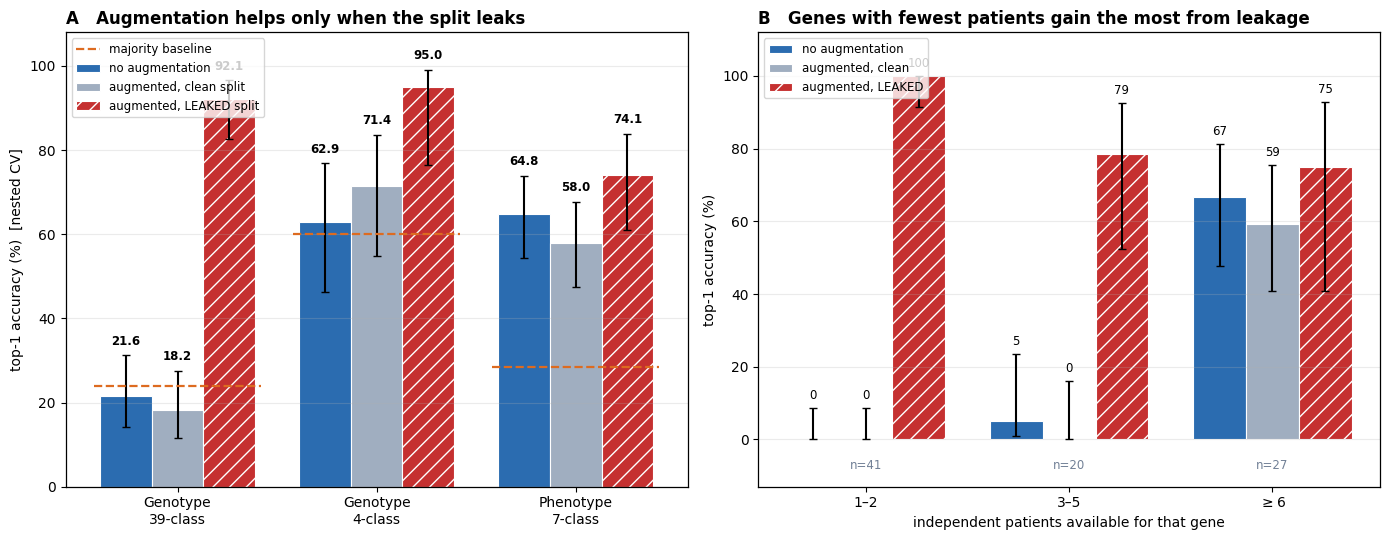

task                      no-aug   aug-clean   aug-LEAK   baseline
Genotype 39-class          21.6%       18.2%      92.1%      23.9%
Genotype 4-class           62.9%       71.4%      95.0%      60.0%
Phenotype 7-class          64.8%       58.0%      74.1%      28.4%


In [42]:
import numpy as np, matplotlib.pyplot as plt, warnings; warnings.filterwarnings('ignore')
from collections import Counter

BLUE, GREY, RED = '#2b6cb0', '#a0aec0', '#c53030'

def t1(r): return np.mean([x[3]==0 for x in r])*100
def wilson(k, n, z=1.96):
    if n == 0: return (0,0)
    p = k/n; d = 1+z*z/n
    c = (p+z*z/(2*n))/d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0,c-h), min(1,c+h)
def ci(r):
    n = len(r); k = sum(1 for x in r if x[3]==0)
    lo, hi = wilson(k, n); m = k/n*100
    return m-lo*100, hi*100-m

TASKS = [
    ('Genotype\n39-class', rows_ng,  rows_aug_nested,    rows_leak_nested,  maj[1]/len(uniq_pat)*100),
    ('Genotype\n4-class',  rows_4_nested, rows_4a_nested, rows_leak4_nested, maj4[1]/len(up4)*100),
    ('Phenotype\n7-class', rows_np,  rows_ph_aug_nested, rows_leakph_nested, majp[1]/len(uniq_pat)*100),
]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

# ---------- A: task x design ----------
a = ax[0]
x = np.arange(len(TASKS)); w = 0.26
for j, (lab, col, idx) in enumerate([('no augmentation', BLUE, 1),
                                     ('augmented, clean split', GREY, 2),
                                     ('augmented, LEAKED split', RED, 3)]):
    vals = [t1(t[idx]) for t in TASKS]
    errs = np.array([ci(t[idx]) for t in TASKS]).T
    a.bar(x + (j-1)*w, vals, w, yerr=errs, capsize=3, color=col, label=lab,
          hatch='//' if j == 2 else None, edgecolor='white', linewidth=.8)
    for i, v in enumerate(vals):
        a.text(x[i]+(j-1)*w, v+errs[1][i]+2.5, f'{v:.1f}', ha='center',
               fontsize=8.5, fontweight='bold')
for i, t in enumerate(TASKS):
    a.plot([x[i]-.42, x[i]+.42], [t[4]]*2, ls='--', c='#dd6b20', lw=1.6,
           label='majority baseline' if i == 0 else None)
a.set_xticks(x); a.set_xticklabels([t[0] for t in TASKS])
a.set_ylabel('top-1 accuracy (%)  [nested CV]'); a.set_ylim(0, 108)
a.set_title('A   Augmentation helps only when the split leaks',
            loc='left', fontweight='bold')
a.legend(fontsize=8.5, loc='upper left'); a.grid(alpha=.25, axis='y')

# ---------- B: stratified by patients per gene ----------
b = ax[1]
gl_a_ = np.array(sorted(set(gene_aug)))
gcp_  = Counter({p: gene_aug[pat_aug==p][0] for p in set(pat_aug)}.values())
groups = [(1,2,'1–2'), (3,5,'3–5'), (6,99,'$\\geq$6')]
xs = np.arange(len(groups))
for j, (lab, col, rows, cmap) in enumerate([
        ('no augmentation', BLUE, rows_ng, lambda i: gcount[gene_list[i]]),
        ('augmented, clean', GREY, rows_aug_nested, lambda i: gcp_[gl_a_[i]]),
        ('augmented, LEAKED', RED, rows_leak_nested, lambda i: gcp_[gl_a_[i]])]):
    vals, errs, ns = [], [], []
    for lo, hi, _ in groups:
        s = [r for r in rows if lo <= cmap(r[1]) <= hi]
        if s:
            vals.append(t1(s)); errs.append(ci(s)); ns.append(len(s))
        else:
            vals.append(0); errs.append((0,0)); ns.append(0)
    errs = np.array(errs).T
    b.bar(xs + (j-1)*w, vals, w, yerr=errs, capsize=3, color=col, label=lab,
          hatch='//' if j == 2 else None, edgecolor='white', linewidth=.8)
    for i, v in enumerate(vals):
        b.text(xs[i]+(j-1)*w, v+errs[1][i]+2.5, f'{v:.0f}', ha='center', fontsize=8.5)
    if j == 0: ns0 = ns
for i, n in enumerate(ns0):
    b.text(xs[i], -8, f'n={n}', ha='center', fontsize=8.5, color='#718096')
b.set_xticks(xs); b.set_xticklabels([g[2] for g in groups])
b.set_xlabel('independent patients available for that gene')
b.set_ylabel('top-1 accuracy (%)'); b.set_ylim(-13, 112)
b.set_title('B   Genes with fewest patients gain the most from leakage',
            loc='left', fontweight='bold')
b.legend(fontsize=8.5, loc='upper left'); b.grid(alpha=.25, axis='y')

plt.tight_layout()
plt.savefig('/kaggle/working/results/ML_fig4_augmentation.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"{'task':22s} {'no-aug':>9s} {'aug-clean':>11s} {'aug-LEAK':>10s} {'baseline':>10s}")
for lab, A, B, C, base in TASKS:
    print(f"{lab.replace(chr(10),' '):22s} {t1(A):8.1f}% {t1(B):10.1f}% {t1(C):9.1f}% {base:9.1f}%")

ACQUISITION CONFOUND CHECK — retinal field fraction (Omega)
  normal   mean 60.7%  (n=393)
  abnormal mean 53.5%  (n=173)
  Mann-Whitney U p = 9.67e-06

  AUC using Omega fraction ALONE : 0.617
  AUC of the detection model      : 0.961

  Spearman(model score, Omega) = -0.118  p = 0.0050
  -> model largely independent of field size


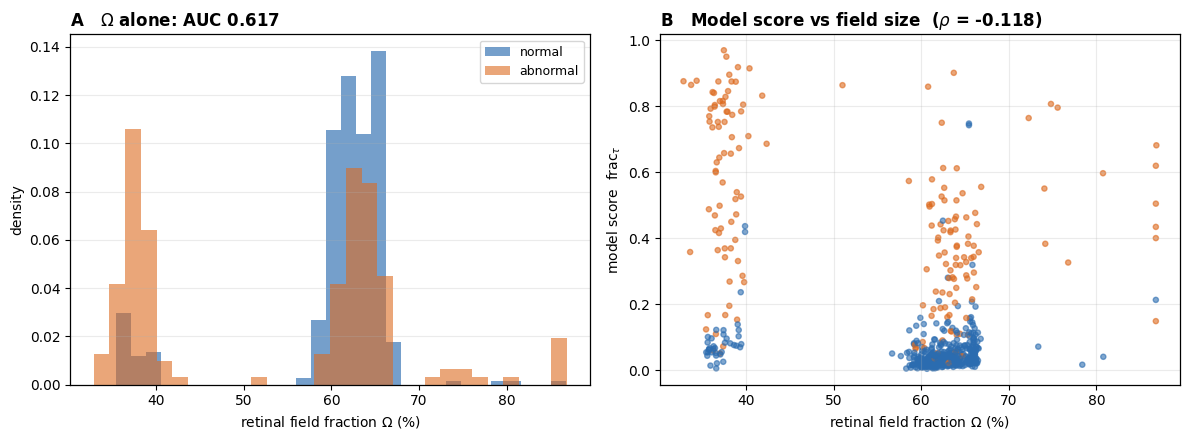


saved ml_omega_check.pkl


In [43]:
import numpy as np, matplotlib.pyplot as plt, pickle, warnings; warnings.filterwarnings('ignore')
from sklearn.metrics import roc_auc_score
from scipy.stats import mannwhitneyu, spearmanr

# fracs pehle compute hua tha; agar nahi hai to dobara nikaalo
if 'fracs' not in dir():
    fracs = np.array([preprocess(im)[1].mean() for im in imgs])

auc_om = roc_auc_score(1-labels, fracs)
u, p_mw = mannwhitneyu(fracs[labels==0], fracs[labels==1])

print("="*62)
print("ACQUISITION CONFOUND CHECK — retinal field fraction (Omega)")
print("="*62)
print(f"  normal   mean {fracs[labels==0].mean()*100:.1f}%  (n={(labels==0).sum()})")
print(f"  abnormal mean {fracs[labels==1].mean()*100:.1f}%  (n={(labels==1).sum()})")
print(f"  Mann-Whitney U p = {p_mw:.2e}")
print(f"\n  AUC using Omega fraction ALONE : {auc_om:.3f}")
print(f"  AUC of the detection model      : {roc_auc_score(Y, S):.3f}")

# does the model score just track omega?
IDX = np.concatenate([r['te_i'] for r in oc])
rho, p_sp = spearmanr(fracs[IDX], S)
print(f"\n  Spearman(model score, Omega) = {rho:+.3f}  p = {p_sp:.4f}")
print(f"  -> {'model largely independent of field size' if abs(rho)<0.4 else 'CAUTION: score tracks field size'}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(fracs[labels==0]*100, bins=30, alpha=.65, color='#2b6cb0', density=True, label='normal')
ax[0].hist(fracs[labels==1]*100, bins=30, alpha=.6, color='#dd6b20', density=True, label='abnormal')
ax[0].set_xlabel('retinal field fraction $\\Omega$ (%)'); ax[0].set_ylabel('density')
ax[0].set_title(f'A   $\\Omega$ alone: AUC {auc_om:.3f}', loc='left', fontweight='bold')
ax[0].legend(fontsize=9); ax[0].grid(alpha=.25, axis='y')

ax[1].scatter(fracs[IDX]*100, S, s=14, c=['#2b6cb0' if y_==0 else '#dd6b20' for y_ in Y], alpha=.6)
ax[1].set_xlabel('retinal field fraction $\\Omega$ (%)'); ax[1].set_ylabel('model score  frac$_\\tau$')
ax[1].set_title(f'B   Model score vs field size  ($\\rho$ = {rho:+.3f})', loc='left', fontweight='bold')
ax[1].grid(alpha=.25)
plt.tight_layout()
plt.savefig('/kaggle/working/results/ML_figS_omega.png', dpi=300, bbox_inches='tight')
plt.show()

pickle.dump(dict(fracs=fracs, auc_om=auc_om, rho=rho, p_mw=p_mw),
            open('/kaggle/working/results/ml_omega_check.pkl','wb'))
print("\nsaved ml_omega_check.pkl")

In [44]:
print(type(y), type(yph), type(X), type(g_pat))

<class 'float'> <class 'numpy.ndarray'> <class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [45]:
y   = np.array([{g:i for i,g in enumerate(gene_list)}[g] for g in g_gene])
yph = np.array([{p:i for i,p in enumerate(ph_list)}[p] for p in g_pheno])
print(y.shape, yph.shape, X.shape)

(173,) (173,) (173, 768)


In [49]:
import numpy as np, pickle, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

def nested_cv(Xm, ym, pats, uniq, fold_map_, topk_sel=1, n_inner=12, npca=15, seed=0):
    rows, chosen = [], Counter()
    for f in range(5):
        te_p = sorted([p for p in uniq if fold_map_[p]==f])
        tr_p = sorted([p for p in uniq if fold_map_[p]!=f])
        if not te_p: continue
        te = np.isin(pats, te_p)
        rng = np.random.RandomState(seed+f)
        sub = rng.choice(tr_p, min(n_inner, len(tr_p)), replace=False)
        sc_ = {}
        for nm, mk in CLFS.items():
            c = 0
            for p in sub:
                ite = pats == p
                itr = np.isin(pats, [q for q in tr_p if q != p])
                if len(set(ym[itr])) < 2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(Xm[itr], ym[itr])
                order = list(pipe[-1].classes_[np.argsort(pipe.predict_proba(Xm[ite]).mean(0))[::-1]])
                t = ym[ite][0]
                c += (order.index(t) < topk_sel) if t in order else 0
            sc_[nm] = c
        best = sorted(sc_, key=lambda k: (-sc_[k], k))[0]; chosen[best] += 1
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(Xm[~te], ym[~te]); cl = pipe[-1].classes_
        for p in te_p:
            m = pats[te] == p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pipe.predict_proba(Xm[te])[m].mean(0))[::-1]])
            t = ym[pats==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows, chosen

def fold_map(uniq, labmap, classes, seed):
    rng = np.random.RandomState(seed); fo = {}
    for c in sorted(classes):
        ps = sorted([p for p in uniq if labmap[p]==c]); rng.shuffle(ps)
        s = rng.randint(5)
        for k, p in enumerate(ps): fo[p] = (s+k) % 5
    return fo

SEEDS = [42, 1, 7, 13, 99]
out = {'genotype': [], 'phenotype': []}
t0 = time.time()

for s in SEEDS:
    fo_g = fold_map(uniq_pat, pat_gene, gene_list, s)
    fo_p = fold_map(uniq_pat, pat_ph,   ph_list,   s)
    rg, _ = nested_cv(X, y,   g_pat, uniq_pat, fo_g, topk_sel=3, seed=s)
    rp, _ = nested_cv(X, yph, g_pat, uniq_pat, fo_p, topk_sel=1, seed=s)
    g1 = np.mean([x[3]==0 for x in rg])*100
    p1 = np.mean([x[3]==0 for x in rp])*100
    out['genotype'].append(g1); out['phenotype'].append(p1)
    print(f"  seed {s:3d}:  genotype {g1:5.1f}%   phenotype {p1:5.1f}%   ({time.time()-t0:.0f}s)")

print(f"\n{'='*58}")
print(f"SEED STABILITY — nested CV over {len(SEEDS)} fold assignments")
print("="*58)
for k, base in [('genotype', maj[1]/len(uniq_pat)*100),
                ('phenotype', majp[1]/len(uniq_pat)*100)]:
    v = np.array(out[k])
    print(f"  {k:10s} {v.mean():5.1f}% ± {v.std():.1f}   "
          f"range {v.min():.1f}–{v.max():.1f}%   baseline {base:.1f}%")

pickle.dump(out, open('/kaggle/working/results/ml_seed_stability.pkl','wb'))
print("\nsaved ml_seed_stability.pkl")

  seed  42:  genotype  19.3%   phenotype  68.2%   (207s)
  seed   1:  genotype  22.7%   phenotype  64.8%   (420s)
  seed   7:  genotype  22.7%   phenotype  67.0%   (638s)
  seed  13:  genotype  26.1%   phenotype  72.7%   (838s)
  seed  99:  genotype  20.5%   phenotype  65.9%   (1051s)

SEED STABILITY — nested CV over 5 fold assignments
  genotype    22.3% ± 2.3   range 19.3–26.1%   baseline 23.9%
  phenotype   67.7% ± 2.7   range 64.8–72.7%   baseline 28.4%

saved ml_seed_stability.pkl


In [7]:
import numpy as np
from collections import Counter

SEED = 42
rng = np.random.RandomState(SEED)

# ---- abnormal: patient-level, phenotype-stratified ----
ab_pats = np.array(sorted(set(patient[labels==1])))
pat_ph  = {p: pheno[patient==p][0] for p in ab_pats}

te_p, va_p, tr_p = set(), set(), set()
for ph_ in sorted(set(pat_ph.values())):                 # har phenotype se proportional
    ps = sorted([p for p in ab_pats if pat_ph[p]==ph_]); rng.shuffle(ps)
    n = len(ps)
    k_te = max(1, int(round(0.20*n)))
    k_va = int(round(0.10*n))
    te_p |= set(ps[:k_te])
    va_p |= set(ps[k_te:k_te+k_va])
    tr_p |= set(ps[k_te+k_va:])

# ---- assign ----
split = np.array(['train']*len(imgs), dtype=object)
for i in range(len(imgs)):
    if labels[i] == 1:
        p = patient[i]
        split[i] = 'test' if p in te_p else ('val' if p in va_p else 'train')

# ---- normal: batch-stratified ----
for b in np.unique(batch[labels==0]):
    idx = np.where((labels==0) & (batch==b))[0]
    rng.shuffle(idx)
    k_te = max(1, int(round(0.20*len(idx))))
    k_va = max(1, int(round(0.10*len(idx))))
    split[idx[:k_te]] = 'test'
    split[idx[k_te:k_te+k_va]] = 'val'
    split[idx[k_te+k_va:]] = 'train'

print("="*56)
print(f"{'split':8s} {'normal':>8s} {'abnormal':>10s} {'total':>8s} {'%':>6s}")
for s in ['train','val','test']:
    n0 = int(((split==s)&(labels==0)).sum()); n1 = int(((split==s)&(labels==1)).sum())
    print(f"{s:8s} {n0:8d} {n1:10d} {n0+n1:8d} {(n0+n1)/len(imgs)*100:5.1f}%")
print("="*56)
print(f"\nAbnormal patients: train {len(tr_p)}  val {len(va_p)}  test {len(te_p)}  "
      f"(total {len(ab_pats)})")

# ---- leakage checks ----
print(f"\nLeakage checks:")
bad = [p for p in ab_pats if len(set(split[patient==p])) > 1]
for p in bad: print(f"  LEAK: patient {p} in {set(split[patient==p])}")
print(f"  patients spanning splits : {len(bad)}")
print(f"  train∩test patients      : {len(tr_p & te_p)}")
print(f"  train∩val patients       : {len(tr_p & va_p)}")
print(f"  val∩test patients        : {len(va_p & te_p)}")
tr_i = set(np.where(split=='train')[0]); te_i = set(np.where(split=='test')[0])
print(f"  train∩test image indices : {len(tr_i & te_i)}")

print(f"\nBatch distribution (normal)   train / val / test:")
for b in np.unique(batch[labels==0]):
    r = [int(((split==s)&(labels==0)&(batch==b)).sum()) for s in ['train','val','test']]
    print(f"  {b[:22]:24s} {r[0]:4d} / {r[1]:3d} / {r[2]:3d}")

print(f"\nPhenotype distribution (abnormal patients):")
allph = sorted(set(pat_ph.values()))
print(f"  {'phenotype':22s} {'train':>6s} {'val':>5s} {'test':>5s}")
for c in allph:
    r = [sum(1 for p in ps if pat_ph[p]==c) for ps in [tr_p, va_p, te_p]]
    print(f"  {c:22s} {r[0]:6d} {r[1]:5d} {r[2]:5d}")

print(f"\nGene distribution (abnormal patients, top 10):")
pat_g = {p: gene[patient==p][0] for p in ab_pats}
for c, _ in Counter(pat_g.values()).most_common(10):
    r = [sum(1 for p in ps if pat_g[p]==c) for ps in [tr_p, va_p, te_p]]
    print(f"  {c:10s} {r[0]:4d} / {r[1]:3d} / {r[2]:3d}")

split      normal   abnormal    total      %
train         276        123      399  70.5%
val            39         14       53   9.4%
test           78         36      114  20.1%

Abnormal patients: train 63  val 7  test 18  (total 88)

Leakage checks:
  patients spanning splits : 0
  train∩test patients      : 0
  train∩val patients       : 0
  val∩test patients        : 0
  train∩test image indices : 0

Batch distribution (normal)   train / val / test:
  aditi_part1                38 /   6 /  11
  aditi_part2                31 /   4 /   9
  iit_part1                  30 /   4 /   9
  iit_part2                  29 /   4 /   8
  normal 1                   25 /   4 /   7
  normal_new                 56 /   8 /  16
  omkar_part1                23 /   3 /   6
  omkar_part2                44 /   6 /  12

Phenotype distribution (abnormal patients):
  phenotype               train   val  test
  CONE DYSTROPHY             10     2     3
  CONE ROD DYSTROPHY          8     1     2
  HYPER RP 

In [13]:
!pip install -q --force-reinstall --no-cache-dir "pillow==11.3.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 164.7 MB/s eta 0:00:00a 0:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pdfplumber 0.11.10 requires Pillow>=12.2.0, but you have pillow 11.3.0 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [14]:
import torch, torch.nn as nn, timm, numpy as np, cv2, time, copy
from torch.utils.data import Dataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

IMG_SIZE = 518          # ViT-S/14 -> 37x37 patches; fits memory for fine-tuning
MEAN = np.array([0.485,0.456,0.406], np.float32)
STD  = np.array([0.229,0.224,0.225], np.float32)

# ---------- pre-mask every image once (saves time during training) ----------
print("\nPreprocessing all images (mask + resize)...")
proc = []
t0 = time.time()
for i, im in enumerate(imgs):
    img, om = preprocess(im)
    img = img.copy(); img[om == 0] = 0                       # black outside retina
    proc.append(cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
    if (i+1) % 150 == 0: print(f"  {i+1}/{len(imgs)} ({time.time()-t0:.0f}s)")
proc = np.stack(proc)
print(f"done: {proc.shape}  {proc.nbytes/1e9:.2f} GB")

# ---------- dataset ----------
class RetinaDS(Dataset):
    def __init__(self, idx, y, train=False):
        self.idx, self.y, self.train = idx, y, train
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        im = proc[i].copy()
        if self.train:
            if np.random.rand() < 0.5: im = im[:, ::-1]
            if np.random.rand() < 0.5: im = im[::-1, :]
            if np.random.rand() < 0.5:
                a = np.random.uniform(-15, 15)
                M = cv2.getRotationMatrix2D((IMG_SIZE/2, IMG_SIZE/2), a, 1.0)
                im = cv2.warpAffine(im, M, (IMG_SIZE, IMG_SIZE))
            if np.random.rand() < 0.5:
                im = np.clip(im.astype(np.float32) * np.random.uniform(0.85, 1.15)
                             + np.random.uniform(-12, 12), 0, 255).astype(np.uint8)
        x = (np.ascontiguousarray(im).astype(np.float32)/255. - MEAN)/STD
        return torch.from_numpy(x).permute(2,0,1), torch.tensor(self.y[k], dtype=torch.long)

# ---------- model ----------
class DinoClassifier(nn.Module):
    def __init__(self, n_classes=2, unfreeze_blocks=0, dropout=0.3):
        super().__init__()
        self.backbone = timm.create_model('vit_small_patch14_dinov2.lvd142m',
                                          pretrained=True, num_classes=0,
                                          dynamic_img_size=True)
        for p in self.backbone.parameters(): p.requires_grad = False
        if unfreeze_blocks == -1:                       # full fine-tune
            for p in self.backbone.parameters(): p.requires_grad = True
        elif unfreeze_blocks > 0:
            for blk in self.backbone.blocks[-unfreeze_blocks:]:
                for p in blk.parameters(): p.requires_grad = True
            for p in self.backbone.norm.parameters(): p.requires_grad = True
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(384, n_classes))
    def forward(self, x):
        return self.head(self.backbone(x))

def count_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

# quick check
for nm, ub in [('A frozen', 0), ('B last-4', 4), ('C full', -1)]:
    m = DinoClassifier(unfreeze_blocks=ub)
    print(f"{nm:12s} trainable params: {count_trainable(m):,}")
    del m
torch.cuda.empty_cache()

Device: cuda | Tesla T4

Preprocessing all images (mask + resize)...
  150/566 (20s)
  300/566 (47s)
  450/566 (68s)
done: (566, 518, 518, 3)  0.46 GB
A frozen     trainable params: 770
B last-4     trainable params: 7,102,466
C full       trainable params: 22,056,962


In [15]:
import torch, torch.nn as nn, numpy as np, time, copy
from torch.utils.data import DataLoader
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

tr_idx = np.where(split=='train')[0]
va_idx = np.where(split=='val')[0]
te_idx = np.where(split=='test')[0]
y_all  = labels.astype(int)

print(f"train {len(tr_idx)} | val {len(va_idx)} | test {len(te_idx)}")

# class weights from TRAINING split only
cw = len(tr_idx) / (2 * np.bincount(y_all[tr_idx]))
print(f"class weights: normal {cw[0]:.2f}, abnormal {cw[1]:.2f}")

def make_loaders(bs):
    return (DataLoader(RetinaDS(tr_idx, y_all[tr_idx], train=True),
                       batch_size=bs, shuffle=True,  num_workers=2, drop_last=True),
            DataLoader(RetinaDS(va_idx, y_all[va_idx], train=False),
                       batch_size=bs, shuffle=False, num_workers=2),
            DataLoader(RetinaDS(te_idx, y_all[te_idx], train=False),
                       batch_size=bs, shuffle=False, num_workers=2))

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        p = torch.softmax(model(x.to(device)), 1)[:, 1]
        P.append(p.cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)

def metrics(y, p, th=0.5):
    yh = (p > th).astype(int)
    tn_, fp, fn, tp = confusion_matrix(y, yh, labels=[0,1]).ravel()
    return dict(auc=roc_auc_score(y, p), acc=accuracy_score(y, yh),
                prec=precision_score(y, yh, zero_division=0),
                sens=recall_score(y, yh, zero_division=0),
                spec=tn_/(tn_+fp) if (tn_+fp) else 0.0,
                f1=f1_score(y, yh, zero_division=0),
                tn=tn_, fp=fp, fn=fn, tp=tp)

def train_variant(name, unfreeze, lr_head, lr_bb, epochs=25, bs=16,
                  patience=6, wd=0.05, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    tr_ld, va_ld, te_ld = make_loaders(bs)
    model = DinoClassifier(unfreeze_blocks=unfreeze).to(device)

    bb = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{'params': model.head.parameters(), 'lr': lr_head}]
    if bb: groups.append({'params': bb, 'lr': lr_bb})
    opt = torch.optim.AdamW(groups, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32).to(device))
    scaler = torch.amp.GradScaler('cuda')

    print(f"\n{'='*74}")
    print(f"VARIANT {name}   trainable {count_trainable(model):,}   "
          f"lr_head {lr_head}  lr_bb {lr_bb if bb else '-'}")
    print("="*74)
    print(f"{'ep':>3s} {'tr_loss':>8s} {'va_loss':>8s} {'va_auc':>7s} {'va_acc':>7s} "
          f"{'va_f1':>7s} {'sens':>6s} {'spec':>6s}  {'time':>6s}")

    best = {'auc': -1, 'state': None, 'ep': 0}
    hist, bad = [], 0
    for ep in range(1, epochs+1):
        t0 = time.time(); model.train(); tl, nb = 0.0, 0
        for x, y in tr_ld:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.amp.autocast('cuda'):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item(); nb += 1
        sched.step()

        pv, yv = evaluate(model, va_ld)
        vl = nn.functional.cross_entropy(
                torch.log(torch.stack([1-torch.tensor(pv), torch.tensor(pv)],1).clamp(1e-7)),
                torch.tensor(yv)).item()
        m = metrics(yv, pv)
        hist.append({'ep': ep, 'tr_loss': tl/nb, 'va_loss': vl, **m})
        print(f"{ep:3d} {tl/nb:8.4f} {vl:8.4f} {m['auc']:7.3f} {m['acc']:7.3f} "
              f"{m['f1']:7.3f} {m['sens']:6.3f} {m['spec']:6.3f}  {time.time()-t0:5.0f}s")

        if m['auc'] > best['auc']:
            best = {'auc': m['auc'], 'state': copy.deepcopy(model.state_dict()), 'ep': ep}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                print(f"  early stop at epoch {ep} (best epoch {best['ep']}, val AUC {best['auc']:.3f})")
                break

    model.load_state_dict(best['state'])
    pv, yv = evaluate(model, va_ld)
    pt, yt = evaluate(model, te_ld)

    # threshold chosen on VAL only
    from sklearn.metrics import roc_curve
    fpr, tpr, ths = roc_curve(yv, pv)
    th_star = float(ths[np.argmax(tpr - fpr)])

    mv, mt5, mtb = metrics(yv, pv), metrics(yt, pt, 0.5), metrics(yt, pt, th_star)
    print(f"\n  best epoch {best['ep']}   val AUC {mv['auc']:.3f}")
    print(f"  Youden threshold from val: {th_star:.3f}")
    print(f"\n  {'':14s} {'AUC':>6s} {'acc':>6s} {'prec':>6s} {'sens':>6s} {'spec':>6s} {'F1':>6s}")
    for tag, m in [('VAL @0.5', mv), ('TEST @0.5', mt5), (f'TEST @{th_star:.2f}', mtb)]:
        print(f"  {tag:14s} {m['auc']:6.3f} {m['acc']:6.3f} {m['prec']:6.3f} "
              f"{m['sens']:6.3f} {m['spec']:6.3f} {m['f1']:6.3f}")
    print(f"\n  TEST confusion @0.5 : TN {mt5['tn']}  FP {mt5['fp']}  FN {mt5['fn']}  TP {mt5['tp']}")

    del model; torch.cuda.empty_cache()
    return {'name': name, 'hist': hist, 'best_ep': best['ep'],
            'val': mv, 'test_05': mt5, 'test_th': mtb, 'th': th_star,
            'pv': pv, 'yv': yv, 'pt': pt, 'yt': yt}

results = {}
results['A'] = train_variant('A - frozen backbone', unfreeze=0,  lr_head=1e-3, lr_bb=0,    epochs=30, bs=16)

train 399 | val 53 | test 114
class weights: normal 0.72, abnormal 1.62

VARIANT A - frozen backbone   trainable 770   lr_head 0.001  lr_bb -
 ep  tr_loss  va_loss  va_auc  va_acc   va_f1   sens   spec    time
  1   0.6995   0.2263   0.960   0.925   0.833  0.714  1.000      8s
  2   0.3364   0.2561   0.967   0.887   0.800  0.857  0.897      7s
  3   0.3231   0.1840   0.984   0.962   0.929  0.929  0.974      7s
  4   0.2333   0.1971   0.987   0.906   0.839  0.929  0.897      7s
  5   0.2213   0.1159   0.987   0.962   0.923  0.857  1.000      7s
  6   0.2177   0.1273   0.991   0.943   0.897  0.929  0.949      7s
  7   0.1892   0.1360   0.993   0.943   0.897  0.929  0.949      7s
  8   0.1604   0.1014   0.993   0.981   0.963  0.929  1.000      7s
  9   0.1981   0.1129   0.993   0.962   0.929  0.929  0.974      7s
 10   0.1699   0.0888   0.995   0.962   0.923  0.857  1.000      7s
 11   0.1881   0.0808   0.995   0.981   0.963  0.929  1.000      7s
 12   0.1708   0.1083   0.995   0.943   0.

In [16]:
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
pt, yt = results['A']['pt'], results['A']['yt']
print(f"TEST confusion: TN {results['A']['test_05']['tn']}  FP {results['A']['test_05']['fp']}  "
      f"FN {results['A']['test_05']['fn']}  TP {results['A']['test_05']['tp']}")

rho, p = spearmanr(fracs[te_idx], pt)
print(f"\nSpearman(DL score, Omega) = {rho:+.3f}  p = {p:.4f}")

# per-batch false positives
import numpy as np
print(f"\nfalse positives by batch:")
for b in np.unique(batch[te_idx][labels[te_idx]==0]):
    m = (batch[te_idx]==b) & (labels[te_idx]==0)
    fp = int((pt[m] > 0.5).sum())
    print(f"  {b[:22]:24s} {fp}/{m.sum()}")

# which abnormals were missed
miss = [i for k,i in enumerate(te_idx) if labels[i]==1 and pt[k] <= 0.5]
print(f"\nmissed abnormals ({len(miss)}):")
for i in miss:
    print(f"  {names[i][:28]:30s} {patient[i][:20]:22s} {gene[i]:8s} {pheno[i]}")

TEST confusion: TN 78  FP 0  FN 4  TP 32

Spearman(DL score, Omega) = -0.309  p = 0.0008

false positives by batch:
  aditi_part1              0/11
  aditi_part2              0/9
  iit_part1                0/9
  iit_part2                0/8
  normal 1                 0/7
  normal_new               0/16
  omkar_part1              0/6
  omkar_part2              0/12

missed abnormals (4):
  Anekant_L.jpg                  ANEKANT JAIN           ABCA4    CONE DYSTROPHY
  Anekant_R.jpg                  ANEKANT JAIN           ABCA4    CONE DYSTROPHY
  Tamnanah_L.jpg                 TAMANNAH               ABCA4    HYPO
  Tamnanah_R.jpg                 TAMANNAH               ABCA4    HYPO


In [17]:
from scipy.stats import spearmanr
import numpy as np
pt = results['A']['pt']
m0 = labels[te_idx]==0; m1 = labels[te_idx]==1
r0, p0 = spearmanr(fracs[te_idx][m0], pt[m0])
r1, p1 = spearmanr(fracs[te_idx][m1], pt[m1])
print(f"within normals   rho {r0:+.3f}  p {p0:.3f}  (n={m0.sum()})")
print(f"within abnormals rho {r1:+.3f}  p {p1:.3f}  (n={m1.sum()})")
print(f"\nOmega of missed:  {fracs[[i for k,i in enumerate(te_idx) if labels[i]==1 and pt[k]<=0.5]].mean()*100:.1f}%")
print(f"Omega of caught:  {fracs[[i for k,i in enumerate(te_idx) if labels[i]==1 and pt[k]>0.5]].mean()*100:.1f}%")

within normals   rho +0.118  p 0.304  (n=78)
within abnormals rho -0.521  p 0.001  (n=36)

Omega of missed:  61.2%
Omega of caught:  45.8%


In [18]:
import numpy as np
ab = labels==1
print("Omega by phenotype (abnormal only):")
for c in sorted(set(pheno[ab])):
    m = ab & (pheno==c)
    print(f"  {c:22s} {fracs[m].mean()*100:5.1f}%  (n={m.sum()})")
print(f"\n  NORMAL                 {fracs[labels==0].mean()*100:5.1f}%  (n={(labels==0).sum()})")

# raw image size — agar zoom/crop hota to actual pixel dimensions bhi alag hote
print("\nraw image dimensions:")
for lab, m in [('normal', labels==0), ('abnormal', labels==1)]:
    hs = np.array([imgs[i].shape[0] for i in np.where(m)[0]])
    ws = np.array([imgs[i].shape[1] for i in np.where(m)[0]])
    print(f"  {lab:10s} h {hs.mean():.0f}±{hs.std():.0f}   w {ws.mean():.0f}±{ws.std():.0f}")

Omega by phenotype (abnormal only):
  CONE DYSTROPHY          51.3%  (n=30)
  CONE ROD DYSTROPHY      59.5%  (n=21)
  HYPER RP                54.5%  (n=49)
  HYPO                    51.9%  (n=45)
  LCA HYPER               52.5%  (n=10)
  LCA HYPO                50.2%  (n=8)
  STARGARDTS              53.0%  (n=10)

  NORMAL                  60.7%  (n=393)

raw image dimensions:
  normal     h 1023±0   w 1024±0
  abnormal   h 989±135   w 1024±0


In [19]:
import numpy as np
from sklearn.metrics import roc_auc_score
h = np.array([im.shape[0] for im in imgs])
print(f"AUC using image HEIGHT alone: {roc_auc_score(1-labels, h):.3f}")
print(f"\nheight distribution:")
for lab, m in [('normal', labels==0), ('abnormal', labels==1)]:
    print(f"  {lab:10s} unique heights: {sorted(set(h[m]))[:8]}{'...' if len(set(h[m]))>8 else ''}")
print(f"\nabnormal heights by batch:")
for b in sorted(set(batch[labels==1])):
    m = (labels==1) & (batch==b)
    print(f"  {b[:22]:24s} {sorted(set(h[m]))}")

AUC using image HEIGHT alone: 0.569

height distribution:
  normal     unique heights: [np.int64(1022), np.int64(1023)]
  abnormal   unique heights: [np.int64(443), np.int64(1022), np.int64(1023)]

abnormal heights by batch:
  1)Naira                  [np.int64(1023)]
  1)Rupam kumar            [np.int64(1022), np.int64(1023)]
  1)Tamannah               [np.int64(1022), np.int64(1023)]
  2)Durga                  [np.int64(443), np.int64(1022), np.int64(1023)]
  2)Monika gupta           [np.int64(443), np.int64(1022), np.int64(1023)]
  abn_old_1                [np.int64(443), np.int64(1022), np.int64(1023)]
  rida_ashraf              [np.int64(1023)]
  tanya_mittal             [np.int64(443), np.int64(1022), np.int64(1023)]
  tsetan_dolker            [np.int64(1022)]


In [20]:
n443 = ((h==443) & (labels==1)).sum()
print(f"443-height images: {n443} / {(labels==1).sum()} abnormal")
print(f"their mean Omega: {fracs[(h==443)].mean()*100:.1f}%  vs others {fracs[(h!=443)&(labels==1)].mean()*100:.1f}%")

443-height images: 10 / 173 abnormal
their mean Omega: 58.8%  vs others 53.2%


In [21]:
import numpy as np, torch, torch.nn as nn, time, copy
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve)

def make_folds(n_splits=5, seed=42):
    """Patient-level for abnormal, batch-stratified for normal."""
    rng = np.random.RandomState(seed)
    fold = np.full(len(imgs), -1)

    # abnormal: assign patients to folds, stratified by phenotype
    ab_pats = np.array(sorted(set(patient[labels==1])))
    pat_ph_ = np.array([pheno[patient==p][0] for p in ab_pats])
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for f, (_, te) in enumerate(skf.split(ab_pats, pat_ph_)):
        for p in ab_pats[te]:
            fold[patient == p] = f

    # normal: batch-stratified
    for b in np.unique(batch[labels==0]):
        idx = np.where((labels==0) & (batch==b))[0]
        rng.shuffle(idx)
        for k, i in enumerate(idx):
            fold[i] = k % n_splits
    return fold

fold = make_folds()
print(f"{'fold':>5s} {'normal':>8s} {'abnormal':>10s} {'total':>7s}")
for f in range(5):
    n0 = int(((fold==f)&(labels==0)).sum()); n1 = int(((fold==f)&(labels==1)).sum())
    print(f"{f:5d} {n0:8d} {n1:10d} {n0+n1:7d}")

# leakage check
ab_pats = sorted(set(patient[labels==1]))
leaks = [p for p in ab_pats if len(set(fold[patient==p])) > 1]
print(f"\nPatients spanning folds: {len(leaks)}  {leaks[:5]}")
print(f"Unassigned images: {(fold==-1).sum()}")

np.save('/kaggle/working/results/dl_folds.npy', fold)

 fold   normal   abnormal   total
    0       82         35     117
    1       80         36     116
    2       78         35     113
    3       77         34     111
    4       76         33     109

Patients spanning folds: 0  []
Unassigned images: 0


In [22]:
import numpy as np, torch, torch.nn as nn, time, copy
from torch.utils.data import DataLoader
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve)

def metrics(y, p, th=0.5):
    yh = (p > th).astype(int)
    tn_, fp, fn, tp = confusion_matrix(y, yh, labels=[0,1]).ravel()
    return dict(auc=roc_auc_score(y, p), acc=accuracy_score(y, yh),
                prec=precision_score(y, yh, zero_division=0),
                sens=recall_score(y, yh, zero_division=0),
                spec=tn_/(tn_+fp) if (tn_+fp) else 0.0,
                f1=f1_score(y, yh, zero_division=0),
                tn=tn_, fp=fp, fn=fn, tp=tp)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        p = torch.softmax(model(x.to(device)), 1)[:, 1]
        P.append(p.cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)

def run_fold(f, unfreeze, lr_head, lr_bb, epochs, bs, patience=6, wd=0.05, seed=0):
    torch.manual_seed(seed + f); np.random.seed(seed + f)

    te_i = np.where(fold == f)[0]
    rest = np.where(fold != f)[0]

    # inner val: 15% of rest, patient-level for abnormal
    rng = np.random.RandomState(seed + f)
    rest_pats = sorted(set(patient[i] for i in rest if labels[i] == 1))
    rng.shuffle(rest_pats)
    n_val_p = max(1, int(round(0.15 * len(rest_pats))))
    val_pats = set(rest_pats[:n_val_p])
    rest_norm = [i for i in rest if labels[i] == 0]
    rng.shuffle(rest_norm)
    n_val_n = int(round(0.15 * len(rest_norm)))
    val_norm = set(rest_norm[:n_val_n])

    va_i = np.array([i for i in rest if (labels[i]==1 and patient[i] in val_pats)
                                      or (labels[i]==0 and i in val_norm)])
    tr_i = np.array([i for i in rest if i not in set(va_i)])

    cw = len(tr_i) / (2 * np.bincount(y_all[tr_i], minlength=2))

    tr_ld = DataLoader(RetinaDS(tr_i, y_all[tr_i], train=True),
                       batch_size=bs, shuffle=True, num_workers=2, drop_last=True)
    va_ld = DataLoader(RetinaDS(va_i, y_all[va_i]), batch_size=bs, num_workers=2)
    te_ld = DataLoader(RetinaDS(te_i, y_all[te_i]), batch_size=bs, num_workers=2)

    model = DinoClassifier(unfreeze_blocks=unfreeze).to(device)
    bb = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{'params': model.head.parameters(), 'lr': lr_head}]
    if bb: groups.append({'params': bb, 'lr': lr_bb})
    opt = torch.optim.AdamW(groups, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32).to(device))
    scaler = torch.amp.GradScaler('cuda')

    best = {'auc': -1, 'state': None, 'ep': 0}; bad = 0
    for ep in range(1, epochs+1):
        model.train()
        for x, y in tr_ld:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.amp.autocast('cuda'):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        sched.step()
        pv, yv = evaluate(model, va_ld)
        a = roc_auc_score(yv, pv)
        if a > best['auc']:
            best = {'auc': a, 'state': copy.deepcopy(model.state_dict()), 'ep': ep}; bad = 0
        else:
            bad += 1
            if bad >= patience: break

    model.load_state_dict(best['state'])
    pv, yv = evaluate(model, va_ld)
    pt, yt = evaluate(model, te_ld)
    fpr, tpr, ths = roc_curve(yv, pv)
    th = float(ths[np.argmax(tpr - fpr)])

    del model; torch.cuda.empty_cache()
    return dict(fold=f, n_tr=len(tr_i), n_va=len(va_i), n_te=len(te_i),
                best_ep=best['ep'], th=th, pt=pt, yt=yt, te_i=te_i,
                m05=metrics(yt, pt, 0.5), mth=metrics(yt, pt, th))

def run_cv(name, unfreeze, lr_head, lr_bb, epochs, bs):
    print(f"\n{'='*78}")
    print(f"5-FOLD CV  --  {name}")
    print("="*78)
    print(f"{'fold':>4s} {'n_tr':>5s} {'n_va':>5s} {'n_te':>5s} {'ep':>3s} "
          f"{'AUC':>6s} {'acc':>6s} {'prec':>6s} {'sens':>6s} {'spec':>6s} {'F1':>6s} {'time':>6s}")
    out = []
    for f in range(5):
        t0 = time.time()
        r = run_fold(f, unfreeze, lr_head, lr_bb, epochs, bs)
        m = r['m05']
        print(f"{f:4d} {r['n_tr']:5d} {r['n_va']:5d} {r['n_te']:5d} {r['best_ep']:3d} "
              f"{m['auc']:6.3f} {m['acc']:6.3f} {m['prec']:6.3f} {m['sens']:6.3f} "
              f"{m['spec']:6.3f} {m['f1']:6.3f} {time.time()-t0:5.0f}s")
        out.append(r)

    print("-"*78)
    for tag, key in [('@0.5', 'm05'), ('@Youden(val)', 'mth')]:
        agg = {k: np.array([o[key][k] for o in out]) for k in ['auc','acc','prec','sens','spec','f1']}
        print(f"{tag:14s}" + "  ".join(
            f"{k} {agg[k].mean():.3f}±{agg[k].std():.3f}" for k in ['auc','acc','prec','sens','spec','f1']))

    P = np.concatenate([o['pt'] for o in out]); Y = np.concatenate([o['yt'] for o in out])
    mp = metrics(Y, P, 0.5)
    print(f"\nPooled ({len(Y)} images): AUC {mp['auc']:.3f}  acc {mp['acc']:.3f}  "
          f"prec {mp['prec']:.3f}  sens {mp['sens']:.3f}  spec {mp['spec']:.3f}  F1 {mp['f1']:.3f}")
    print(f"Pooled confusion: TN {mp['tn']}  FP {mp['fp']}  FN {mp['fn']}  TP {mp['tp']}")
    return out

cv = {}
cv['A'] = run_cv('A - frozen backbone', unfreeze=0, lr_head=1e-3, lr_bb=0, epochs=30, bs=16)


5-FOLD CV  --  A - frozen backbone
fold  n_tr  n_va  n_te  ep    AUC    acc   prec   sens   spec     F1   time
   0   382    67   117   7  0.973  0.932  0.909  0.857  0.963  0.882   104s
   1   383    67   116   6  0.989  0.948  0.917  0.917  0.963  0.917    96s
   2   386    67   113  14  0.955  0.938  0.967  0.829  0.987  0.892   158s
   3   386    69   111  13  0.992  0.955  1.000  0.853  1.000  0.921   152s
   4   388    69   109   1  0.958  0.927  0.963  0.788  0.987  0.867    61s
------------------------------------------------------------------------------
@0.5          auc 0.973±0.015  acc 0.940±0.010  prec 0.951±0.034  sens 0.849±0.042  spec 0.980±0.015  f1 0.896±0.020
@Youden(val)  auc 0.973±0.015  acc 0.936±0.006  prec 0.919±0.047  sens 0.873±0.035  spec 0.964±0.022  f1 0.894±0.007

Pooled (566 images): AUC 0.970  acc 0.940  prec 0.948  sens 0.850  spec 0.980  F1 0.896
Pooled confusion: TN 385  FP 8  FN 26  TP 147


In [23]:
results['B'] = train_variant('B - last 4 blocks unfrozen', unfreeze=4,
                             lr_head=1e-3, lr_bb=1e-5, epochs=25, bs=8, patience=6)


VARIANT B - last 4 blocks unfrozen   trainable 7,102,466   lr_head 0.001  lr_bb 1e-05
 ep  tr_loss  va_loss  va_auc  va_acc   va_f1   sens   spec    time
  1   0.6075   0.1209   0.996   0.943   0.897  0.929  0.949     10s
  2   0.2402   0.0971   1.000   0.962   0.923  0.857  1.000     10s
  3   0.1675   0.2139   1.000   0.925   0.875  1.000  0.897     10s
  4   0.0896   0.0540   1.000   0.962   0.923  0.857  1.000     10s
  5   0.1106   0.0532   0.998   0.981   0.963  0.929  1.000     10s
  6   0.0318   0.1401   0.998   0.962   0.923  0.857  1.000     10s
  7   0.0878   0.5288   0.996   0.830   0.757  1.000  0.769     10s
  8   0.1113   0.0347   0.998   0.981   0.963  0.929  1.000     10s
  early stop at epoch 8 (best epoch 2, val AUC 1.000)

  best epoch 2   val AUC 1.000
  Youden threshold from val: 0.065

                    AUC    acc   prec   sens   spec     F1
  VAL @0.5        1.000  0.962  1.000  0.857  1.000  0.923
  TEST @0.5       0.991  0.956  0.970  0.889  0.987  0.928
  

In [24]:
import pickle, os, numpy as np, time

os.makedirs('/kaggle/working/results', exist_ok=True)
if 'cv' not in dir(): cv = {}

def run_cv_ckpt(name, unfreeze, lr_head, lr_bb, epochs, bs, tag):
    ck = f'/kaggle/working/cv_{tag}.pkl'
    out = pickle.load(open(ck, 'rb')) if os.path.exists(ck) else []
    done = {r['fold'] for r in out}
    print(f"{'='*78}\n5-FOLD CV  --  {name}")
    if done: print(f"resuming, already done: {sorted(done)}")
    print("="*78)

    for f in range(5):
        if f in done: continue
        t0 = time.time()
        r = run_fold(f, unfreeze, lr_head, lr_bb, epochs, bs)
        m = r['m05']
        print(f"fold {f}  n_te {r['n_te']:3d}  ep {r['best_ep']:2d}  "
              f"AUC {m['auc']:.3f}  acc {m['acc']:.3f}  prec {m['prec']:.3f}  "
              f"sens {m['sens']:.3f}  spec {m['spec']:.3f}  F1 {m['f1']:.3f}  "
              f"({time.time()-t0:.0f}s)")
        out.append(r)
        pickle.dump(out, open(ck, 'wb'))

    out = sorted(out, key=lambda r: r['fold'])
    print("-"*78)
    for lab, key in [('@0.5', 'm05'), ('@Youden(val)', 'mth')]:
        agg = {k: np.array([o[key][k] for o in out])
               for k in ['auc','acc','prec','sens','spec','f1']}
        print(f"{lab:14s} " + "  ".join(
            f"{k} {agg[k].mean():.3f}±{agg[k].std():.3f}" for k in agg))

    P = np.concatenate([o['pt'] for o in out])
    Y = np.concatenate([o['yt'] for o in out])
    mp = metrics(Y, P, 0.5)
    print(f"\nPooled ({len(Y)} images): AUC {mp['auc']:.3f}  acc {mp['acc']:.3f}  "
          f"prec {mp['prec']:.3f}  sens {mp['sens']:.3f}  spec {mp['spec']:.3f}  "
          f"F1 {mp['f1']:.3f}")
    print(f"Pooled confusion: TN {mp['tn']}  FP {mp['fp']}  FN {mp['fn']}  TP {mp['tp']}")
    return out

cv['B'] = run_cv_ckpt('B - last 4 blocks unfrozen', unfreeze=4,
                      lr_head=1e-3, lr_bb=1e-5, epochs=12, bs=8, tag='B')

5-FOLD CV  --  B - last 4 blocks unfrozen
fold 0  n_te 117  ep  5  AUC 0.970  acc 0.889  prec 0.750  sens 0.943  spec 0.866  F1 0.835  (120s)
fold 1  n_te 116  ep  3  AUC 0.997  acc 0.940  prec 0.837  sens 1.000  spec 0.912  F1 0.911  (98s)
fold 2  n_te 113  ep  1  AUC 0.974  acc 0.885  prec 0.789  sens 0.857  spec 0.897  F1 0.822  (80s)
fold 3  n_te 111  ep  4  AUC 0.997  acc 0.946  prec 1.000  sens 0.824  spec 1.000  F1 0.903  (111s)
fold 4  n_te 109  ep  6  AUC 0.997  acc 0.954  prec 1.000  sens 0.848  spec 1.000  F1 0.918  (131s)
------------------------------------------------------------------------------
@0.5           auc 0.987±0.012  acc 0.923±0.030  prec 0.875±0.105  sens 0.894±0.066  spec 0.935±0.055  f1 0.878±0.041
@Youden(val)   auc 0.987±0.012  acc 0.952±0.012  prec 0.931±0.073  sens 0.925±0.071  spec 0.964±0.039  f1 0.923±0.017

Pooled (566 images): AUC 0.974  acc 0.922  prec 0.856  sens 0.896  spec 0.934  F1 0.876
Pooled confusion: TN 367  FP 26  FN 18  TP 155


In [25]:
results['C'] = train_variant('C - full fine-tune', unfreeze=-1,
                             lr_head=1e-3, lr_bb=5e-6, epochs=12, bs=8, patience=6)


VARIANT C - full fine-tune   trainable 22,056,962   lr_head 0.001  lr_bb 5e-06
 ep  tr_loss  va_loss  va_auc  va_acc   va_f1   sens   spec    time
  1   0.5987   0.1509   0.980   0.943   0.889  0.857  0.974     17s
  2   0.2928   0.3510   0.978   0.830   0.743  0.929  0.795     18s
  3   0.2270   0.0845   1.000   0.981   0.966  1.000  0.974     17s
  4   0.1906   0.1851   0.993   0.925   0.875  1.000  0.897     16s
  5   0.0958   0.1283   0.991   0.925   0.857  0.857  0.949     16s
  6   0.0792   0.0971   0.991   0.943   0.889  0.857  0.974     17s
  7   0.0772   0.1516   0.993   0.943   0.897  0.929  0.949     17s
  8   0.0296   0.0802   0.993   0.925   0.857  0.857  0.949     17s
  9   0.0112   0.0936   0.995   0.962   0.923  0.857  1.000     16s
  early stop at epoch 9 (best epoch 3, val AUC 1.000)

  best epoch 3   val AUC 1.000
  Youden threshold from val: 0.622

                    AUC    acc   prec   sens   spec     F1
  VAL @0.5        1.000  0.981  0.933  1.000  0.974  0.966


In [26]:
pt = results['C']['pt']
miss = [i for k,i in enumerate(te_idx) if labels[i]==1 and pt[k] <= 0.5]
print("C missed:")
for i in miss: print(f"  {names[i][:26]:28s} {patient[i][:20]:22s} {gene[i]:8s} {pheno[i]}")

fp = [i for k,i in enumerate(te_idx) if labels[i]==0 and pt[k] > 0.5]
print("\nC false positives:")
for i in fp: print(f"  {names[i][:26]:28s} {batch[i]}")

C missed:
  Anekant_L.jpg                ANEKANT JAIN           ABCA4    CONE DYSTROPHY
  Pushkar_L.jpg                PUSHKAR JHA            CRX      CONE DYSTROPHY
  Tamnanah_L.jpg               TAMANNAH               ABCA4    HYPO
  Tamnanah_R.jpg               TAMANNAH               ABCA4    HYPO

C false positives:
  91781cdf-ba80-4757-ad6a-2b   omkar_part2


In [27]:
import numpy as np

def agg(cv_out, key='m05'):
    return {k: np.array([o[key][k] for o in cv_out]) for k in ['auc','acc','prec','sens','spec','f1']}

def pooled(cv_out):
    P = np.concatenate([o['pt'] for o in cv_out]); Y = np.concatenate([o['yt'] for o in cv_out])
    return metrics(Y, P, 0.5)

print("="*92)
print("DETECTION — deep learning variants")
print("="*92)
print(f"{'variant':30s} {'protocol':16s} {'n_test':>7s} {'AUC':>16s} {'acc':>8s} "
      f"{'sens':>8s} {'spec':>8s} {'F1':>7s}")
print("-"*92)

for k, lab in [('A','A — frozen backbone'), ('B','B — last-4 blocks')]:
    if 'cv' not in dir() or k not in cv: continue
    a = agg(cv[k]); mp = pooled(cv[k])
    n = sum(o['n_te'] for o in cv[k])
    print(f"{lab:30s} {'5-fold':16s} {n:7d} "
          f"{mp['auc']:.3f} ± {a['auc'].std():.3f}  {mp['acc']:7.3f} {mp['sens']:8.3f} "
          f"{mp['spec']:8.3f} {mp['f1']:7.3f}")

print("-"*92)
for k, lab in [('A','A — frozen backbone'), ('B','B — last-4 blocks'), ('C','C — full fine-tune')]:
    if 'results' not in dir() or k not in results: continue
    m = results[k]['test_05']
    print(f"{lab:30s} {'single split':16s} {len(results[k]['yt']):7d} "
          f"{m['auc']:.3f}           {m['acc']:7.3f} {m['sens']:8.3f} "
          f"{m['spec']:8.3f} {m['f1']:7.3f}")
print("="*92)
print("  ± is per-fold SD; AUC value is pooled across folds")

print(f"\nthreshold from inner validation (Youden):")
for k in ['A','B']:
    if 'cv' not in dir() or k not in cv: continue
    a = agg(cv[k], 'mth')
    print(f"  {k}:  acc {a['acc'].mean():.3f}±{a['acc'].std():.3f}   "
          f"sens {a['sens'].mean():.3f}±{a['sens'].std():.3f}   "
          f"spec {a['spec'].mean():.3f}±{a['spec'].std():.3f}")

print(f"\ntrainable parameters:")
for lab, ub in [('A frozen', 0), ('B last-4', 4), ('C full', -1)]:
    m_ = DinoClassifier(unfreeze_blocks=ub)
    print(f"  {lab:12s} {count_trainable(m_):>12,}")
    del m_
torch.cuda.empty_cache()

DETECTION — deep learning variants
variant                        protocol          n_test              AUC      acc     sens     spec      F1
--------------------------------------------------------------------------------------------
A — frozen backbone            5-fold               566 0.970 ± 0.015    0.940    0.850    0.980   0.896
B — last-4 blocks              5-fold               566 0.974 ± 0.012    0.922    0.896    0.934   0.876
--------------------------------------------------------------------------------------------
A — frozen backbone            single split         114 0.982             0.965    0.889    1.000   0.941
B — last-4 blocks              single split         114 0.991             0.956    0.889    0.987   0.928
C — full fine-tune             single split         114 0.996             0.956    0.889    0.987   0.928
  ± is per-fold SD; AUC value is pooled across folds

threshold from inner validation (Youden):
  A:  acc 0.936±0.006   sens 0.873±0.035   spec

In [28]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve

def wilson(k, n, z=1.96):
    if n == 0: return (0,0)
    p = k/n; d = 1+z*z/n
    c = (p+z*z/(2*n))/d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0,c-h), min(1,c+h)

def to_patient(idx, scores, how='mean'):
    """image scores -> one score per patient (normals grouped by batch)"""
    pid = np.array([patient[i] if labels[i]==1 else f'N_{batch[i]}_{i}' for i in idx])
    ups = sorted(set(pid))
    sc  = np.array([(scores[pid==p].mean() if how=='mean' else scores[pid==p].max())
                    for p in ups])
    yy  = np.array([labels[idx[pid==p][0]] for p in ups])
    return np.array(ups), sc, yy

def pmetrics(y, s, th):
    yh = (s > th).astype(int)
    tn,fp,fn,tp = confusion_matrix(y, yh, labels=[0,1]).ravel()
    acc = (tn+tp)/len(y)
    return dict(auc=roc_auc_score(y,s), acc=acc, tn=tn, fp=fp, fn=fn, tp=tp,
                sens=tp/(tp+fn) if (tp+fn) else 0., spec=tn/(tn+fp) if (tn+fp) else 0.,
                prec=tp/(tp+fp) if (tp+fp) else 0.)

print("="*88)
print("PATIENT-LEVEL DETECTION  (both eyes combined)")
print("="*88)
print(f"{'variant':24s} {'agg':>5s} {'n_pat':>6s} {'AUC':>7s} {'acc':>17s} "
      f"{'sens':>8s} {'spec':>8s}   TN/FP/FN/TP")
print("-"*88)

store = {}
# ---- 5-fold variants ----
for k, lab in [('A','A frozen (5-fold)'), ('B','B last-4 (5-fold)')]:
    if 'cv' not in dir() or k not in cv: continue
    idx = np.concatenate([o['te_i'] for o in cv[k]])
    sc  = np.concatenate([o['pt']   for o in cv[k]])
    for how in ['mean','max']:
        ups, s, y = to_patient(idx, sc, how)
        fpr, tpr, ths = roc_curve(y, s); th = float(ths[np.argmax(tpr-fpr)])
        m = pmetrics(y, s, th)
        lo, hi = wilson(m['tn']+m['tp'], len(y))
        print(f"{lab:24s} {how:>5s} {len(y):6d} {m['auc']:7.3f} "
              f"{m['acc']*100:6.1f}% [{lo*100:4.1f},{hi*100:5.1f}] "
              f"{m['sens']:8.3f} {m['spec']:8.3f}   {m['tn']}/{m['fp']}/{m['fn']}/{m['tp']}")
        store[(k,how)] = (ups, s, y, th, m)

print("-"*88)
# ---- single-split variants ----
for k, lab in [('A','A frozen (single)'), ('C','C full FT (single)')]:
    if 'results' not in dir() or k not in results: continue
    idx = te_idx; sc = results[k]['pt']
    for how in ['mean','max']:
        ups, s, y = to_patient(idx, sc, how)
        fpr, tpr, ths = roc_curve(y, s); th = float(ths[np.argmax(tpr-fpr)])
        m = pmetrics(y, s, th)
        lo, hi = wilson(m['tn']+m['tp'], len(y))
        print(f"{lab:24s} {how:>5s} {len(y):6d} {m['auc']:7.3f} "
              f"{m['acc']*100:6.1f}% [{lo*100:4.1f},{hi*100:5.1f}] "
              f"{m['sens']:8.3f} {m['spec']:8.3f}   {m['tn']}/{m['fp']}/{m['fn']}/{m['tp']}")
        store[(k+'_s',how)] = (ups, s, y, th, m)

# ---- image vs patient, best 5-fold variant ----
best_k = 'B' if ('cv' in dir() and 'B' in cv) else 'A'
idx = np.concatenate([o['te_i'] for o in cv[best_k]])
sc  = np.concatenate([o['pt']   for o in cv[best_k]])
print(f"\n{'='*88}")
print(f"IMAGE vs PATIENT level — variant {best_k}")
print("="*88)
mi = pmetrics(labels[idx].astype(int), sc, 0.5)
ups, s, y, th, mp_ = store[(best_k,'mean')]
print(f"  image-level    n={len(idx):3d}   AUC {mi['auc']:.3f}   acc {mi['acc']*100:.1f}%   "
      f"sens {mi['sens']:.3f}   spec {mi['spec']:.3f}")
print(f"  patient-level  n={len(y):3d}   AUC {mp_['auc']:.3f}   acc {mp_['acc']*100:.1f}%   "
      f"sens {mp_['sens']:.3f}   spec {mp_['spec']:.3f}")

# ---- which patients missed ----
print(f"\n--- missed affected patients (variant {best_k}, mean aggregation) ---")
for p, sc_, yy in zip(ups, s, y):
    if yy == 1 and sc_ <= th:
        g = gene[patient==p][0]; ph_ = pheno[patient==p][0]
        print(f"  {p[:24]:26s} score {sc_:.3f}   {g:9s} {ph_}")

pickle.dump(store, open('/kaggle/working/results/dl_patient_level.pkl','wb'))
print("\nsaved dl_patient_level.pkl")

PATIENT-LEVEL DETECTION  (both eyes combined)
variant                    agg  n_pat     AUC               acc     sens     spec   TN/FP/FN/TP
----------------------------------------------------------------------------------------
A frozen (5-fold)         mean    481   0.976   95.6% [93.4, 97.1]    0.852    0.980   385/8/13/75
A frozen (5-fold)          max    481   0.982   91.9% [89.1, 94.0]    0.955    0.911   358/35/4/84
B last-4 (5-fold)         mean    481   0.977   91.3% [88.4, 93.5]    0.932    0.908   357/36/6/82
B last-4 (5-fold)          max    481   0.982   96.7% [94.7, 97.9]    0.875    0.987   388/5/11/77
----------------------------------------------------------------------------------------
A frozen (single)         mean     96   0.984   96.9% [91.2, 98.9]    0.833    1.000   78/0/3/15
A frozen (single)          max     96   0.986   93.8% [87.0, 97.1]    0.889    0.949   74/4/2/16
C full FT (single)        mean     96   0.996   96.9% [91.2, 98.9]    0.944    0.974   76/

In [29]:
idx = np.concatenate([o['te_i'] for o in cv['B']])
sc  = np.concatenate([o['pt']  for o in cv['B']])
ab  = labels[idx]==1
pid = patient[idx][ab]
ups = sorted(set(pid))
img_hit = (sc[ab] > 0.5).mean()
pat_hit = np.mean([sc[ab][pid==p].mean() > 0.5 for p in ups])
print(f"affected eyes  — image-level sensitivity : {img_hit*100:.1f}%  (n={ab.sum()})")
print(f"affected eyes  — patient-level sensitivity: {pat_hit*100:.1f}%  (n={len(ups)})")

affected eyes  — image-level sensitivity : 89.6%  (n=173)
affected eyes  — patient-level sensitivity: 89.8%  (n=88)


In [30]:
import numpy as np, torch, torch.nn as nn, timm, time, copy, pickle, os
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold
from collections import Counter

# ---------- gene cohort indices ----------
gene_idx = np.where(labels == 1)[0]
g_pat   = patient[gene_idx]
g_gene  = gene[gene_idx]
g_pheno = pheno[gene_idx]

uniq_pat  = np.array(sorted(set(g_pat)))
pat_gene  = {p: g_gene[g_pat == p][0] for p in uniq_pat}
gene_list = np.array(sorted(set(g_gene)))
g2i_gene  = {g: i for i, g in enumerate(gene_list)}
y_gene    = np.array([g2i_gene[g] for g in g_gene])
gcount    = Counter(pat_gene.values())

print(f"Images {len(gene_idx)} | patients {len(uniq_pat)} | genes {len(gene_list)}")
print(f"Majority baseline: {gcount.most_common(1)[0][1]/len(uniq_pat)*100:.1f}%  "
      f"| chance {100/len(gene_list):.1f}%")

# ---------- patient-level folds, stratified where possible ----------
def gene_folds(n_splits=5, seed=42):
    """Patients with rare genes distributed round-robin; common genes stratified."""
    rng = np.random.RandomState(seed)
    fold_of_pat = {}
    for g in gene_list:
        ps = sorted([p for p in uniq_pat if pat_gene[p] == g])
        rng.shuffle(ps)
        start = rng.randint(n_splits)
        for k, p in enumerate(ps):
            fold_of_pat[p] = (start + k) % n_splits
    return fold_of_pat

fp = gene_folds()
gfold = np.array([fp[p] for p in g_pat])

print(f"\n{'fold':>5s} {'images':>7s} {'patients':>9s} {'genes present':>14s}")
for f in range(5):
    m = gfold == f
    print(f"{f:5d} {m.sum():7d} {len(set(g_pat[m])):9d} {len(set(g_gene[m])):14d}")

leaks = [p for p in uniq_pat if len(set(gfold[g_pat == p])) > 1]
print(f"\nPatients spanning folds: {len(leaks)}")

# ---------- multi-class model ----------
class DinoMulti(nn.Module):
    def __init__(self, n_classes, unfreeze_blocks=4, dropout=0.3):
        super().__init__()
        self.backbone = timm.create_model('vit_small_patch14_dinov2.lvd142m',
                                          pretrained=True, num_classes=0,
                                          dynamic_img_size=True)
        for p in self.backbone.parameters(): p.requires_grad = False
        if unfreeze_blocks == -1:
            for p in self.backbone.parameters(): p.requires_grad = True
        elif unfreeze_blocks > 0:
            for blk in self.backbone.blocks[-unfreeze_blocks:]:
                for p in blk.parameters(): p.requires_grad = True
            for p in self.backbone.norm.parameters(): p.requires_grad = True
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(384, n_classes))
    def forward(self, x): return self.head(self.backbone(x))

@torch.no_grad()
def predict_proba(model, loader):
    model.eval(); P = []
    for x, _ in loader:
        P.append(torch.softmax(model(x.to(device)), 1).cpu().numpy())
    return np.concatenate(P)

def topk_patient(proba, idx_local, pats_local, y_local, n_cls):
    """Average probabilities across both eyes -> patient-level ranking."""
    out = []
    for p in sorted(set(pats_local)):
        m = pats_local == p
        avg = proba[m].mean(0)
        order = np.argsort(avg)[::-1]
        true = y_local[m][0]
        rank = int(np.where(order == true)[0][0])
        out.append((p, int(true), int(order[0]), rank))
    return out

Images 173 | patients 88 | genes 39
Majority baseline: 23.9%  | chance 2.6%

 fold  images  patients  genes present
    0      30        15             12
    1      34        17             12
    2      24        12              9
    3      45        23             20
    4      40        21             18

Patients spanning folds: 0


In [31]:
import numpy as np, pickle, os
from collections import Counter

KEEP = ['ABCA4', 'RPE65', 'EYS', 'USH2A']

mask4     = np.isin(g_gene, KEEP)
idx4      = gene_idx[mask4]
pat4      = g_pat[mask4]
gene4     = g_gene[mask4]
cls4      = np.array(sorted(set(gene4)))
c2i4      = {c: i for i, c in enumerate(cls4)}
y4        = np.array([c2i4[g] for g in gene4])
uniq_pat4 = np.array(sorted(set(pat4)))
pat_g4    = {p: gene4[pat4 == p][0] for p in uniq_pat4}
gcount4   = Counter(pat_g4.values())

print(f"Images {len(idx4)} | patients {len(uniq_pat4)} | classes {len(cls4)}")
for c, n in gcount4.most_common(): print(f"  {n:3d} patients  {c}")
maj4 = gcount4.most_common(1)[0]
print(f"\nBaseline (always {maj4[0]}): {maj4[1]/len(uniq_pat4)*100:.1f}%  "
      f"| chance {100/len(cls4):.1f}%")

def folds4(n_splits=5, seed=42):
    rng = np.random.RandomState(seed)
    f_of = {}
    for c in cls4:
        ps = sorted([p for p in uniq_pat4 if pat_g4[p] == c])
        rng.shuffle(ps)
        start = rng.randint(n_splits)
        for k, p in enumerate(ps): f_of[p] = (start + k) % n_splits
    return f_of

fp4  = folds4()
fold4 = np.array([fp4[p] for p in pat4])

print(f"\n{'fold':>5s} {'images':>7s} {'patients':>9s}  class counts")
for f in range(5):
    m = fold4 == f
    print(f"{f:5d} {m.sum():7d} {len(set(pat4[m])):9d}  {dict(Counter(gene4[m]))}")

leaks = [p for p in uniq_pat4 if len(set(fold4[pat4 == p])) > 1]
print(f"\nPatients spanning folds: {len(leaks)}")

Images 69 | patients 35 | classes 4
   21 patients  ABCA4
    6 patients  RPE65
    4 patients  EYS
    4 patients  USH2A

Baseline (always ABCA4): 60.0%  | chance 25.0%

 fold  images  patients  class counts
    0      14         7  {'ABCA4': 8, 'EYS': 2, 'RPE65': 2, 'USH2A': 2}
    1      16         8  {'ABCA4': 10, 'RPE65': 2, 'USH2A': 2, 'EYS': 2}
    2      12         6  {'ABCA4': 8, 'RPE65': 4}
    3      13         7  {'ABCA4': 7, 'EYS': 2, 'RPE65': 2, 'USH2A': 2}
    4      14         7  {'ABCA4': 8, 'RPE65': 2, 'EYS': 2, 'USH2A': 2}

Patients spanning folds: 0


In [32]:
import numpy as np, torch, torch.nn as nn, time, copy, pickle, os
from torch.utils.data import DataLoader
from collections import Counter

def _fit_eval(tr_l, va_l, te_l, n_cls, y_vec, idx_pool, pat_vec,
              unfreeze, lr_head, lr_bb, epochs, bs, patience, seed):
    gi_tr, gi_va, gi_te = idx_pool[tr_l], idx_pool[va_l], idx_pool[te_l]
    y_tr, y_va, y_te = y_vec[tr_l], y_vec[va_l], y_vec[te_l]

    cnt = np.bincount(y_tr, minlength=n_cls).astype(np.float32)
    cw = np.where(cnt > 0, len(y_tr)/(n_cls*np.maximum(cnt,1)), 0.0)

    tr_ld = DataLoader(RetinaDS(gi_tr, y_tr, train=True), batch_size=bs,
                       shuffle=True, num_workers=2, drop_last=len(tr_l) > bs)
    va_ld = DataLoader(RetinaDS(gi_va, y_va), batch_size=bs, num_workers=2)
    te_ld = DataLoader(RetinaDS(gi_te, y_te), batch_size=bs, num_workers=2)

    model = DinoMulti(n_cls, unfreeze_blocks=unfreeze).to(device)
    bb = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{'params': model.head.parameters(), 'lr': lr_head}]
    if bb: groups.append({'params': bb, 'lr': lr_bb})
    opt = torch.optim.AdamW(groups, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw).to(device))
    scaler = torch.amp.GradScaler('cuda')

    va_pats = pat_vec[va_l]
    best = {'score': -1, 'state': None, 'ep': 0}; bad = 0
    for ep in range(1, epochs+1):
        model.train()
        for x, y in tr_ld:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.amp.autocast('cuda'): loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        sched.step()
        pv = predict_proba(model, va_ld)
        s = np.mean([1.0 if y_va[va_pats==p][0] in np.argsort(pv[va_pats==p].mean(0))[::-1][:3]
                     else 0.0 for p in sorted(set(va_pats))])
        if s > best['score']:
            best = {'score': s, 'state': copy.deepcopy(model.state_dict()), 'ep': ep}; bad = 0
        else:
            bad += 1
            if bad >= patience: break

    model.load_state_dict(best['state'])
    pt = predict_proba(model, te_ld)
    rows = topk_patient(pt, te_l, pat_vec[te_l], y_te, n_cls)
    del model; torch.cuda.empty_cache()
    return rows, best['ep'], len(tr_l), len(va_l), len(te_l)

def run_gene_fold(f, n_cls, y_vec, idx_pool, pat_vec, unfreeze=4,
                  lr_head=1e-3, lr_bb=1e-5, epochs=15, bs=8, patience=5, seed=0):
    torch.manual_seed(seed+f); np.random.seed(seed+f)
    local = np.arange(len(idx_pool))
    fold_local = np.array([fp[p] for p in pat_vec])
    te_l = local[fold_local == f]
    rest = local[fold_local != f]

    rng = np.random.RandomState(seed+f)
    rest_pats = sorted(set(pat_vec[rest])); rng.shuffle(rest_pats)
    nv = max(1, int(round(0.15*len(rest_pats))))
    val_p = set(rest_pats[:nv])
    va_l = np.array([i for i in rest if pat_vec[i] in val_p])
    tr_l = np.array([i for i in rest if pat_vec[i] not in val_p])

    rows, ep, ntr, nva, nte = _fit_eval(tr_l, va_l, te_l, n_cls, y_vec, idx_pool,
                                        pat_vec, unfreeze, lr_head, lr_bb,
                                        epochs, bs, patience, seed)
    return dict(fold=f, best_ep=ep, rows=rows, n_tr=ntr, n_va=nva, n_te=nte,
                n_tr_pat=len(set(pat_vec[tr_l])), n_te_pat=len(set(pat_vec[te_l])))

def _report(allrows, cls_names, n_cls, tag):
    rk = np.array([x[3] for x in allrows]); n = len(rk)
    print("-"*76)
    print(f"POOLED ({n} patients):  top-1 {(rk==0).mean()*100:.1f}%  "
          f"top-3 {(rk<3).mean()*100:.1f}%")
    print(f"\n--- per class ---")
    pc = {}
    for p, t, pr, r_ in allrows:
        c = cls_names[t]; pc.setdefault(c, [0,0]); pc[c][1] += 1; pc[c][0] += (r_ == 0)
    for c in sorted(pc, key=lambda x: -pc[x][1]):
        print(f"  {c:12s} {pc[c][0]}/{pc[c][1]}")

def run_gene_cv(tag, n_cls, y_vec, idx_pool, pat_vec, cls_names,
                unfreeze=4, epochs=15, bs=8):
    ck = f'/kaggle/working/gene_{tag}.pkl'
    out = pickle.load(open(ck,'rb')) if os.path.exists(ck) else []
    done = {r['fold'] for r in out}
    print(f"{'='*76}\nGENOTYPE  --  {n_cls} classes  --  {tag}  --  5-FOLD")
    if done: print(f"resuming, done: {sorted(done)}")
    print("="*76)
    print(f"{'fold':>4s} {'tr_img':>7s} {'te_img':>7s} {'te_pat':>7s} {'ep':>3s} "
          f"{'top1':>6s} {'top3':>6s} {'time':>6s}")
    for f in range(5):
        if f in done: continue
        t0 = time.time()
        r = run_gene_fold(f, n_cls, y_vec, idx_pool, pat_vec,
                          unfreeze=unfreeze, epochs=epochs, bs=bs)
        rk = np.array([x[3] for x in r['rows']])
        print(f"{f:4d} {r['n_tr']:7d} {r['n_te']:7d} {r['n_te_pat']:7d} {r['best_ep']:3d} "
              f"{(rk==0).mean():6.3f} {(rk<3).mean():6.3f} {time.time()-t0:5.0f}s")
        out.append(r); pickle.dump(out, open(ck,'wb'))
    out = sorted(out, key=lambda r: r['fold'])
    _report([x for r in out for x in r['rows']], cls_names, n_cls, tag)
    return out

if 'gene_cv' not in dir(): gene_cv = {}
print("ready")

ready


In [33]:
fp = fp4
gene_cv['4'] = run_gene_cv('4cls', len(cls4), y4, idx4, pat4, cls4,
                           unfreeze=4, epochs=15, bs=8)

GENOTYPE  --  4 classes  --  4cls  --  5-FOLD
fold  tr_img  te_img  te_pat  ep   top1   top3   time
   0      47      14       7   1  0.286  0.857    11s
   1      45      16       8   1  0.500  0.875    11s
   2      49      12       6   1  0.333  1.000    12s
   3      48      13       7   1  0.571  0.857    12s
   4      47      14       7   3  0.571  0.857    14s
----------------------------------------------------------------------------
POOLED (35 patients):  top-1 45.7%  top-3 88.6%

--- per class ---
  ABCA4        12/21
  RPE65        2/6
  EYS          0/4
  USH2A        2/4


In [34]:
def _report(allrows, cls_names, n_cls, tag, gcount_=None, pat_map=None, uniq_=None):
    rk = np.array([x[3] for x in allrows]); n = len(rk)
    gc_ = gcount_ if gcount_ is not None else gcount
    pm  = pat_map if pat_map is not None else pat_gene
    uq  = uniq_   if uniq_   is not None else uniq_pat

    topline = f"top-1 {(rk==0).mean()*100:.1f}%  top-3 {(rk<3).mean()*100:.1f}%"
    if n_cls > 5: topline += f"  top-5 {(rk<5).mean()*100:.1f}%"
    print("-"*76)
    print(f"POOLED ({n} patients):  {topline}")

    maj_ = Counter(pm[p] for p in uq).most_common(1)[0]
    print(f"  baseline (always {maj_[0]}) {maj_[1]/len(uq)*100:.1f}%  |  "
          f"chance {100/n_cls:.1f}%")

    print(f"\n--- per class ---")
    pc = {}
    for p, t, pr, r_ in allrows:
        c = cls_names[t]; pc.setdefault(c, [0,0]); pc[c][1] += 1; pc[c][0] += (r_ == 0)
    for c in sorted(pc, key=lambda x: -pc[x][1]):
        print(f"  {c:12s} {pc[c][0]}/{pc[c][1]}")

    print(f"\n--- stratified by patients per class ---")
    for lo, hi, nm in [(6,99,'>=6'), (3,5,'3-5'), (1,2,'1-2')]:
        sel = [x for x in allrows if lo <= gc_[cls_names[x[1]]] <= hi]
        if sel:
            r2 = np.array([x[3] for x in sel])
            print(f"  {nm:6s} top1 {(r2==0).mean()*100:5.1f}%  "
                  f"top3 {(r2<3).mean()*100:5.1f}%  (n={len(sel)})")

# re-report the 4-class run with correct baseline
allrows4 = [x for r in sorted(gene_cv['4'], key=lambda r: r['fold']) for x in r['rows']]
print(f"{'='*76}\nGENOTYPE  --  4 classes  --  5-FOLD\n{'='*76}")
print(f"{'fold':>4s} {'te_pat':>7s} {'ep':>3s} {'top1':>6s} {'top3':>6s}")
for r in sorted(gene_cv['4'], key=lambda r: r['fold']):
    rk = np.array([x[3] for x in r['rows']])
    print(f"{r['fold']:4d} {r['n_te_pat']:7d} {r['best_ep']:3d} "
          f"{(rk==0).mean():6.3f} {(rk<3).mean():6.3f}")
_report(allrows4, cls4, len(cls4), '4cls', gcount4, pat_g4, uniq_pat4)

GENOTYPE  --  4 classes  --  5-FOLD
fold  te_pat  ep   top1   top3
   0       7   1  0.286  0.857
   1       8   1  0.500  0.875
   2       6   1  0.333  1.000
   3       7   1  0.571  0.857
   4       7   3  0.571  0.857
----------------------------------------------------------------------------
POOLED (35 patients):  top-1 45.7%  top-3 88.6%
  baseline (always ABCA4) 60.0%  |  chance 25.0%

--- per class ---
  ABCA4        12/21
  RPE65        2/6
  EYS          0/4
  USH2A        2/4

--- stratified by patients per class ---
  >=6    top1  51.9%  top3  92.6%  (n=27)
  3-5    top1  25.0%  top3  75.0%  (n=8)


In [35]:
import numpy as np, torch, torch.nn as nn, time, copy, pickle, os
from torch.utils.data import DataLoader

def run4_fold(f, unfreeze=0, lr_head=1e-3, lr_bb=0, epochs=40, bs=16,
              patience=10, seed=0):
    torch.manual_seed(seed+f); np.random.seed(seed+f)
    n_cls = len(cls4)
    local = np.arange(len(idx4))
    fold_local = np.array([fp4[p] for p in pat4])
    te_l = local[fold_local == f]
    rest = local[fold_local != f]

    rng = np.random.RandomState(seed+f)
    rest_pats = sorted(set(pat4[rest])); rng.shuffle(rest_pats)
    nv = max(1, int(round(0.15*len(rest_pats))))
    val_p = set(rest_pats[:nv])
    va_l = np.array([i for i in rest if pat4[i] in val_p])
    tr_l = np.array([i for i in rest if pat4[i] not in val_p])

    gi_tr, gi_va, gi_te = idx4[tr_l], idx4[va_l], idx4[te_l]
    y_tr, y_va, y_te = y4[tr_l], y4[va_l], y4[te_l]

    cnt = np.bincount(y_tr, minlength=n_cls).astype(np.float32)
    cw = np.where(cnt > 0, len(y_tr)/(n_cls*np.maximum(cnt,1)), 0.0)

    tr_ld = DataLoader(RetinaDS(gi_tr, y_tr, train=True), batch_size=bs,
                       shuffle=True, num_workers=2, drop_last=len(tr_l) > bs)
    va_ld = DataLoader(RetinaDS(gi_va, y_va), batch_size=bs, num_workers=2)
    te_ld = DataLoader(RetinaDS(gi_te, y_te), batch_size=bs, num_workers=2)

    model = DinoMulti(n_cls, unfreeze_blocks=unfreeze).to(device)
    bb = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{'params': model.head.parameters(), 'lr': lr_head}]
    if bb: groups.append({'params': bb, 'lr': lr_bb})
    opt = torch.optim.AdamW(groups, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw).to(device))
    scaler = torch.amp.GradScaler('cuda')

    va_pats = pat4[va_l]
    best = {'score': -1, 'state': None, 'ep': 0}; bad = 0
    for ep in range(1, epochs+1):
        model.train()
        for x, y in tr_ld:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.amp.autocast('cuda'): loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        sched.step()
        pv = predict_proba(model, va_ld)
        # patient-level TOP-1 on validation
        s = np.mean([1.0 if int(np.argmax(pv[va_pats==p].mean(0))) == y_va[va_pats==p][0]
                     else 0.0 for p in sorted(set(va_pats))])
        if s > best['score']:
            best = {'score': s, 'state': copy.deepcopy(model.state_dict()), 'ep': ep}; bad = 0
        else:
            bad += 1
            if bad >= patience: break

    model.load_state_dict(best['state'])
    pt = predict_proba(model, te_ld)
    rows = topk_patient(pt, te_l, pat4[te_l], y_te, n_cls)
    del model; torch.cuda.empty_cache()
    return dict(fold=f, best_ep=best['ep'], rows=rows,
                n_tr=len(tr_l), n_va=len(va_l), n_te=len(te_l),
                n_te_pat=len(set(pat4[te_l])))

print("run4_fold ready")

run4_fold ready


In [36]:
ck = '/kaggle/working/gene_4cls_frozen.pkl'
if os.path.exists(ck): os.remove(ck)

out4f = []
print(f"{'='*70}\n4-CLASS  --  FROZEN backbone (variant A)")
print("="*70)
print(f"{'fold':>4s} {'ep':>3s} {'top1':>6s} {'top2':>6s} {'time':>6s}")
for f in range(5):
    t0 = time.time()
    r = run4_fold(f, unfreeze=0, lr_head=1e-3, lr_bb=0, epochs=40, bs=16, patience=10)
    rk = np.array([x[3] for x in r['rows']])
    print(f"{f:4d} {r['best_ep']:3d} {(rk==0).mean():6.3f} {(rk<2).mean():6.3f} {time.time()-t0:5.0f}s")
    out4f.append(r); pickle.dump(out4f, open(ck,'wb'))

rows = [x for r in sorted(out4f, key=lambda r: r['fold']) for x in r['rows']]
rk = np.array([x[3] for x in rows])
print("-"*70)
print(f"POOLED ({len(rk)}): top-1 {(rk==0).mean()*100:.1f}%  top-2 {(rk<2).mean()*100:.1f}%")
print(f"  baseline {maj4[1]/len(uniq_pat4)*100:.1f}%  |  chance {100/len(cls4):.1f}%")

pc = {}
for p,t,pr,r_ in rows:
    c = cls4[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r_==0)
print("\n--- per class ---")
for c in sorted(pc, key=lambda x:-pc[x][1]):
    a,b = pc[c]; print(f"  {c:8s} {a}/{b}  ({a/b*100:.0f}%)")

dl_ft = np.mean([x[3]==0 for r in gene_cv['4'] for x in r['rows']])*100
print(f"\n--- comparison (4-class, 35 patients) ---")
print(f"  DL fine-tuned (B)       : top-1 {dl_ft:.1f}%")
print(f"  DL frozen (A)           : top-1 {(rk==0).mean()*100:.1f}%")
print(f"  ML frozen + PCA+LogReg  : top-1 68.6%")
print(f"  majority baseline       :       {maj4[1]/len(uniq_pat4)*100:.1f}%")

4-CLASS  --  FROZEN backbone (variant A)
fold  ep   top1   top2   time
   0  11  0.571  0.857    29s
   1   2  0.625  0.625    18s
   2  11  0.667  1.000    34s
   3  16  0.286  0.429    41s
   4   4  0.143  0.429    20s
----------------------------------------------------------------------
POOLED (35): top-1 45.7%  top-2 65.7%
  baseline 60.0%  |  chance 25.0%

--- per class ---
  ABCA4    12/21  (57%)
  RPE65    3/6  (50%)
  EYS      0/4  (0%)
  USH2A    1/4  (25%)

--- comparison (4-class, 35 patients) ---
  DL fine-tuned (B)       : top-1 45.7%
  DL frozen (A)           : top-1 45.7%
  ML frozen + PCA+LogReg  : top-1 68.6%
  majority baseline       :       60.0%


In [37]:
import torch, torch.nn as nn, timm, numpy as np, time, copy, pickle, os
from torch.utils.data import DataLoader

class DinoMultiPooled(nn.Module):
    """Mean+std pooling over patch tokens instead of CLS token."""
    def __init__(self, n_classes, unfreeze_blocks=0, dropout=0.3):
        super().__init__()
        self.backbone = timm.create_model('vit_small_patch14_dinov2.lvd142m',
                                          pretrained=True, num_classes=0,
                                          dynamic_img_size=True)
        for p in self.backbone.parameters(): p.requires_grad = False
        if unfreeze_blocks == -1:
            for p in self.backbone.parameters(): p.requires_grad = True
        elif unfreeze_blocks > 0:
            for blk in self.backbone.blocks[-unfreeze_blocks:]:
                for p in blk.parameters(): p.requires_grad = True
            for p in self.backbone.norm.parameters(): p.requires_grad = True
        self.npref = getattr(self.backbone, 'num_prefix_tokens', 1)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(768, n_classes))
    def forward(self, x):
        t = self.backbone.forward_features(x)[:, self.npref:, :]
        return self.head(torch.cat([t.mean(1), t.std(1)], dim=1))

def run4_fold_pooled(f, unfreeze=0, lr_head=1e-3, lr_bb=1e-5,
                     epochs=40, bs=16, patience=10, seed=0):
    torch.manual_seed(seed+f); np.random.seed(seed+f)
    n_cls = len(cls4)
    local = np.arange(len(idx4))
    te_l  = local[fold4 == f]
    rest  = local[fold4 != f]

    rng = np.random.RandomState(seed+f)
    rest_pats = sorted(set(pat4[rest])); rng.shuffle(rest_pats)
    nv = max(2, int(round(0.15*len(rest_pats))))
    val_p = set(rest_pats[:nv])
    va_l = np.array([i for i in rest if pat4[i] in val_p])
    tr_l = np.array([i for i in rest if pat4[i] not in val_p])

    y_tr, y_va, y_te = y4[tr_l], y4[va_l], y4[te_l]
    cnt = np.bincount(y_tr, minlength=n_cls).astype(np.float32)
    cw  = np.where(cnt > 0, len(y_tr)/(n_cls*np.maximum(cnt,1)), 0.0)

    tr_ld = DataLoader(RetinaDS(idx4[tr_l], y_tr, train=True), batch_size=bs,
                       shuffle=True, num_workers=2, drop_last=len(tr_l) > bs)
    va_ld = DataLoader(RetinaDS(idx4[va_l], y_va), batch_size=bs, num_workers=2)
    te_ld = DataLoader(RetinaDS(idx4[te_l], y_te), batch_size=bs, num_workers=2)

    model = DinoMultiPooled(n_cls, unfreeze_blocks=unfreeze).to(device)
    bb = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{'params': model.head.parameters(), 'lr': lr_head}]
    if bb: groups.append({'params': bb, 'lr': lr_bb})
    opt = torch.optim.AdamW(groups, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw).to(device))
    scaler = torch.amp.GradScaler('cuda')

    va_pats = pat4[va_l]
    best = {'s': -1, 'state': None, 'ep': 0}; bad = 0
    for ep in range(1, epochs+1):
        model.train()
        for x, y in tr_ld:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.amp.autocast('cuda'): loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        sched.step()
        pv = predict_proba(model, va_ld)
        s = np.mean([1.0 if y_va[va_pats==p][0] == np.argmax(pv[va_pats==p].mean(0))
                     else 0.0 for p in sorted(set(va_pats))])
        if s > best['s']:
            best = {'s': s, 'state': copy.deepcopy(model.state_dict()), 'ep': ep}; bad = 0
        else:
            bad += 1
            if bad >= patience: break

    model.load_state_dict(best['state'])
    pt = predict_proba(model, te_ld)
    te_pats = pat4[te_l]
    rows = []
    for p in sorted(set(te_pats)):
        m = te_pats == p
        order = np.argsort(pt[m].mean(0))[::-1]
        true = y_te[m][0]
        rows.append((p, int(true), int(order[0]), int(np.where(order == true)[0][0])))
    del model; torch.cuda.empty_cache()
    return dict(fold=f, best_ep=best['ep'], rows=rows)

ck = '/kaggle/working/gene_4cls_pooled.pkl'
outp = pickle.load(open(ck,'rb')) if os.path.exists(ck) else []
done = {r['fold'] for r in outp}
print("="*70)
print("4-CLASS  --  mean+std patch pooling, frozen backbone")
print("="*70)
print(f"{'fold':>4s} {'ep':>3s} {'top1':>6s} {'top2':>6s} {'time':>6s}")
for f in range(5):
    if f in done: continue
    t0 = time.time()
    r = run4_fold_pooled(f)
    rk = np.array([x[3] for x in r['rows']])
    print(f"{f:4d} {r['best_ep']:3d} {(rk==0).mean():6.3f} {(rk<2).mean():6.3f} "
          f"{time.time()-t0:5.0f}s")
    outp.append(r); pickle.dump(outp, open(ck,'wb'))

outp = sorted(outp, key=lambda r: r['fold'])
rows = [x for r in outp for x in r['rows']]
rk = np.array([x[3] for x in rows])
print("-"*70)
print(f"POOLED ({len(rk)}): top-1 {(rk==0).mean()*100:.1f}%  top-2 {(rk<2).mean()*100:.1f}%")
print(f"  baseline {maj4[1]/len(uniq_pat4)*100:.1f}%  |  chance {100/len(cls4):.1f}%")

pc = {}
for p,t,pr,r_ in rows:
    c = cls4[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r_==0)
print("\n--- per class ---")
for c in sorted(pc, key=lambda x: -pc[x][1]):
    a,b = pc[c]; print(f"  {c:8s} {a}/{b}  ({a/b*100:.0f}%)")

dl_ft   = np.mean([x[3]==0 for r in gene_cv['4'] for x in r['rows']])*100
dl_fr   = np.mean([x[3]==0 for r in out4f for x in r['rows']])*100
print("\n--- comparison (4-class, top-1) ---")
print(f"  DL, CLS token, fine-tuned    : {dl_ft:.1f}%")
print(f"  DL, CLS token, frozen        : {dl_fr:.1f}%")
print(f"  DL, mean+std pooling, frozen : {(rk==0).mean()*100:.1f}%")
print(f"  ML, mean+std + PCA + LogReg  : 68.6%")
print(f"  majority baseline            : {maj4[1]/len(uniq_pat4)*100:.1f}%")

4-CLASS  --  mean+std patch pooling, frozen backbone
fold  ep   top1   top2   time
   0   1  0.143  0.286    16s
   1   1  0.625  0.625    16s
   2   5  0.500  0.667    24s
   3   6  0.429  0.714    26s
   4   2  0.286  0.714    18s
----------------------------------------------------------------------
POOLED (35): top-1 40.0%  top-2 60.0%
  baseline 60.0%  |  chance 25.0%

--- per class ---
  ABCA4    13/21  (62%)
  RPE65    0/6  (0%)
  EYS      0/4  (0%)
  USH2A    1/4  (25%)

--- comparison (4-class, top-1) ---
  DL, CLS token, fine-tuned    : 45.7%
  DL, CLS token, frozen        : 45.7%
  DL, mean+std pooling, frozen : 40.0%
  ML, mean+std + PCA + LogReg  : 68.6%
  majority baseline            : 60.0%


In [38]:
import numpy as np, pickle, os
from collections import Counter
from sklearn.model_selection import StratifiedKFold

# ---------- phenotype cohort (same 173 images) ----------
ph_list_d = np.array(sorted(set(g_pheno)))
p2i_d     = {p: i for i, p in enumerate(ph_list_d)}
y_ph      = np.array([p2i_d[p] for p in g_pheno])
pat_ph_d  = {p: g_pheno[g_pat == p][0] for p in uniq_pat}
phcount   = Counter(pat_ph_d.values())

print(f"Images {len(gene_idx)} | patients {len(uniq_pat)} | classes {len(ph_list_d)}")
for c, n in phcount.most_common(): print(f"  {n:3d} patients  {c}")
majp_d = phcount.most_common(1)[0]
print(f"\nBaseline (always {majp_d[0]}): {majp_d[1]/len(uniq_pat)*100:.1f}%  "
      f"| chance {100/len(ph_list_d):.1f}%")

# ---------- patient-level folds, stratified by phenotype ----------
pats_arr = uniq_pat
ph_arr   = np.array([pat_ph_d[p] for p in pats_arr])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fp_ph = {}
for f, (_, te) in enumerate(skf.split(pats_arr, ph_arr)):
    for p in pats_arr[te]: fp_ph[p] = f
phfold = np.array([fp_ph[p] for p in g_pat])

print(f"\n{'fold':>5s} {'images':>7s} {'patients':>9s}  classes present")
for f in range(5):
    m = phfold == f
    print(f"{f:5d} {m.sum():7d} {len(set(g_pat[m])):9d}  {len(set(g_pheno[m]))}")

leaks = [p for p in uniq_pat if len(set(phfold[g_pat == p])) > 1]
print(f"\nPatients spanning folds: {len(leaks)}")
print(f"\nPer-fold class distribution:")
for f in range(5):
    print(f"  fold {f}: {dict(Counter(pat_ph_d[p] for p in uniq_pat if fp_ph[p]==f))}")

Images 173 | patients 88 | classes 7
   25 patients  HYPER RP
   23 patients  HYPO
   15 patients  CONE DYSTROPHY
   11 patients  CONE ROD DYSTROPHY
    5 patients  STARGARDTS
    5 patients  LCA HYPER
    4 patients  LCA HYPO

Baseline (always HYPER RP): 28.4%  | chance 14.3%

 fold  images  patients  classes present
    0      35        18  7
    1      36        18  7
    2      35        18  7
    3      34        17  6
    4      33        17  7

Patients spanning folds: 0

Per-fold class distribution:
  fold 0: {'HYPO': 5, 'STARGARDTS': 1, 'CONE DYSTROPHY': 3, 'LCA HYPO': 1, 'HYPER RP': 5, 'CONE ROD DYSTROPHY': 2, 'LCA HYPER': 1}
  fold 1: {'HYPO': 5, 'STARGARDTS': 1, 'LCA HYPER': 1, 'HYPER RP': 5, 'CONE ROD DYSTROPHY': 2, 'CONE DYSTROPHY': 3, 'LCA HYPO': 1}
  fold 2: {'CONE ROD DYSTROPHY': 2, 'CONE DYSTROPHY': 3, 'HYPO': 5, 'HYPER RP': 5, 'LCA HYPER': 1, 'LCA HYPO': 1, 'STARGARDTS': 1}
  fold 3: {'HYPO': 4, 'CONE ROD DYSTROPHY': 3, 'LCA HYPER': 1, 'HYPER RP': 5, 'CONE DYSTROPHY'

In [39]:
import numpy as np, torch, torch.nn as nn, time, copy, pickle, os
from torch.utils.data import DataLoader

def run_ph_fold(f, unfreeze=4, lr_head=1e-3, lr_bb=1e-5,
                epochs=20, bs=8, patience=6, seed=0):
    torch.manual_seed(seed+f); np.random.seed(seed+f)
    n_cls = len(ph_list_d)
    local = np.arange(len(gene_idx))
    te_l  = local[phfold == f]
    rest  = local[phfold != f]

    rng = np.random.RandomState(seed+f)
    rest_pats = sorted(set(g_pat[rest])); rng.shuffle(rest_pats)
    nv = max(3, int(round(0.15*len(rest_pats))))
    val_p = set(rest_pats[:nv])
    va_l = np.array([i for i in rest if g_pat[i] in val_p])
    tr_l = np.array([i for i in rest if g_pat[i] not in val_p])

    y_tr, y_va, y_te = y_ph[tr_l], y_ph[va_l], y_ph[te_l]
    cnt = np.bincount(y_tr, minlength=n_cls).astype(np.float32)
    cw  = np.where(cnt > 0, len(y_tr)/(n_cls*np.maximum(cnt,1)), 0.0)

    tr_ld = DataLoader(RetinaDS(gene_idx[tr_l], y_tr, train=True), batch_size=bs,
                       shuffle=True, num_workers=2, drop_last=len(tr_l) > bs)
    va_ld = DataLoader(RetinaDS(gene_idx[va_l], y_va), batch_size=bs, num_workers=2)
    te_ld = DataLoader(RetinaDS(gene_idx[te_l], y_te), batch_size=bs, num_workers=2)

    model = DinoMulti(n_cls, unfreeze_blocks=unfreeze).to(device)
    bb = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{'params': model.head.parameters(), 'lr': lr_head}]
    if bb: groups.append({'params': bb, 'lr': lr_bb})
    opt = torch.optim.AdamW(groups, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw).to(device))
    scaler = torch.amp.GradScaler('cuda')

    va_pats = g_pat[va_l]
    best = {'s': -1, 'state': None, 'ep': 0}; bad = 0
    for ep in range(1, epochs+1):
        model.train()
        for x, y in tr_ld:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.amp.autocast('cuda'): loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        sched.step()
        pv = predict_proba(model, va_ld)
        s = np.mean([1.0 if y_va[va_pats==p][0] == np.argmax(pv[va_pats==p].mean(0))
                     else 0.0 for p in sorted(set(va_pats))])
        if s > best['s']:
            best = {'s': s, 'state': copy.deepcopy(model.state_dict()), 'ep': ep}; bad = 0
        else:
            bad += 1
            if bad >= patience: break

    model.load_state_dict(best['state'])
    pt = predict_proba(model, te_ld)
    te_pats = g_pat[te_l]
    rows = []
    for p in sorted(set(te_pats)):
        m = te_pats == p
        order = np.argsort(pt[m].mean(0))[::-1]
        true = y_te[m][0]
        rows.append((p, int(true), int(order[0]), int(np.where(order == true)[0][0])))
    del model; torch.cuda.empty_cache()
    return dict(fold=f, best_ep=best['ep'], rows=rows,
                n_tr=len(tr_l), n_te=len(te_l), n_te_pat=len(set(te_pats)))

ck = '/kaggle/working/pheno_7cls_B.pkl'
outph = pickle.load(open(ck,'rb')) if os.path.exists(ck) else []
done = {r['fold'] for r in outph}
print("="*74)
print("PHENOTYPE  --  7 classes  --  DINOv2, last-4 blocks unfrozen")
if done: print(f"resuming, done: {sorted(done)}")
print("="*74)
print(f"{'fold':>4s} {'tr':>5s} {'te':>4s} {'te_pat':>7s} {'ep':>3s} "
      f"{'top1':>6s} {'top2':>6s} {'time':>6s}")
for f in range(5):
    if f in done: continue
    t0 = time.time()
    r = run_ph_fold(f)
    rk = np.array([x[3] for x in r['rows']])
    print(f"{f:4d} {r['n_tr']:5d} {r['n_te']:4d} {r['n_te_pat']:7d} {r['best_ep']:3d} "
          f"{(rk==0).mean():6.3f} {(rk<2).mean():6.3f} {time.time()-t0:5.0f}s")
    outph.append(r); pickle.dump(outph, open(ck,'wb'))

outph = sorted(outph, key=lambda r: r['fold'])
rows = [x for r in outph for x in r['rows']]
rk = np.array([x[3] for x in rows]); n = len(rk)
print("-"*74)
print(f"POOLED ({n} patients): top-1 {(rk==0).mean()*100:.1f}%  "
      f"top-2 {(rk<2).mean()*100:.1f}%  top-3 {(rk<3).mean()*100:.1f}%")
print(f"  baseline {majp_d[1]/len(uniq_pat)*100:.1f}%  |  chance {100/len(ph_list_d):.1f}%")

print(f"\n--- per phenotype ---")
pc = {}
for p, t, pr, r_ in rows:
    c = ph_list_d[t]; pc.setdefault(c,[0,0]); pc[c][1]+=1; pc[c][0]+=(r_==0)
for c in sorted(pc, key=lambda x: -pc[x][1]):
    a,b = pc[c]; print(f"  {c:22s} {a:2d}/{b:<3d} {a/b*100:5.1f}%")

print(f"\n--- stratified by class size ---")
for lo, hi, nm in [(15,99,'>=15'), (10,14,'10-14'), (1,9,'<=9')]:
    sel = [x for x in rows if lo <= phcount[ph_list_d[x[1]]] <= hi]
    if sel:
        r2 = np.array([x[3] for x in sel])
        print(f"  {nm:8s} top1 {(r2==0).mean()*100:5.1f}%  (n={len(sel)})")

print(f"\n--- confusion (rows = true) ---")
from sklearn.metrics import confusion_matrix
yt = np.array([x[1] for x in rows]); yh = np.array([x[2] for x in rows])
cm = confusion_matrix(yt, yh, labels=range(len(ph_list_d)))
print(f"{'':24s}" + "".join(f"{c[:7]:>9s}" for c in ph_list_d))
for i, c in enumerate(ph_list_d):
    print(f"  {c:22s}" + "".join(f"{cm[i,j]:9d}" for j in range(len(ph_list_d))))

print(f"\n--- comparison ---")
print(f"  ML nested CV (5 seeds) : top-1 67.7% ± 2.7")
print(f"  DL (this run)          : top-1 {(rk==0).mean()*100:.1f}%,  "
      f"top-2 {(rk<2).mean()*100:.1f}%")
print(f"  majority baseline      : top-1 {majp_d[1]/len(uniq_pat)*100:.1f}%")

PHENOTYPE  --  7 classes  --  DINOv2, last-4 blocks unfrozen
fold    tr   te  te_pat  ep   top1   top2   time
   0   118   35      18   5  0.500  0.778    41s
   1   117   36      18  10  0.500  0.778    57s
   2   118   35      18   8  0.667  0.778    51s
   3   117   34      17   8  0.647  0.941    52s
   4   119   33      17   6  0.529  0.706    44s
--------------------------------------------------------------------------
POOLED (88 patients): top-1 56.8%  top-2 79.5%  top-3 86.4%
  baseline 28.4%  |  chance 14.3%

--- per phenotype ---
  HYPER RP               20/25   80.0%
  HYPO                   15/23   65.2%
  CONE DYSTROPHY          6/15   40.0%
  CONE ROD DYSTROPHY      4/11   36.4%
  STARGARDTS              2/5    40.0%
  LCA HYPER               3/5    60.0%
  LCA HYPO                0/4     0.0%

--- stratified by class size ---
  >=15     top1  65.1%  (n=63)
  10-14    top1  36.4%  (n=11)
  <=9      top1  35.7%  (n=14)

--- confusion (rows = true) ---
                    

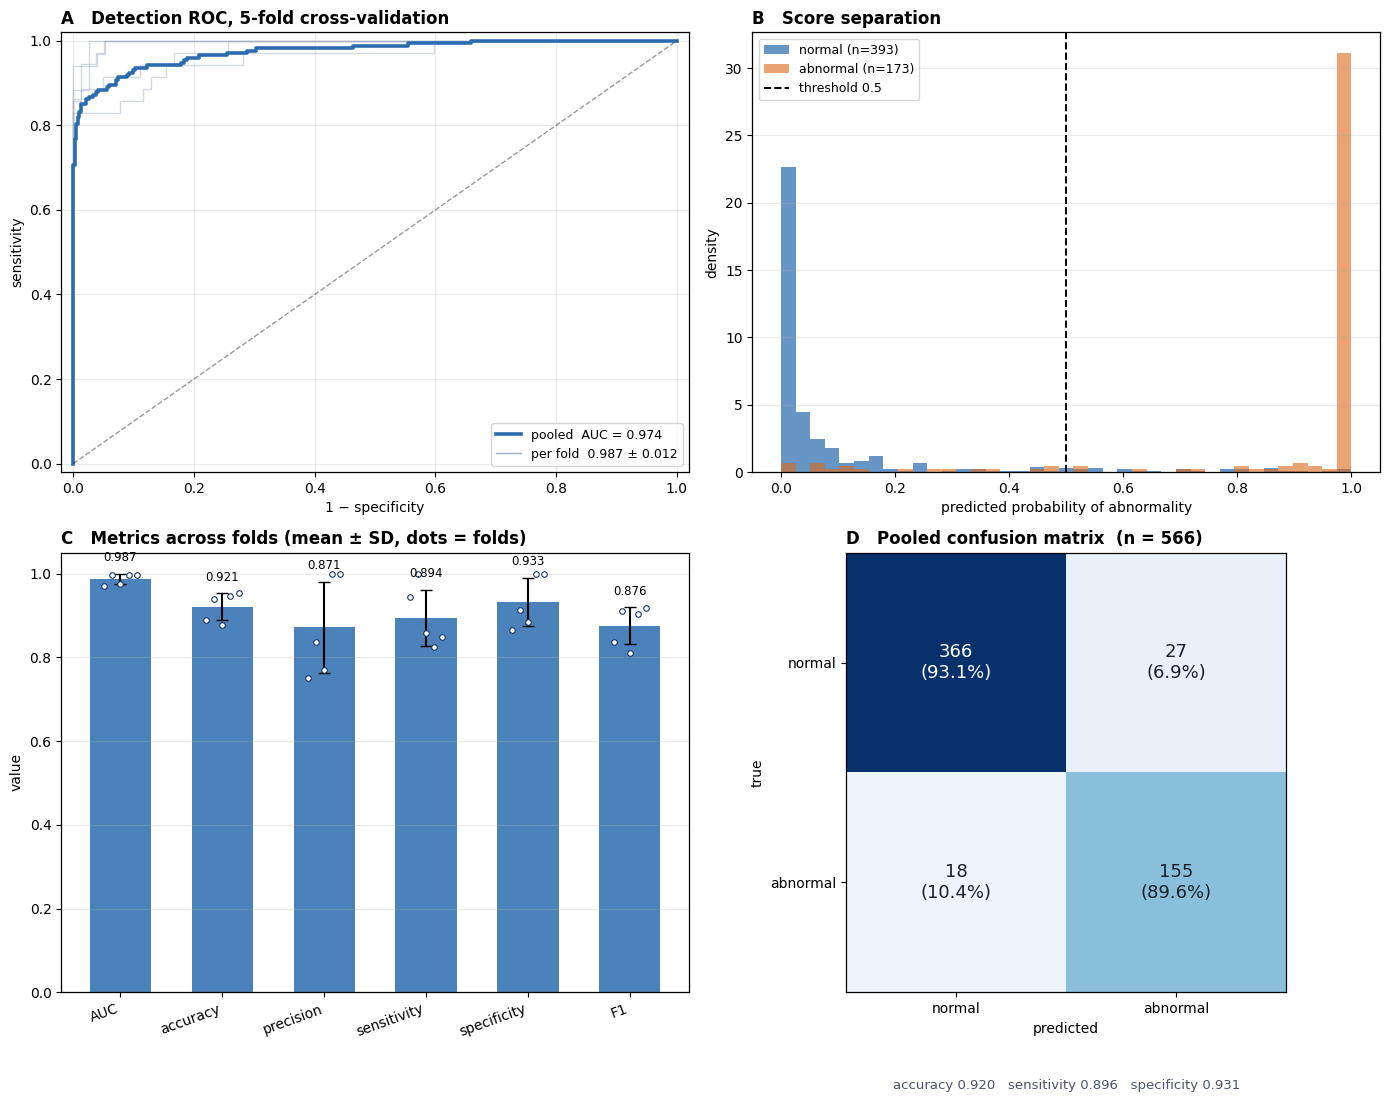

saved fig1_detection.png


In [90]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, confusion_matrix
from collections import Counter

plt.rcParams.update({'font.size': 10, 'axes.linewidth': 0.9,
                     'font.family': 'DejaVu Sans'})
BLUE, ORANGE, GREY = '#2b6cb0', '#dd6b20', '#a0aec0'

det = cv['B']                      # last-4 blocks, 5-fold

def wilson(k, n, z=1.96):
    if n == 0: return (0, 0)
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n))/d
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0, c-h), min(1, c+h)

P = np.concatenate([r['pt'] for r in det])
Y = np.concatenate([r['yt'] for r in det])

fig = plt.figure(figsize=(14, 11))

# ---- A. ROC per fold + pooled ----
ax = fig.add_subplot(2, 2, 1)
for r in det:
    fpr, tpr, _ = roc_curve(r['yt'], r['pt'])
    ax.plot(fpr, tpr, lw=1, alpha=0.45, color=GREY)
fpr, tpr, _ = roc_curve(Y, P)
ax.plot(fpr, tpr, lw=2.6, color=BLUE,
        label=f"pooled  AUC = {auc(fpr,tpr):.3f}")
aucs = [r['m05']['auc'] for r in det]
ax.plot([], [], color=GREY, lw=1, label=f"per fold  {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")
ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.4)
ax.set_xlabel('1 − specificity'); ax.set_ylabel('sensitivity')
ax.set_title('A   Detection ROC, 5-fold cross-validation', loc='left', fontweight='bold')
ax.legend(loc='lower right', fontsize=9); ax.grid(alpha=0.25)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)

# ---- B. score distribution ----
ax = fig.add_subplot(2, 2, 2)
bins = np.linspace(0, 1, 40)
ax.hist(P[Y==0], bins=bins, alpha=0.72, color=BLUE, density=True,
        label=f'normal (n={int((Y==0).sum())})')
ax.hist(P[Y==1], bins=bins, alpha=0.62, color=ORANGE, density=True,
        label=f'abnormal (n={int((Y==1).sum())})')
ax.axvline(0.5, ls='--', c='black', lw=1.4, label='threshold 0.5')
ax.set_xlabel('predicted probability of abnormality'); ax.set_ylabel('density')
ax.set_title('B   Score separation', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.25, axis='y')

# ---- C. per-fold metrics ----
ax = fig.add_subplot(2, 2, 3)
keys = ['auc','acc','prec','sens','spec','f1']
lbl  = ['AUC','accuracy','precision','sensitivity','specificity','F1']
vals = np.array([[r['m05'][k] for k in keys] for r in det])
x = np.arange(len(keys))
ax.bar(x, vals.mean(0), yerr=vals.std(0), capsize=4, color=BLUE, alpha=0.85, width=0.6)
for i in range(len(keys)):
    ax.scatter(np.full(len(det), x[i]) + np.linspace(-0.16, 0.16, len(det)), vals[:, i],
               s=16, color='white', edgecolor='#1a365d', zorder=3, linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(lbl, rotation=20, ha='right')
ax.set_ylim(0, 1.05); ax.set_ylabel('value')
ax.set_title('C   Metrics across folds (mean ± SD, dots = folds)', loc='left', fontweight='bold')
ax.grid(alpha=0.25, axis='y')
for i, v in enumerate(vals.mean(0)):
    ax.text(x[i], v + vals.std(0)[i] + 0.03, f'{v:.3f}', ha='center', fontsize=8.5)

# ---- D. confusion matrix ----
ax = fig.add_subplot(2, 2, 4)
cm = confusion_matrix(Y, (P > 0.5).astype(int))
im = ax.imshow(cm, cmap='Blues', vmin=0)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i,j]}\n({cm[i,j]/cm[i].sum()*100:.1f}%)',
                ha='center', va='center', fontsize=13,
                color='white' if cm[i,j] > cm.max()*0.55 else '#1a202c')
ax.set_xticks([0,1]); ax.set_xticklabels(['normal','abnormal'])
ax.set_yticks([0,1]); ax.set_yticklabels(['normal','abnormal'])
ax.set_xlabel('predicted'); ax.set_ylabel('true')
mp = dict(acc=(cm[0,0]+cm[1,1])/cm.sum(),
          sens=cm[1,1]/cm[1].sum(), spec=cm[0,0]/cm[0].sum())
ax.set_title(f"D   Pooled confusion matrix  (n = {cm.sum()})",
             loc='left', fontweight='bold')
ax.text(0.5, -0.22, f"accuracy {mp['acc']:.3f}   sensitivity {mp['sens']:.3f}   "
        f"specificity {mp['spec']:.3f}", transform=ax.transAxes,
        ha='center', fontsize=9.5, color='#4a5568')

plt.tight_layout()
plt.savefig('/kaggle/working/fig1_detection.png', dpi=300, bbox_inches='tight')
plt.show()
print("saved fig1_detection.png")

In [92]:
import numpy as np
from collections import Counter

# rebuild the 39-class fold map and make it active
def gene_folds(n_splits=5, seed=42):
    rng = np.random.RandomState(seed)
    f_of = {}
    for g in gene_list:
        ps = sorted([p for p in uniq_pat if pat_gene[p] == g])
        rng.shuffle(ps)
        start = rng.randint(n_splits)
        for k, p in enumerate(ps): f_of[p] = (start + k) % n_splits
    return f_of

fp = gene_folds()
print(f"fold map: {len(fp)} patients")

gene_cv['39'] = run_gene_cv('39cls', len(gene_list), y_gene, gene_idx, g_pat,
                            gene_list, unfreeze=4, epochs=15, bs=8)

fold map: 88 patients
GENOTYPE  --  39 classes  --  39cls  --  5-FOLD
fold  tr_img  te_img  te_pat  ep   top1   top3   time
   0     122      30      15  10  0.200  0.267    59s
   1     117      34      17   3  0.176  0.235    30s
   2     127      24      12   6  0.250  0.500    44s
   3     108      45      23   7  0.043  0.087    42s
   4     113      40      21   5  0.048  0.190    38s
----------------------------------------------------------------------------
POOLED (88 patients):  top-1 12.5%  top-3 22.7%  top-5 27.3%
  baseline (always ABCA4) 23.9%  |  chance 2.6%

--- per class ---
  ABCA4        11/21
  RPE65        0/6
  EYS          0/4
  USH2A        0/4
  PRPF8        0/3
  RP1          0/3
  CERKL        0/3
  CDHR1        0/3
  PROM1        0/2
  CDH23        0/2
  IFT172       0/2
  CRB1         0/2
  RPGR         0/2
  RP2          0/2
  PRPH2        0/2
  RDH12        0/2
  CRX          0/2
  TULP1        0/2
  BBS12        0/1
  LCA5         0/1
  MKKS         0/1


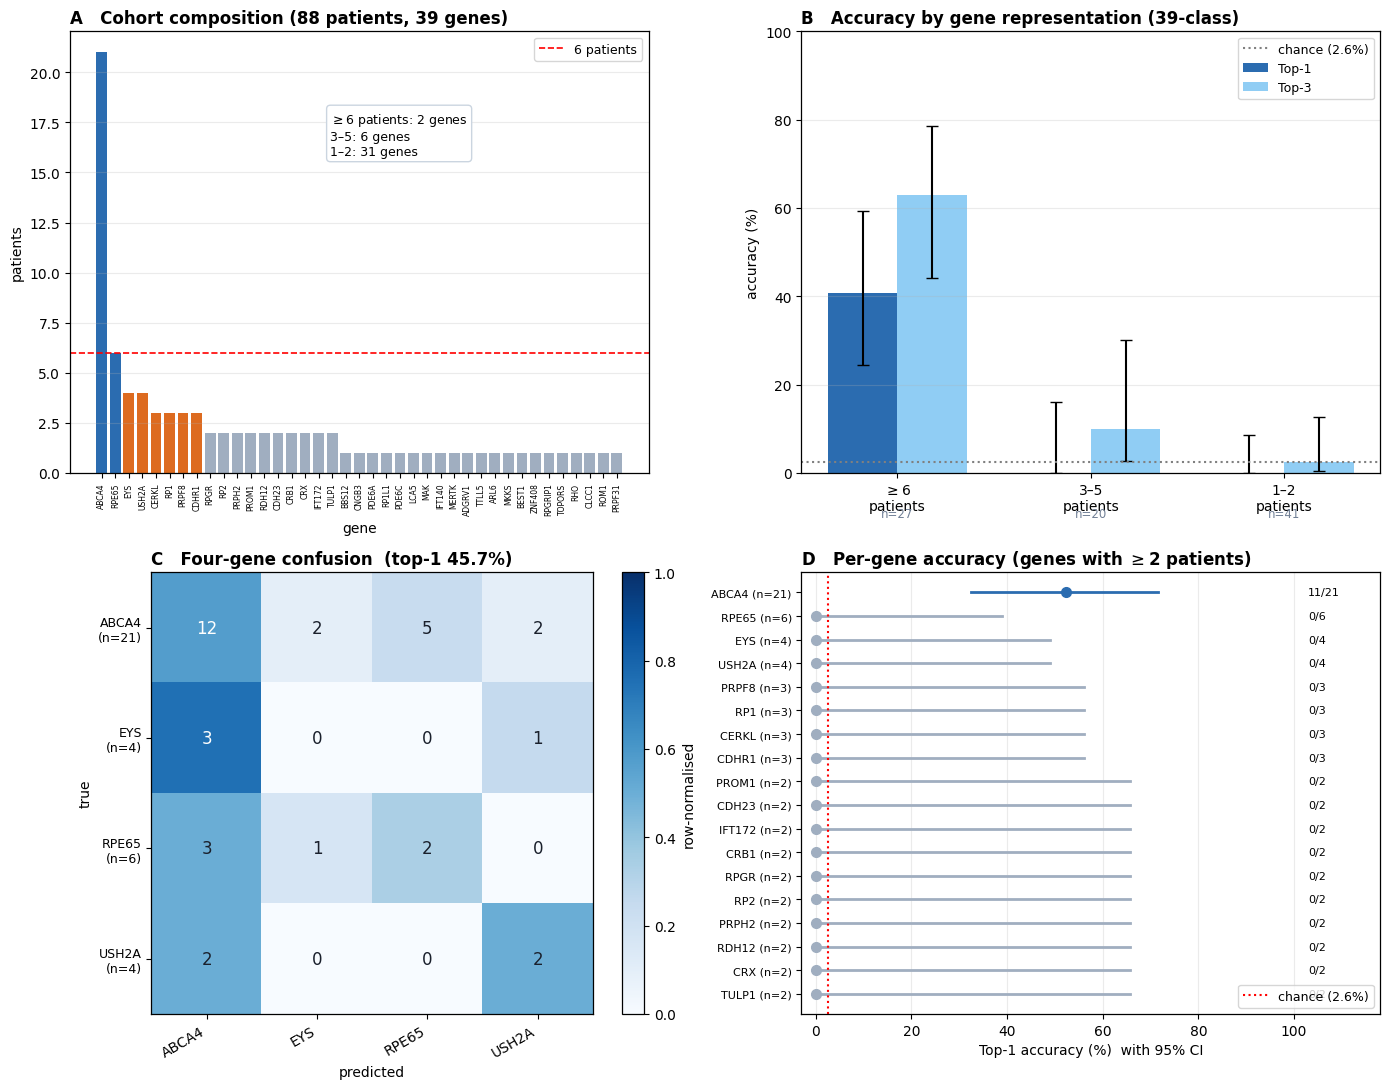

saved fig2_genotype.png


In [93]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from collections import Counter

BLUE, ORANGE, GREY = '#2b6cb0', '#dd6b20', '#a0aec0'

def wilson(k, n, z=1.96):
    if n == 0: return (0, 0)
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n))/d
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0, c-h), min(1, c+h)

g39 = sorted(gene_cv['39'], key=lambda r: r['fold'])
g4  = sorted(gene_cv['4'],  key=lambda r: r['fold'])
rows39 = [x for r in g39 for x in r['rows']]
rows4  = [x for r in g4  for x in r['rows']]
rk39 = np.array([x[3] for x in rows39])
rk4  = np.array([x[3] for x in rows4])

fig = plt.figure(figsize=(14, 11))

# ---- A. cohort composition ----
ax = fig.add_subplot(2, 2, 1)
gs = sorted(gcount.items(), key=lambda x: -x[1])
gnames = [g for g,_ in gs]; cnts = [c for _,c in gs]
cols = [BLUE if c >= 6 else (ORANGE if c >= 3 else GREY) for c in cnts]
ax.bar(range(len(gnames)), cnts, color=cols)
ax.axhline(6, ls='--', c='red', lw=1.2, label='6 patients')
ax.set_xticks(range(len(gnames)))
ax.set_xticklabels(gnames, rotation=90, fontsize=5.5)
ax.set_ylabel('patients'); ax.set_xlabel('gene')
ax.set_title(f'A   Cohort composition ({len(uniq_pat)} patients, {len(gene_list)} genes)',
             loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.25, axis='y')
n6  = sum(1 for c in cnts if c >= 6)
n35 = sum(1 for c in cnts if 3 <= c <= 5)
n12 = sum(1 for c in cnts if c <= 2)
ax.text(0.45, 0.72, f"$\\geq$6 patients: {n6} genes\n3–5: {n35} genes\n1–2: {n12} genes",
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle='round', fc='white', ec='#cbd5e0'))

# ---- B. stratified accuracy, 39-class ----
ax = fig.add_subplot(2, 2, 2)
grp, t1, t3, ns = [], [], [], []
for lo, hi, nm in [(6,99,'$\\geq$6\npatients'), (3,5,'3–5\npatients'), (1,2,'1–2\npatients')]:
    sel = [x for x in rows39 if lo <= gcount[gene_list[x[1]]] <= hi]
    r_ = np.array([x[3] for x in sel])
    grp.append(nm); t1.append((r_==0).mean()*100); t3.append((r_<3).mean()*100); ns.append(len(sel))
x = np.arange(3); w = 0.36
e1 = [[t1[i]-wilson(int(round(t1[i]/100*ns[i])), ns[i])[0]*100 for i in range(3)],
      [wilson(int(round(t1[i]/100*ns[i])), ns[i])[1]*100-t1[i] for i in range(3)]]
e3 = [[t3[i]-wilson(int(round(t3[i]/100*ns[i])), ns[i])[0]*100 for i in range(3)],
      [wilson(int(round(t3[i]/100*ns[i])), ns[i])[1]*100-t3[i] for i in range(3)]]
ax.bar(x-w/2, t1, w, yerr=e1, capsize=4, label='Top-1', color=BLUE)
ax.bar(x+w/2, t3, w, yerr=e3, capsize=4, label='Top-3', color='#90cdf4')
ax.axhline(100/len(gene_list), ls=':', c='grey',
           label=f'chance ({100/len(gene_list):.1f}%)')
ax.set_xticks(x); ax.set_xticklabels(grp); ax.set_ylabel('accuracy (%)')
ax.set_ylim(0, 100)
ax.set_title('B   Accuracy by gene representation (39-class)',
             loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.25, axis='y')
for i, n_ in enumerate(ns):
    ax.text(x[i], -10, f'n={n_}', ha='center', fontsize=8.5, color='#718096')

# ---- C. 4-class confusion ----
ax = fig.add_subplot(2, 2, 3)
yt = np.array([x[1] for x in rows4]); yh = np.array([x[2] for x in rows4])
cm = confusion_matrix(yt, yh, labels=range(len(cls4)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(len(cls4)):
    for j in range(len(cls4)):
        ax.text(j, i, f'{cm[i,j]}', ha='center', va='center', fontsize=12,
                color='white' if cmn[i,j] > 0.55 else '#1a202c')
ax.set_xticks(range(len(cls4))); ax.set_xticklabels(cls4, rotation=30, ha='right')
ax.set_yticks(range(len(cls4)))
ax.set_yticklabels([f'{c}\n(n={gcount4[c]})' for c in cls4], fontsize=9)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title(f'C   Four-gene confusion  (top-1 {(rk4==0).mean()*100:.1f}%)',
             loc='left', fontweight='bold')
plt.colorbar(im, ax=ax, fraction=0.046, label='row-normalised')

# ---- D. per-gene, well-represented only ----
ax = fig.add_subplot(2, 2, 4)
pg = {}
for p, t, pr, r_ in rows39:
    c = gene_list[t]; pg.setdefault(c, [0,0]); pg[c][1]+=1; pg[c][0]+=(r_==0)
show = [(c, pg[c][0], pg[c][1]) for c in sorted(pg, key=lambda x: -pg[x][1]) if pg[c][1] >= 2]
yp_ = np.arange(len(show))[::-1]
for i, (c, a, b) in enumerate(show):
    acc = a/b*100; lo, hi = wilson(a, b)
    col = BLUE if acc > 0 else GREY
    ax.plot([lo*100, hi*100], [yp_[i]]*2, color=col, lw=2)
    ax.plot(acc, yp_[i], 'o', color=col, ms=7)
    ax.text(103, yp_[i], f'{a}/{b}', va='center', fontsize=8)
ax.axvline(100/len(gene_list), ls=':', c='red',
           label=f'chance ({100/len(gene_list):.1f}%)')
ax.set_yticks(yp_); ax.set_yticklabels([f'{c} (n={b})' for c,_,b in show], fontsize=8)
ax.set_xlabel('Top-1 accuracy (%)  with 95% CI'); ax.set_xlim(-3, 118)
ax.set_title('D   Per-gene accuracy (genes with $\\geq$2 patients)',
             loc='left', fontweight='bold')
ax.legend(fontsize=9, loc='lower right'); ax.grid(alpha=0.25, axis='x')

plt.tight_layout()
plt.savefig('/kaggle/working/fig2_genotype.png', dpi=300, bbox_inches='tight')
plt.show()
print("saved fig2_genotype.png")


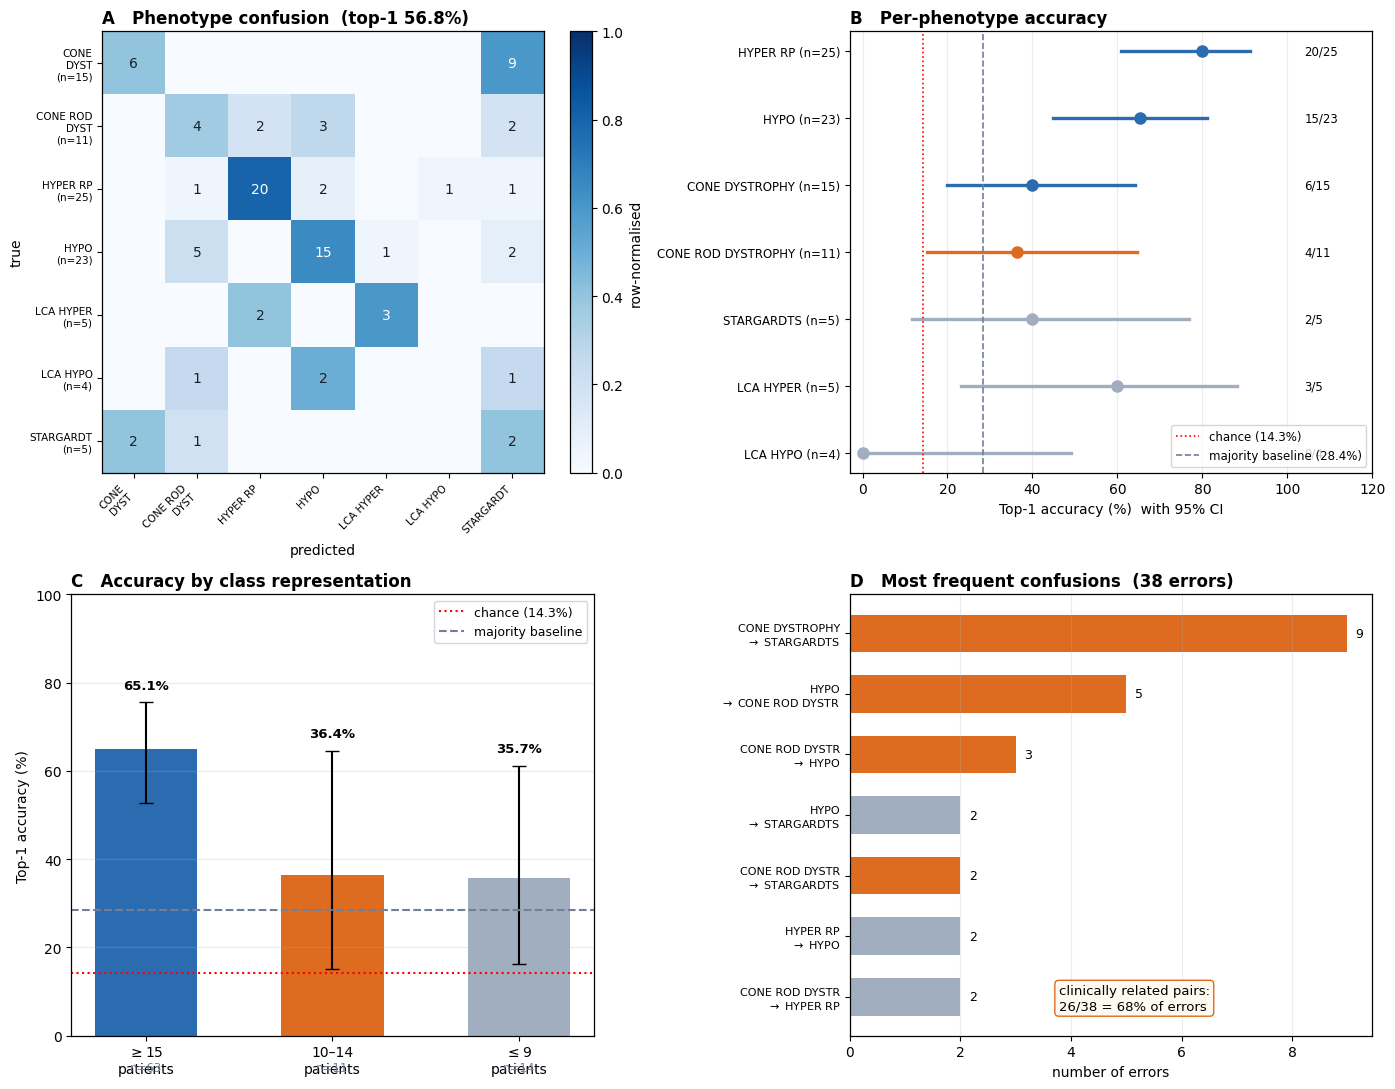

saved fig3_phenotype.png


In [94]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from collections import Counter

BLUE, ORANGE, GREY = '#2b6cb0', '#dd6b20', '#a0aec0'

def wilson(k, n, z=1.96):
    if n == 0: return (0, 0)
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n))/d
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0, c-h), min(1, c+h)

rowsp = [x for r in sorted(outph, key=lambda z: z['fold']) for x in r['rows']]
rkp   = np.array([x[3] for x in rowsp])
CHANCE_P = 100/len(ph_list_d)
BASE_P   = majp_d[1]/len(uniq_pat)*100

fig = plt.figure(figsize=(14, 11))

# ---- A. confusion matrix ----
ax = fig.add_subplot(2, 2, 1)
yt = np.array([x[1] for x in rowsp]); yh = np.array([x[2] for x in rowsp])
cm = confusion_matrix(yt, yh, labels=range(len(ph_list_d)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(len(ph_list_d)):
    for j in range(len(ph_list_d)):
        if cm[i,j]:
            ax.text(j, i, f'{cm[i,j]}', ha='center', va='center', fontsize=10,
                    color='white' if cmn[i,j] > 0.55 else '#1a202c')
sh = [c.replace(' DYSTROPHY','\nDYST').replace('STARGARDTS','STARGARDT') for c in ph_list_d]
ax.set_xticks(range(len(ph_list_d)))
ax.set_xticklabels(sh, rotation=45, ha='right', fontsize=7.5)
ax.set_yticks(range(len(ph_list_d)))
ax.set_yticklabels([f'{s}\n(n={phcount[c]})' for s, c in zip(sh, ph_list_d)], fontsize=7.5)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title(f'A   Phenotype confusion  (top-1 {(rkp==0).mean()*100:.1f}%)',
             loc='left', fontweight='bold')
plt.colorbar(im, ax=ax, fraction=0.046, label='row-normalised')

# ---- B. per-phenotype accuracy ----
ax = fig.add_subplot(2, 2, 2)
pg = {}
for p, t, pr, r_ in rowsp:
    c = ph_list_d[t]; pg.setdefault(c, [0,0]); pg[c][1]+=1; pg[c][0]+=(r_==0)
order = sorted(pg, key=lambda x: -pg[x][1])
ypos = np.arange(len(order))[::-1]
for i, c in enumerate(order):
    a, b = pg[c]; acc = a/b*100; lo, hi = wilson(a, b)
    col = BLUE if b >= 15 else (ORANGE if b >= 10 else GREY)
    ax.plot([lo*100, hi*100], [ypos[i]]*2, color=col, lw=2.4)
    ax.plot(acc, ypos[i], 'o', color=col, ms=8)
    ax.text(104, ypos[i], f'{a}/{b}', va='center', fontsize=8.5)
ax.axvline(CHANCE_P, ls=':', c='red', lw=1.2, label=f'chance ({CHANCE_P:.1f}%)')
ax.axvline(BASE_P, ls='--', c='#718096', lw=1.2, label=f'majority baseline ({BASE_P:.1f}%)')
ax.set_yticks(ypos)
ax.set_yticklabels([f'{c[:20]} (n={pg[c][1]})' for c in order], fontsize=8.5)
ax.set_xlabel('Top-1 accuracy (%)  with 95% CI'); ax.set_xlim(-3, 120)
ax.set_title('B   Per-phenotype accuracy', loc='left', fontweight='bold')
ax.legend(fontsize=8.5, loc='lower right'); ax.grid(alpha=0.25, axis='x')

# ---- C. stratified by class size ----
ax = fig.add_subplot(2, 2, 3)
G, A, N = [], [], []
for lo, hi, lab in [(15,99,'$\\geq$15\npatients'), (10,14,'10–14\npatients'), (1,9,'$\\leq$9\npatients')]:
    sel = [x for x in rowsp if lo <= phcount[ph_list_d[x[1]]] <= hi]
    if not sel: continue
    r_ = np.array([x[3] for x in sel])
    G.append(lab); A.append((r_==0).mean()*100); N.append(len(sel))
x = np.arange(len(G))
err = [[A[i]-wilson(int(round(A[i]/100*N[i])), N[i])[0]*100 for i in range(len(G))],
       [wilson(int(round(A[i]/100*N[i])), N[i])[1]*100-A[i] for i in range(len(G))]]
ax.bar(x, A, 0.55, yerr=err, capsize=5, color=[BLUE, ORANGE, GREY][:len(G)])
ax.axhline(CHANCE_P, ls=':', c='red', label=f'chance ({CHANCE_P:.1f}%)')
ax.axhline(BASE_P, ls='--', c='#718096', label='majority baseline')
ax.set_xticks(x); ax.set_xticklabels(G); ax.set_ylabel('Top-1 accuracy (%)')
ax.set_ylim(0, 100)
ax.set_title('C   Accuracy by class representation', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.25, axis='y')
for i, (a_, n_) in enumerate(zip(A, N)):
    ax.text(x[i], a_+err[1][i]+3, f'{a_:.1f}%', ha='center', fontsize=9.5, fontweight='bold')
    ax.text(x[i], -8, f'n={n_}', ha='center', fontsize=8.5, color='#718096')

# ---- D. error structure ----
ax = fig.add_subplot(2, 2, 4)
conf = Counter((ph_list_d[x[1]], ph_list_d[x[2]]) for x in rowsp if x[3] != 0)
tot = sum(conf.values()); top = conf.most_common(7)
lbl = [f'{t[:14]}\n$\\rightarrow$ {p[:14]}' for (t, p), _ in top]
val = [c for _, c in top]
REL = {('HYPO','CONE ROD DYSTROPHY'), ('CONE ROD DYSTROPHY','HYPO'),
       ('LCA HYPER','HYPER RP'), ('HYPER RP','LCA HYPER'),
       ('LCA HYPO','HYPO'), ('HYPO','LCA HYPO'),
       ('STARGARDTS','CONE DYSTROPHY'), ('CONE DYSTROPHY','STARGARDTS'),
       ('STARGARDTS','CONE ROD DYSTROPHY'), ('CONE ROD DYSTROPHY','STARGARDTS'),
       ('CONE DYSTROPHY','CONE ROD DYSTROPHY'), ('CONE ROD DYSTROPHY','CONE DYSTROPHY')}
cols = [ORANGE if k in REL else GREY for k, _ in top]
ypos = np.arange(len(lbl))[::-1]
ax.barh(ypos, val, color=cols, height=0.62)
ax.set_yticks(ypos); ax.set_yticklabels(lbl, fontsize=8)
ax.set_xlabel('number of errors')
rel = sum(c for k, c in conf.items() if k in REL)
ax.set_title(f'D   Most frequent confusions  ({tot} errors)', loc='left', fontweight='bold')
for i, v in enumerate(val):
    ax.text(v+0.15, ypos[i], str(v), va='center', fontsize=9)
ax.text(0.40, 0.06, f'clinically related pairs:\n{rel}/{tot} = {rel/tot*100:.0f}% of errors',
        transform=ax.transAxes, fontsize=9.5,
        bbox=dict(boxstyle='round', fc='#fffaf0', ec=ORANGE))
ax.grid(alpha=0.25, axis='x')

plt.tight_layout()
plt.savefig('/kaggle/working/fig3_phenotype.png', dpi=300, bbox_inches='tight')
plt.show()
print("saved fig3_phenotype.png")

  ep  1  tr 0.5995  va 0.2732  va_auc 0.968  te_auc 0.962
  ep  2  tr 0.2441  va 0.2128  va_auc 0.979  te_auc 0.970
  ep  3  tr 0.1056  va 0.2752  va_auc 0.986  te_auc 0.970
  ep  4  tr 0.1219  va 0.1850  va_auc 0.993  te_auc 0.976
  ep  5  tr 0.0608  va 0.0761  va_auc 0.997  te_auc 0.985
  ep  6  tr 0.0473  va 0.1349  va_auc 0.999  te_auc 0.991
  ep  7  tr 0.0057  va 0.0275  va_auc 1.000  te_auc 0.993
  ep  8  tr 0.0034  va 0.0775  va_auc 0.999  te_auc 0.993
  ep  9  tr 0.0027  va 0.0755  va_auc 0.998  te_auc 0.992
  ep 10  tr 0.0026  va 0.0462  va_auc 1.000  te_auc 0.992
  ep 11  tr 0.0011  va 0.0361  va_auc 1.000  te_auc 0.992
  ep 12  tr 0.0030  va 0.0350  va_auc 1.000  te_auc 0.992
done (185s), best epoch 7


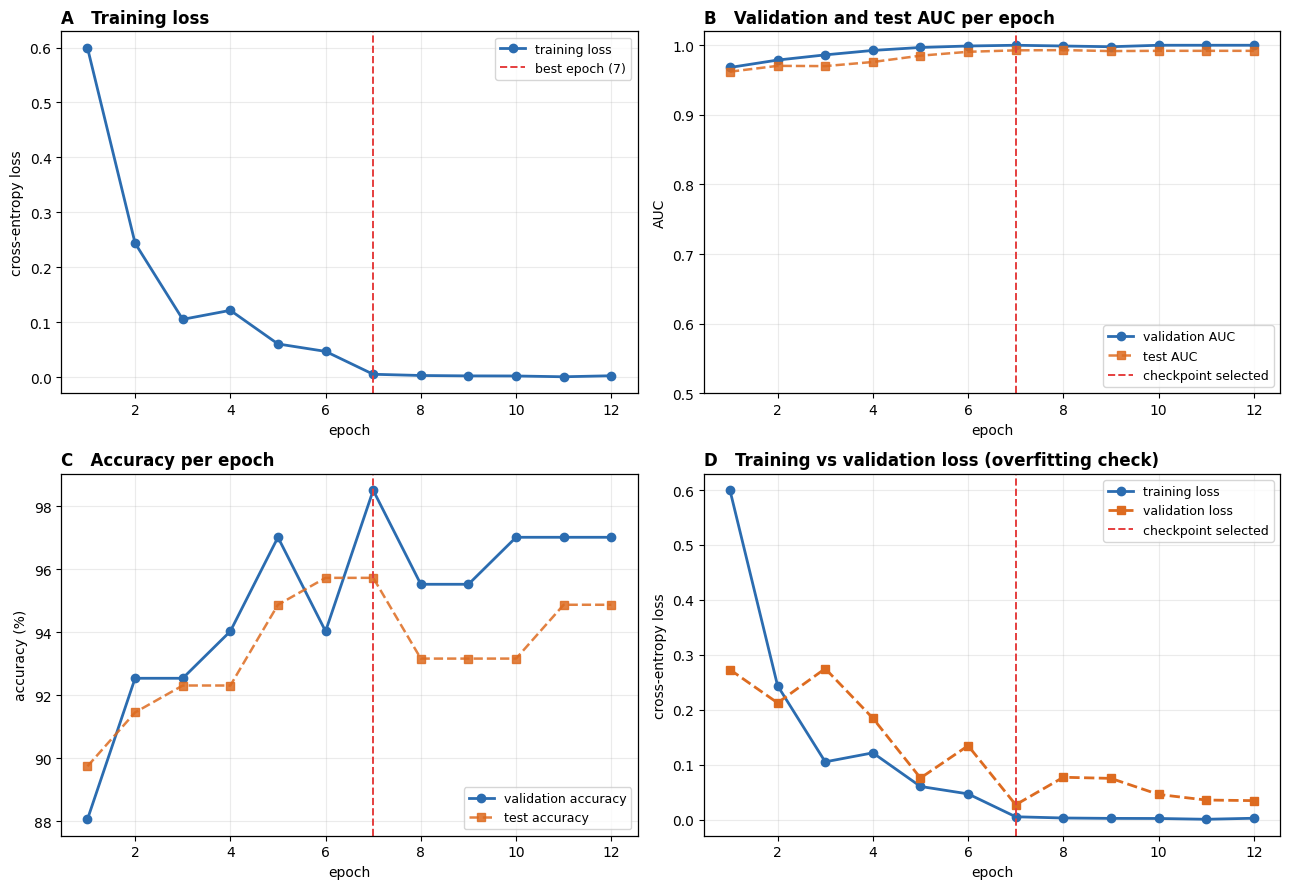

saved fig5_training.png


In [95]:
import numpy as np, matplotlib.pyplot as plt, time, torch, torch.nn as nn, copy
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score

BLUE, ORANGE, GREY = '#2b6cb0', '#dd6b20', '#a0aec0'

def run_fold_hist(f, unfreeze=4, lr_head=1e-3, lr_bb=1e-5, epochs=12, bs=8,
                  patience=99, wd=0.05, seed=0):
    torch.manual_seed(seed+f); np.random.seed(seed+f)
    te_i = np.where(fold == f)[0]
    rest = np.where(fold != f)[0]

    rng = np.random.RandomState(seed+f)
    rest_pats = sorted(set(patient[i] for i in rest if labels[i]==1))
    rng.shuffle(rest_pats)
    n_val_p = max(1, int(round(0.15*len(rest_pats))))
    val_pats = set(rest_pats[:n_val_p])
    rest_norm = [i for i in rest if labels[i]==0]; rng.shuffle(rest_norm)
    val_norm = set(rest_norm[:int(round(0.15*len(rest_norm)))])
    va_i = np.array([i for i in rest if (labels[i]==1 and patient[i] in val_pats)
                                      or (labels[i]==0 and i in val_norm)])
    tr_i = np.array([i for i in rest if i not in set(va_i)])

    cw = len(tr_i)/(2*np.bincount(y_all[tr_i], minlength=2))
    tr_ld = DataLoader(RetinaDS(tr_i, y_all[tr_i], train=True), batch_size=bs,
                       shuffle=True, num_workers=2, drop_last=True)
    va_ld = DataLoader(RetinaDS(va_i, y_all[va_i]), batch_size=bs, num_workers=2)
    te_ld = DataLoader(RetinaDS(te_i, y_all[te_i]), batch_size=bs, num_workers=2)

    model = DinoClassifier(unfreeze_blocks=unfreeze).to(device)
    bb = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{'params': model.head.parameters(), 'lr': lr_head}]
    if bb: groups.append({'params': bb, 'lr': lr_bb})
    opt = torch.optim.AdamW(groups, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32).to(device))
    scaler = torch.amp.GradScaler('cuda')

    @torch.no_grad()
    def ev(loader):
        model.eval(); P, Y, L, nb = [], [], 0.0, 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            L += nn.functional.cross_entropy(logits, y).item(); nb += 1
            P.append(torch.softmax(logits,1)[:,1].cpu().numpy()); Y.append(y.cpu().numpy())
        P, Y = np.concatenate(P), np.concatenate(Y)
        return P, Y, L/nb

    hist, best = [], {'auc': -1, 'ep': 0}
    for ep in range(1, epochs+1):
        model.train(); tl, nb = 0.0, 0
        for x, y in tr_ld:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.amp.autocast('cuda'): loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item(); nb += 1
        sched.step()
        pv, yv, vl = ev(va_ld); pt, yt, tel = ev(te_ld)
        hist.append(dict(ep=ep, tr_loss=tl/nb, va_loss=vl, te_loss=tel,
                         va_auc=roc_auc_score(yv,pv), te_auc=roc_auc_score(yt,pt),
                         va_acc=accuracy_score(yv,(pv>0.5).astype(int)),
                         te_acc=accuracy_score(yt,(pt>0.5).astype(int))))
        if hist[-1]['va_auc'] > best['auc']:
            best = {'auc': hist[-1]['va_auc'], 'ep': ep}
        print(f"  ep {ep:2d}  tr {tl/nb:.4f}  va {vl:.4f}  va_auc {hist[-1]['va_auc']:.3f}  "
              f"te_auc {hist[-1]['te_auc']:.3f}")
    del model; torch.cuda.empty_cache()
    return dict(hist=hist, best_ep=best['ep'])

t0 = time.time()
r_hist = run_fold_hist(0, unfreeze=4, lr_head=1e-3, lr_bb=1e-5, epochs=12, bs=8)
print(f"done ({time.time()-t0:.0f}s), best epoch {r_hist['best_ep']}")

h  = r_hist['hist']; ep = [d['ep'] for d in h]; be = r_hist['best_ep']

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# A. training loss
ax[0,0].plot(ep, [d['tr_loss'] for d in h], 'o-', color=BLUE, lw=2, label='training loss')
ax[0,0].axvline(be, ls='--', c='#e53e3e', lw=1.4, label=f'best epoch ({be})')
ax[0,0].set_xlabel('epoch'); ax[0,0].set_ylabel('cross-entropy loss')
ax[0,0].set_title('A   Training loss', loc='left', fontweight='bold')
ax[0,0].legend(fontsize=9); ax[0,0].grid(alpha=0.25)

# B. AUC
ax[0,1].plot(ep, [d['va_auc'] for d in h], 'o-', color=BLUE, lw=2, label='validation AUC')
ax[0,1].plot(ep, [d['te_auc'] for d in h], 's--', color=ORANGE, lw=1.8, alpha=0.85, label='test AUC')
ax[0,1].axvline(be, ls='--', c='#e53e3e', lw=1.4, label='checkpoint selected')
ax[0,1].set_xlabel('epoch'); ax[0,1].set_ylabel('AUC')
ax[0,1].set_title('B   Validation and test AUC per epoch', loc='left', fontweight='bold')
ax[0,1].legend(fontsize=9, loc='lower right'); ax[0,1].grid(alpha=0.25)
ax[0,1].set_ylim(0.5, 1.02)

# C. accuracy
ax[1,0].plot(ep, [d['va_acc']*100 for d in h], 'o-', color=BLUE, lw=2, label='validation accuracy')
ax[1,0].plot(ep, [d['te_acc']*100 for d in h], 's--', color=ORANGE, lw=1.8, alpha=0.85, label='test accuracy')
ax[1,0].axvline(be, ls='--', c='#e53e3e', lw=1.4)
ax[1,0].set_xlabel('epoch'); ax[1,0].set_ylabel('accuracy (%)')
ax[1,0].set_title('C   Accuracy per epoch', loc='left', fontweight='bold')
ax[1,0].legend(fontsize=9, loc='lower right'); ax[1,0].grid(alpha=0.25)

# D. train vs val loss
ax[1,1].plot(ep, [d['tr_loss'] for d in h], 'o-', color=BLUE, lw=2, label='training loss')
ax[1,1].plot(ep, [d['va_loss'] for d in h], 's--', color=ORANGE, lw=2, label='validation loss')
ax[1,1].axvline(be, ls='--', c='#e53e3e', lw=1.4, label='checkpoint selected')
ax[1,1].set_xlabel('epoch'); ax[1,1].set_ylabel('cross-entropy loss')
ax[1,1].set_title('D   Training vs validation loss (overfitting check)', loc='left', fontweight='bold')
ax[1,1].legend(fontsize=9); ax[1,1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig('/kaggle/working/fig5_training.png', dpi=300, bbox_inches='tight')
plt.show()
print("saved fig5_training.png")

In [41]:
import shutil, os
shutil.make_archive('/kaggle/working/all_results', 'zip', '/kaggle/working')
print(f"{os.path.getsize('/kaggle/working/all_results.zip')/1e6:.1f} MB")

1.8 MB


In [96]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from scipy.stats import binomtest
from sklearn.metrics import f1_score, cohen_kappa_score, balanced_accuracy_score

def wilson(k, n, z=1.96):
    if n == 0: return (0,0)
    p = k/n; d = 1+z*z/n
    c = (p+z*z/(2*n))/d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0,c-h), min(1,c+h)

def boot_auc_ci(y, s, n_boot=2000, seed=0):
    from sklearn.metrics import roc_auc_score
    rng = np.random.RandomState(seed); n = len(y); a = []
    for _ in range(n_boot):
        i = rng.randint(0, n, n)
        if len(set(y[i])) < 2: continue
        a.append(roc_auc_score(y[i], s[i]))
    return np.percentile(a, [2.5, 97.5])

def perm_auc(y, s, n_perm=5000, seed=0):
    from sklearn.metrics import roc_auc_score
    rng = np.random.RandomState(seed)
    obs = roc_auc_score(y, s)
    null = np.array([roc_auc_score(rng.permutation(y), s) for _ in range(n_perm)])
    return obs, (np.sum(null >= obs)+1)/(n_perm+1)

def clf_stats(rows, cls_names, cnt_map, tag, n_cls, topk=(1,3)):
    rk = np.array([x[3] for x in rows]); n = len(rk)
    truth = np.array([x[1] for x in rows]); pred = np.array([x[2] for x in rows])
    rng = np.random.RandomState(0)
    print(f"\n{'='*70}\n{tag}\n{'='*70}")
    for k in topk:
        c = int((rk < k).sum()); lo, hi = wilson(c, n)
        print(f"  Top-{k}: {c/n*100:5.1f}%  95% CI [{lo*100:.1f}, {hi*100:.1f}]  ({c}/{n})")

    maj_c, maj_n = Counter(cls_names[t] for t in truth).most_common(1)[0]
    print(f"  Baseline (always {maj_c}) {maj_n/n*100:.1f}%  |  chance {100/n_cls:.1f}%")

    obs = np.mean(truth == pred)
    null = np.array([np.mean(rng.permutation(truth) == pred) for _ in range(10000)])
    pv = (np.sum(null >= obs)+1)/10001
    print(f"\n  Permutation (10k): observed {obs*100:.1f}%  null {null.mean()*100:.1f}"
          f"±{null.std()*100:.1f}%  p {'<0.0001' if pv<1e-4 else f'={pv:.4f}'}")

    mok = rk == 0
    bok = np.array([cls_names[t] == maj_c for t in truth])
    b_, c_ = int((mok & ~bok).sum()), int((~mok & bok).sum())
    pmc = binomtest(b_, b_+c_, 0.5).pvalue if (b_+c_) else 1.
    print(f"  McNemar vs baseline: model-only {b_}, baseline-only {c_}, "
          f"p {'<0.0001' if pmc<1e-4 else f'={pmc:.4f}'}  "
          f"{'(significant)' if pmc<0.05 else '(ns)'}")

    print(f"\n  Macro F1 {f1_score(truth,pred,average='macro'):.3f}  |  "
          f"Balanced acc {balanced_accuracy_score(truth,pred)*100:.1f}%  |  "
          f"kappa {cohen_kappa_score(truth,pred):.3f}")

    print(f"\n  --- per class (Wilson CI, binomial vs chance) ---")
    pg = {}
    for p,t,pr,r in rows:
        c2 = cls_names[t]; pg.setdefault(c2,[0,0]); pg[c2][1]+=1; pg[c2][0]+=(r==0)
    pvals, keys = [], []
    for c2 in sorted(pg, key=lambda x: -pg[x][1]):
        a,b2 = pg[c2]
        if b2 < 2: continue
        lo,hi = wilson(a,b2)
        pb = binomtest(a, b2, 1/n_cls, alternative='greater').pvalue
        pvals.append(pb); keys.append(c2)
        print(f"  {c2:22s} {a:2d}/{b2:<3d} {a/b2*100:5.1f}%  "
              f"[{lo*100:5.1f},{hi*100:5.1f}]  p={pb:.4f}")
    if pvals:
        o = np.argsort(pvals); q = np.array(pvals,float); m_=len(pvals)
        for r_,i_ in enumerate(o): q[i_] = min(1., pvals[i_]*m_/(r_+1))
        print(f"\n  BH-corrected significant: {[k for k,qq in zip(keys,q) if qq<0.05]}")

# ---------- DETECTION ----------
det_ = cv['B']
P = np.concatenate([r['pt'] for r in det_]); Y = np.concatenate([r['yt'] for r in det_])
auc_, pv_ = perm_auc(Y, P); ci_ = boot_auc_ci(Y, P)
yh = (P > 0.5).astype(int)
from sklearn.metrics import confusion_matrix
tn,fp,fn,tp = confusion_matrix(Y, yh, labels=[0,1]).ravel()

print("="*70); print("DL DETECTION (variant B, 5-fold pooled)"); print("="*70)
print(f"  n = {len(Y)}  ({int((Y==0).sum())} normal, {int((Y==1).sum())} abnormal)")
print(f"  AUC {auc_:.3f}  95% CI [{ci_[0]:.3f}, {ci_[1]:.3f}]  "
      f"p {'<0.001' if pv_<0.001 else f'={pv_:.4f}'}")
for nm, k, n_ in [('accuracy', tn+tp, len(Y)), ('sensitivity', tp, tp+fn),
                  ('specificity', tn, tn+fp), ('precision', tp, tp+fp)]:
    lo, hi = wilson(k, n_)
    print(f"  {nm:12s} {k/n_*100:5.1f}%  95% CI [{lo*100:.1f}, {hi*100:.1f}]  ({k}/{n_})")
pmc = binomtest(int((yh[Y==1]==1).sum()), int((Y==1).sum()), 0.5).pvalue
print(f"  Confusion: TN {tn}  FP {fp}  FN {fn}  TP {tp}")

# ---------- PHENOTYPE ----------
rowsp_ = [x for r in sorted(outph, key=lambda z: z['fold']) for x in r['rows']]
clf_stats(rowsp_, ph_list_d, phcount, 'DL PHENOTYPE 7-class (5-fold)',
          len(ph_list_d), topk=(1,2))

# ---------- GENOTYPE 39 ----------
rows39_ = [x for r in sorted(gene_cv['39'], key=lambda z: z['fold']) for x in r['rows']]
clf_stats(rows39_, gene_list, gcount, 'DL GENOTYPE 39-class (5-fold)',
          len(gene_list), topk=(1,3,5))

# ---------- GENOTYPE 4 ----------
rows4_ = [x for r in sorted(gene_cv['4'], key=lambda z: z['fold']) for x in r['rows']]
clf_stats(rows4_, cls4, gcount4, 'DL GENOTYPE 4-class (5-fold)',
          len(cls4), topk=(1,2))

DL DETECTION (variant B, 5-fold pooled)
  n = 566  (393 normal, 173 abnormal)
  AUC 0.974  95% CI [0.960, 0.987]  p <0.001
  accuracy      92.0%  95% CI [89.5, 94.0]  (521/566)
  sensitivity   89.6%  95% CI [84.2, 93.3]  (155/173)
  specificity   93.1%  95% CI [90.2, 95.2]  (366/393)
  precision     85.2%  95% CI [79.3, 89.6]  (155/182)
  Confusion: TN 366  FP 27  FN 18  TP 155

DL PHENOTYPE 7-class (5-fold)
  Top-1:  56.8%  95% CI [46.4, 66.7]  (50/88)
  Top-2:  79.5%  95% CI [70.0, 86.7]  (70/88)
  Baseline (always HYPER RP) 28.4%  |  chance 14.3%

  Permutation (10k): observed 56.8%  null 19.0±4.0%  p <0.0001
  McNemar vs baseline: model-only 30, baseline-only 5, p <0.0001  (significant)

  Macro F1 0.457  |  Balanced acc 45.9%  |  kappa 0.467

  --- per class (Wilson CI, binomial vs chance) ---
  HYPER RP               20/25   80.0%  [ 60.9, 91.1]  p=0.0000
  HYPO                   15/23   65.2%  [ 44.9, 81.2]  p=0.0000
  CONE DYSTROPHY          6/15   40.0%  [ 19.8, 64.3]  p=0.013

Ashok_R.jpg | PRPH2 | HYPER RP


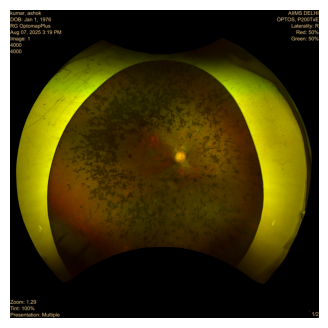

In [71]:
import numpy as np, matplotlib.pyplot as plt, cv2
i = int(np.where(labels == 1)[0][30])
print(names[i], "|", gene[i], "|", pheno[i])
img, om = preprocess(imgs[i])
plt.figure(figsize=(4,4)); plt.imshow(img); plt.axis('off'); plt.show()

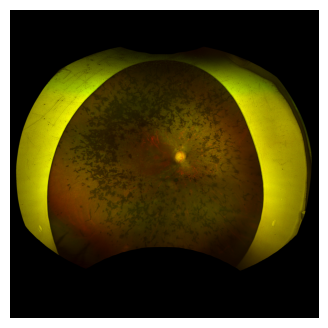

In [72]:
masked = img.copy(); masked[om == 0] = 0
plt.figure(figsize=(4,4)); plt.imshow(masked); plt.axis('off'); plt.show()

In [99]:
print("rows_ng top1:", round(sum(x[3]==0 for x in rows_ng)/len(rows_ng)*100,1), "n =", len(rows_ng))
print("rows_np top1:", round(sum(x[3]==0 for x in rows_np)/len(rows_np)*100,1), "n =", len(rows_np))

rows_ng top1: 21.6 n = 88
rows_np top1: 64.8 n = 88


In [103]:
import numpy as np
from scipy.stats import binomtest

rows_ng_dl = [x for r in sorted(gene_cv['39'], key=lambda z: z['fold']) for x in r['rows']]
rows_np_dl = [x for r in sorted(outph,        key=lambda z: z['fold']) for x in r['rows']]

def mcn(ml, dl, tag):
    a = {x[0]: x[3]==0 for x in ml}
    b = {x[0]: x[3]==0 for x in dl}
    com = sorted(set(a) & set(b))
    n01 = sum(1 for p in com if a[p] and not b[p])   # ML only
    n10 = sum(1 for p in com if b[p] and not a[p])   # DL only
    p = binomtest(n01, n01+n10, 0.5).pvalue if (n01+n10) else 1.0
    print(f"{tag:22s} ML {np.mean([a[p_] for p_ in com])*100:5.1f}%  "
          f"DL {np.mean([b[p_] for p_ in com])*100:5.1f}%  |  "
          f"ML-only {n01:2d}  DL-only {n10:2d}  p = {p:.4f}  "
          f"{'significant' if p < 0.05 else 'ns'}   (n={len(com)})")

print("="*84)
print("PAIRED COMPARISON — frozen-feature vs end-to-end (same patients, McNemar)")
print("="*84)
mcn(rows_np, rows_np_dl, 'Phenotype 7-class')
mcn(rows_ng, rows_ng_dl, 'Genotype 39-class')

PAIRED COMPARISON — frozen-feature vs end-to-end (same patients, McNemar)
Phenotype 7-class      ML  64.8%  DL  56.8%  |  ML-only 17  DL-only 10  p = 0.2478  ns   (n=88)
Genotype 39-class      ML  21.6%  DL  12.5%  |  ML-only 11  DL-only  3  p = 0.0574  ns   (n=88)


In [102]:
print(len(php), int(isaugp.sum()))

316 143


In [1]:
import os
print('oc in memory:', 'oc' in dir())
print([f for f in os.listdir('/kaggle/working') if 'detect' in f])

oc in memory: False
[]


In [14]:
for v in ['oc','rows_ng','gene_list','gcount','S','Y']:
    print(f"{v:12s} {'yes' if v in dir() else 'NO'}")

oc           yes
rows_ng      yes
gene_list    yes
gcount       yes
S            yes
Y            NO


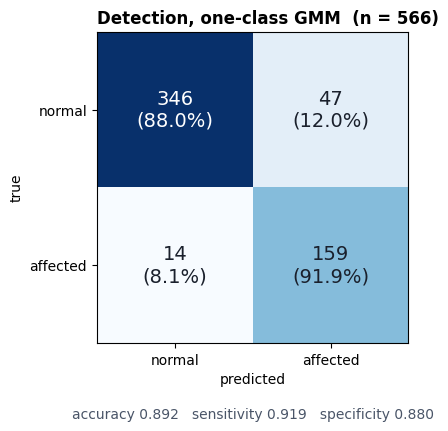

In [15]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

BLUE = '#2b6cb0'

# ---------- 1. detection confusion matrix ----------
S_ = np.concatenate([r['s'] for r in oc])
Y_ = np.concatenate([r['y'] for r in oc])
th = np.mean([r['th90'] for r in oc])
cm = confusion_matrix(Y_, (S_ > th).astype(int), labels=[0,1])

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i,j]}\n({cm[i,j]/cm[i].sum()*100:.1f}%)',
                ha='center', va='center', fontsize=14,
                color='white' if cm[i,j] > cm.max()*0.55 else '#1a202c')
ax.set_xticks([0,1]); ax.set_xticklabels(['normal','affected'])
ax.set_yticks([0,1]); ax.set_yticklabels(['normal','affected'])
ax.set_xlabel('predicted'); ax.set_ylabel('true')
acc = (cm[0,0]+cm[1,1])/cm.sum()
sens = cm[1,1]/cm[1].sum(); spec = cm[0,0]/cm[0].sum()
ax.set_title(f'Detection, one-class GMM  (n = {cm.sum()})',
             loc='left', fontweight='bold')
ax.text(0.5, -0.24, f'accuracy {acc:.3f}   sensitivity {sens:.3f}   '
        f'specificity {spec:.3f}', transform=ax.transAxes,
        ha='center', fontsize=10, color='#4a5568')
plt.tight_layout(); plt.show()

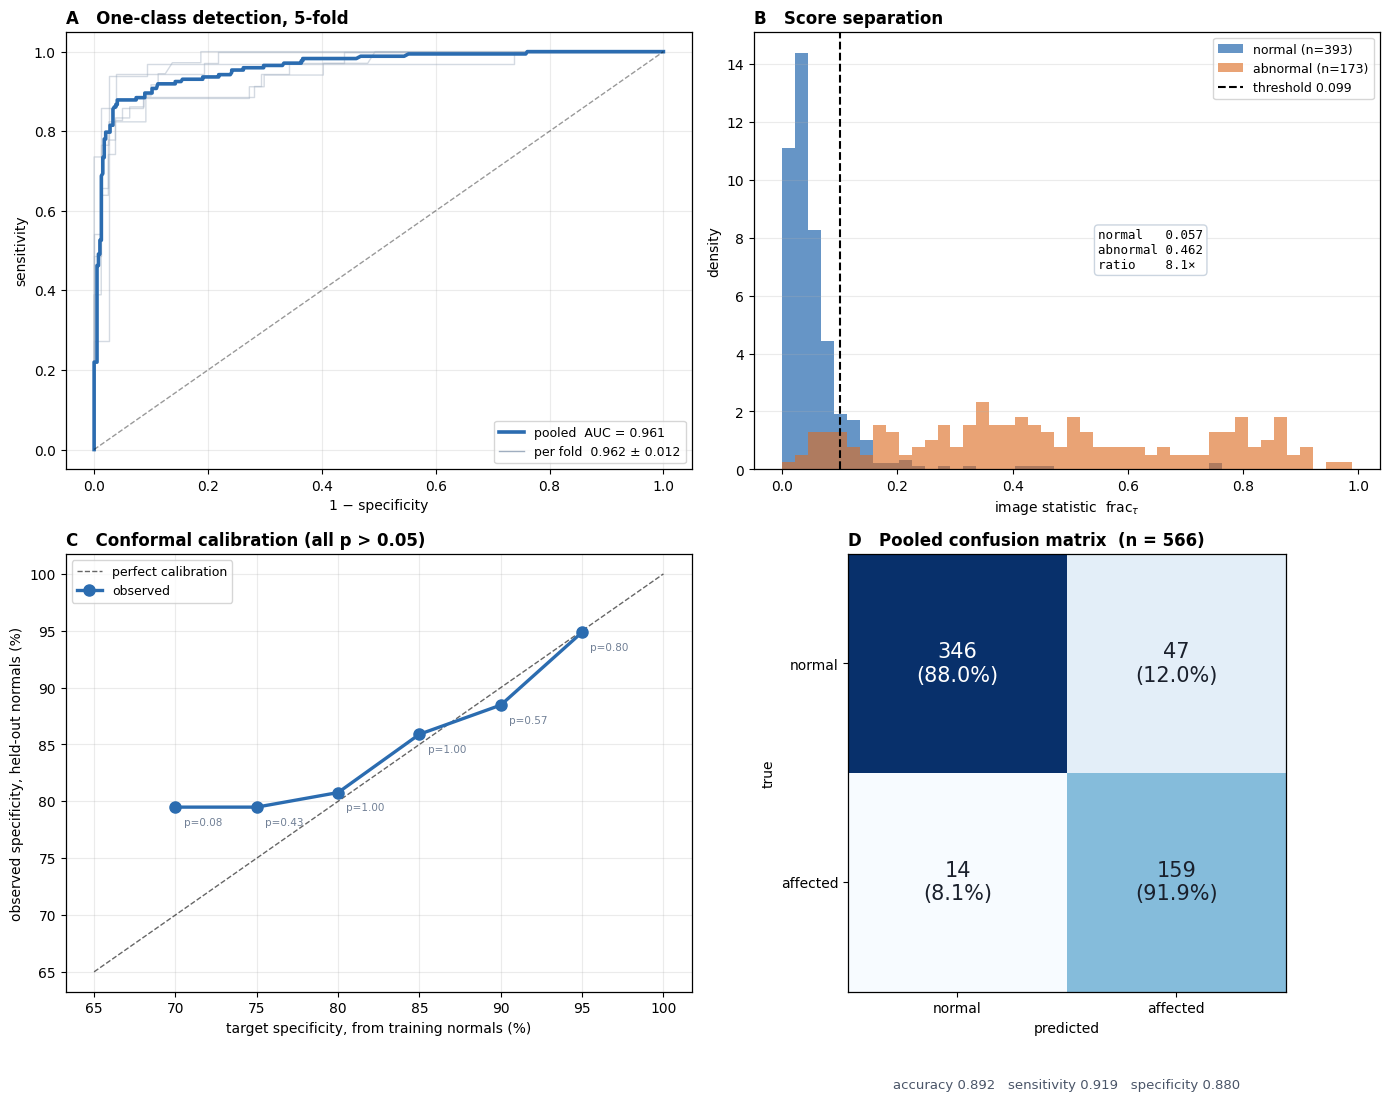

In [18]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc as sk_auc, confusion_matrix
from scipy.stats import binomtest

plt.rcParams.update({'font.size': 10, 'axes.linewidth': 0.9})
BLUE, ORANGE, GREY = '#2b6cb0', '#dd6b20', '#a0aec0'

S = np.concatenate([r['s'] for r in oc]); Y = np.concatenate([r['y'] for r in oc])
th = np.mean([r['th90'] for r in oc])

fig = plt.figure(figsize=(14, 11))

# A. ROC
ax = fig.add_subplot(2,2,1)
for r in oc:
    f_, t_, _ = roc_curve(r['y'], r['s']); ax.plot(f_, t_, lw=1, alpha=.45, color=GREY)
f_, t_, _ = roc_curve(Y, S)
ax.plot(f_, t_, lw=2.6, color=BLUE, label=f'pooled  AUC = {sk_auc(f_,t_):.3f}')
a_ = np.array([r['auc'] for r in oc])
ax.plot([], [], color=GREY, lw=1, label=f'per fold  {a_.mean():.3f} ± {a_.std():.3f}')
ax.plot([0,1],[0,1],'k--',lw=1,alpha=.4)
ax.set_xlabel('1 − specificity'); ax.set_ylabel('sensitivity')
ax.set_title('A   One-class detection, 5-fold', loc='left', fontweight='bold')
ax.legend(loc='lower right', fontsize=9); ax.grid(alpha=.25)

# B. score distributions
ax = fig.add_subplot(2,2,2)
b_ = np.linspace(0, max(S)*1.02, 45)
ax.hist(S[Y==0], bins=b_, alpha=.72, color=BLUE, density=True,
        label=f'normal (n={int((Y==0).sum())})')
ax.hist(S[Y==1], bins=b_, alpha=.62, color=ORANGE, density=True,
        label=f'abnormal (n={int((Y==1).sum())})')
ax.axvline(th, ls='--', c='black', lw=1.5, label=f'threshold {th:.3f}')
ax.set_xlabel(r'image statistic  frac$_\tau$'); ax.set_ylabel('density')
ax.set_title('B   Score separation', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=.25, axis='y')
ax.text(.55,.55, f'normal   {S[Y==0].mean():.3f}\nabnormal {S[Y==1].mean():.3f}\n'
        f'ratio    {S[Y==1].mean()/S[Y==0].mean():.1f}×',
        transform=ax.transAxes, family='monospace', fontsize=9, va='top',
        bbox=dict(boxstyle='round', fc='white', ec='#cbd5e0'))

# C. calibration
ax = fig.add_subplot(2,2,3)
cal_s = sg_d['cal_s']; te_s = sg_d['te_s']; te_y = sg_d['te_y']
tn_s = te_s[te_y==0]; n_tn = len(tn_s)
tg, ob, pvv = [], [], []
for t_ in [.70,.75,.80,.85,.90,.95]:
    thr = np.percentile(cal_s, t_*100); k = int((tn_s <= thr).sum())
    tg.append(t_*100); ob.append(k/n_tn*100); pvv.append(binomtest(k, n_tn, t_).pvalue)
ax.plot([65,100],[65,100],'k--',lw=1,alpha=.6,label='perfect calibration')
ax.plot(tg, ob, 'o-', lw=2.4, ms=8, color=BLUE, label='observed')
for x_,y_,p_ in zip(tg, ob, pvv):
    ax.annotate(f'p={p_:.2f}', (x_,y_), textcoords='offset points',
                xytext=(6,-13), fontsize=7.5, color='#718096')
ax.set_xlabel('target specificity, from training normals (%)')
ax.set_ylabel('observed specificity, held-out normals (%)')
ax.set_title('C   Conformal calibration (all p > 0.05)', loc='left', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=.25)

# D. confusion matrix
ax = fig.add_subplot(2,2,4)
cm = confusion_matrix(Y, (S > th).astype(int), labels=[0,1])
im = ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i,j]}\n({cm[i,j]/cm[i].sum()*100:.1f}%)',
                ha='center', va='center', fontsize=15,
                color='white' if cm[i,j] > cm.max()*0.55 else '#1a202c')
ax.set_xticks([0,1]); ax.set_xticklabels(['normal','affected'])
ax.set_yticks([0,1]); ax.set_yticklabels(['normal','affected'])
ax.set_xlabel('predicted'); ax.set_ylabel('true')
acc = (cm[0,0]+cm[1,1])/cm.sum()
sens = cm[1,1]/cm[1].sum(); spec = cm[0,0]/cm[0].sum()
ax.set_title(f'D   Pooled confusion matrix  (n = {cm.sum()})',
             loc='left', fontweight='bold')
ax.text(.5, -.22, f'accuracy {acc:.3f}   sensitivity {sens:.3f}   '
        f'specificity {spec:.3f}', transform=ax.transAxes,
        ha='center', fontsize=9.5, color='#4a5568')

plt.tight_layout(); plt.show()

In [19]:
# ---------- 2. genotype top-1/3/5 ----------
rk = np.array([x[3] for x in rows_ng]); n = len(rk)
def wilson(k, n, z=1.96):
    p = k/n; d = 1+z*z/n
    c = (p+z*z/(2*n))/d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0,c-h)*100, min(1,c+h)*100

print(f"GENOTYPE 39-class, nested CV  (n = {n})")
for k in [1,3,5]:
    c = int((rk < k).sum()); lo, hi = wilson(c, n)
    print(f"  Top-{k}: {c/n*100:5.1f}%  [{lo:.1f}, {hi:.1f}]  ({c}/{n})")
print(f"  baseline 23.9%   chance 2.6%")

GENOTYPE 39-class, nested CV  (n = 88)
  Top-1:  21.6%  [14.3, 31.3]  (19/88)
  Top-3:  37.5%  [28.1, 47.9]  (33/88)
  Top-5:  44.3%  [34.4, 54.7]  (39/88)
  baseline 23.9%   chance 2.6%


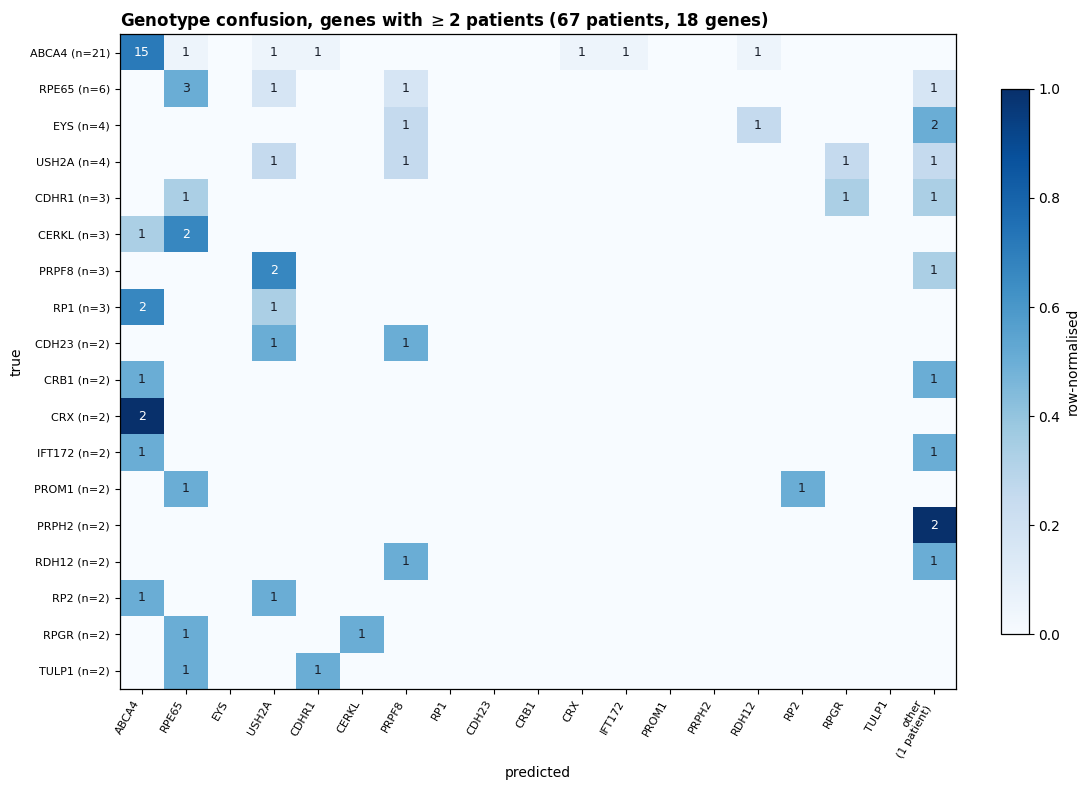

In [20]:
# ---------- 3. genotype confusion matrix, genes with >=2 patients ----------
keep = sorted([g for g in gene_list if gcount[g] >= 2], key=lambda g: -gcount[g])
idx  = {g: i for i, g in enumerate(keep)}
sel  = [x for x in rows_ng if gene_list[x[1]] in idx]

yt = np.array([idx[gene_list[x[1]]] for x in sel])
yh = np.array([idx.get(gene_list[x[2]], -1) for x in sel])
K = len(keep)
cm2 = np.zeros((K, K+1), int)          # last column = predicted a rare gene
for t, p in zip(yt, yh):
    cm2[t, p if p >= 0 else K] += 1

cmn = cm2 / np.maximum(cm2.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for i in range(K):
    for j in range(K+1):
        if cm2[i,j]:
            ax.text(j, i, cm2[i,j], ha='center', va='center', fontsize=9,
                    color='white' if cmn[i,j] > 0.55 else '#1a202c')
ax.set_xticks(range(K+1))
ax.set_xticklabels(keep + ['other\n(1 patient)'], rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(K))
ax.set_yticklabels([f'{g} (n={gcount[g]})' for g in keep], fontsize=8)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title(f'Genotype confusion, genes with $\\geq$2 patients '
             f'({len(sel)} patients, {K} genes)', loc='left', fontweight='bold')
plt.colorbar(im, ax=ax, fraction=0.03, label='row-normalised')
plt.tight_layout(); plt.show()

In [21]:
import numpy as np

def wilson(k, n, z=1.96):
    if n == 0: return (0,0)
    p = k/n; d = 1+z*z/n
    c = (p+z*z/(2*n))/d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0,c-h)*100, min(1,c+h)*100

print("="*70)
print("GENOTYPE 39-class — top-1 / top-3 / top-5, all classifiers")
print("="*70)
print(f"{'classifier':16s} {'top-1':>8s} {'top-3':>8s} {'top-5':>8s}")

for nm in CLFS:
    r = np.array([x[3] for x in res_cv[nm]]); n = len(r)
    print(f"{nm:16s} {(r==0).mean()*100:7.1f}% {(r<3).mean()*100:7.1f}% "
          f"{(r<5).mean()*100:7.1f}%")

print("-"*70)
rk = np.array([x[3] for x in rows_ng]); n = len(rk)
print(f"{'NESTED CV':16s} {(rk==0).mean()*100:7.1f}% {(rk<3).mean()*100:7.1f}% "
      f"{(rk<5).mean()*100:7.1f}%")
print(f"{'baseline':16s} {23.9:7.1f}%")
print(f"{'chance':16s} {100/39:7.1f}% {3*100/39:7.1f}% {5*100/39:7.1f}%")

print(f"\nNested CV with Wilson 95% CI (n = {n}):")
for k in [1,3,5]:
    c = int((rk < k).sum()); lo, hi = wilson(c, n)
    print(f"  Top-{k}: {c/n*100:5.1f}%  [{lo:.1f}, {hi:.1f}]  ({c}/{n})")

GENOTYPE 39-class — top-1 / top-3 / top-5, all classifiers
classifier          top-1    top-3    top-5
LogReg              13.6%    33.0%    34.1%
SVM-lin             22.7%    34.1%    38.6%
SVM-rbf             22.7%    34.1%    38.6%
LDA                 22.7%    34.1%    40.9%
RF                  18.2%    36.4%    40.9%
kNN-5               18.2%    30.7%    30.7%
----------------------------------------------------------------------
NESTED CV           21.6%    37.5%    44.3%
baseline            23.9%
chance               2.6%     7.7%    12.8%

Nested CV with Wilson 95% CI (n = 88):
  Top-1:  21.6%  [14.3, 31.3]  (19/88)
  Top-3:  37.5%  [28.1, 47.9]  (33/88)
  Top-5:  44.3%  [34.4, 54.7]  (39/88)


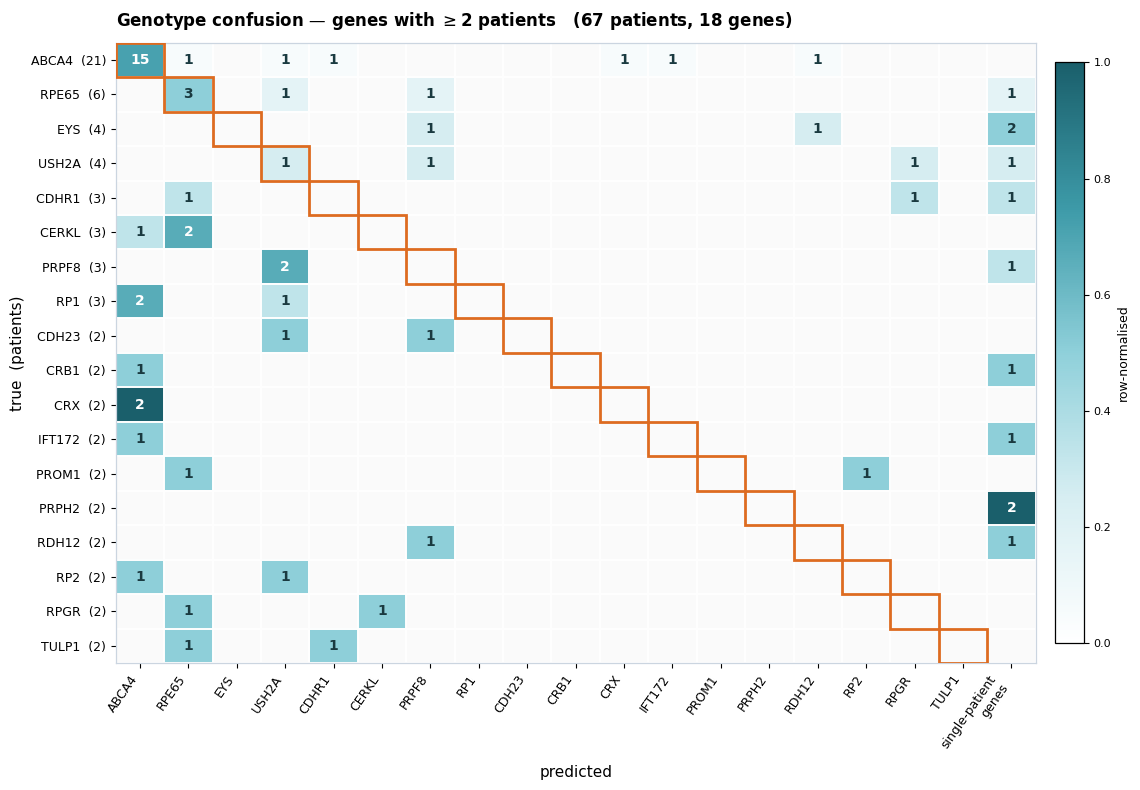

In [22]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

keep = sorted([g for g in gene_list if gcount[g] >= 2], key=lambda g: -gcount[g])
idx  = {g: i for i, g in enumerate(keep)}
sel  = [x for x in rows_ng if gene_list[x[1]] in idx]
K = len(keep)

cm = np.zeros((K, K+1), int)
for x in sel:
    t = idx[gene_list[x[1]]]
    p = idx.get(gene_list[x[2]], K)      # K = predicted a single-patient gene
    cm[t, p] += 1
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)

# soft teal-to-deep colormap, white at zero
cmap = LinearSegmentedColormap.from_list(
    'teal', ['#ffffff', '#d7eef2', '#8fd0da', '#3d9aa8', '#1a5f6b'])

fig, ax = plt.subplots(figsize=(11.5, 8))
masked = np.ma.masked_where(cm == 0, cmn)          # zeros stay blank
cmap.set_bad('#fafafa')
im = ax.imshow(masked, cmap=cmap, vmin=0, vmax=1, aspect='auto')

for i in range(K):
    for j in range(K+1):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    fontsize=10, fontweight='bold',
                    color='white' if cmn[i, j] > 0.5 else '#1a3a40')

# grid lines between cells
ax.set_xticks(np.arange(-.5, K+1, 1), minor=True)
ax.set_yticks(np.arange(-.5, K, 1), minor=True)
ax.grid(which='minor', color='white', linewidth=1.4)
ax.tick_params(which='minor', length=0)

# highlight the diagonal
for i in range(K):
    ax.add_patch(plt.Rectangle((i-.5, i-.5), 1, 1, fill=False,
                               edgecolor='#dd6b20', linewidth=2, zorder=3))

ax.set_xticks(range(K+1))
ax.set_xticklabels(keep + ['single-patient\ngenes'], rotation=55,
                   ha='right', fontsize=9)
ax.set_yticks(range(K))
ax.set_yticklabels([f'{g}  ({gcount[g]})' for g in keep], fontsize=9)
ax.set_xlabel('predicted', fontsize=11)
ax.set_ylabel('true  (patients)', fontsize=11)
ax.set_title(f'Genotype confusion — genes with $\\geq$2 patients   '
             f'({len(sel)} patients, {K} genes)',
             loc='left', fontweight='bold', fontsize=12, pad=12)

cb = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label('row-normalised', fontsize=9)
cb.ax.tick_params(labelsize=8)

for s in ax.spines.values(): s.set_edgecolor('#cbd5e0')
plt.tight_layout(); plt.show()

In [26]:
import numpy as np, matplotlib.pyplot as plt

items = sorted(gcount.items(), key=lambda x: -x[1])
labels_ = [g for g, _ in items]
sizes   = [c for _, c in items]
total   = sum(sizes)

# colour by cohort size band
def col(c):
    if c >= 6: return '#1a5f6b'
    if c >= 3: return '#3d9aa8'
    if c == 2: return '#8fd0da'
    return '#d7eef2'
colors = [col(c) for c in sizes]

fig, ax = plt.subplots(figsize=(11, 9))
wedges, _ = ax.pie(sizes, colors=colors, startangle=90,
                   counterclock=False,
                   wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.2))

# leader-line labels outside each wedge
for w, g, c in zip(wedges, labels_, sizes):
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(ang), np.sin(ang)
    side = 'left' if x >= 0 else 'right'
    ax.annotate(f'{g}  {c}  ({c/total*100:.1f}%)',
                xy=(0.98*x, 0.98*y), xytext=(1.28*x, 1.28*y),
                ha=side, va='center', fontsize=8.5,
                arrowprops=dict(arrowstyle='-', color='#a0aec0', lw=0.7,
                                shrinkA=0, shrinkB=2))
                                 connectionstyle=f'angle,angleA=0,angleB={np.rad2deg(ang):.0f}'))

ax.text(0, 0.10, f'{total}', ha='center', va='center',
        fontsize=32, fontweight='bold', color='#1a5f6b')
ax.text(0, -0.10, 'patients', ha='center', va='center',
        fontsize=12, color='#4a5568')
ax.text(0, -0.26, f'{len(labels_)} genes', ha='center', va='center',
        fontsize=10, color='#718096')

from matplotlib.patches import Patch
n6  = sum(1 for c in sizes if c >= 6)
n35 = sum(1 for c in sizes if 3 <= c <= 5)
n2  = sum(1 for c in sizes if c == 2)
n1  = sum(1 for c in sizes if c == 1)
ax.legend(handles=[
    Patch(facecolor='#1a5f6b', label=f'$\\geq$6 patients  ({n6} genes)'),
    Patch(facecolor='#3d9aa8', label=f'3–5 patients  ({n35} genes)'),
    Patch(facecolor='#8fd0da', label=f'2 patients  ({n2} genes)'),
    Patch(facecolor='#d7eef2', label=f'1 patient  ({n1} genes)')],
    loc='upper left', bbox_to_anchor=(-0.12, 1.02), fontsize=9, frameon=False)

ax.set_title('Distribution of patients across the 39-gene panel',
             fontsize=13, fontweight='bold', y=1.02)
ax.axis('equal')
plt.tight_layout(); plt.show()

IndentationError: unexpected indent (2315032907.py, line 31)

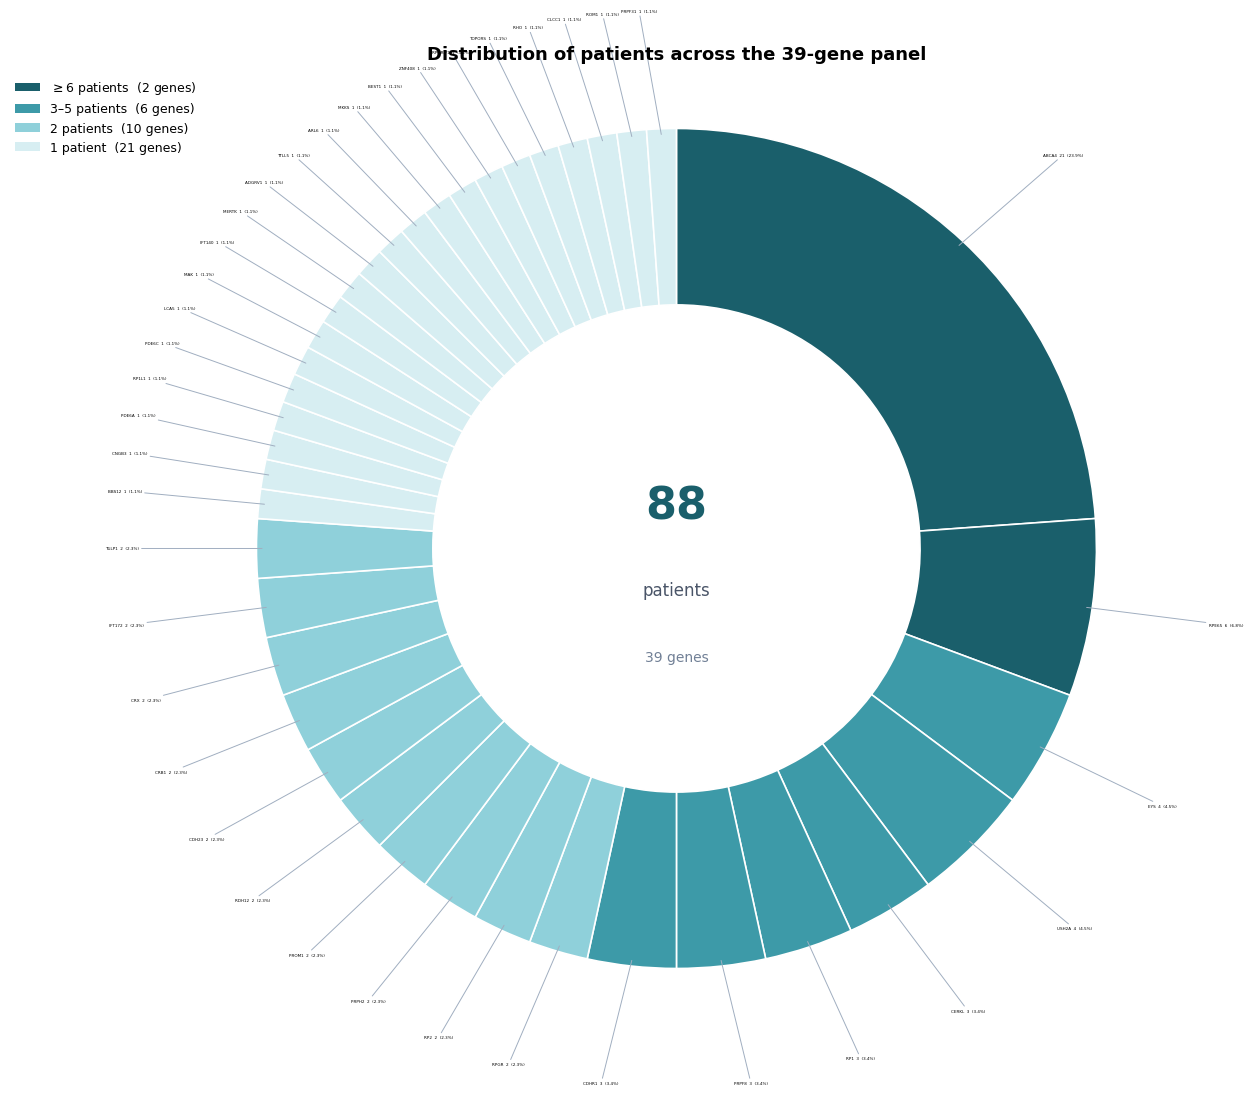

In [29]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Patch

items = sorted(gcount.items(), key=lambda x: -x[1])
labels_ = [g for g, _ in items]
sizes   = [c for _, c in items]
total   = sum(sizes)

def col(c):
    if c >= 6: return '#1a5f6b'
    if c >= 3: return '#3d9aa8'
    if c == 2: return '#8fd0da'
    return '#d7eef2'
colors = [col(c) for c in sizes]

fig, ax = plt.subplots(figsize=(14, 12))
wedges, _ = ax.pie(sizes, colors=colors, startangle=90,
                   counterclock=False,
                   wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.2))

for w, g, c in zip(wedges, labels_, sizes):
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(ang), np.sin(ang)
    side = 'left' if x >= 0 else 'right'
    ax.annotate(f'{g}  {c}  ({c/total*100:.1f}%)',
                xy=(0.98*x, 0.98*y), xytext=(1.28*x, 1.28*y),
                ha=side, va='center', fontsize=3,
                arrowprops=dict(arrowstyle='-', color='#a0aec0', lw=0.7,
                                shrinkA=0, shrinkB=2))

ax.text(0, 0.10, f'{total}', ha='center', va='center',
        fontsize=32, fontweight='bold', color='#1a5f6b')
ax.text(0, -0.10, 'patients', ha='center', va='center',
        fontsize=12, color='#4a5568')
ax.text(0, -0.26, f'{len(labels_)} genes', ha='center', va='center',
        fontsize=10, color='#718096')

n6  = sum(1 for c in sizes if c >= 6)
n35 = sum(1 for c in sizes if 3 <= c <= 5)
n2  = sum(1 for c in sizes if c == 2)
n1  = sum(1 for c in sizes if c == 1)
ax.legend(handles=[
    Patch(facecolor='#1a5f6b', label=f'$\\geq$6 patients  ({n6} genes)'),
    Patch(facecolor='#3d9aa8', label=f'3–5 patients  ({n35} genes)'),
    Patch(facecolor='#8fd0da', label=f'2 patients  ({n2} genes)'),
    Patch(facecolor='#d7eef2', label=f'1 patient  ({n1} genes)')],
    loc='upper left', bbox_to_anchor=(-0.12, 1.02), fontsize=9, frameon=False)

ax.set_title('Distribution of patients across the 39-gene panel',
             fontsize=13, fontweight='bold', y=1.02)
ax.axis('equal')
plt.show()

Number of genes: 39
Total patients: 88


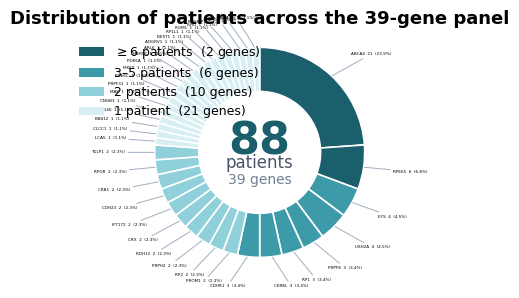

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ============================================================
# 39 genes and number of patients
# ============================================================

gcount = {
    "ABCA4": 21,
    "RPE65": 6,
    "EYS": 4,
    "USH2A": 4,
    "PRPF8": 3,
    "RP1": 3,
    "CERKL": 3,
    "CDHR1": 3,
    "PROM1": 2,
    "RP2": 2,
    "PRPH2": 2,
    "RDH12": 2,
    "CRX": 2,
    "IFT172": 2,
    "CDH23": 2,
    "CRB1": 2,
    "RPGR": 2,
    "TULP1": 2,
    "LCA5": 1,
    "CLCC1": 1,
    "BBS12": 1,
    "IFT140": 1,
    "CNGB3": 1,
    "MAK": 1,
    "PRPF31": 1,
    "PDE6C": 1,
    "MKKS": 1,
    "PDE6A": 1,
    "MERTK": 1,
    "ARL6": 1,
    "ADGRV1": 1,
    "BEST1": 1,
    "RP1L1": 1,
    "ROM1": 1,
    "RHO": 1,
    "RPGRIP1": 1,
    "TTLL5": 1,
    "TOPORS": 1,
    "ZNF408": 1
}

# ============================================================
# Sort by number of patients
# ============================================================

items = sorted(gcount.items(), key=lambda x: -x[1])

labels_ = [g for g, _ in items]
sizes   = [c for _, c in items]

total = sum(sizes)

print("Number of genes:", len(labels_))
print("Total patients:", total)


# ============================================================
# Colors according to cohort size
# ============================================================

def col(c):
    if c >= 6:
        return '#1a5f6b'
    if c >= 3:
        return '#3d9aa8'
    if c == 2:
        return '#8fd0da'
    return '#d7eef2'

colors = [col(c) for c in sizes]


# ============================================================
# Donut chart
# ============================================================

fig, ax = plt.subplots(figsize=(4, 3))

wedges, _ = ax.pie(
    sizes,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(
        width=0.42,
        edgecolor='white',
        linewidth=1.2
    )
)


# ============================================================
# Gene labels
# ============================================================

for w, g, c in zip(wedges, labels_, sizes):

    ang = np.deg2rad((w.theta1 + w.theta2) / 2)

    x, y = np.cos(ang), np.sin(ang)

    side = 'left' if x >= 0 else 'right'

    ax.annotate(
        f'{g}  {c}  ({c/total*100:.1f}%)',
        xy=(0.98*x, 0.98*y),
        xytext=(1.28*x, 1.28*y),
        ha=side,
        va='center',
        fontsize=3,
        arrowprops=dict(
            arrowstyle='-',
            color='#a0aec0',
            lw=0.7,
            shrinkA=0,
            shrinkB=2
        )
    )


# ============================================================
# Centre text
# ============================================================

ax.text(
    0, 0.10,
    f'{total}',
    ha='center',
    va='center',
    fontsize=32,
    fontweight='bold',
    color='#1a5f6b'
)

ax.text(
    0, -0.10,
    'patients',
    ha='center',
    va='center',
    fontsize=12,
    color='#4a5568'
)

ax.text(
    0, -0.26,
    f'{len(labels_)} genes',
    ha='center',
    va='center',
    fontsize=10,
    color='#718096'
)


# ============================================================
# Legend counts
# ============================================================

n6  = sum(1 for c in sizes if c >= 6)
n35 = sum(1 for c in sizes if 3 <= c <= 5)
n2  = sum(1 for c in sizes if c == 2)
n1  = sum(1 for c in sizes if c == 1)

ax.legend(
    handles=[
        Patch(
            facecolor='#1a5f6b',
            label=f'$\\geq$6 patients  ({n6} genes)'
        ),
        Patch(
            facecolor='#3d9aa8',
            label=f'3–5 patients  ({n35} genes)'
        ),
        Patch(
            facecolor='#8fd0da',
            label=f'2 patients  ({n2} genes)'
        ),
        Patch(
            facecolor='#d7eef2',
            label=f'1 patient  ({n1} genes)'
        )
    ],
    loc='upper left',
    bbox_to_anchor=(-0.12, 1.02),
    fontsize=9,
    frameon=False
)


# ============================================================
# Title
# ============================================================

ax.set_title(
    'Distribution of patients across the 39-gene panel',
    fontsize=13,
    fontweight='bold',
    y=1.02
)

ax.axis('equal')

plt.show()

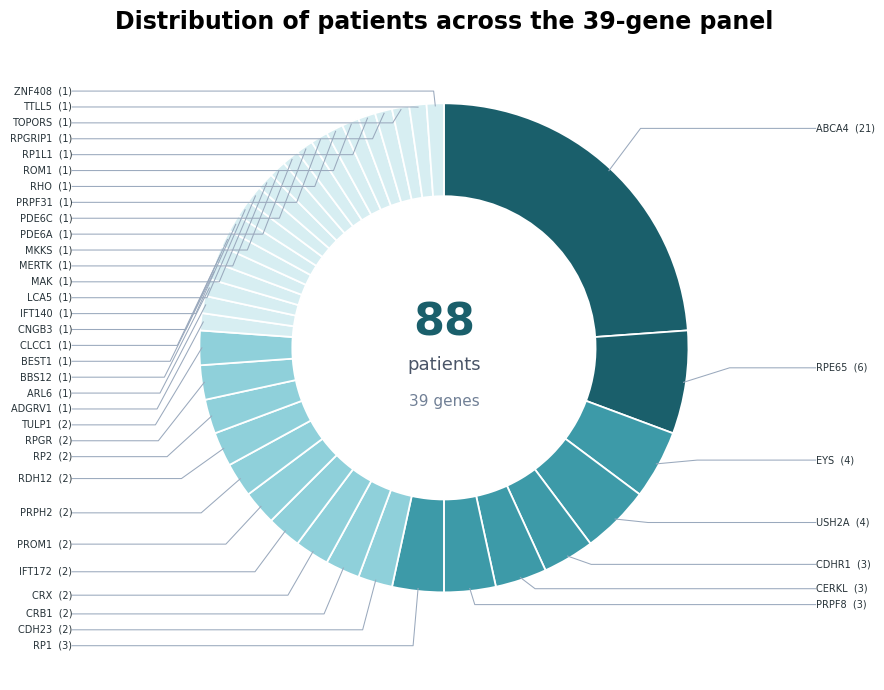

In [45]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 39-gene patient counts
# ============================================================

gcount = {
    "ABCA4": 21,
    "RPE65": 6,
    "EYS": 4,
    "USH2A": 4,
    "PRPF8": 3,
    "RP1": 3,
    "CERKL": 3,
    "CDHR1": 3,
    "PROM1": 2,
    "RP2": 2,
    "PRPH2": 2,
    "RDH12": 2,
    "CRX": 2,
    "IFT172": 2,
    "CDH23": 2,
    "CRB1": 2,
    "RPGR": 2,
    "TULP1": 2,
    "LCA5": 1,
    "CLCC1": 1,
    "BBS12": 1,
    "IFT140": 1,
    "CNGB3": 1,
    "MAK": 1,
    "PRPF31": 1,
    "PDE6C": 1,
    "MKKS": 1,
    "PDE6A": 1,
    "MERTK": 1,
    "ARL6": 1,
    "ADGRV1": 1,
    "BEST1": 1,
    "RP1L1": 1,
    "ROM1": 1,
    "RHO": 1,
    "RPGRIP1": 1,
    "TTLL5": 1,
    "TOPORS": 1,
    "ZNF408": 1
}

# Sort by patient count
items = sorted(gcount.items(), key=lambda x: (-x[1], x[0]))

labels = [g for g, _ in items]
sizes = [c for _, c in items]

total = sum(sizes)

# ============================================================
# Cohort-size colors
# ============================================================

def get_color(c):
    if c >= 6:
        return '#1a5f6b'
    elif c >= 3:
        return '#3d9aa8'
    elif c == 2:
        return '#8fd0da'
    else:
        return '#d7eef2'

colors = [get_color(c) for c in sizes]

# ============================================================
# Figure
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

# Make donut
wedges, _ = ax.pie(
    sizes,
    startangle=90,
    counterclock=False,
    colors=colors,
    radius=1.0,
    wedgeprops=dict(
        width=0.38,
        edgecolor='white',
        linewidth=1.3
    )
)

# ============================================================
# Find label positions
# ============================================================

left_labels = []
right_labels = []

for w, gene, count in zip(wedges, labels, sizes):

    angle = np.deg2rad((w.theta1 + w.theta2) / 2)

    x = np.cos(angle)
    y = np.sin(angle)

    entry = {
        "gene": gene,
        "count": count,
        "x": x,
        "y": y,
        "angle": angle
    }

    if x >= 0:
        right_labels.append(entry)
    else:
        left_labels.append(entry)

# Sort vertically
left_labels.sort(key=lambda d: -d["y"])
right_labels.sort(key=lambda d: -d["y"])

# ============================================================
# Spread labels vertically
# ============================================================

def spread_labels(entries, y_min=-1.05, y_max=1.05, min_gap=0.065):

    if not entries:
        return

    ys = [d["y"] * 1.12 for d in entries]

    # Forward pass
    for i in range(1, len(ys)):
        if ys[i-1] - ys[i] < min_gap:
            ys[i] = ys[i-1] - min_gap

    # Shift upward/downward if necessary
    if ys[-1] < y_min:
        shift = y_min - ys[-1]
        ys = [y + shift for y in ys]

    if ys[0] > y_max:
        shift = y_max - ys[0]
        ys = [y + shift for y in ys]

    for d, y_new in zip(entries, ys):
        d["label_y"] = y_new

spread_labels(left_labels)
spread_labels(right_labels)

# ============================================================
# Draw annotations
# ============================================================

def draw_labels(entries, side):

    for d in entries:

        gene = d["gene"]
        count = d["count"]
        x = d["x"]
        y = d["y"]
        label_y = d["label_y"]

        if side == "right":
            x_text = 1.52
            ha = "left"
        else:
            x_text = -1.52
            ha = "right"

        # connector line: wedge -> elbow -> text
        x_start = 0.99 * x
        y_start = 0.99 * y

        x_mid = 1.18 * x

        ax.plot(
            [x_start, x_mid, x_text],
            [y_start, label_y, label_y],
            color='#9aa9bd',
            lw=0.75
        )

        # label
        ax.text(
            x_text,
            label_y,
            f"{gene}  ({count})",
            ha=ha,
            va="center",
            fontsize=7,
            color='#263238'
        )

draw_labels(left_labels, "left")
draw_labels(right_labels, "right")

# ============================================================
# Centre text
# ============================================================

ax.text(
    0,
    0.10,
    f"{total}",
    ha="center",
    va="center",
    fontsize=32,
    fontweight="bold",
    color="#1a5f6b"
)

ax.text(
    0,
    -0.07,
    "patients",
    ha="center",
    va="center",
    fontsize=13,
    color="#4a5568"
)

ax.text(
    0,
    -0.22,
    f"{len(labels)} genes",
    ha="center",
    va="center",
    fontsize=11,
    color="#718096"
)

# ============================================================
# Title
# ============================================================

ax.set_title(
    "Distribution of patients across the 39-gene panel",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.axis("equal")

plt.tight_layout()
plt.show()

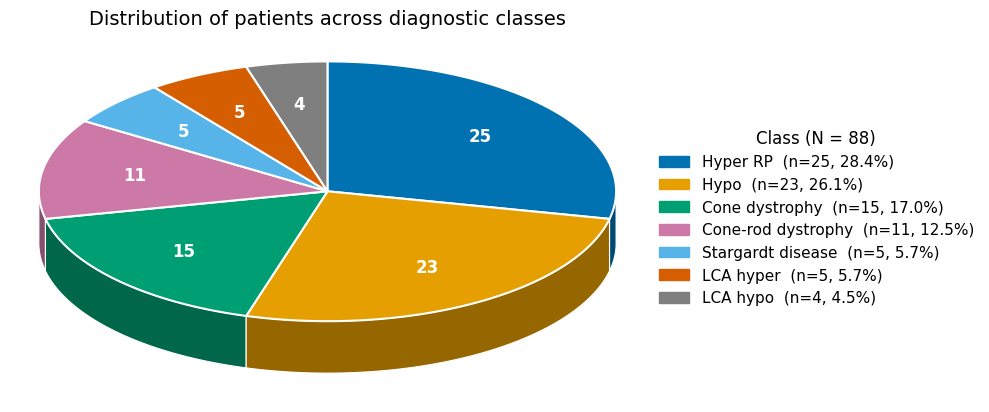

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import to_rgb
import numpy as np

# ---------------- Data ----------------
labels = ["Hyper RP", "Hypo", "Cone dystrophy", "Cone-rod dystrophy",
          "Stargardt disease", "LCA hyper", "LCA hypo"]
counts = [25, 23, 15, 11, 5, 5, 4]
colors = ["#0072B2", "#E69F00", "#009E73", "#CC79A7",
          "#56B4E9", "#D55E00", "#7F7F7F"]

total = sum(counts)

# ---------------- 3D settings ----------------
tilt  = 0.45   # 1 = flat (top view), kam value = zyada 3D tilt
depth = 0.18   # pie ki motai (thickness)
start = 90     # pehla slice 12 baje se start

def darker(c, f=0.65):
    return tuple(v * f for v in to_rgb(c))

fig, ax = plt.subplots(figsize=(10, 6))

# har slice ke angles (clockwise)
angles = []
a = start
for n in counts:
    sweep = 360 * n / total
    angles.append((a - sweep, a))
    a -= sweep

# ---------------- Side walls (3D thickness) ----------------
walls = []
for (a1, a2), c in zip(angles, colors):
    t = np.radians(np.linspace(a1, a2, 100))
    x, y = np.cos(t), np.sin(t) * tilt
    front = y <= 0                      # sirf aage wala hissa dikhta hai
    if not front.any():
        continue
    xs, ys = x[front], y[front]
    top    = np.column_stack([xs, ys])
    bottom = np.column_stack([xs, ys - depth])[::-1]
    poly = Polygon(np.vstack([top, bottom]), closed=True,
                   facecolor=darker(c), edgecolor="white", linewidth=0.8)
    walls.append((ys.min(), poly))

for _, poly in sorted(walls, key=lambda p: -p[0]):
    ax.add_patch(poly)

# ---------------- Top surface ----------------
for (a1, a2), c, n in zip(angles, colors, counts):
    t = np.radians(np.linspace(a1, a2, 100))
    pts = np.column_stack([np.cos(t), np.sin(t) * tilt])
    ax.add_patch(Polygon(np.vstack([[0, 0], pts]), closed=True,
                         facecolor=c, edgecolor="white", linewidth=1.5))
    mid = np.radians((a1 + a2) / 2)
    ax.text(0.68 * np.cos(mid), 0.68 * np.sin(mid) * tilt, str(n),
            ha="center", va="center", color="white",
            fontsize=12, fontweight="bold")

# ---------------- Legend ----------------
legend_labels = [f"{l}  (n={n}, {100*n/total:.1f}%)"
                 for l, n in zip(labels, counts)]
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors]
ax.legend(handles, legend_labels, title=f"Class (N = {total})",
          loc="center left", bbox_to_anchor=(1.0, 0.5),
          frameon=False, fontsize=11, title_fontsize=12)

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-tilt - depth - 0.1, tilt + 0.1)
ax.set_aspect("equal")
ax.axis("off")
plt.title("Distribution of patients across diagnostic classes", fontsize=14)
plt.tight_layout()

# paper me daalne ke liye save (chahiye to rakh, warna hata de)
plt.savefig("class_distribution_3d.png", dpi=300, bbox_inches="tight")
plt.show()

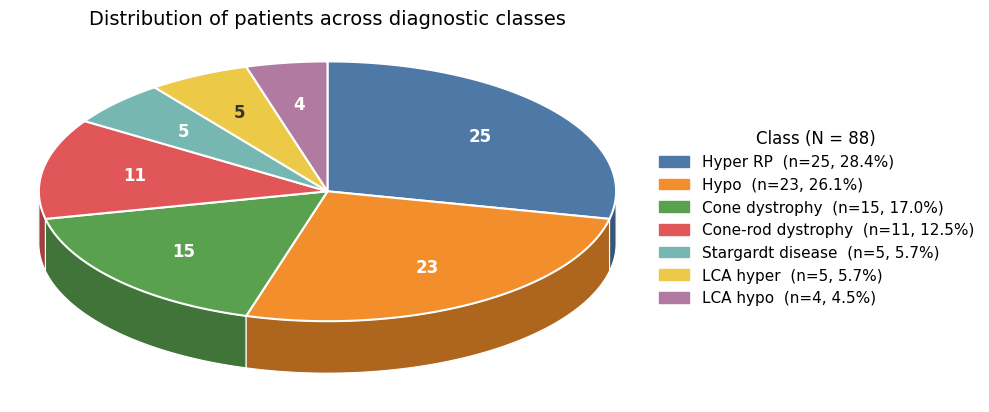

In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import to_rgb
import numpy as np

# ---------------- Data ----------------
labels = ["Hyper RP", "Hypo", "Cone dystrophy", "Cone-rod dystrophy",
          "Stargardt disease", "LCA hyper", "LCA hypo"]
counts = [25, 23, 15, 11, 5, 5, 4]

# Naya soft professional palette
colors = ["#4E79A7",  # blue
          "#F28E2B",  # orange
          "#59A14F",  # green
          "#E15759",  # red
          "#76B7B2",  # teal
          "#EDC948",  # yellow
          "#B07AA1"]  # purple

total = sum(counts)

# ---------------- 3D settings ----------------
tilt  = 0.45   # 1 = flat (top view), kam value = zyada 3D tilt
depth = 0.18   # pie ki motai (thickness)
start = 90     # pehla slice 12 baje se start

def darker(c, f=0.72):
    return tuple(v * f for v in to_rgb(c))

def text_color(c):
    # light slice pe dark text, dark slice pe white text
    r, g, b = to_rgb(c)
    return "#333333" if (0.299*r + 0.587*g + 0.114*b) > 0.65 else "white"

fig, ax = plt.subplots(figsize=(10, 6))

# har slice ke angles (clockwise)
angles = []
a = start
for n in counts:
    sweep = 360 * n / total
    angles.append((a - sweep, a))
    a -= sweep

# ---------------- Side walls (3D thickness) ----------------
walls = []
for (a1, a2), c in zip(angles, colors):
    t = np.radians(np.linspace(a1, a2, 100))
    x, y = np.cos(t), np.sin(t) * tilt
    front = y <= 0
    if not front.any():
        continue
    xs, ys = x[front], y[front]
    top    = np.column_stack([xs, ys])
    bottom = np.column_stack([xs, ys - depth])[::-1]
    poly = Polygon(np.vstack([top, bottom]), closed=True,
                   facecolor=darker(c), edgecolor="white", linewidth=0.8)
    walls.append((ys.min(), poly))

for _, poly in sorted(walls, key=lambda p: -p[0]):
    ax.add_patch(poly)

# ---------------- Top surface ----------------
for (a1, a2), c, n in zip(angles, colors, counts):
    t = np.radians(np.linspace(a1, a2, 100))
    pts = np.column_stack([np.cos(t), np.sin(t) * tilt])
    ax.add_patch(Polygon(np.vstack([[0, 0], pts]), closed=True,
                         facecolor=c, edgecolor="white", linewidth=1.5))
    mid = np.radians((a1 + a2) / 2)
    ax.text(0.68 * np.cos(mid), 0.68 * np.sin(mid) * tilt, str(n),
            ha="center", va="center", color=text_color(c),
            fontsize=12, fontweight="bold")

# ---------------- Legend ----------------
legend_labels = [f"{l}  (n={n}, {100*n/total:.1f}%)"
                 for l, n in zip(labels, counts)]
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors]
ax.legend(handles, legend_labels, title=f"Class (N = {total})",
          loc="center left", bbox_to_anchor=(1.0, 0.5),
          frameon=False, fontsize=11, title_fontsize=12)

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-tilt - depth - 0.1, tilt + 0.1)
ax.set_aspect("equal")
ax.axis("off")
plt.title("Distribution of patients across diagnostic classes", fontsize=14)
plt.tight_layout()

plt.savefig("class_distribution_3d.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
import numpy as np
import pandas as pd

_summary = (pd.DataFrame({"category": np.asarray(pheno).astype(str),
                          "patient":  np.asarray(patient).astype(str)})
              .groupby("category")
              .agg(n_patients=("patient", "nunique"),
                   n_images=("patient", "size"))
              .sort_values("n_images", ascending=False))

print(_summary.to_string())
print("-" * 40)
print(f"TOTAL  patients: {_summary['n_patients'].sum()}   images: {_summary['n_images'].sum()}")

                    n_patients  n_images
category                                
                             8       393
HYPER RP                    25        49
HYPO                        23        45
CONE DYSTROPHY              15        30
CONE ROD DYSTROPHY          11        21
LCA HYPER                    5        10
STARGARDTS                   5        10
LCA HYPO                     4         8
----------------------------------------
TOTAL  patients: 96   images: 566


In [37]:
import numpy as np, pickle, time, warnings
warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline


# ============================================================
# 5-FOLD CV — AUGMENTATION
# ALL 6 CLASSIFIERS
# ============================================================

# fold map: wahi fold_of jo original genotype39 me tha
# (same patients)
missing = [p for p in up if p not in fold_of]
print(f"patients not in fold_of: {len(missing)}  {missing[:5]}")


def cv_aug_all_classifiers(npca=15):

    # rows_by_clf stores predictions/results separately
    rows_by_clf = {nm: [] for nm in CLFS}

    for f in range(5):

        # -----------------------------
        # outer test / train patients
        # -----------------------------
        te_p = sorted([
            p for p in up
            if fold_of.get(p, -1) == f
        ])

        tr_p = sorted([
            p for p in up
            if fold_of.get(p, -1) != f
            and p in fold_of
        ])

        if not te_p:
            continue

        # -----------------------------
        # outer test mask
        # -----------------------------
        te_all = np.isin(pat_aug, te_p)

        # IMPORTANT:
        # training contains everything except
        # the outer test patients
        itr_base = ~te_all


        # ====================================================
        # RUN ALL 6 CLASSIFIERS
        # ====================================================

        for nm, mk in CLFS.items():

            print(f"  fold {f} | {nm}")

            pipe = make_pipeline(
                StandardScaler(),
                PCA(npca, random_state=0),
                mk()
            )

            # -----------------------------
            # train on outer training set
            # -----------------------------
            pipe.fit(
                X_aug[itr_base],
                ya[itr_base]
            )

            cl = pipe[-1].classes_

            # =================================================
            # PATIENT-LEVEL TEST PREDICTION
            # =================================================

            for p in te_p:

                # original image of this patient
                m = (
                    (pat_aug == p)
                    & ~isaug
                )

                # fallback if original image unavailable
                if m.sum() == 0:
                    m = pat_aug == p

                if m.sum() == 0:
                    continue

                # ---------------------------------------------
                # average probabilities over patient's image(s)
                # ---------------------------------------------
                prob = pipe.predict_proba(
                    X_aug[m]
                ).mean(0)

                order = list(
                    cl[np.argsort(prob)[::-1]]
                )

                # true class
                t = ya[m][0]

                # rank of true class
                r = (
                    order.index(t)
                    if t in order
                    else 999
                )

                rows_by_clf[nm].append(
                    (
                        p,              # patient
                        int(t),         # true class
                        int(order[0]),  # predicted top-1
                        r               # rank
                    )
                )

        print(f"  fold {f}: all 6 classifiers completed")

    return rows_by_clf


# ============================================================
# RUN
# ============================================================

t0 = time.time()

rows_aug_all = cv_aug_all_classifiers()

print(
    f"\n({time.time()-t0:.0f}s) "
    "5-fold CV completed"
)


# ============================================================
# REPORT
# ============================================================

print(f"\n{'='*78}")
print("5-FOLD CV — AUGMENTATION EFFECT")
print("ALL 6 CLASSIFIERS | SAME PATIENT-LEVEL FOLDS")
print("="*78)

print(
    f"{'classifier':15s} "
    f"{'top1':>10s} "
    f"{'top3':>10s} "
    f"{'top5':>10s} "
    f"{'n':>6s}"
)

for nm in CLFS:

    rows = rows_aug_all[nm]

    rk = np.array([
        x[3] for x in rows
    ])

    print(
        f"{nm:15s} "
        f"{(rk==0).mean()*100:9.1f}% "
        f"{(rk<3).mean()*100:9.1f}% "
        f"{(rk<5).mean()*100:9.1f}% "
        f"{len(rk):6d}"
    )


# ============================================================
# NO-AUGMENTATION COMPARISON
# ============================================================

print(f"\n{'='*78}")
print("NO AUGMENTATION vs AUGMENTATION")
print("="*78)

# rows_ng = existing no-augmentation results
# This is kept exactly as in your previous code.

rk_on = np.array([
    x[3] for x in rows_ng
])

print(
    f"  {'no augmentation':22s} "
    f"top1 {(rk_on==0).mean()*100:5.1f}%  "
    f"top3 {(rk_on<3).mean()*100:5.1f}%"
)


for nm in CLFS:

    rows = rows_aug_all[nm]

    rk_an = np.array([
        x[3] for x in rows
    ])

    print(
        f"  {nm:22s} "
        f"top1 {(rk_an==0).mean()*100:5.1f}%  "
        f"top3 {(rk_an<3).mean()*100:5.1f}%"
    )


# ============================================================
# McNEMAR
# ============================================================

from scipy.stats import binomtest

print(f"\n{'='*78}")
print("McNEMAR — NO AUGMENTATION vs AUGMENTATION")
print("="*78)

a = {
    x[0]: x[3] == 0
    for x in rows_ng
}

for nm in CLFS:

    b = {
        x[0]: x[3] == 0
        for x in rows_aug_all[nm]
    }

    common = sorted(
        set(a) & set(b)
    )

    n01 = sum(
        1 for p in common
        if a[p] and not b[p]
    )

    n10 = sum(
        1 for p in common
        if b[p] and not a[p]
    )

    pv = (
        binomtest(
            n01,
            n01 + n10,
            0.5
        ).pvalue
        if (n01 + n10)
        else 1.0
    )

    print(
        f"{nm:15s} "
        f"orig-only {n01:2d}, "
        f"aug-only {n10:2d}, "
        f"p = {pv:.4f} "
        f"{'(significant)' if pv < 0.05 else '(not significant)'}"
    )


# ============================================================
# STRATIFIED BY GENE REPRESENTATION
# ============================================================

print(f"\n{'='*78}")
print("STRATIFIED BY GENE REPRESENTATION")
print("="*78)

print(
    f"{'group':12s} "
    f"{'classifier':15s} "
    f"{'top1':>10s} "
    f"{'top3':>10s} "
    f"{'n':>5s}"
)

for lo, hi, lab in [
    (6, 99, '>=6'),
    (3, 5, '3-5'),
    (1, 2, '1-2')
]:

    for nm in CLFS:

        rows = [
            x for x in rows_aug_all[nm]
            if lo <= gcp[gl[x[1]]] <= hi
        ]

        if not rows:
            continue

        rk = np.array([
            x[3] for x in rows
        ])

        print(
            f"{lab:12s} "
            f"{nm:15s} "
            f"{(rk==0).mean()*100:9.1f}% "
            f"{(rk<3).mean()*100:9.1f}% "
            f"{len(rk):5d}"
        )


# ============================================================
# SAVE
# ============================================================

pickle.dump(
    dict(
        rows_aug_all=rows_aug_all
    ),
    open(
        '/kaggle/working/results/ml_aug_5fold_all.pkl',
        'wb'
    )
)

print(
    "\nsaved ml_aug_5fold_all.pkl"
)

patients not in fold_of: 0  []
  fold 0 | LogReg
  fold 0 | SVM-lin
  fold 0 | SVM-rbf
  fold 0 | LDA
  fold 0 | RF
  fold 0 | kNN-5
  fold 0: all 6 classifiers completed
  fold 1 | LogReg
  fold 1 | SVM-lin
  fold 1 | SVM-rbf
  fold 1 | LDA
  fold 1 | RF
  fold 1 | kNN-5
  fold 1: all 6 classifiers completed
  fold 2 | LogReg
  fold 2 | SVM-lin
  fold 2 | SVM-rbf
  fold 2 | LDA
  fold 2 | RF
  fold 2 | kNN-5
  fold 2: all 6 classifiers completed
  fold 3 | LogReg
  fold 3 | SVM-lin
  fold 3 | SVM-rbf
  fold 3 | LDA
  fold 3 | RF
  fold 3 | kNN-5
  fold 3: all 6 classifiers completed
  fold 4 | LogReg
  fold 4 | SVM-lin
  fold 4 | SVM-rbf
  fold 4 | LDA
  fold 4 | RF
  fold 4 | kNN-5
  fold 4: all 6 classifiers completed

(15s) 5-fold CV completed

5-FOLD CV — AUGMENTATION EFFECT
ALL 6 CLASSIFIERS | SAME PATIENT-LEVEL FOLDS
classifier            top1       top3       top5      n
LogReg               15.9%      33.0%      35.2%     88
SVM-lin              21.6%      30.7%      35.2%    

In [38]:
import numpy as np
import pickle
import time
import warnings
warnings.filterwarnings('ignore')
from collections import Counter

# ============================================================
# NESTED CV — WITH AUGMENTATION
# TOP-1 / TOP-3 / TOP-5
# ============================================================

def nested_aug(topk_sel=3, n_inner=12, npca=15, seed=0):

    rows = []
    chosen = Counter()

    for f in range(5):

        # ----------------------------------------------------
        # Outer test / training patients
        # ----------------------------------------------------
        te_p = sorted([
            p for p in up
            if fold_of.get(p, -1) == f
        ])

        tr_p = sorted([
            p for p in up
            if fold_of.get(p, -1) != f
            and p in fold_of
        ])

        if not te_p:
            continue

        te_all = np.isin(pat_aug, te_p)
        itr_base = ~te_all

        # ====================================================
        # INNER CV — classifier selection
        # ====================================================

        rng = np.random.RandomState(seed + f)

        sub = rng.choice(
            tr_p,
            min(n_inner, len(tr_p)),
            replace=False
        )

        sc_ = {}

        for nm, mk in CLFS.items():

            c = 0

            for p in sub:

                ip_all = pat_aug == p

                ip_org = ip_all & ~isaug

                if ip_org.sum() == 0:
                    ip_org = ip_all

                # Remove validation patient from inner training
                itr = itr_base & ~ip_all

                if len(set(ya[itr])) < 2:
                    continue

                pipe = make_pipeline(
                    StandardScaler(),
                    PCA(npca, random_state=0),
                    mk()
                )

                pipe.fit(
                    X_aug[itr],
                    ya[itr]
                )

                # Patient-level probability
                pr = pipe.predict_proba(
                    X_aug[ip_org]
                ).mean(0)

                order = list(
                    pipe[-1].classes_[
                        np.argsort(pr)[::-1]
                    ]
                )

                t = ya[ip_org][0]

                c += (
                    order.index(t) < topk_sel
                    if t in order
                    else 0
                )

            sc_[nm] = c

        # ----------------------------------------------------
        # Select classifier using inner CV
        # ----------------------------------------------------
        best = sorted(
            sc_,
            key=lambda k: (-sc_[k], k)
        )[0]

        chosen[best] += 1

        # ====================================================
        # OUTER TRAINING WITH SELECTED CLASSIFIER
        # ====================================================

        pipe = make_pipeline(
            StandardScaler(),
            PCA(npca, random_state=0),
            CLFS[best]()
        )

        pipe.fit(
            X_aug[itr_base],
            ya[itr_base]
        )

        cl = pipe[-1].classes_

        # ====================================================
        # OUTER TEST — PATIENT LEVEL
        # ====================================================

        for p in te_p:

            m = (
                (pat_aug == p)
                & ~isaug
            )

            if m.sum() == 0:
                m = pat_aug == p

            if m.sum() == 0:
                continue

            # Average probabilities across patient's images
            prob = pipe.predict_proba(
                X_aug[m]
            ).mean(0)

            # Ranked classes
            order = list(
                cl[np.argsort(prob)[::-1]]
            )

            # True class
            t = ya[m][0]

            # Rank of true class
            rank = (
                order.index(t)
                if t in order
                else 999
            )

            rows.append(
                (
                    p,
                    int(t),
                    int(order[0]),
                    rank
                )
            )

        print(f"  fold {f}: {best}")

    return rows, chosen


# ============================================================
# RUN
# ============================================================

t0 = time.time()

rows_aug_nested, ch_aug = nested_aug()

print(
    f"\n({time.time()-t0:.0f}s) "
    f"chosen: {dict(ch_aug)}"
)


# ============================================================
# TOP-1 / TOP-3 / TOP-5
# ============================================================

rk_aug = np.array([
    x[3] for x in rows_aug_nested
])

n = len(rk_aug)

top1 = (rk_aug == 0).mean() * 100
top3 = (rk_aug < 3).mean() * 100
top5 = (rk_aug < 5).mean() * 100

print(f"\n{'='*70}")
print("NESTED CV — WITH AUGMENTATION")
print("="*70)

print(f"Patients : {n}")
print(f"Top-1    : {top1:.1f}%")
print(f"Top-3    : {top3:.1f}%")
print(f"Top-5    : {top5:.1f}%")


# ============================================================
# SAVE
# ============================================================

pickle.dump(
    dict(
        rows_aug_nested=rows_aug_nested,
        ch_aug=dict(ch_aug)
    ),
    open(
        '/kaggle/working/results/ml_aug_nested.pkl',
        'wb'
    )
)

print("\nsaved ml_aug_nested.pkl")

  fold 0: LogReg
  fold 1: LDA
  fold 2: LDA
  fold 3: LogReg
  fold 4: LDA

(119s) chosen: {'LogReg': 2, 'LDA': 3}

NESTED CV — WITH AUGMENTATION
Patients : 88
Top-1    : 18.2%
Top-3    : 34.1%
Top-5    : 40.9%

saved ml_aug_nested.pkl


In [16]:
import timm
m = timm.create_model('vit_large_patch14_dinov2.lvd142m',
                      pretrained=True, num_classes=0, global_pool='',
                      img_size=980).eval().cuda()

In [17]:
import torch
print(m.num_prefix_tokens)

x = torch.randn(1, 3, 980, 980).cuda()
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
    t = m.forward_features(x)
print(t.shape)

1
torch.Size([1, 4901, 1024])


In [18]:
import torch, timm, numpy as np, cv2, time

device = torch.device('cuda')
dino_L = timm.create_model('vit_large_patch14_dinov2.lvd142m',
                           pretrained=True, num_classes=0,
                           dynamic_img_size=True).to(device).eval()
for p in dino_L.parameters(): p.requires_grad = False

N_PREFIX_L, EMB_L = getattr(dino_L,'num_prefix_tokens',1), dino_L.embed_dim
print(f"prefix {N_PREFIX_L} | embed {EMB_L}")   # 1 | 1024

@torch.no_grad()
def valid_cells_L(raw):
    img, om = preprocess(raw)
    h0, w0 = img.shape[:2]; s = IMG_SIZE/max(h0,w0)
    nh, nw = (int(round(h0*s))//PATCH)*PATCH, (int(round(w0*s))//PATCH)*PATCH
    im = cv2.resize(img, (nw,nh), interpolation=cv2.INTER_AREA)
    t = (torch.from_numpy(im).permute(2,0,1).float().div(255.)[None].to(device)-_MEAN)/_STD
    with torch.autocast('cuda', dtype=torch.float16):
        tok = dino_L.forward_features(t)[:, N_PREFIX_L:, :]
    gh, gw = nh//PATCH, nw//PATCH
    f = tok.float().reshape(1,gh,gw,EMB_L)[0].cpu().numpy().astype(np.float32)
    om_s = cv2.resize(om.astype(np.uint8),(gw,gh),interpolation=cv2.INTER_AREA)>0
    grn  = cv2.resize(img[:,:,1],(gw,gh),interpolation=cv2.INTER_AREA)
    return img, om, f, om_s & ~((grn < DARK) & om_s)

X2048, ncells_L = [], []
t0 = time.time()
for i, im in enumerate(imgs):
    _,_,f,v = valid_cells_L(im)
    c = f[v]
    X2048.append(np.concatenate([c.mean(0), c.std(0)]))
    ncells_L.append(int(v.sum()))
    if (i+1)%100==0 or i==len(imgs)-1:
        el=time.time()-t0
        print(f"  {i+1}/{len(imgs)} ({el:.0f}s, ~{el/(i+1)*(len(imgs)-i-1):.0f}s left)")

X2048 = np.array(X2048, np.float32); ncells_L = np.array(ncells_L)
print(f"\nX2048 {X2048.shape} | NaN {np.isnan(X2048).any()}")
print(f"valid cells: mean {ncells_L.mean():.0f}  min {ncells_L.min()}  max {ncells_L.max()}")

np.savez('/kaggle/working/results/features/feat980_vitL.npz',
         X2048=X2048, ncells=ncells_L,
         labels=labels, patient=patient, gene=gene, pheno=pheno,
         batch=batch, names=names)
print("saved -> results/features/feat980_vitL.npz")

prefix 1 | embed 1024
  100/566 (52s, ~244s left)
  200/566 (108s, ~198s left)
  300/566 (169s, ~149s left)
  400/566 (226s, ~94s left)
  500/566 (277s, ~37s left)
  566/566 (315s, ~0s left)

X2048 (566, 2048) | NaN False
valid cells: mean 2447  min 683  max 3962
saved -> results/features/feat980_vitL.npz


In [19]:
d = np.load('/kaggle/working/results/features/feat980.npz')
print(d['ncells'].mean(), d['ncells'].min(), d['ncells'].max())

2446.8727915194345 683 3962


In [20]:
d = np.load('/kaggle/working/results/features/feat980_vitL.npz', allow_pickle=True)
X       = d['X2048']
g_pat   = d['patient']
g_gene  = d['gene']
print(X.shape, g_pat.shape, g_gene.shape)

(566, 2048) (566,) (566,)


In [21]:
open('/kaggle/working/results/ml_genotype4_vitL.pkl','wb')

<_io.BufferedWriter name='/kaggle/working/results/ml_genotype4_vitL.pkl'>

In [22]:
d = np.load('/kaggle/working/results/features/feat980_vitL.npz', allow_pickle=True)
X2048 = d['X2048']

gi      = np.where(labels == 1)[0]
X       = X2048[gi]
g_pat   = patient[gi]
g_gene  = gene[gi]
g_pheno = pheno[gi]

print(len(X), len(set(g_pat)), len(set(g_gene)))   # 173  88  39

173 88 39


In [24]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

# ---------- cohort (X, g_pat, g_gene already set from ViT-L) ----------
uniq_pat  = np.array(sorted(set(g_pat)))
pat_gene  = {p: g_gene[g_pat==p][0] for p in uniq_pat}
gene_list = np.array(sorted(set(g_gene)))
g2i  = {g:i for i,g in enumerate(gene_list)}
y    = np.array([g2i[g] for g in g_gene])
gcount = Counter(pat_gene.values())
maj = gcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | genes {len(gene_list)} | dim {X.shape[1]}")
print(f"Baseline (always {maj[0]}): {maj[1]/len(uniq_pat)*100:.1f}%  "
      f"| chance {100/len(gene_list):.1f}%")
print(f"\nPatients per gene:")
for g,n in gcount.most_common(8): print(f"  {n:3d}  {g}")
print(f"  ... {sum(1 for v in gcount.values() if v==1)} genes with 1 patient")

CLFS = {
 'LogReg'  : lambda: LogisticRegression(C=0.5, max_iter=2000, class_weight='balanced', random_state=0),
 'SVM-lin' : lambda: SVC(kernel='linear', C=0.5, probability=True, class_weight='balanced', random_state=0),
 'SVM-rbf' : lambda: SVC(kernel='rbf', C=1.0, probability=True, class_weight='balanced', random_state=0),
 'LDA'     : lambda: LinearDiscriminantAnalysis(),
 'RF'      : lambda: RandomForestClassifier(n_estimators=300, max_depth=6,
                       class_weight='balanced', random_state=0, n_jobs=-1),
 'kNN-5'   : lambda: KNeighborsClassifier(n_neighbors=5),
}

def run_eval(Xm, ym, pats, cls_names, fold_of=None, mk=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in sorted(set(fold_of.values()))])
    for grp in groups:
        te = np.isin(pats, grp)
        if te.sum() == 0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(Xm[~te], ym[~te])
        pr = pipe.predict_proba(Xm[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pats[te] == p
            if m.sum() == 0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = ym[pats == p][0]
            r = order.index(t) if t in order else 999
            rows.append((p, int(t), int(order[0]), r))
    return rows

def report(rows, tag):
    rk = np.array([x[3] for x in rows]); n = len(rk)
    print(f"{tag:22s} top1 {(rk==0).mean()*100:5.1f}%  top3 {(rk<3).mean()*100:5.1f}%  "
          f"top5 {(rk<5).mean()*100:5.1f}%  (n={n})")
    return rk

# ---------- 5-fold assignment ----------
rng = np.random.RandomState(42); fold_of = {}
for g in gene_list:
    ps = [p for p in uniq_pat if pat_gene[p]==g]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_of[p] = (s+k) % 5

t0 = time.time()
print(f"\n{'='*78}\nGENOTYPE 39-class -- LOO\n{'='*78}")
res_loo = {}
for nm, mk in CLFS.items():
    res_loo[nm] = run_eval(X, y, g_pat, gene_list, None, mk)
    report(res_loo[nm], nm)
print(f"  [{time.time()-t0:.0f}s]")

print(f"\n{'='*78}\nGENOTYPE 39-class -- 5-fold\n{'='*78}")
res_cv = {}
for nm, mk in CLFS.items():
    res_cv[nm] = run_eval(X, y, g_pat, gene_list, fold_of, mk)
    report(res_cv[nm], nm)

# ---------- nested CV ----------
def run_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(y[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], y[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], y[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

print(f"\n{'='*78}\nNESTED CV (selection inside training folds)\n{'='*78}")
t1 = time.time()
nrows, npicks = run_nested(fold_of)
nr = report(nrows, 'nested CV')
print(f"  selected per fold : {npicks}")
print(f"  optimism (best CV - nested) : "
      f"{max((np.array([x[3] for x in v])==0).mean()*100 for v in res_cv.values()) - (nr==0).mean()*100:+.1f} pp")
print(f"  [{time.time()-t1:.0f}s]")

print(f"\n  baseline {maj[1]/len(uniq_pat)*100:.1f}%  |  chance {100/len(gene_list):.1f}%")

# ---------- stratified ----------
print(f"\n{'='*78}\nSTRATIFIED BY GENE REPRESENTATION\n{'='*78}")
print(f"{'group':16s} {'n':>4s} {'LOO t1':>8s} {'LOO t3':>8s} {'CV t1':>8s} {'CV t3':>8s} {'nest t1':>8s}")
for lo, hi, nm in [(6,99,'>=6 patients'), (3,5,'3-5 patients'), (1,2,'1-2 patients')]:
    sl  = [x for x in res_loo['LogReg'] if lo <= gcount[gene_list[x[1]]] <= hi]
    sc_ = [x for x in res_cv['LogReg']  if lo <= gcount[gene_list[x[1]]] <= hi]
    sn  = [x for x in nrows             if lo <= gcount[gene_list[x[1]]] <= hi]
    a = np.array([x[3] for x in sl]); b = np.array([x[3] for x in sc_]); c = np.array([x[3] for x in sn])
    print(f"{nm:16s} {len(a):4d} {(a==0).mean()*100:7.1f}% {(a<3).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<3).mean()*100:7.1f}% {(c==0).mean()*100:7.1f}%")

# ---------- per gene ----------
print(f"\n--- per gene (LogReg, LOO) ---")
pg = {}
for p,t,pr,r in res_loo['LogReg']:
    c = gene_list[t]; pg.setdefault(c,[0,0]); pg[c][1]+=1; pg[c][0]+=(r==0)
for c in sorted(pg, key=lambda x:-pg[x][1]):
    if pg[c][1] >= 2: print(f"  {c:10s} {pg[c][0]}/{pg[c][1]}")

# ---------- one-vs-rest AUC ----------
print(f"\n{'='*78}\nONE-VS-REST AUC (LogReg, patient-level LOO)\n{'='*78}")
print(f"{'gene':10s} {'n':>3s} {'AUC':>7s}")
for g in [c for c,n in gcount.most_common() if n >= 4]:
    yt = (g_gene == g).astype(int); pr = np.zeros(len(yt))
    for p in uniq_pat:
        te = g_pat == p
        pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0), CLFS['LogReg']())
        pipe.fit(X[~te], yt[~te]); pr[te] = pipe.predict_proba(X[te])[:,1]
    sc_ = np.array([pr[g_pat==p].mean() for p in uniq_pat])
    lb  = np.array([1 if pat_gene[p]==g else 0 for p in uniq_pat])
    print(f"{g:10s} {gcount[g]:3d} {roc_auc_score(lb, sc_):7.3f}")

pickle.dump(dict(res_loo=res_loo, res_cv=res_cv, nested_rows=nrows, nested_picks=npicks,
                 fold_of=fold_of, gene_list=gene_list, gcount=dict(gcount)),
            open('/kaggle/working/results/ml_genotype39_vitL.pkl','wb'))
print(f"\nsaved ml_genotype39_vitL.pkl   [total {time.time()-t0:.0f}s]")

Images 173 | patients 88 | genes 39 | dim 2048
Baseline (always ABCA4): 23.9%  | chance 2.6%

Patients per gene:
   21  ABCA4
    6  RPE65
    4  EYS
    4  USH2A
    3  CERKL
    3  RP1
    3  PRPF8
    3  CDHR1
  ... 21 genes with 1 patient

GENOTYPE 39-class -- LOO
LogReg                 top1  10.2%  top3  22.7%  top5  31.8%  (n=88)
SVM-lin                top1  23.9%  top3  27.3%  top5  34.1%  (n=88)
SVM-rbf                top1  27.3%  top3  29.5%  top5  36.4%  (n=88)
LDA                    top1  20.5%  top3  33.0%  top5  35.2%  (n=88)
RF                     top1  14.8%  top3  25.0%  top5  31.8%  (n=88)
kNN-5                  top1  22.7%  top3  28.4%  top5  33.0%  (n=88)
  [186s]

GENOTYPE 39-class -- 5-fold
LogReg                 top1  13.6%  top3  26.1%  top5  31.8%  (n=88)
SVM-lin                top1  21.6%  top3  30.7%  top5  36.4%  (n=88)
SVM-rbf                top1  25.0%  top3  31.8%  top5  37.5%  (n=88)
LDA                    top1  18.2%  top3  31.8%  top5  37.5%  (n=88)
RF 

In [23]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import f1_score, balanced_accuracy_score, cohen_kappa_score, confusion_matrix

# ---------- cohort ----------
uniq_pat = np.array(sorted(set(g_pat)))
pat_ph   = {p: g_pheno[g_pat==p][0] for p in uniq_pat}
ph_list  = np.array(sorted(set(g_pheno)))
p2i      = {c:i for i,c in enumerate(ph_list)}
yp       = np.array([p2i[c] for c in g_pheno])
pcount   = Counter(pat_ph.values()); majp = pcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | phenotypes {len(ph_list)} | dim {X.shape[1]}")
print(f"Baseline (always {majp[0]}): {majp[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(ph_list):.1f}%")
for c,n in pcount.most_common(): print(f"  {n:3d}  {c}")

# ---------- folds: stratified by phenotype ----------
rng = np.random.RandomState(42); fold_ph = {}
for c in ph_list:
    ps = [p for p in uniq_pat if pat_ph[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_ph[p] = (s+k) % 5

def run_ph(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(g_pat, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X[~te], yp[~te])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in grp:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows

def run_ph_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(yp[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], yp[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==yp[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], yp[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
print(f"\n{'='*70}\nPHENOTYPE 7-class\n{'='*70}")
print(f"{'classifier':12s} {'LOO t1':>8s} {'LOO t2':>8s} {'CV t1':>8s} {'CV t2':>8s}")
RP = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run_ph(mk, None)])
    b = np.array([x[3] for x in run_ph(mk, fold_ph)])
    RP[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:7.1f}% {(a<2).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<2).mean()*100:7.1f}%")

nrows_p, npicks_p = run_ph_nested(fold_ph)
nrp = np.array([x[3] for x in nrows_p])
print(f"{'nested CV':12s} {'-':>8s} {'-':>8s} "
      f"{(nrp==0).mean()*100:7.1f}% {(nrp<2).mean()*100:7.1f}%")
print(f"{'baseline':12s} {majp[1]/len(uniq_pat)*100:7.1f}%")
print(f"{'chance':12s} {100/len(ph_list):7.1f}%")
print(f"\n  selected per fold : {npicks_p}")
print(f"  optimism (best CV - nested) : "
      f"{max((v['cv']==0).mean()*100 for v in RP.values()) - (nrp==0).mean()*100:+.1f} pp")

# ---------- class-balanced metrics (nested) ----------
yt = np.array([x[1] for x in nrows_p]); yh = np.array([x[2] for x in nrows_p])
print(f"\n--- nested CV, class-balanced ---")
print(f"  macro F1         : {f1_score(yt, yh, average='macro'):.3f}")
print(f"  weighted F1      : {f1_score(yt, yh, average='weighted'):.3f}")
print(f"  balanced acc     : {balanced_accuracy_score(yt, yh)*100:.1f}%")
print(f"  Cohen kappa      : {cohen_kappa_score(yt, yh):.3f}")

# ---------- per phenotype ----------
print(f"\n--- per phenotype (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows_p:
    c = ph_list[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c[:28]:30s} {a:2d}/{b:2d}  ({a/b*100:5.1f}%)")

# ---------- stratified by class size ----------
print(f"\n--- accuracy by class size (nested CV) ---")
for lo, hi, nm in [(15,99,'>=15 patients'), (10,14,'10-14 patients'), (1,9,'<=9 patients')]:
    sel = [x for x in nrows_p if lo <= pcount[ph_list[x[1]]] <= hi]
    if sel:
        a = np.array([x[3] for x in sel])
        print(f"  {nm:16s} n={len(a):3d}  top1 {(a==0).mean()*100:5.1f}%")

# ---------- confusion ----------
cm = confusion_matrix(yt, yh, labels=range(len(ph_list)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':22s}" + "".join(f"{c[:6]:>8s}" for c in ph_list))
for i,c in enumerate(ph_list):
    print(f"  {c[:20]:20s}" + "".join(f"{cm[i,j]:8d}" for j in range(len(ph_list))))

pickle.dump(dict(RP=RP, nested_rows=nrows_p, nested_picks=npicks_p,
                 ph_list=ph_list, pcount=dict(pcount), fold_ph=fold_ph),
            open('/kaggle/working/results/ml_phenotype7_vitL.pkl','wb'))
print(f"\nsaved ml_phenotype7_vitL.pkl   [{time.time()-t0:.0f}s]")

Images 173 | patients 88 | phenotypes 7 | dim 768
Baseline (always HYPER RP): 28.4%  | chance 14.3%
   25  HYPER RP
   23  HYPO
   15  CONE DYSTROPHY
   11  CONE ROD DYSTROPHY
    5  STARGARDTS
    5  LCA HYPER
    4  LCA HYPO

PHENOTYPE 7-class
classifier     LOO t1   LOO t2    CV t1    CV t2
LogReg          58.0%    86.4%    60.2%    86.4%
SVM-lin         69.3%    86.4%    70.5%    86.4%
SVM-rbf         61.4%    80.7%    65.9%    86.4%
LDA             71.6%    88.6%    71.6%    88.6%
RF              62.5%    80.7%    61.4%    78.4%
kNN-5           54.5%    76.1%    54.5%    77.3%
nested CV           -        -    67.0%    84.1%
baseline        28.4%
chance          14.3%

  selected per fold : ['RF', 'LDA', 'RF', 'LDA', 'LDA']
  optimism (best CV - nested) : +4.5 pp

--- nested CV, class-balanced ---
  macro F1         : 0.434
  weighted F1      : 0.626
  balanced acc     : 45.2%
  Cohen kappa      : 0.575

--- per phenotype (nested CV) ---
  HYPER RP                       21/25  ( 8

In [23]:
print(X.shape)

(173, 2048)


In [24]:
print('X2048' in globals())

True


In [25]:
gi = np.where(labels == 1)[0]
X       = X2048[gi]
g_pat   = patient[gi]
g_gene  = gene[gi]
g_pheno = pheno[gi]
print(X.shape)

(173, 2048)


In [27]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import f1_score, balanced_accuracy_score, cohen_kappa_score, confusion_matrix

# ---------- cohort ----------
uniq_pat = np.array(sorted(set(g_pat)))
pat_ph   = {p: g_pheno[g_pat==p][0] for p in uniq_pat}
ph_list  = np.array(sorted(set(g_pheno)))
p2i      = {c:i for i,c in enumerate(ph_list)}
yp       = np.array([p2i[c] for c in g_pheno])
pcount   = Counter(pat_ph.values()); majp = pcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | phenotypes {len(ph_list)} | dim {X.shape[1]}")
print(f"Baseline (always {majp[0]}): {majp[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(ph_list):.1f}%")
for c,n in pcount.most_common(): print(f"  {n:3d}  {c}")

# ---------- folds: stratified by phenotype ----------
rng = np.random.RandomState(42); fold_ph = {}
for c in ph_list:
    ps = [p for p in uniq_pat if pat_ph[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_ph[p] = (s+k) % 5

def run_ph(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(g_pat, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X[~te], yp[~te])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in grp:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows

def run_ph_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(yp[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], yp[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==yp[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], yp[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
print(f"\n{'='*70}\nPHENOTYPE 7-class\n{'='*70}")
print(f"{'classifier':12s} {'LOO t1':>8s} {'LOO t2':>8s} {'CV t1':>8s} {'CV t2':>8s}")
RP = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run_ph(mk, None)])
    b = np.array([x[3] for x in run_ph(mk, fold_ph)])
    RP[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:7.1f}% {(a<2).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<2).mean()*100:7.1f}%")

nrows_p, npicks_p = run_ph_nested(fold_ph)
nrp = np.array([x[3] for x in nrows_p])
print(f"{'nested CV':12s} {'-':>8s} {'-':>8s} "
      f"{(nrp==0).mean()*100:7.1f}% {(nrp<2).mean()*100:7.1f}%")
print(f"{'baseline':12s} {majp[1]/len(uniq_pat)*100:7.1f}%")
print(f"{'chance':12s} {100/len(ph_list):7.1f}%")
print(f"\n  selected per fold : {npicks_p}")
print(f"  optimism (best CV - nested) : "
      f"{max((v['cv']==0).mean()*100 for v in RP.values()) - (nrp==0).mean()*100:+.1f} pp")

# ---------- class-balanced metrics (nested) ----------
yt = np.array([x[1] for x in nrows_p]); yh = np.array([x[2] for x in nrows_p])
print(f"\n--- nested CV, class-balanced ---")
print(f"  macro F1         : {f1_score(yt, yh, average='macro'):.3f}")
print(f"  weighted F1      : {f1_score(yt, yh, average='weighted'):.3f}")
print(f"  balanced acc     : {balanced_accuracy_score(yt, yh)*100:.1f}%")
print(f"  Cohen kappa      : {cohen_kappa_score(yt, yh):.3f}")

# ---------- per phenotype ----------
print(f"\n--- per phenotype (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows_p:
    c = ph_list[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c[:28]:30s} {a:2d}/{b:2d}  ({a/b*100:5.1f}%)")

# ---------- stratified by class size ----------
print(f"\n--- accuracy by class size (nested CV) ---")
for lo, hi, nm in [(15,99,'>=15 patients'), (10,14,'10-14 patients'), (1,9,'<=9 patients')]:
    sel = [x for x in nrows_p if lo <= pcount[ph_list[x[1]]] <= hi]
    if sel:
        a = np.array([x[3] for x in sel])
        print(f"  {nm:16s} n={len(a):3d}  top1 {(a==0).mean()*100:5.1f}%")

# ---------- confusion ----------
cm = confusion_matrix(yt, yh, labels=range(len(ph_list)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':22s}" + "".join(f"{c[:6]:>8s}" for c in ph_list))
for i,c in enumerate(ph_list):
    print(f"  {c[:20]:20s}" + "".join(f"{cm[i,j]:8d}" for j in range(len(ph_list))))

pickle.dump(dict(RP=RP, nested_rows=nrows_p, nested_picks=npicks_p,
                 ph_list=ph_list, pcount=dict(pcount), fold_ph=fold_ph),
            open('/kaggle/working/results/ml_phenotype7_vitL.pkl','wb'))
print(f"\nsaved ml_phenotype7_vitL.pkl   [{time.time()-t0:.0f}s]")

Images 173 | patients 88 | phenotypes 7 | dim 2048
Baseline (always HYPER RP): 28.4%  | chance 14.3%
   25  HYPER RP
   23  HYPO
   15  CONE DYSTROPHY
   11  CONE ROD DYSTROPHY
    5  STARGARDTS
    5  LCA HYPER
    4  LCA HYPO

PHENOTYPE 7-class
classifier     LOO t1   LOO t2    CV t1    CV t2
LogReg          55.7%    77.3%    59.1%    76.1%
SVM-lin         61.4%    78.4%    65.9%    78.4%
SVM-rbf         60.2%    73.9%    61.4%    76.1%
LDA             56.8%    75.0%    58.0%    72.7%
RF              56.8%    73.9%    61.4%    72.7%
kNN-5           55.7%    69.3%    55.7%    69.3%
nested CV           -        -    61.4%    78.4%
baseline        28.4%
chance          14.3%

  selected per fold : ['SVM-lin', 'SVM-lin', 'SVM-lin', 'SVM-lin', 'LDA']
  optimism (best CV - nested) : +4.5 pp

--- nested CV, class-balanced ---
  macro F1         : 0.373
  weighted F1      : 0.565
  balanced acc     : 39.0%
  Cohen kappa      : 0.501

--- per phenotype (nested CV) ---
  HYPER RP              

In [28]:
import numpy as np, warnings, time; warnings.filterwarnings('ignore')

QS = [10, 15, 20, 25, 30, 40, 50]

def sweep(Xm, tag):
    print(f"\n{'='*78}\nPCA SWEEP -- {tag}  (dim {Xm.shape[1]}, 5-fold, phenotype 7-class)\n{'='*78}")
    print(f"{'q':>4s} " + " ".join(f"{nm:>9s}" for nm in CLFS) + f" {'best':>7s} {'mean':>7s}")
    out = {}
    for q in QS:
        accs = {}
        for nm, mk in CLFS.items():
            rows = []
            for f in range(5):
                grp = [p for p in uniq_pat if fold_ph[p]==f]
                te = np.isin(g_pat, grp)
                if te.sum()==0: continue
                pipe = make_pipeline(StandardScaler(), PCA(q, random_state=0), mk())
                pipe.fit(Xm[~te], yp[~te])
                pr = pipe.predict_proba(Xm[te]); cl = pipe[-1].classes_
                for p in grp:
                    m = g_pat[te]==p
                    if m.sum()==0: continue
                    order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
                    t = yp[g_pat==p][0]
                    rows.append(order.index(t) if t in order else 999)
            r = np.array(rows); accs[nm] = (r==0).mean()*100
        out[q] = accs
        print(f"{q:4d} " + " ".join(f"{accs[nm]:8.1f}%" for nm in CLFS)
              + f" {max(accs.values()):6.1f}% {np.mean(list(accs.values())):6.1f}%")
    return out

t0 = time.time()
gi = np.where(labels == 1)[0]

sw_L = sweep(X2048[gi], 'ViT-L')
sw_S = sweep(X768[gi],  'ViT-S')

print(f"\n{'='*78}\nSIDE BY SIDE (best classifier at each q)\n{'='*78}")
print(f"{'q':>4s} {'ViT-S':>9s} {'ViT-L':>9s} {'diff':>8s}")
for q in QS:
    s, l = max(sw_S[q].values()), max(sw_L[q].values())
    print(f"{q:4d} {s:8.1f}% {l:8.1f}% {l-s:+7.1f}")
print(f"\nbaseline {majp[1]/len(uniq_pat)*100:.1f}%   [{time.time()-t0:.0f}s]")


PCA SWEEP -- ViT-L  (dim 2048, 5-fold, phenotype 7-class)
   q    LogReg   SVM-lin   SVM-rbf       LDA        RF     kNN-5    best    mean
  10     54.5%     65.9%     61.4%     58.0%     58.0%     56.8%   65.9%   59.1%
  15     59.1%     65.9%     61.4%     58.0%     61.4%     55.7%   65.9%   60.2%
  20     56.8%     62.5%     61.4%     58.0%     60.2%     62.5%   62.5%   60.2%
  25     63.6%     64.8%     61.4%     62.5%     63.6%     55.7%   64.8%   61.9%
  30     62.5%     65.9%     62.5%     64.8%     61.4%     59.1%   65.9%   62.7%
  40     63.6%     64.8%     62.5%     65.9%     61.4%     55.7%   65.9%   62.3%
  50     63.6%     64.8%     64.8%     65.9%     61.4%     53.4%   65.9%   62.3%

PCA SWEEP -- ViT-S  (dim 768, 5-fold, phenotype 7-class)
   q    LogReg   SVM-lin   SVM-rbf       LDA        RF     kNN-5    best    mean
  10     58.0%     63.6%     67.0%     64.8%     56.8%     58.0%   67.0%   61.4%
  15     60.2%     70.5%     65.9%     71.6%     61.4%     54.5%   71.6% 

In [29]:
import numpy as np, pickle, warnings, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import confusion_matrix, roc_auc_score

KEEP = ['ABCA4','RPE65','EYS','USH2A']
m4 = np.isin(g_gene, KEEP)
X4, pat4_, gene4_ = X[m4], g_pat[m4], g_gene[m4]
cls4 = np.array(sorted(set(gene4_)))
y4 = np.array([{c:i for i,c in enumerate(cls4)}[g] for g in gene4_])
up4 = np.array(sorted(set(pat4_)))
pg4 = {p: gene4_[pat4_==p][0] for p in up4}
gc4 = Counter(pg4.values()); maj4 = gc4.most_common(1)[0]

print(f"Images {len(X4)} | patients {len(up4)} | classes {len(cls4)} | dim {X4.shape[1]}")
for c,n in gc4.most_common(): print(f"  {n:3d}  {c}")
print(f"Baseline {maj4[1]/len(up4)*100:.1f}%  | chance {100/len(cls4):.1f}%")

rng = np.random.RandomState(42); f4 = {}
for c in cls4:
    ps = [p for p in up4 if pg4[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): f4[p] = (s+k) % 5

def run4(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in up4] if fold_of is None
              else [[p for p in up4 if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(pat4_, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X4[~te], y4[~te])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

def run4_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in up4 if fold_of[p]==f]
        tr_pat = [p for p in up4 if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(pat4_, [p for p in tr_pat if p!=q])
                ite = pat4_==q
                if ite.sum()==0 or len(set(y4[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X4[itr], y4[itr])
                pr = pipe.predict_proba(X4[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y4[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(pat4_, tr_pat); te = np.isin(pat4_, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X4[tr], y4[tr])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
print(f"\n{'='*66}\nGENOTYPE 4-class\n{'='*66}")
print(f"{'classifier':12s} {'LOO t1':>9s} {'LOO t2':>9s} {'CV t1':>9s} {'CV t2':>9s}")
r4 = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run4(mk, None)])
    b = np.array([x[3] for x in run4(mk, f4)])
    r4[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:8.1f}% {(a<2).mean()*100:8.1f}% "
          f"{(b==0).mean()*100:8.1f}% {(b<2).mean()*100:8.1f}%")

nrows4, npicks4 = run4_nested(f4)
nr4 = np.array([x[3] for x in nrows4])
print(f"{'nested CV':12s} {'-':>9s} {'-':>9s} "
      f"{(nr4==0).mean()*100:8.1f}% {(nr4<2).mean()*100:8.1f}%")
print(f"{'baseline':12s} {maj4[1]/len(up4)*100:8.1f}%")
print(f"{'chance':12s} {100/len(cls4):8.1f}%")
print(f"\n  selected per fold : {npicks4}")
print(f"  optimism (best CV - nested) : "
      f"{max((v['cv']==0).mean()*100 for v in r4.values()) - (nr4==0).mean()*100:+.1f} pp")

print(f"\n--- per gene (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows4:
    c = cls4[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c:8s} {a}/{b}  ({a/b*100:.0f}%)")

yt = np.array([x[1] for x in nrows4]); yh = np.array([x[2] for x in nrows4])
cm = confusion_matrix(yt, yh, labels=range(len(cls4)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':10s}" + "".join(f"{c[:7]:>9s}" for c in cls4))
for i,c in enumerate(cls4):
    print(f"  {c:8s}" + "".join(f"{cm[i,j]:9d}" for j in range(len(cls4))))

print(f"\n--- one-vs-rest AUC (LogReg, patient-level LOO, full 88-patient cohort) ---")
for g in KEEP:
    ytb = (g_gene == g).astype(int); pr = np.zeros(len(ytb))
    for p in np.array(sorted(set(g_pat))):
        te = g_pat == p
        pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0), CLFS['LogReg']())
        pipe.fit(X[~te], ytb[~te]); pr[te] = pipe.predict_proba(X[te])[:,1]
    sc = np.array([pr[g_pat==p].mean() for p in sorted(set(g_pat))])
    lb = np.array([1 if g_gene[g_pat==p][0]==g else 0 for p in sorted(set(g_pat))])
    print(f"  {g:8s} n={lb.sum():2d}  AUC {roc_auc_score(lb, sc):.3f}")

pickle.dump(dict(r4=r4, nested_rows=nrows4, nested_picks=npicks4,
                 cls4=cls4, gc4=dict(gc4), f4=f4),
            open('/kaggle/working/results/ml_genotype4_vitL.pkl','wb'))
print(f"\nsaved ml_genotype4_vitL.pkl   [{time.time()-t0:.0f}s]")

Images 69 | patients 35 | classes 4 | dim 2048
   21  ABCA4
    6  RPE65
    4  EYS
    4  USH2A
Baseline 60.0%  | chance 25.0%

GENOTYPE 4-class
classifier      LOO t1    LOO t2     CV t1     CV t2
LogReg           57.1%     68.6%     60.0%     62.9%
SVM-lin          51.4%     65.7%     54.3%     68.6%
SVM-rbf          65.7%     74.3%     62.9%     80.0%
LDA              54.3%     68.6%     57.1%     71.4%
RF               60.0%     65.7%     60.0%     71.4%
kNN-5            65.7%     74.3%     65.7%     80.0%
nested CV            -         -     54.3%     68.6%
baseline         60.0%
chance           25.0%

  selected per fold : ['RF', 'kNN-5', 'LogReg', 'LDA', 'kNN-5']
  optimism (best CV - nested) : +11.4 pp

--- per gene (nested CV) ---
  ABCA4    17/21  (81%)
  RPE65    2/6  (33%)
  EYS      0/4  (0%)
  USH2A    0/4  (0%)

--- confusion, nested CV (rows=true) ---
              ABCA4      EYS    RPE65    USH2A
  ABCA4          17        1        2        1
  EYS             2     

In [26]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("HF_TOKEN")
print("loggen in ")

loggen in 


In [27]:
TOK = UserSecretsClient().get_secret("HF_TOKEN")
print(TOK[:7], len(TOK))

hf_sqSV 37


In [28]:
from huggingface_hub import whoami
print(whoami(token=TOK))

{'type': 'user', 'id': '6aae9f42668015ae230c3544', 'name': 'DataScience1234', 'fullname': 'Rohan Rathor', 'email': 'ronurathor7178@gmail.com', 'emailVerified': True, 'canPay': False, 'billingMode': 'prepaid', 'periodEnd': 1790812800, 'isPro': False, 'avatarUrl': '/avatars/1792a6b9fc25ffbcce90a9c55f2dc974.svg', 'orgs': [], 'auth': {'type': 'access_token', 'accessToken': {'displayName': 'Physics', 'role': 'read', 'createdAt': '2026-09-19T16:52:14.694Z'}}}


In [29]:
import torch, json
from huggingface_hub import hf_hub_download

p = hf_hub_download('YukunZhou/RETFound_dinov2_meh',
                    'RETFound_dinov2_meh.pth', token=TOK)
print("downloaded:", p)

c = hf_hub_download('YukunZhou/RETFound_dinov2_meh',
                    'config.json', token=TOK)
print(json.load(open(c)))

ck = torch.load(p, map_location='cpu', weights_only=False)
sd = ck.get('model', ck.get('state_dict', ck))
ks = list(sd.keys())
print("\nn keys:", len(ks))
print("first 8:", ks[:8])
for k in ks:
    if ('patch_embed' in k and 'weight' in k) or 'pos_embed' in k or k.endswith('cls_token'):
        print(k, tuple(sd[k].shape))

RETFound_dinov2_meh.pth:   0%|          | 0.00/1.61G [00:00<?, ?B/s]

downloaded: /root/.cache/huggingface/hub/models--YukunZhou--RETFound_dinov2_meh/snapshots/6dff4c76632983267a6ae3000f7852b1f8667d9c/RETFound_dinov2_meh.pth


config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

{'architectures': ['ViT-Large'], 'SSL strategy': 'DINOV2', 'image modality': 'CFP', 'model_type': 'vit', 'hidden_size': 1024, 'num_attention_heads': 16, 'num_hidden_layers': 24, 'image_size': 224, 'patch_size': 16, 'pretrained': True, 'dataset': 'MEH AlzEye', 'fine_tuned': False, 'author': 'Yukun Zhou', 'license': 'CC BY-NC 4.0'}

n keys: 1
first 8: ['teacher']


In [30]:
t = ck['teacher']
print(type(t), len(t))
ks = list(t.keys())
print("first 12:", ks[:12])
print("last  8 :", ks[-8:])
for k in ks:
    if ('patch_embed' in k and 'weight' in k) or 'pos_embed' in k or k.endswith('cls_token'):
        print(k, tuple(t[k].shape))

<class 'collections.OrderedDict'> 359
first 12: ['backbone.cls_token', 'backbone.pos_embed', 'backbone.mask_token', 'backbone.patch_embed.proj.weight', 'backbone.patch_embed.proj.bias', 'backbone.blocks.0.norm1.weight', 'backbone.blocks.0.norm1.bias', 'backbone.blocks.0.attn.qkv.weight', 'backbone.blocks.0.attn.qkv.bias', 'backbone.blocks.0.attn.proj.weight', 'backbone.blocks.0.attn.proj.bias', 'backbone.blocks.0.ls1.gamma']
last  8 : ['ibot_head.mlp.0.weight', 'ibot_head.mlp.0.bias', 'ibot_head.mlp.2.weight', 'ibot_head.mlp.2.bias', 'ibot_head.mlp.4.weight', 'ibot_head.mlp.4.bias', 'ibot_head.last_layer.weight_g', 'ibot_head.last_layer.weight_v']
backbone.cls_token (1, 1, 1024)
backbone.pos_embed (1, 1370, 1024)
backbone.patch_embed.proj.weight (1024, 3, 14, 14)


In [31]:
import timm, torch
from timm.layers import resample_abs_pos_embed

IMG = 980

retf = timm.create_model('vit_large_patch14_dinov2.lvd142m',
                         pretrained=False, num_classes=0,
                         dynamic_img_size=True)

# 'backbone.' prefix hatao, ibot/dino heads chhodo
w = {k[len('backbone.'):]: v for k, v in t.items() if k.startswith('backbone.')}
w.pop('mask_token', None)

# pos_embed: 518px (37x37) -> 980px (70x70)
if w['pos_embed'].shape != retf.pos_embed.shape:
    print("interpolating pos_embed", tuple(w['pos_embed'].shape),
          "->", tuple(retf.pos_embed.shape))
    w['pos_embed'] = resample_abs_pos_embed(
        w['pos_embed'], new_size=(IMG//14, IMG//14), num_prefix_tokens=1)

missing, unexpected = retf.load_state_dict(w, strict=False)
print("missing  :", missing)
print("unexpected:", unexpected)
print("prefix tokens:", retf.num_prefix_tokens, "| embed dim:", retf.embed_dim)

missing  : []
unexpected: []
prefix tokens: 1 | embed dim: 1024


In [32]:
import torch
retf = retf.eval()
x = torch.randn(1, 3, 980, 980)
with torch.no_grad():
    o = retf.forward_features(x)
print(o.shape)

torch.Size([1, 4901, 1024])


In [33]:
import torch, numpy as np, cv2, time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
retf = retf.to(device).eval()
for p in retf.parameters(): p.requires_grad = False

N_PREFIX_R, EMB_R = retf.num_prefix_tokens, retf.embed_dim
PATCH, IMG_SIZE, DARK = 14, 980, 12
_MEAN = torch.tensor([0.485,0.456,0.406], device=device).view(1,3,1,1)
_STD  = torch.tensor([0.229,0.224,0.225], device=device).view(1,3,1,1)
print(f"RETFound-DINOv2 | dim {EMB_R} | prefix {N_PREFIX_R} | device {device}")

@torch.no_grad()
def valid_cells_R(raw):
    img, om = preprocess(raw)
    h0, w0 = img.shape[:2]; s = IMG_SIZE/max(h0,w0)
    nh, nw = (int(round(h0*s))//PATCH)*PATCH, (int(round(w0*s))//PATCH)*PATCH
    im = cv2.resize(img, (nw,nh), interpolation=cv2.INTER_AREA)
    t_ = (torch.from_numpy(im).permute(2,0,1).float().div(255.)[None].to(device)-_MEAN)/_STD
    if device.type == 'cuda':
        with torch.autocast('cuda', dtype=torch.float16):
            tok = retf.forward_features(t_)[:, N_PREFIX_R:, :]
    else:
        tok = retf.forward_features(t_)[:, N_PREFIX_R:, :]
    gh, gw = nh//PATCH, nw//PATCH
    f = tok.float().reshape(1,gh,gw,EMB_R)[0].cpu().numpy().astype(np.float32)
    om_s = cv2.resize(om.astype(np.uint8),(gw,gh),interpolation=cv2.INTER_AREA)>0
    grn  = cv2.resize(img[:,:,1],(gw,gh),interpolation=cv2.INTER_AREA)
    return img, om, f, om_s & ~((grn < DARK) & om_s)

Xretf, ncells_R = [], []
t0 = time.time()
for i, im in enumerate(imgs):
    _,_,f,v = valid_cells_R(im)
    c = f[v]
    Xretf.append(np.concatenate([c.mean(0), c.std(0)]))
    ncells_R.append(int(v.sum()))
    if (i+1)%100==0 or i==len(imgs)-1:
        el=time.time()-t0
        print(f"  {i+1}/{len(imgs)} ({el:.0f}s, ~{el/(i+1)*(len(imgs)-i-1):.0f}s left)")

Xretf = np.array(Xretf, np.float32); ncells_R = np.array(ncells_R)
print(f"\nXretf {Xretf.shape} | NaN {np.isnan(Xretf).any()}")
print(f"valid cells: mean {ncells_R.mean():.0f}  min {ncells_R.min()}  max {ncells_R.max()}")

np.savez('/kaggle/working/results/features/feat980_retfound_dinov2.npz',
         Xretf=Xretf, ncells=ncells_R,
         labels=labels, patient=patient, gene=gene, pheno=pheno,
         batch=batch, names=names)
print("saved -> feat980_retfound_dinov2.npz")

RETFound-DINOv2 | dim 1024 | prefix 1 | device cuda
  100/566 (53s, ~248s left)
  200/566 (110s, ~200s left)
  300/566 (170s, ~151s left)
  400/566 (229s, ~95s left)
  500/566 (280s, ~37s left)
  566/566 (318s, ~0s left)

Xretf (566, 2048) | NaN False
valid cells: mean 2447  min 683  max 3962
saved -> feat980_retfound_dinov2.npz


In [34]:
gi = np.where(labels == 1)[0]
X       = Xretf[gi]
g_pat   = patient[gi]
g_gene  = gene[gi]
g_pheno = pheno[gi]
print(X.shape)   # (173, 2048)


(173, 2048)


In [19]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import roc_auc_score

uniq_pat  = np.array(sorted(set(g_pat)))
pat_gene  = {p: g_gene[g_pat==p][0] for p in uniq_pat}
gene_list = np.array(sorted(set(g_gene)))
g2i  = {g:i for i,g in enumerate(gene_list)}
y    = np.array([g2i[g] for g in g_gene])
gcount = Counter(pat_gene.values()); maj = gcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | genes {len(gene_list)} | dim {X.shape[1]}")
print(f"Baseline (always {maj[0]}): {maj[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(gene_list):.1f}%")

def run_eval(Xm, ym, pats, fold_of=None, mk=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in sorted(set(fold_of.values()))])
    for grp in groups:
        te = np.isin(pats, grp)
        if te.sum() == 0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(Xm[~te], ym[~te])
        pr = pipe.predict_proba(Xm[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pats[te] == p
            if m.sum() == 0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = ym[pats == p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows

def report(rows, tag):
    rk = np.array([x[3] for x in rows])
    print(f"{tag:22s} top1 {(rk==0).mean()*100:5.1f}%  top3 {(rk<3).mean()*100:5.1f}%  "
          f"top5 {(rk<5).mean()*100:5.1f}%  (n={len(rk)})")
    return rk

rng = np.random.RandomState(42); fold_of = {}
for g in gene_list:
    ps = [p for p in uniq_pat if pat_gene[p]==g]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_of[p] = (s+k) % 5

t0 = time.time()
print(f"\n{'='*78}\nGENOTYPE 39-class -- LOO\n{'='*78}")
res_loo = {}
for nm, mk in CLFS.items():
    res_loo[nm] = run_eval(X, y, g_pat, None, mk); report(res_loo[nm], nm)

print(f"\n{'='*78}\nGENOTYPE 39-class -- 5-fold\n{'='*78}")
res_cv = {}
for nm, mk in CLFS.items():
    res_cv[nm] = run_eval(X, y, g_pat, fold_of, mk); report(res_cv[nm], nm)

def run_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(y[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], y[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], y[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

print(f"\n{'='*78}\nNESTED CV\n{'='*78}")
nrows, npicks = run_nested(fold_of)
nr = report(nrows, 'nested CV')
print(f"  selected per fold : {npicks}")
print(f"  optimism : {max((np.array([x[3] for x in v])==0).mean()*100 for v in res_cv.values()) - (nr==0).mean()*100:+.1f} pp")
print(f"\n  baseline {maj[1]/len(uniq_pat)*100:.1f}%  |  chance {100/len(gene_list):.1f}%")

print(f"\n{'='*78}\nSTRATIFIED BY GENE REPRESENTATION\n{'='*78}")
print(f"{'group':16s} {'n':>4s} {'LOO t1':>8s} {'LOO t3':>8s} {'CV t1':>8s} {'CV t3':>8s} {'nest t1':>8s}")
for lo, hi, nm in [(6,99,'>=6 patients'), (3,5,'3-5 patients'), (1,2,'1-2 patients')]:
    sl  = [x for x in res_loo['LogReg'] if lo <= gcount[gene_list[x[1]]] <= hi]
    sc_ = [x for x in res_cv['LogReg']  if lo <= gcount[gene_list[x[1]]] <= hi]
    sn  = [x for x in nrows             if lo <= gcount[gene_list[x[1]]] <= hi]
    a = np.array([x[3] for x in sl]); b = np.array([x[3] for x in sc_]); c = np.array([x[3] for x in sn])
    print(f"{nm:16s} {len(a):4d} {(a==0).mean()*100:7.1f}% {(a<3).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<3).mean()*100:7.1f}% {(c==0).mean()*100:7.1f}%")

print(f"\n--- per gene (LogReg, LOO) ---")
pg = {}
for p,t,pr,r in res_loo['LogReg']:
    c = gene_list[t]; pg.setdefault(c,[0,0]); pg[c][1]+=1; pg[c][0]+=(r==0)
for c in sorted(pg, key=lambda x:-pg[x][1]):
    if pg[c][1] >= 2: print(f"  {c:10s} {pg[c][0]}/{pg[c][1]}")

print(f"\n{'='*78}\nONE-VS-REST AUC (LogReg, patient-level LOO)\n{'='*78}")
for g in [c for c,n in gcount.most_common() if n >= 4]:
    yt = (g_gene == g).astype(int); pr = np.zeros(len(yt))
    for p in uniq_pat:
        te = g_pat == p
        pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0), CLFS['LogReg']())
        pipe.fit(X[~te], yt[~te]); pr[te] = pipe.predict_proba(X[te])[:,1]
    sc_ = np.array([pr[g_pat==p].mean() for p in uniq_pat])
    lb  = np.array([1 if pat_gene[p]==g else 0 for p in uniq_pat])
    print(f"  {g:10s} n={gcount[g]:3d}  AUC {roc_auc_score(lb, sc_):.3f}")

pickle.dump(dict(res_loo=res_loo, res_cv=res_cv, nested_rows=nrows, nested_picks=npicks,
                 fold_of=fold_of, gene_list=gene_list, gcount=dict(gcount)),
            open('/kaggle/working/results/ml_genotype39_retfound.pkl','wb'))
print(f"\nsaved ml_genotype39_retfound.pkl   [{time.time()-t0:.0f}s]")

Images 173 | patients 88 | genes 39 | dim 2048
Baseline (always ABCA4): 23.9%  | chance 2.6%

GENOTYPE 39-class -- LOO
LogReg                 top1   8.0%  top3  23.9%  top5  33.0%  (n=88)
SVM-lin                top1  21.6%  top3  30.7%  top5  39.8%  (n=88)
SVM-rbf                top1  19.3%  top3  29.5%  top5  36.4%  (n=88)
LDA                    top1  17.0%  top3  31.8%  top5  39.8%  (n=88)
RF                     top1  18.2%  top3  30.7%  top5  35.2%  (n=88)
kNN-5                  top1  13.6%  top3  21.6%  top5  27.3%  (n=88)

GENOTYPE 39-class -- 5-fold
LogReg                 top1  12.5%  top3  27.3%  top5  34.1%  (n=88)
SVM-lin                top1  22.7%  top3  34.1%  top5  42.0%  (n=88)
SVM-rbf                top1  20.5%  top3  31.8%  top5  37.5%  (n=88)
LDA                    top1  17.0%  top3  34.1%  top5  36.4%  (n=88)
RF                     top1  19.3%  top3  34.1%  top5  42.0%  (n=88)
kNN-5                  top1  15.9%  top3  23.9%  top5  31.8%  (n=88)

NESTED CV
nested CV    

In [20]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import f1_score, balanced_accuracy_score, cohen_kappa_score, confusion_matrix

# ---------- cohort ----------
uniq_pat = np.array(sorted(set(g_pat)))
pat_ph   = {p: g_pheno[g_pat==p][0] for p in uniq_pat}
ph_list  = np.array(sorted(set(g_pheno)))
p2i      = {c:i for i,c in enumerate(ph_list)}
yp       = np.array([p2i[c] for c in g_pheno])
pcount   = Counter(pat_ph.values()); majp = pcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | phenotypes {len(ph_list)} | dim {X.shape[1]}")
print(f"Baseline (always {majp[0]}): {majp[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(ph_list):.1f}%")
for c,n in pcount.most_common(): print(f"  {n:3d}  {c}")

# ---------- folds: stratified by phenotype ----------
rng = np.random.RandomState(42); fold_ph = {}
for c in ph_list:
    ps = [p for p in uniq_pat if pat_ph[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_ph[p] = (s+k) % 5

def run_ph(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(g_pat, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X[~te], yp[~te])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in grp:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows

def run_ph_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(yp[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], yp[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==yp[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], yp[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
print(f"\n{'='*70}\nPHENOTYPE 7-class\n{'='*70}")
print(f"{'classifier':12s} {'LOO t1':>8s} {'LOO t2':>8s} {'CV t1':>8s} {'CV t2':>8s}")
RP = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run_ph(mk, None)])
    b = np.array([x[3] for x in run_ph(mk, fold_ph)])
    RP[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:7.1f}% {(a<2).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<2).mean()*100:7.1f}%")

nrows_p, npicks_p = run_ph_nested(fold_ph)
nrp = np.array([x[3] for x in nrows_p])
print(f"{'nested CV':12s} {'-':>8s} {'-':>8s} "
      f"{(nrp==0).mean()*100:7.1f}% {(nrp<2).mean()*100:7.1f}%")
print(f"{'baseline':12s} {majp[1]/len(uniq_pat)*100:7.1f}%")
print(f"{'chance':12s} {100/len(ph_list):7.1f}%")
print(f"\n  selected per fold : {npicks_p}")
print(f"  optimism (best CV - nested) : "
      f"{max((v['cv']==0).mean()*100 for v in RP.values()) - (nrp==0).mean()*100:+.1f} pp")

# ---------- class-balanced metrics (nested) ----------
yt = np.array([x[1] for x in nrows_p]); yh = np.array([x[2] for x in nrows_p])
print(f"\n--- nested CV, class-balanced ---")
print(f"  macro F1         : {f1_score(yt, yh, average='macro'):.3f}")
print(f"  weighted F1      : {f1_score(yt, yh, average='weighted'):.3f}")
print(f"  balanced acc     : {balanced_accuracy_score(yt, yh)*100:.1f}%")
print(f"  Cohen kappa      : {cohen_kappa_score(yt, yh):.3f}")

# ---------- per phenotype ----------
print(f"\n--- per phenotype (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows_p:
    c = ph_list[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c[:28]:30s} {a:2d}/{b:2d}  ({a/b*100:5.1f}%)")

# ---------- stratified by class size ----------
print(f"\n--- accuracy by class size (nested CV) ---")
for lo, hi, nm in [(15,99,'>=15 patients'), (10,14,'10-14 patients'), (1,9,'<=9 patients')]:
    sel = [x for x in nrows_p if lo <= pcount[ph_list[x[1]]] <= hi]
    if sel:
        a = np.array([x[3] for x in sel])
        print(f"  {nm:16s} n={len(a):3d}  top1 {(a==0).mean()*100:5.1f}%")

# ---------- confusion ----------
cm = confusion_matrix(yt, yh, labels=range(len(ph_list)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':22s}" + "".join(f"{c[:6]:>8s}" for c in ph_list))
for i,c in enumerate(ph_list):
    print(f"  {c[:20]:20s}" + "".join(f"{cm[i,j]:8d}" for j in range(len(ph_list))))

pickle.dump(dict(RP=RP, nested_rows=nrows_p, nested_picks=npicks_p,
                 ph_list=ph_list, pcount=dict(pcount), fold_ph=fold_ph),
            open('/kaggle/working/results/ml_phenotype7_vitL.pkl','wb'))
print(f"\nsaved ml_phenotype7_vitL.pkl   [{time.time()-t0:.0f}s]")

Images 173 | patients 88 | phenotypes 7 | dim 2048
Baseline (always HYPER RP): 28.4%  | chance 14.3%
   25  HYPER RP
   23  HYPO
   15  CONE DYSTROPHY
   11  CONE ROD DYSTROPHY
    5  STARGARDTS
    5  LCA HYPER
    4  LCA HYPO

PHENOTYPE 7-class
classifier     LOO t1   LOO t2    CV t1    CV t2
LogReg          48.9%    79.5%    53.4%    79.5%
SVM-lin         63.6%    79.5%    64.8%    80.7%
SVM-rbf         60.2%    77.3%    58.0%    84.1%
LDA             58.0%    80.7%    58.0%    80.7%
RF              58.0%    71.6%    60.2%    73.9%
kNN-5           50.0%    64.8%    47.7%    67.0%
nested CV           -        -    62.5%    80.7%
baseline        28.4%
chance          14.3%

  selected per fold : ['SVM-lin', 'LDA', 'SVM-lin', 'SVM-lin', 'LDA']
  optimism (best CV - nested) : +2.3 pp

--- nested CV, class-balanced ---
  macro F1         : 0.357
  weighted F1      : 0.574
  balanced acc     : 38.4%
  Cohen kappa      : 0.514

--- per phenotype (nested CV) ---
  HYPER RP                  

In [21]:
import numpy as np, pickle, warnings, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import confusion_matrix, roc_auc_score

KEEP = ['ABCA4','RPE65','EYS','USH2A']
m4 = np.isin(g_gene, KEEP)
X4, pat4_, gene4_ = X[m4], g_pat[m4], g_gene[m4]
cls4 = np.array(sorted(set(gene4_)))
y4 = np.array([{c:i for i,c in enumerate(cls4)}[g] for g in gene4_])
up4 = np.array(sorted(set(pat4_)))
pg4 = {p: gene4_[pat4_==p][0] for p in up4}
gc4 = Counter(pg4.values()); maj4 = gc4.most_common(1)[0]

print(f"Images {len(X4)} | patients {len(up4)} | classes {len(cls4)} | dim {X4.shape[1]}")
for c,n in gc4.most_common(): print(f"  {n:3d}  {c}")
print(f"Baseline {maj4[1]/len(up4)*100:.1f}%  | chance {100/len(cls4):.1f}%")

rng = np.random.RandomState(42); f4 = {}
for c in cls4:
    ps = [p for p in up4 if pg4[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): f4[p] = (s+k) % 5

def run4(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in up4] if fold_of is None
              else [[p for p in up4 if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(pat4_, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X4[~te], y4[~te])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

def run4_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in up4 if fold_of[p]==f]
        tr_pat = [p for p in up4 if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(pat4_, [p for p in tr_pat if p!=q])
                ite = pat4_==q
                if ite.sum()==0 or len(set(y4[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X4[itr], y4[itr])
                pr = pipe.predict_proba(X4[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y4[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(pat4_, tr_pat); te = np.isin(pat4_, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X4[tr], y4[tr])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
print(f"\n{'='*66}\nGENOTYPE 4-class\n{'='*66}")
print(f"{'classifier':12s} {'LOO t1':>9s} {'LOO t2':>9s} {'CV t1':>9s} {'CV t2':>9s}")
r4 = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run4(mk, None)])
    b = np.array([x[3] for x in run4(mk, f4)])
    r4[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:8.1f}% {(a<2).mean()*100:8.1f}% "
          f"{(b==0).mean()*100:8.1f}% {(b<2).mean()*100:8.1f}%")

nrows4, npicks4 = run4_nested(f4)
nr4 = np.array([x[3] for x in nrows4])
print(f"{'nested CV':12s} {'-':>9s} {'-':>9s} "
      f"{(nr4==0).mean()*100:8.1f}% {(nr4<2).mean()*100:8.1f}%")
print(f"{'baseline':12s} {maj4[1]/len(up4)*100:8.1f}%")
print(f"{'chance':12s} {100/len(cls4):8.1f}%")
print(f"\n  selected per fold : {npicks4}")
print(f"  optimism : {max((v['cv']==0).mean()*100 for v in r4.values()) - (nr4==0).mean()*100:+.1f} pp")

print(f"\n--- per gene (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows4:
    c = cls4[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c:8s} {a}/{b}  ({a/b*100:.0f}%)")

yt = np.array([x[1] for x in nrows4]); yh = np.array([x[2] for x in nrows4])
cm = confusion_matrix(yt, yh, labels=range(len(cls4)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':10s}" + "".join(f"{c[:7]:>9s}" for c in cls4))
for i,c in enumerate(cls4):
    print(f"  {c:8s}" + "".join(f"{cm[i,j]:9d}" for j in range(len(cls4))))

pickle.dump(dict(r4=r4, nested_rows=nrows4, nested_picks=npicks4,
                 cls4=cls4, gc4=dict(gc4), f4=f4),
            open('/kaggle/working/results/ml_genotype4_retfound.pkl','wb'))
print(f"\nsaved ml_genotype4_retfound.pkl   [{time.time()-t0:.0f}s]")

Images 69 | patients 35 | classes 4 | dim 2048
   21  ABCA4
    6  RPE65
    4  EYS
    4  USH2A
Baseline 60.0%  | chance 25.0%

GENOTYPE 4-class
classifier      LOO t1    LOO t2     CV t1     CV t2
LogReg           57.1%     77.1%     54.3%     74.3%
SVM-lin          60.0%     82.9%     48.6%     80.0%
SVM-rbf          60.0%     82.9%     60.0%     80.0%
LDA              68.6%     80.0%     68.6%     82.9%
RF               54.3%     80.0%     57.1%     80.0%
kNN-5            62.9%     68.6%     57.1%     62.9%
nested CV            -         -     68.6%     82.9%
baseline         60.0%
chance           25.0%

  selected per fold : ['LDA', 'LDA', 'LDA', 'LDA', 'LDA']
  optimism : +0.0 pp

--- per gene (nested CV) ---
  ABCA4    17/21  (81%)
  RPE65    3/6  (50%)
  EYS      1/4  (25%)
  USH2A    3/4  (75%)

--- confusion, nested CV (rows=true) ---
              ABCA4      EYS    RPE65    USH2A
  ABCA4          17        1        3        0
  EYS             2        1        1        0
 

In [35]:
from huggingface_hub import list_repo_files
print(list_repo_files('YukunZhou/RETFound_mae_meh', token=TOK))

['.gitattributes', 'README.md', 'RETFound_mae_meh.pth', 'config.json']


In [36]:
import torch, json
from huggingface_hub import hf_hub_download

p = hf_hub_download('YukunZhou/RETFound_mae_meh', 'RETFound_mae_meh.pth', token=TOK)
print("downloaded:", p)

c = hf_hub_download('YukunZhou/RETFound_mae_meh', 'config.json', token=TOK)
print(json.load(open(c)))

ck = torch.load(p, map_location='cpu', weights_only=False)
print("\ntop keys:", list(ck.keys())[:6] if isinstance(ck, dict) else type(ck))

sd = ck.get('model', ck.get('teacher', ck.get('state_dict', ck)))
ks = list(sd.keys())
print("n keys:", len(ks))
print("first 10:", ks[:10])
print("last  6 :", ks[-6:])
for k in ks:
    if ('patch_embed' in k and 'weight' in k) or k.endswith('pos_embed') or k.endswith('cls_token'):
        print(k, tuple(sd[k].shape))

RETFound_mae_meh.pth:   0%|          | 0.00/3.95G [00:00<?, ?B/s]

downloaded: /root/.cache/huggingface/hub/models--YukunZhou--RETFound_mae_meh/snapshots/c465d820e130418a693fd70773000cea63f06a7c/RETFound_mae_meh.pth


config.json:   0%|          | 0.00/360 [00:00<?, ?B/s]

{'architectures': ['ViT-Large'], 'SSL strategy': 'MAE', 'image modality': 'CFP', 'model_type': 'vit', 'hidden_size': 1024, 'num_attention_heads': 16, 'num_hidden_layers': 24, 'image_size': 224, 'patch_size': 16, 'pretrained': True, 'dataset': 'MEH AlzEye', 'fine_tuned': False, 'author': 'Yukun Zhou', 'license': 'CC BY-NC 4.0'}

top keys: ['model', 'optimizer', 'epoch', 'scaler', 'args']
n keys: 398
first 10: ['cls_token', 'pos_embed', 'mask_token', 'decoder_pos_embed', 'patch_embed.proj.weight', 'patch_embed.proj.bias', 'blocks.0.norm1.weight', 'blocks.0.norm1.bias', 'blocks.0.attn.qkv.weight', 'blocks.0.attn.qkv.bias']
last  6 : ['decoder_blocks.7.mlp.fc2.weight', 'decoder_blocks.7.mlp.fc2.bias', 'decoder_norm.weight', 'decoder_norm.bias', 'decoder_pred.weight', 'decoder_pred.bias']
cls_token (1, 1, 1024)
pos_embed (1, 197, 1024)
decoder_pos_embed (1, 197, 512)
patch_embed.proj.weight (1024, 3, 16, 16)


In [37]:
import timm, torch
from timm.layers import resample_abs_pos_embed

IMG_M  = (980 // 16) * 16    # 976
GRID_M = IMG_M // 16         # 61

mae = timm.create_model('vit_large_patch16_224', pretrained=False,
                        num_classes=0, global_pool='',
                        img_size=IMG_M, dynamic_img_size=True)
print("model pos_embed:", tuple(mae.pos_embed.shape))

w = {k: v for k, v in sd.items()
     if not k.startswith('decoder') and k != 'mask_token'}

if w['pos_embed'].shape != mae.pos_embed.shape:
    print("interpolating", tuple(w['pos_embed'].shape), "->", tuple(mae.pos_embed.shape))
    w['pos_embed'] = resample_abs_pos_embed(
        w['pos_embed'], new_size=(GRID_M, GRID_M), num_prefix_tokens=1)

missing, unexpected = mae.load_state_dict(w, strict=False)
print("missing  :", missing)
print("unexpected:", unexpected)
print("prefix:", mae.num_prefix_tokens, "| dim:", mae.embed_dim)

mae = mae.eval()
x = torch.randn(1, 3, IMG_M, IMG_M)
with torch.no_grad():
    o = mae.forward_features(x)
print(o.shape)

model pos_embed: (1, 3722, 1024)
interpolating (1, 197, 1024) -> (1, 3722, 1024)
missing  : []
unexpected: []
prefix: 1 | dim: 1024
torch.Size([1, 3722, 1024])


In [38]:
import torch, numpy as np, cv2, time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
mae = mae.to(device).eval()
for p in mae.parameters(): p.requires_grad = False

N_PREFIX_M, EMB_M = mae.num_prefix_tokens, mae.embed_dim
PATCH_M, IMGSZ_M, DARK = 16, 976, 12
_MEAN = torch.tensor([0.485,0.456,0.406], device=device).view(1,3,1,1)
_STD  = torch.tensor([0.229,0.224,0.225], device=device).view(1,3,1,1)
print(f"RETFound-MAE | dim {EMB_M} | patch {PATCH_M} | img {IMGSZ_M} | {device}")

@torch.no_grad()
def valid_cells_M(raw):
    img, om = preprocess(raw)
    h0, w0 = img.shape[:2]; s = IMGSZ_M/max(h0,w0)
    nh, nw = (int(round(h0*s))//PATCH_M)*PATCH_M, (int(round(w0*s))//PATCH_M)*PATCH_M
    im = cv2.resize(img, (nw,nh), interpolation=cv2.INTER_AREA)
    t_ = (torch.from_numpy(im).permute(2,0,1).float().div(255.)[None].to(device)-_MEAN)/_STD
    if device.type == 'cuda':
        with torch.autocast('cuda', dtype=torch.float16):
            tok = mae.forward_features(t_)[:, N_PREFIX_M:, :]
    else:
        tok = mae.forward_features(t_)[:, N_PREFIX_M:, :]
    gh, gw = nh//PATCH_M, nw//PATCH_M
    f = tok.float().reshape(1,gh,gw,EMB_M)[0].cpu().numpy().astype(np.float32)
    om_s = cv2.resize(om.astype(np.uint8),(gw,gh),interpolation=cv2.INTER_AREA)>0
    grn  = cv2.resize(img[:,:,1],(gw,gh),interpolation=cv2.INTER_AREA)
    return img, om, f, om_s & ~((grn < DARK) & om_s)

Xmae, ncells_M = [], []
t0 = time.time()
for i, im in enumerate(imgs):
    _,_,f,v = valid_cells_M(im)
    c = f[v]
    Xmae.append(np.concatenate([c.mean(0), c.std(0)]))
    ncells_M.append(int(v.sum()))
    if (i+1)%100==0 or i==len(imgs)-1:
        el=time.time()-t0
        print(f"  {i+1}/{len(imgs)} ({el:.0f}s, ~{el/(i+1)*(len(imgs)-i-1):.0f}s left)")

Xmae = np.array(Xmae, np.float32); ncells_M = np.array(ncells_M)
print(f"\nXmae {Xmae.shape} | NaN {np.isnan(Xmae).any()}")
print(f"valid cells: mean {ncells_M.mean():.0f}  min {ncells_M.min()}  max {ncells_M.max()}")

np.savez('/kaggle/working/results/features/feat976_retfound_mae.npz',
         Xmae=Xmae, ncells=ncells_M,
         labels=labels, patient=patient, gene=gene, pheno=pheno,
         batch=batch, names=names)
print("saved -> feat976_retfound_mae.npz")



RETFound-MAE | dim 1024 | patch 16 | img 976 | cuda
  100/566 (39s, ~182s left)
  200/566 (81s, ~148s left)
  300/566 (127s, ~113s left)
  400/566 (170s, ~71s left)
  500/566 (207s, ~27s left)
  566/566 (234s, ~0s left)

Xmae (566, 2048) | NaN False
valid cells: mean 1857  min 514  max 3032
saved -> feat976_retfound_mae.npz


In [39]:
gi = np.where(labels == 1)[0]
X       = Xmae[gi]
g_pat   = patient[gi]
g_gene  = gene[gi]
g_pheno = pheno[gi]
print(X.shape)

(173, 2048)


In [31]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import roc_auc_score

uniq_pat  = np.array(sorted(set(g_pat)))
pat_gene  = {p: g_gene[g_pat==p][0] for p in uniq_pat}
gene_list = np.array(sorted(set(g_gene)))
g2i  = {g:i for i,g in enumerate(gene_list)}
y    = np.array([g2i[g] for g in g_gene])
gcount = Counter(pat_gene.values()); maj = gcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | genes {len(gene_list)} | dim {X.shape[1]}")
print(f"Baseline (always {maj[0]}): {maj[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(gene_list):.1f}%")

def run_eval(Xm, ym, pats, fold_of=None, mk=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in sorted(set(fold_of.values()))])
    for grp in groups:
        te = np.isin(pats, grp)
        if te.sum() == 0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(Xm[~te], ym[~te])
        pr = pipe.predict_proba(Xm[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pats[te] == p
            if m.sum() == 0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = ym[pats == p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows

def report(rows, tag):
    rk = np.array([x[3] for x in rows])
    print(f"{tag:22s} top1 {(rk==0).mean()*100:5.1f}%  top3 {(rk<3).mean()*100:5.1f}%  "
          f"top5 {(rk<5).mean()*100:5.1f}%  (n={len(rk)})")
    return rk

rng = np.random.RandomState(42); fold_of = {}
for g in gene_list:
    ps = [p for p in uniq_pat if pat_gene[p]==g]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_of[p] = (s+k) % 5

t0 = time.time()
print(f"\n{'='*78}\nGENOTYPE 39-class -- LOO\n{'='*78}")
res_loo = {}
for nm, mk in CLFS.items():
    res_loo[nm] = run_eval(X, y, g_pat, None, mk); report(res_loo[nm], nm)

print(f"\n{'='*78}\nGENOTYPE 39-class -- 5-fold\n{'='*78}")
res_cv = {}
for nm, mk in CLFS.items():
    res_cv[nm] = run_eval(X, y, g_pat, fold_of, mk); report(res_cv[nm], nm)

def run_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(y[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], y[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], y[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

print(f"\n{'='*78}\nNESTED CV\n{'='*78}")
nrows, npicks = run_nested(fold_of)
nr = report(nrows, 'nested CV')
print(f"  selected per fold : {npicks}")
print(f"  optimism : {max((np.array([x[3] for x in v])==0).mean()*100 for v in res_cv.values()) - (nr==0).mean()*100:+.1f} pp")
print(f"\n  baseline {maj[1]/len(uniq_pat)*100:.1f}%  |  chance {100/len(gene_list):.1f}%")

print(f"\n{'='*78}\nSTRATIFIED BY GENE REPRESENTATION\n{'='*78}")
print(f"{'group':16s} {'n':>4s} {'LOO t1':>8s} {'LOO t3':>8s} {'CV t1':>8s} {'CV t3':>8s} {'nest t1':>8s}")
for lo, hi, nm in [(6,99,'>=6 patients'), (3,5,'3-5 patients'), (1,2,'1-2 patients')]:
    sl  = [x for x in res_loo['LogReg'] if lo <= gcount[gene_list[x[1]]] <= hi]
    sc_ = [x for x in res_cv['LogReg']  if lo <= gcount[gene_list[x[1]]] <= hi]
    sn  = [x for x in nrows             if lo <= gcount[gene_list[x[1]]] <= hi]
    a = np.array([x[3] for x in sl]); b = np.array([x[3] for x in sc_]); c = np.array([x[3] for x in sn])
    print(f"{nm:16s} {len(a):4d} {(a==0).mean()*100:7.1f}% {(a<3).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<3).mean()*100:7.1f}% {(c==0).mean()*100:7.1f}%")

print(f"\n--- per gene (LogReg, LOO) ---")
pg = {}
for p,t,pr,r in res_loo['LogReg']:
    c = gene_list[t]; pg.setdefault(c,[0,0]); pg[c][1]+=1; pg[c][0]+=(r==0)
for c in sorted(pg, key=lambda x:-pg[x][1]):
    if pg[c][1] >= 2: print(f"  {c:10s} {pg[c][0]}/{pg[c][1]}")

print(f"\n{'='*78}\nONE-VS-REST AUC (LogReg, patient-level LOO)\n{'='*78}")
for g in [c for c,n in gcount.most_common() if n >= 4]:
    yt = (g_gene == g).astype(int); pr = np.zeros(len(yt))
    for p in uniq_pat:
        te = g_pat == p
        pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0), CLFS['LogReg']())
        pipe.fit(X[~te], yt[~te]); pr[te] = pipe.predict_proba(X[te])[:,1]
    sc_ = np.array([pr[g_pat==p].mean() for p in uniq_pat])
    lb  = np.array([1 if pat_gene[p]==g else 0 for p in uniq_pat])
    print(f"  {g:10s} n={gcount[g]:3d}  AUC {roc_auc_score(lb, sc_):.3f}")

pickle.dump(dict(res_loo=res_loo, res_cv=res_cv, nested_rows=nrows, nested_picks=npicks,
                 fold_of=fold_of, gene_list=gene_list, gcount=dict(gcount)),
            open('/kaggle/working/results/ml_genotype39_retfound.pkl','wb'))
print(f"\nsaved ml_genotype39_retfound.pkl   [{time.time()-t0:.0f}s]")

Images 173 | patients 88 | genes 39 | dim 2048
Baseline (always ABCA4): 23.9%  | chance 2.6%

GENOTYPE 39-class -- LOO
LogReg                 top1  20.5%  top3  28.4%  top5  31.8%  (n=88)
SVM-lin                top1  20.5%  top3  31.8%  top5  37.5%  (n=88)
SVM-rbf                top1  23.9%  top3  33.0%  top5  36.4%  (n=88)
LDA                    top1  26.1%  top3  34.1%  top5  35.2%  (n=88)
RF                     top1  14.8%  top3  30.7%  top5  39.8%  (n=88)
kNN-5                  top1  18.2%  top3  26.1%  top5  29.5%  (n=88)

GENOTYPE 39-class -- 5-fold
LogReg                 top1  18.2%  top3  31.8%  top5  39.8%  (n=88)
SVM-lin                top1  21.6%  top3  29.5%  top5  40.9%  (n=88)
SVM-rbf                top1  22.7%  top3  35.2%  top5  37.5%  (n=88)
LDA                    top1  21.6%  top3  35.2%  top5  38.6%  (n=88)
RF                     top1  19.3%  top3  30.7%  top5  39.8%  (n=88)
kNN-5                  top1  18.2%  top3  26.1%  top5  30.7%  (n=88)

NESTED CV
nested CV    

In [32]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import roc_auc_score

uniq_pat  = np.array(sorted(set(g_pat)))
pat_gene  = {p: g_gene[g_pat==p][0] for p in uniq_pat}
gene_list = np.array(sorted(set(g_gene)))
g2i  = {g:i for i,g in enumerate(gene_list)}
y    = np.array([g2i[g] for g in g_gene])
gcount = Counter(pat_gene.values()); maj = gcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | genes {len(gene_list)} | dim {X.shape[1]}")
print(f"Baseline (always {maj[0]}): {maj[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(gene_list):.1f}%")

def run_eval(Xm, ym, pats, fold_of=None, mk=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in sorted(set(fold_of.values()))])
    for grp in groups:
        te = np.isin(pats, grp)
        if te.sum() == 0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(Xm[~te], ym[~te])
        pr = pipe.predict_proba(Xm[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pats[te] == p
            if m.sum() == 0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = ym[pats == p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows

def report(rows, tag):
    rk = np.array([x[3] for x in rows])
    print(f"{tag:22s} top1 {(rk==0).mean()*100:5.1f}%  top3 {(rk<3).mean()*100:5.1f}%  "
          f"top5 {(rk<5).mean()*100:5.1f}%  (n={len(rk)})")
    return rk

rng = np.random.RandomState(42); fold_of = {}
for g in gene_list:
    ps = [p for p in uniq_pat if pat_gene[p]==g]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_of[p] = (s+k) % 5

t0 = time.time()
print(f"\n{'='*78}\nGENOTYPE 39-class -- LOO\n{'='*78}")
res_loo = {}
for nm, mk in CLFS.items():
    res_loo[nm] = run_eval(X, y, g_pat, None, mk); report(res_loo[nm], nm)

print(f"\n{'='*78}\nGENOTYPE 39-class -- 5-fold\n{'='*78}")
res_cv = {}
for nm, mk in CLFS.items():
    res_cv[nm] = run_eval(X, y, g_pat, fold_of, mk); report(res_cv[nm], nm)

def run_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(y[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], y[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], y[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

print(f"\n{'='*78}\nNESTED CV\n{'='*78}")
nrows, npicks = run_nested(fold_of)
nr = report(nrows, 'nested CV')
print(f"  selected per fold : {npicks}")
print(f"  optimism : {max((np.array([x[3] for x in v])==0).mean()*100 for v in res_cv.values()) - (nr==0).mean()*100:+.1f} pp")
print(f"\n  baseline {maj[1]/len(uniq_pat)*100:.1f}%  |  chance {100/len(gene_list):.1f}%")

print(f"\n{'='*78}\nSTRATIFIED BY GENE REPRESENTATION\n{'='*78}")
print(f"{'group':16s} {'n':>4s} {'LOO t1':>8s} {'LOO t3':>8s} {'CV t1':>8s} {'CV t3':>8s} {'nest t1':>8s}")
for lo, hi, nm in [(6,99,'>=6 patients'), (3,5,'3-5 patients'), (1,2,'1-2 patients')]:
    sl  = [x for x in res_loo['LogReg'] if lo <= gcount[gene_list[x[1]]] <= hi]
    sc_ = [x for x in res_cv['LogReg']  if lo <= gcount[gene_list[x[1]]] <= hi]
    sn  = [x for x in nrows             if lo <= gcount[gene_list[x[1]]] <= hi]
    a = np.array([x[3] for x in sl]); b = np.array([x[3] for x in sc_]); c = np.array([x[3] for x in sn])
    print(f"{nm:16s} {len(a):4d} {(a==0).mean()*100:7.1f}% {(a<3).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<3).mean()*100:7.1f}% {(c==0).mean()*100:7.1f}%")

print(f"\n--- per gene (LogReg, LOO) ---")
pg = {}
for p,t,pr,r in res_loo['LogReg']:
    c = gene_list[t]; pg.setdefault(c,[0,0]); pg[c][1]+=1; pg[c][0]+=(r==0)
for c in sorted(pg, key=lambda x:-pg[x][1]):
    if pg[c][1] >= 2: print(f"  {c:10s} {pg[c][0]}/{pg[c][1]}")

print(f"\n{'='*78}\nONE-VS-REST AUC (LogReg, patient-level LOO)\n{'='*78}")
for g in [c for c,n in gcount.most_common() if n >= 4]:
    yt = (g_gene == g).astype(int); pr = np.zeros(len(yt))
    for p in uniq_pat:
        te = g_pat == p
        pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0), CLFS['LogReg']())
        pipe.fit(X[~te], yt[~te]); pr[te] = pipe.predict_proba(X[te])[:,1]
    sc_ = np.array([pr[g_pat==p].mean() for p in uniq_pat])
    lb  = np.array([1 if pat_gene[p]==g else 0 for p in uniq_pat])
    print(f"  {g:10s} n={gcount[g]:3d}  AUC {roc_auc_score(lb, sc_):.3f}")

pickle.dump(dict(res_loo=res_loo, res_cv=res_cv, nested_rows=nrows, nested_picks=npicks,
                 fold_of=fold_of, gene_list=gene_list, gcount=dict(gcount)),
            open('/kaggle/working/results/ml_genotype39_retfound.pkl','wb'))
print(f"\nsaved ml_genotype39_retfound.pkl   [{time.time()-t0:.0f}s]")

Images 173 | patients 88 | genes 39 | dim 2048
Baseline (always ABCA4): 23.9%  | chance 2.6%

GENOTYPE 39-class -- LOO
LogReg                 top1  20.5%  top3  28.4%  top5  31.8%  (n=88)
SVM-lin                top1  20.5%  top3  31.8%  top5  37.5%  (n=88)
SVM-rbf                top1  23.9%  top3  33.0%  top5  36.4%  (n=88)
LDA                    top1  26.1%  top3  34.1%  top5  35.2%  (n=88)
RF                     top1  14.8%  top3  30.7%  top5  39.8%  (n=88)
kNN-5                  top1  18.2%  top3  26.1%  top5  29.5%  (n=88)

GENOTYPE 39-class -- 5-fold
LogReg                 top1  18.2%  top3  31.8%  top5  39.8%  (n=88)
SVM-lin                top1  21.6%  top3  29.5%  top5  40.9%  (n=88)
SVM-rbf                top1  22.7%  top3  35.2%  top5  37.5%  (n=88)
LDA                    top1  21.6%  top3  35.2%  top5  38.6%  (n=88)
RF                     top1  19.3%  top3  30.7%  top5  39.8%  (n=88)
kNN-5                  top1  18.2%  top3  26.1%  top5  30.7%  (n=88)

NESTED CV
nested CV    

In [27]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import f1_score, balanced_accuracy_score, cohen_kappa_score, confusion_matrix

# ---------- cohort ----------
uniq_pat = np.array(sorted(set(g_pat)))
pat_ph   = {p: g_pheno[g_pat==p][0] for p in uniq_pat}
ph_list  = np.array(sorted(set(g_pheno)))
p2i      = {c:i for i,c in enumerate(ph_list)}
yp       = np.array([p2i[c] for c in g_pheno])
pcount   = Counter(pat_ph.values()); majp = pcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | phenotypes {len(ph_list)} | dim {X.shape[1]}")
print(f"Baseline (always {majp[0]}): {majp[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(ph_list):.1f}%")
for c,n in pcount.most_common(): print(f"  {n:3d}  {c}")

# ---------- folds: stratified by phenotype ----------
rng = np.random.RandomState(42); fold_ph = {}
for c in ph_list:
    ps = [p for p in uniq_pat if pat_ph[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_ph[p] = (s+k) % 5

def run_ph(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(g_pat, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X[~te], yp[~te])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in grp:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows

def run_ph_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(yp[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], yp[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==yp[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], yp[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
print(f"\n{'='*70}\nPHENOTYPE 7-class\n{'='*70}")
print(f"{'classifier':12s} {'LOO t1':>8s} {'LOO t2':>8s} {'CV t1':>8s} {'CV t2':>8s}")
RP = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run_ph(mk, None)])
    b = np.array([x[3] for x in run_ph(mk, fold_ph)])
    RP[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:7.1f}% {(a<2).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<2).mean()*100:7.1f}%")

nrows_p, npicks_p = run_ph_nested(fold_ph)
nrp = np.array([x[3] for x in nrows_p])
print(f"{'nested CV':12s} {'-':>8s} {'-':>8s} "
      f"{(nrp==0).mean()*100:7.1f}% {(nrp<2).mean()*100:7.1f}%")
print(f"{'baseline':12s} {majp[1]/len(uniq_pat)*100:7.1f}%")
print(f"{'chance':12s} {100/len(ph_list):7.1f}%")
print(f"\n  selected per fold : {npicks_p}")
print(f"  optimism (best CV - nested) : "
      f"{max((v['cv']==0).mean()*100 for v in RP.values()) - (nrp==0).mean()*100:+.1f} pp")

# ---------- class-balanced metrics (nested) ----------
yt = np.array([x[1] for x in nrows_p]); yh = np.array([x[2] for x in nrows_p])
print(f"\n--- nested CV, class-balanced ---")
print(f"  macro F1         : {f1_score(yt, yh, average='macro'):.3f}")
print(f"  weighted F1      : {f1_score(yt, yh, average='weighted'):.3f}")
print(f"  balanced acc     : {balanced_accuracy_score(yt, yh)*100:.1f}%")
print(f"  Cohen kappa      : {cohen_kappa_score(yt, yh):.3f}")

# ---------- per phenotype ----------
print(f"\n--- per phenotype (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows_p:
    c = ph_list[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c[:28]:30s} {a:2d}/{b:2d}  ({a/b*100:5.1f}%)")

# ---------- stratified by class size ----------
print(f"\n--- accuracy by class size (nested CV) ---")
for lo, hi, nm in [(15,99,'>=15 patients'), (10,14,'10-14 patients'), (1,9,'<=9 patients')]:
    sel = [x for x in nrows_p if lo <= pcount[ph_list[x[1]]] <= hi]
    if sel:
        a = np.array([x[3] for x in sel])
        print(f"  {nm:16s} n={len(a):3d}  top1 {(a==0).mean()*100:5.1f}%")

# ---------- confusion ----------
cm = confusion_matrix(yt, yh, labels=range(len(ph_list)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':22s}" + "".join(f"{c[:6]:>8s}" for c in ph_list))
for i,c in enumerate(ph_list):
    print(f"  {c[:20]:20s}" + "".join(f"{cm[i,j]:8d}" for j in range(len(ph_list))))

pickle.dump(dict(RP=RP, nested_rows=nrows_p, nested_picks=npicks_p,
                 ph_list=ph_list, pcount=dict(pcount), fold_ph=fold_ph),
            open('/kaggle/working/results/ml_phenotype7_vitL.pkl','wb'))
print(f"\nsaved ml_phenotype7_vitL.pkl   [{time.time()-t0:.0f}s]")

Images 173 | patients 88 | phenotypes 7 | dim 2048
Baseline (always HYPER RP): 28.4%  | chance 14.3%
   25  HYPER RP
   23  HYPO
   15  CONE DYSTROPHY
   11  CONE ROD DYSTROPHY
    5  STARGARDTS
    5  LCA HYPER
    4  LCA HYPO

PHENOTYPE 7-class
classifier     LOO t1   LOO t2    CV t1    CV t2
LogReg          50.0%    78.4%    53.4%    80.7%
SVM-lin         60.2%    77.3%    60.2%    76.1%
SVM-rbf         51.1%    73.9%    53.4%    75.0%
LDA             56.8%    77.3%    62.5%    79.5%
RF              55.7%    72.7%    55.7%    76.1%
kNN-5           37.5%    64.8%    45.5%    68.2%
nested CV           -        -    59.1%    77.3%
baseline        28.4%
chance          14.3%

  selected per fold : ['SVM-lin', 'RF', 'LogReg', 'LDA', 'SVM-lin']
  optimism (best CV - nested) : +3.4 pp

--- nested CV, class-balanced ---
  macro F1         : 0.411
  weighted F1      : 0.552
  balanced acc     : 42.4%
  Cohen kappa      : 0.472

--- per phenotype (nested CV) ---
  HYPER RP                    

In [28]:
import numpy as np, pickle, warnings, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import confusion_matrix, roc_auc_score

KEEP = ['ABCA4','RPE65','EYS','USH2A']
m4 = np.isin(g_gene, KEEP)
X4, pat4_, gene4_ = X[m4], g_pat[m4], g_gene[m4]
cls4 = np.array(sorted(set(gene4_)))
y4 = np.array([{c:i for i,c in enumerate(cls4)}[g] for g in gene4_])
up4 = np.array(sorted(set(pat4_)))
pg4 = {p: gene4_[pat4_==p][0] for p in up4}
gc4 = Counter(pg4.values()); maj4 = gc4.most_common(1)[0]

print(f"Images {len(X4)} | patients {len(up4)} | classes {len(cls4)} | dim {X4.shape[1]}")
for c,n in gc4.most_common(): print(f"  {n:3d}  {c}")
print(f"Baseline {maj4[1]/len(up4)*100:.1f}%  | chance {100/len(cls4):.1f}%")

rng = np.random.RandomState(42); f4 = {}
for c in cls4:
    ps = [p for p in up4 if pg4[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): f4[p] = (s+k) % 5

def run4(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in up4] if fold_of is None
              else [[p for p in up4 if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(pat4_, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X4[~te], y4[~te])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

def run4_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in up4 if fold_of[p]==f]
        tr_pat = [p for p in up4 if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(pat4_, [p for p in tr_pat if p!=q])
                ite = pat4_==q
                if ite.sum()==0 or len(set(y4[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X4[itr], y4[itr])
                pr = pipe.predict_proba(X4[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y4[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(pat4_, tr_pat); te = np.isin(pat4_, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X4[tr], y4[tr])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
print(f"\n{'='*66}\nGENOTYPE 4-class\n{'='*66}")
print(f"{'classifier':12s} {'LOO t1':>9s} {'LOO t2':>9s} {'CV t1':>9s} {'CV t2':>9s}")
r4 = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run4(mk, None)])
    b = np.array([x[3] for x in run4(mk, f4)])
    r4[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:8.1f}% {(a<2).mean()*100:8.1f}% "
          f"{(b==0).mean()*100:8.1f}% {(b<2).mean()*100:8.1f}%")

nrows4, npicks4 = run4_nested(f4)
nr4 = np.array([x[3] for x in nrows4])
print(f"{'nested CV':12s} {'-':>9s} {'-':>9s} "
      f"{(nr4==0).mean()*100:8.1f}% {(nr4<2).mean()*100:8.1f}%")
print(f"{'baseline':12s} {maj4[1]/len(up4)*100:8.1f}%")
print(f"{'chance':12s} {100/len(cls4):8.1f}%")
print(f"\n  selected per fold : {npicks4}")
print(f"  optimism : {max((v['cv']==0).mean()*100 for v in r4.values()) - (nr4==0).mean()*100:+.1f} pp")

print(f"\n--- per gene (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows4:
    c = cls4[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c:8s} {a}/{b}  ({a/b*100:.0f}%)")

yt = np.array([x[1] for x in nrows4]); yh = np.array([x[2] for x in nrows4])
cm = confusion_matrix(yt, yh, labels=range(len(cls4)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':10s}" + "".join(f"{c[:7]:>9s}" for c in cls4))
for i,c in enumerate(cls4):
    print(f"  {c:8s}" + "".join(f"{cm[i,j]:9d}" for j in range(len(cls4))))

pickle.dump(dict(r4=r4, nested_rows=nrows4, nested_picks=npicks4,
                 cls4=cls4, gc4=dict(gc4), f4=f4),
            open('/kaggle/working/results/ml_genotype4_retfound.pkl','wb'))
print(f"\nsaved ml_genotype4_retfound.pkl   [{time.time()-t0:.0f}s]")

Images 69 | patients 35 | classes 4 | dim 2048
   21  ABCA4
    6  RPE65
    4  EYS
    4  USH2A
Baseline 60.0%  | chance 25.0%

GENOTYPE 4-class
classifier      LOO t1    LOO t2     CV t1     CV t2
LogReg           57.1%     82.9%     60.0%     82.9%
SVM-lin          62.9%     77.1%     60.0%     85.7%
SVM-rbf          65.7%     77.1%     68.6%     80.0%
LDA              71.4%     77.1%     65.7%     80.0%
RF               54.3%     77.1%     62.9%     74.3%
kNN-5            62.9%     74.3%     62.9%     77.1%
nested CV            -         -     65.7%     80.0%
baseline         60.0%
chance           25.0%

  selected per fold : ['LDA', 'LogReg', 'LDA', 'LDA', 'LDA']
  optimism : +2.9 pp

--- per gene (nested CV) ---
  ABCA4    19/21  (90%)
  RPE65    1/6  (17%)
  EYS      0/4  (0%)
  USH2A    3/4  (75%)

--- confusion, nested CV (rows=true) ---
              ABCA4      EYS    RPE65    USH2A
  ABCA4          19        1        0        1
  EYS             2        0        1        1

In [40]:
from huggingface_hub import list_repo_files
print(list_repo_files('facebook/dinov3-vitl16-pretrain-lvd1689m', token=TOK))

['.gitattributes', 'LICENSE.md', 'README.md', 'config.json', 'model.safetensors', 'preprocessor_config.json']


In [41]:
import json
from huggingface_hub import hf_hub_download
c = hf_hub_download('facebook/dinov3-vitl16-pretrain-lvd1689m', 'config.json', token=TOK)
print(json.dumps(json.load(open(c)), indent=2))

config.json:   0%|          | 0.00/745 [00:00<?, ?B/s]

{
  "architectures": [
    "DINOv3ViTModel"
  ],
  "attention_dropout": 0.0,
  "drop_path_rate": 0.0,
  "hidden_act": "gelu",
  "hidden_size": 1024,
  "image_size": 224,
  "initializer_range": 0.02,
  "intermediate_size": 4096,
  "key_bias": false,
  "layer_norm_eps": 1e-05,
  "layerscale_value": 1.0,
  "mlp_bias": true,
  "model_type": "dinov3_vit",
  "num_attention_heads": 16,
  "num_channels": 3,
  "num_hidden_layers": 24,
  "num_register_tokens": 4,
  "patch_size": 16,
  "pos_embed_jitter": null,
  "pos_embed_rescale": 2.0,
  "pos_embed_shift": null,
  "proj_bias": true,
  "query_bias": true,
  "rope_theta": 100.0,
  "torch_dtype": "float32",
  "transformers_version": "4.56.0.dev0",
  "use_gated_mlp": false,
  "value_bias": true
}


In [42]:
import transformers
print(transformers.__version__)

5.0.0


In [43]:
import torch
from transformers import AutoModel

d3 = AutoModel.from_pretrained('facebook/dinov3-vitl16-pretrain-lvd1689m',
                               token=TOK).eval()
print(d3.config.patch_size, d3.config.hidden_size, d3.config.num_register_tokens)

x = torch.randn(1, 3, 976, 976)
with torch.no_grad():
    o = d3(pixel_values=x).last_hidden_state
print(o.shape)

model.safetensors:   0%|          | 0.00/1.21G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

16 1024 4
torch.Size([1, 3726, 1024])


In [44]:
import torch, numpy as np, cv2, time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
d3 = d3.to(device).eval()
for p in d3.parameters(): p.requires_grad = False

N_PREFIX_3 = 1 + d3.config.num_register_tokens   # 5
EMB_3      = d3.config.hidden_size               # 1024
PATCH_3, IMGSZ_3, DARK = 16, 976, 12
_MEAN = torch.tensor([0.485,0.456,0.406], device=device).view(1,3,1,1)
_STD  = torch.tensor([0.229,0.224,0.225], device=device).view(1,3,1,1)
print(f"DINOv3 ViT-L | dim {EMB_3} | patch {PATCH_3} | prefix {N_PREFIX_3} | {device}")

@torch.no_grad()
def valid_cells_3(raw):
    img, om = preprocess(raw)
    h0, w0 = img.shape[:2]; s = IMGSZ_3/max(h0,w0)
    nh, nw = (int(round(h0*s))//PATCH_3)*PATCH_3, (int(round(w0*s))//PATCH_3)*PATCH_3
    im = cv2.resize(img, (nw,nh), interpolation=cv2.INTER_AREA)
    t_ = (torch.from_numpy(im).permute(2,0,1).float().div(255.)[None].to(device)-_MEAN)/_STD
    if device.type == 'cuda':
        with torch.autocast('cuda', dtype=torch.float16):
            tok = d3(pixel_values=t_).last_hidden_state[:, N_PREFIX_3:, :]
    else:
        tok = d3(pixel_values=t_).last_hidden_state[:, N_PREFIX_3:, :]
    gh, gw = nh//PATCH_3, nw//PATCH_3
    f = tok.float().reshape(1,gh,gw,EMB_3)[0].cpu().numpy().astype(np.float32)
    om_s = cv2.resize(om.astype(np.uint8),(gw,gh),interpolation=cv2.INTER_AREA)>0
    grn  = cv2.resize(img[:,:,1],(gw,gh),interpolation=cv2.INTER_AREA)
    return img, om, f, om_s & ~((grn < DARK) & om_s)

# quick check
_,_,f,v = valid_cells_3(imgs[0])
print("grid", f.shape, "| valid", v.sum())

Xd3, ncells_3 = [], []
t0 = time.time()
for i, im in enumerate(imgs):
    _,_,f,v = valid_cells_3(im)
    c = f[v]
    Xd3.append(np.concatenate([c.mean(0), c.std(0)]))
    ncells_3.append(int(v.sum()))
    if (i+1)%100==0 or i==len(imgs)-1:
        el=time.time()-t0
        print(f"  {i+1}/{len(imgs)} ({el:.0f}s, ~{el/(i+1)*(len(imgs)-i-1):.0f}s left)")

Xd3 = np.array(Xd3, np.float32); ncells_3 = np.array(ncells_3)
print(f"\nXd3 {Xd3.shape} | NaN {np.isnan(Xd3).any()}")
print(f"valid cells: mean {ncells_3.mean():.0f}  min {ncells_3.min()}  max {ncells_3.max()}")

np.savez('/kaggle/working/results/features/feat976_dinov3_vitl.npz',
         Xd3=Xd3, ncells=ncells_3,
         labels=labels, patient=patient, gene=gene, pheno=pheno,
         batch=batch, names=names)
print("saved -> feat976_dinov3_vitl.npz")

DINOv3 ViT-L | dim 1024 | patch 16 | prefix 5 | cuda
grid (60, 61, 1024) | valid 2035
  100/566 (44s, ~203s left)
  200/566 (91s, ~166s left)
  300/566 (142s, ~126s left)
  400/566 (191s, ~79s left)
  500/566 (233s, ~31s left)
  566/566 (264s, ~0s left)

Xd3 (566, 2048) | NaN False
valid cells: mean 1857  min 514  max 3032
saved -> feat976_dinov3_vitl.npz


In [45]:
gi = np.where(labels == 1)[0]
X       = Xd3[gi]
g_pat   = patient[gi]
g_gene  = gene[gi]
g_pheno = pheno[gi]
print(X.shape)

(173, 2048)


In [22]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import roc_auc_score

uniq_pat  = np.array(sorted(set(g_pat)))
pat_gene  = {p: g_gene[g_pat==p][0] for p in uniq_pat}
gene_list = np.array(sorted(set(g_gene)))
g2i  = {g:i for i,g in enumerate(gene_list)}
y    = np.array([g2i[g] for g in g_gene])
gcount = Counter(pat_gene.values()); maj = gcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | genes {len(gene_list)} | dim {X.shape[1]}")
print(f"Baseline (always {maj[0]}): {maj[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(gene_list):.1f}%")

def run_eval(Xm, ym, pats, fold_of=None, mk=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in sorted(set(fold_of.values()))])
    for grp in groups:
        te = np.isin(pats, grp)
        if te.sum() == 0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(Xm[~te], ym[~te])
        pr = pipe.predict_proba(Xm[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pats[te] == p
            if m.sum() == 0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = ym[pats == p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows

def report(rows, tag):
    rk = np.array([x[3] for x in rows])
    print(f"{tag:22s} top1 {(rk==0).mean()*100:5.1f}%  top3 {(rk<3).mean()*100:5.1f}%  "
          f"top5 {(rk<5).mean()*100:5.1f}%  (n={len(rk)})")
    return rk

rng = np.random.RandomState(42); fold_of = {}
for g in gene_list:
    ps = [p for p in uniq_pat if pat_gene[p]==g]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_of[p] = (s+k) % 5

t0 = time.time()
print(f"\n{'='*78}\nGENOTYPE 39-class -- LOO\n{'='*78}")
res_loo = {}
for nm, mk in CLFS.items():
    res_loo[nm] = run_eval(X, y, g_pat, None, mk); report(res_loo[nm], nm)

print(f"\n{'='*78}\nGENOTYPE 39-class -- 5-fold\n{'='*78}")
res_cv = {}
for nm, mk in CLFS.items():
    res_cv[nm] = run_eval(X, y, g_pat, fold_of, mk); report(res_cv[nm], nm)

def run_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(y[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], y[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], y[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

print(f"\n{'='*78}\nNESTED CV\n{'='*78}")
nrows, npicks = run_nested(fold_of)
nr = report(nrows, 'nested CV')
print(f"  selected per fold : {npicks}")
print(f"  optimism : {max((np.array([x[3] for x in v])==0).mean()*100 for v in res_cv.values()) - (nr==0).mean()*100:+.1f} pp")
print(f"\n  baseline {maj[1]/len(uniq_pat)*100:.1f}%  |  chance {100/len(gene_list):.1f}%")

print(f"\n{'='*78}\nSTRATIFIED BY GENE REPRESENTATION\n{'='*78}")
print(f"{'group':16s} {'n':>4s} {'LOO t1':>8s} {'LOO t3':>8s} {'CV t1':>8s} {'CV t3':>8s} {'nest t1':>8s}")
for lo, hi, nm in [(6,99,'>=6 patients'), (3,5,'3-5 patients'), (1,2,'1-2 patients')]:
    sl  = [x for x in res_loo['LogReg'] if lo <= gcount[gene_list[x[1]]] <= hi]
    sc_ = [x for x in res_cv['LogReg']  if lo <= gcount[gene_list[x[1]]] <= hi]
    sn  = [x for x in nrows             if lo <= gcount[gene_list[x[1]]] <= hi]
    a = np.array([x[3] for x in sl]); b = np.array([x[3] for x in sc_]); c = np.array([x[3] for x in sn])
    print(f"{nm:16s} {len(a):4d} {(a==0).mean()*100:7.1f}% {(a<3).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<3).mean()*100:7.1f}% {(c==0).mean()*100:7.1f}%")

print(f"\n--- per gene (LogReg, LOO) ---")
pg = {}
for p,t,pr,r in res_loo['LogReg']:
    c = gene_list[t]; pg.setdefault(c,[0,0]); pg[c][1]+=1; pg[c][0]+=(r==0)
for c in sorted(pg, key=lambda x:-pg[x][1]):
    if pg[c][1] >= 2: print(f"  {c:10s} {pg[c][0]}/{pg[c][1]}")

print(f"\n{'='*78}\nONE-VS-REST AUC (LogReg, patient-level LOO)\n{'='*78}")
for g in [c for c,n in gcount.most_common() if n >= 4]:
    yt = (g_gene == g).astype(int); pr = np.zeros(len(yt))
    for p in uniq_pat:
        te = g_pat == p
        pipe = make_pipeline(StandardScaler(), PCA(15, random_state=0), CLFS['LogReg']())
        pipe.fit(X[~te], yt[~te]); pr[te] = pipe.predict_proba(X[te])[:,1]
    sc_ = np.array([pr[g_pat==p].mean() for p in uniq_pat])
    lb  = np.array([1 if pat_gene[p]==g else 0 for p in uniq_pat])
    print(f"  {g:10s} n={gcount[g]:3d}  AUC {roc_auc_score(lb, sc_):.3f}")

pickle.dump(dict(res_loo=res_loo, res_cv=res_cv, nested_rows=nrows, nested_picks=npicks,
                 fold_of=fold_of, gene_list=gene_list, gcount=dict(gcount)),
            open('/kaggle/working/results/ml_genotype39_retfound.pkl','wb'))
print(f"\nsaved ml_genotype39_retfound.pkl   [{time.time()-t0:.0f}s]")

Images 173 | patients 88 | genes 39 | dim 2048
Baseline (always ABCA4): 23.9%  | chance 2.6%

GENOTYPE 39-class -- LOO
LogReg                 top1  11.4%  top3  25.0%  top5  29.5%  (n=88)
SVM-lin                top1  21.6%  top3  27.3%  top5  30.7%  (n=88)
SVM-rbf                top1  22.7%  top3  30.7%  top5  34.1%  (n=88)
LDA                    top1  19.3%  top3  28.4%  top5  34.1%  (n=88)
RF                     top1  18.2%  top3  22.7%  top5  26.1%  (n=88)
kNN-5                  top1  19.3%  top3  21.6%  top5  25.0%  (n=88)

GENOTYPE 39-class -- 5-fold
LogReg                 top1  15.9%  top3  26.1%  top5  30.7%  (n=88)
SVM-lin                top1  21.6%  top3  28.4%  top5  31.8%  (n=88)
SVM-rbf                top1  22.7%  top3  30.7%  top5  35.2%  (n=88)
LDA                    top1  20.5%  top3  28.4%  top5  40.9%  (n=88)
RF                     top1  15.9%  top3  25.0%  top5  35.2%  (n=88)
kNN-5                  top1  18.2%  top3  23.9%  top5  27.3%  (n=88)

NESTED CV
nested CV    

In [23]:
import numpy as np, warnings, pickle, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import f1_score, balanced_accuracy_score, cohen_kappa_score, confusion_matrix

# ---------- cohort ----------
uniq_pat = np.array(sorted(set(g_pat)))
pat_ph   = {p: g_pheno[g_pat==p][0] for p in uniq_pat}
ph_list  = np.array(sorted(set(g_pheno)))
p2i      = {c:i for i,c in enumerate(ph_list)}
yp       = np.array([p2i[c] for c in g_pheno])
pcount   = Counter(pat_ph.values()); majp = pcount.most_common(1)[0]

print(f"Images {len(X)} | patients {len(uniq_pat)} | phenotypes {len(ph_list)} | dim {X.shape[1]}")
print(f"Baseline (always {majp[0]}): {majp[1]/len(uniq_pat)*100:.1f}%  | chance {100/len(ph_list):.1f}%")
for c,n in pcount.most_common(): print(f"  {n:3d}  {c}")

# ---------- folds: stratified by phenotype ----------
rng = np.random.RandomState(42); fold_ph = {}
for c in ph_list:
    ps = [p for p in uniq_pat if pat_ph[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_ph[p] = (s+k) % 5

def run_ph(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in uniq_pat] if fold_of is None
              else [[p for p in uniq_pat if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(g_pat, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X[~te], yp[~te])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in grp:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows

def run_ph_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q])
                ite = g_pat==q
                if ite.sum()==0 or len(set(yp[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X[itr], yp[itr])
                pr = pipe.predict_proba(X[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==yp[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X[tr], yp[tr])
        pr = pipe.predict_proba(X[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = yp[g_pat==p][0]
            rows.append((p, int(t), int(order[0]),
                         order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
print(f"\n{'='*70}\nPHENOTYPE 7-class\n{'='*70}")
print(f"{'classifier':12s} {'LOO t1':>8s} {'LOO t2':>8s} {'CV t1':>8s} {'CV t2':>8s}")
RP = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run_ph(mk, None)])
    b = np.array([x[3] for x in run_ph(mk, fold_ph)])
    RP[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:7.1f}% {(a<2).mean()*100:7.1f}% "
          f"{(b==0).mean()*100:7.1f}% {(b<2).mean()*100:7.1f}%")

nrows_p, npicks_p = run_ph_nested(fold_ph)
nrp = np.array([x[3] for x in nrows_p])
print(f"{'nested CV':12s} {'-':>8s} {'-':>8s} "
      f"{(nrp==0).mean()*100:7.1f}% {(nrp<2).mean()*100:7.1f}%")
print(f"{'baseline':12s} {majp[1]/len(uniq_pat)*100:7.1f}%")
print(f"{'chance':12s} {100/len(ph_list):7.1f}%")
print(f"\n  selected per fold : {npicks_p}")
print(f"  optimism (best CV - nested) : "
      f"{max((v['cv']==0).mean()*100 for v in RP.values()) - (nrp==0).mean()*100:+.1f} pp")

# ---------- class-balanced metrics (nested) ----------
yt = np.array([x[1] for x in nrows_p]); yh = np.array([x[2] for x in nrows_p])
print(f"\n--- nested CV, class-balanced ---")
print(f"  macro F1         : {f1_score(yt, yh, average='macro'):.3f}")
print(f"  weighted F1      : {f1_score(yt, yh, average='weighted'):.3f}")
print(f"  balanced acc     : {balanced_accuracy_score(yt, yh)*100:.1f}%")
print(f"  Cohen kappa      : {cohen_kappa_score(yt, yh):.3f}")

# ---------- per phenotype ----------
print(f"\n--- per phenotype (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows_p:
    c = ph_list[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c[:28]:30s} {a:2d}/{b:2d}  ({a/b*100:5.1f}%)")

# ---------- stratified by class size ----------
print(f"\n--- accuracy by class size (nested CV) ---")
for lo, hi, nm in [(15,99,'>=15 patients'), (10,14,'10-14 patients'), (1,9,'<=9 patients')]:
    sel = [x for x in nrows_p if lo <= pcount[ph_list[x[1]]] <= hi]
    if sel:
        a = np.array([x[3] for x in sel])
        print(f"  {nm:16s} n={len(a):3d}  top1 {(a==0).mean()*100:5.1f}%")

# ---------- confusion ----------
cm = confusion_matrix(yt, yh, labels=range(len(ph_list)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':22s}" + "".join(f"{c[:6]:>8s}" for c in ph_list))
for i,c in enumerate(ph_list):
    print(f"  {c[:20]:20s}" + "".join(f"{cm[i,j]:8d}" for j in range(len(ph_list))))

pickle.dump(dict(RP=RP, nested_rows=nrows_p, nested_picks=npicks_p,
                 ph_list=ph_list, pcount=dict(pcount), fold_ph=fold_ph),
            open('/kaggle/working/results/ml_phenotype7_vitL.pkl','wb'))
print(f"\nsaved ml_phenotype7_vitL.pkl   [{time.time()-t0:.0f}s]")

Images 173 | patients 88 | phenotypes 7 | dim 2048
Baseline (always HYPER RP): 28.4%  | chance 14.3%
   25  HYPER RP
   23  HYPO
   15  CONE DYSTROPHY
   11  CONE ROD DYSTROPHY
    5  STARGARDTS
    5  LCA HYPER
    4  LCA HYPO

PHENOTYPE 7-class
classifier     LOO t1   LOO t2    CV t1    CV t2
LogReg          61.4%    78.4%    61.4%    72.7%
SVM-lin         64.8%    77.3%    58.0%    77.3%
SVM-rbf         52.3%    73.9%    56.8%    69.3%
LDA             63.6%    78.4%    63.6%    80.7%
RF              60.2%    70.5%    63.6%    72.7%
kNN-5           46.6%    70.5%    46.6%    67.0%
nested CV           -        -    64.8%    78.4%
baseline        28.4%
chance          14.3%

  selected per fold : ['LDA', 'SVM-lin', 'RF', 'SVM-lin', 'LogReg']
  optimism (best CV - nested) : -1.1 pp

--- nested CV, class-balanced ---
  macro F1         : 0.420
  weighted F1      : 0.602
  balanced acc     : 43.3%
  Cohen kappa      : 0.544

--- per phenotype (nested CV) ---
  HYPER RP                    

In [24]:
import numpy as np, pickle, warnings, time; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.metrics import confusion_matrix, roc_auc_score

KEEP = ['ABCA4','RPE65','EYS','USH2A']
m4 = np.isin(g_gene, KEEP)
X4, pat4_, gene4_ = X[m4], g_pat[m4], g_gene[m4]
cls4 = np.array(sorted(set(gene4_)))
y4 = np.array([{c:i for i,c in enumerate(cls4)}[g] for g in gene4_])
up4 = np.array(sorted(set(pat4_)))
pg4 = {p: gene4_[pat4_==p][0] for p in up4}
gc4 = Counter(pg4.values()); maj4 = gc4.most_common(1)[0]

print(f"Images {len(X4)} | patients {len(up4)} | classes {len(cls4)} | dim {X4.shape[1]}")
for c,n in gc4.most_common(): print(f"  {n:3d}  {c}")
print(f"Baseline {maj4[1]/len(up4)*100:.1f}%  | chance {100/len(cls4):.1f}%")

rng = np.random.RandomState(42); f4 = {}
for c in cls4:
    ps = [p for p in up4 if pg4[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): f4[p] = (s+k) % 5

def run4(mk, fold_of=None, npca=15):
    rows = []
    groups = ([[p] for p in up4] if fold_of is None
              else [[p for p in up4 if fold_of[p]==f] for f in range(5)])
    for grp in groups:
        te = np.isin(pat4_, grp)
        if te.sum()==0: continue
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
        pipe.fit(X4[~te], y4[~te])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in grp:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows

def run4_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in up4 if fold_of[p]==f]
        tr_pat = [p for p in up4 if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(pat4_, [p for p in tr_pat if p!=q])
                ite = pat4_==q
                if ite.sum()==0 or len(set(y4[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X4[itr], y4[itr])
                pr = pipe.predict_proba(X4[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y4[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(pat4_, tr_pat); te = np.isin(pat4_, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X4[tr], y4[tr])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y4[pat4_==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
print(f"\n{'='*66}\nGENOTYPE 4-class\n{'='*66}")
print(f"{'classifier':12s} {'LOO t1':>9s} {'LOO t2':>9s} {'CV t1':>9s} {'CV t2':>9s}")
r4 = {}
for nm, mk in CLFS.items():
    a = np.array([x[3] for x in run4(mk, None)])
    b = np.array([x[3] for x in run4(mk, f4)])
    r4[nm] = dict(loo=a, cv=b)
    print(f"{nm:12s} {(a==0).mean()*100:8.1f}% {(a<2).mean()*100:8.1f}% "
          f"{(b==0).mean()*100:8.1f}% {(b<2).mean()*100:8.1f}%")

nrows4, npicks4 = run4_nested(f4)
nr4 = np.array([x[3] for x in nrows4])
print(f"{'nested CV':12s} {'-':>9s} {'-':>9s} "
      f"{(nr4==0).mean()*100:8.1f}% {(nr4<2).mean()*100:8.1f}%")
print(f"{'baseline':12s} {maj4[1]/len(up4)*100:8.1f}%")
print(f"{'chance':12s} {100/len(cls4):8.1f}%")
print(f"\n  selected per fold : {npicks4}")
print(f"  optimism : {max((v['cv']==0).mean()*100 for v in r4.values()) - (nr4==0).mean()*100:+.1f} pp")

print(f"\n--- per gene (nested CV) ---")
pcn = {}
for p,t,pr,r in nrows4:
    c = cls4[t]; pcn.setdefault(c,[0,0]); pcn[c][1]+=1; pcn[c][0]+=(r==0)
for c in sorted(pcn, key=lambda x:-pcn[x][1]):
    a,b = pcn[c]; print(f"  {c:8s} {a}/{b}  ({a/b*100:.0f}%)")

yt = np.array([x[1] for x in nrows4]); yh = np.array([x[2] for x in nrows4])
cm = confusion_matrix(yt, yh, labels=range(len(cls4)))
print(f"\n--- confusion, nested CV (rows=true) ---")
print(f"{'':10s}" + "".join(f"{c[:7]:>9s}" for c in cls4))
for i,c in enumerate(cls4):
    print(f"  {c:8s}" + "".join(f"{cm[i,j]:9d}" for j in range(len(cls4))))

pickle.dump(dict(r4=r4, nested_rows=nrows4, nested_picks=npicks4,
                 cls4=cls4, gc4=dict(gc4), f4=f4),
            open('/kaggle/working/results/ml_genotype4_retfound.pkl','wb'))
print(f"\nsaved ml_genotype4_retfound.pkl   [{time.time()-t0:.0f}s]")

Images 69 | patients 35 | classes 4 | dim 2048
   21  ABCA4
    6  RPE65
    4  EYS
    4  USH2A
Baseline 60.0%  | chance 25.0%

GENOTYPE 4-class
classifier      LOO t1    LOO t2     CV t1     CV t2
LogReg           60.0%     68.6%     57.1%     71.4%
SVM-lin          60.0%     68.6%     60.0%     77.1%
SVM-rbf          65.7%     77.1%     62.9%     77.1%
LDA              60.0%     74.3%     57.1%     77.1%
RF               57.1%     77.1%     60.0%     80.0%
kNN-5            60.0%     65.7%     60.0%     71.4%
nested CV            -         -     54.3%     77.1%
baseline         60.0%
chance           25.0%

  selected per fold : ['SVM-rbf', 'LogReg', 'LDA', 'LDA', 'SVM-rbf']
  optimism : +8.6 pp

--- per gene (nested CV) ---
  ABCA4    17/21  (81%)
  RPE65    1/6  (17%)
  EYS      0/4  (0%)
  USH2A    1/4  (25%)

--- confusion, nested CV (rows=true) ---
              ABCA4      EYS    RPE65    USH2A
  ABCA4          17        1        2        1
  EYS             2        0        1 

In [14]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
try:
    from scipy.stats import binomtest
    def binom_p(b, n): return binomtest(b, n, 0.5).pvalue
except ImportError:
    from scipy.stats import binom_test
    def binom_p(b, n): return binom_test(b, n, 0.5)

CLFS = {
 'LogReg' : lambda: LogisticRegression(C=0.5, max_iter=2000, class_weight='balanced', random_state=0),
 'SVM-lin': lambda: SVC(kernel='linear', C=0.5, probability=True, class_weight='balanced', random_state=0),
 'SVM-rbf': lambda: SVC(kernel='rbf', C=1.0, probability=True, class_weight='balanced', random_state=0),
 'LDA'    : lambda: LinearDiscriminantAnalysis(),
 'RF'     : lambda: RandomForestClassifier(n_estimators=300, max_depth=6,
                      class_weight='balanced', random_state=0, n_jobs=-1),
 'kNN-5'  : lambda: KNeighborsClassifier(n_neighbors=5),
}

# ---------- ViT-S features, 4 genes ----------
gi = np.where(labels == 1)[0]
Xs, g_pat, g_gene = X768[gi], patient[gi], gene[gi]
KEEP = ['ABCA4','RPE65','EYS','USH2A']
m4 = np.isin(g_gene, KEEP)
X4, pat4_, gene4_ = Xs[m4], g_pat[m4], g_gene[m4]
cls4 = np.array(sorted(set(gene4_)))
y4 = np.array([{c:i for i,c in enumerate(cls4)}[g] for g in gene4_])
up4 = np.array(sorted(set(pat4_)))
pg4 = {p: gene4_[pat4_==p][0] for p in up4}
gc4 = Counter(pg4.values())
print(f"ViT-S dim {X4.shape[1]} | images {len(X4)} | patients {len(up4)}")

rng = np.random.RandomState(42); f4 = {}
for c in cls4:
    ps = [p for p in up4 if pg4[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): f4[p] = (s+k) % 5

# ---------- nested CV (ML predictions per patient) ----------
def run4_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in up4 if fold_of[p]==f]
        tr_pat = [p for p in up4 if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(pat4_, [p for p in tr_pat if p!=q]); ite = pat4_==q
                if ite.sum()==0 or len(set(y4[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(X4[itr], y4[itr])
                pr = pipe.predict_proba(X4[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y4[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(pat4_, tr_pat); te = np.isin(pat4_, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(X4[tr], y4[tr])
        pr = pipe.predict_proba(X4[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = pat4_[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            rows.append((p, int(y4[pat4_==p][0]), int(order[0])))
    return rows, picks

rows, picks = run4_nested(f4)
pats = np.array([r[0] for r in rows])
yt   = np.array([r[1] for r in rows])
yh   = np.array([r[2] for r in rows])
ml_ok = (yt == yh)
n, k = len(yt), int(ml_ok.sum()); acc = k/n
print(f"nested top-1: {k}/{n} = {acc*100:.1f}%   (should be 62.9%)   folds: {picks}")

# ---------- TEST 1: Wilson CI ----------
def wilson(k, n, z=1.96):
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d
    h = (z/d) * np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return max(0, c-h), min(1, c+h)
lo, hi = wilson(k, n)

# ---------- TEST 2: Permutation (10,000) ----------
B = 10000; prng = np.random.RandomState(0)
null = np.array([(prng.permutation(yt) == yh).mean() for _ in range(B)])
p_perm = (1 + (null >= acc).sum()) / (1 + B)

# ---------- TEST 3: McNemar vs baseline (always ABCA4) ----------
ia = list(cls4).index('ABCA4')
base_ok = (yt == ia)
b1 = int(( ml_ok & ~base_ok).sum())
c1 = int((~ml_ok &  base_ok).sum())
p_mc_base = binom_p(b1, b1+c1) if b1+c1 > 0 else 1.0

# ---------- TEST 4: McNemar ML vs DL ----------
# DL predictions: dict {patient_name: predicted_gene_name}
# agar save hai to yahan load karo, jaise:
# dl_pred = pickle.load(open('/kaggle/working/results/dl_genotype4_preds.pkl','rb'))
dl_pred = None

if dl_pred is not None:
    dl_ok = np.array([dl_pred.get(p) == cls4[t] for p, t in zip(pats, yt)])
    b2 = int(( ml_ok & ~dl_ok).sum())
    c2 = int((~ml_ok &  dl_ok).sum())
    p_mc_dl = binom_p(b2, b2+c2) if b2+c2 > 0 else 1.0

# ---------- SUMMARY ----------
print(f"\n{'='*60}\nGENOTYPE 4-class  |  ML (ViT-S, nested CV)\n{'='*60}")
print(f"1. Accuracy + Wilson CI : {acc*100:.1f}%  [{lo*100:.1f}, {hi*100:.1f}]")
print(f"   baseline             : {gc4['ABCA4']/len(up4)*100:.1f}%")
print(f"2. Permutation test     : p = {p_perm:.4f}   (null mean {null.mean()*100:.1f}%)")
print(f"3. McNemar vs baseline  : model-only {b1}, baseline-only {c1}, p = {p_mc_base:.4f}")
if dl_pred is not None:
    print(f"4. McNemar ML vs DL     : ML-only {b2}, DL-only {c2}, p = {p_mc_dl:.4f}")
else:
    print(f"4. McNemar ML vs DL     : SKIPPED (DL predictions nahi mili)")

pickle.dump(dict(rows=rows, picks=picks, acc=acc, wilson=(lo,hi), p_perm=p_perm,
                 mcnemar_base=(b1,c1,p_mc_base)),
            open('/kaggle/working/results/stats_genotype4_ML.pkl','wb'))
print("\nsaved stats_genotype4_ML.pkl")

ViT-S dim 768 | images 69 | patients 35
nested top-1: 22/35 = 62.9%   (should be 62.9%)   folds: ['LDA', 'LogReg', 'LogReg', 'LDA', 'LogReg']

GENOTYPE 4-class  |  ML (ViT-S, nested CV)
1. Accuracy + Wilson CI : 62.9%  [46.3, 76.8]
   baseline             : 60.0%
2. Permutation test     : p = 0.0026   (null mean 42.7%)
3. McNemar vs baseline  : model-only 4, baseline-only 3, p = 1.0000
4. McNemar ML vs DL     : SKIPPED (DL predictions nahi mili)

saved stats_genotype4_ML.pkl


In [15]:
import numpy as np, pickle, warnings, time; warnings.filterwarnings('ignore')
from collections import Counter
try:
    from scipy.stats import binomtest
    def binom_two(b, n):          return binomtest(b, n, 0.5).pvalue
    def binom_greater(k, n, p0):  return binomtest(k, n, p0, alternative='greater').pvalue
except ImportError:
    from scipy.stats import binom_test
    def binom_two(b, n):          return binom_test(b, n, 0.5)
    def binom_greater(k, n, p0):  return binom_test(k, n, p0, alternative='greater')

def wilson(k, n, z=1.96):
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d
    h = (z/d) * np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return max(0, c-h), min(1, c+h)

# ---------- ViT-S features, all 39 genes ----------
gi = np.where(labels == 1)[0]
Xs, g_pat, g_gene = X768[gi], patient[gi], gene[gi]
uniq_pat  = np.array(sorted(set(g_pat)))
pat_gene  = {p: g_gene[g_pat==p][0] for p in uniq_pat}
gene_list = np.array(sorted(set(g_gene)))
g2i = {g:i for i,g in enumerate(gene_list)}
y   = np.array([g2i[g] for g in g_gene])
gcount = Counter(pat_gene.values()); maj = gcount.most_common(1)[0]
print(f"ViT-S dim {Xs.shape[1]} | images {len(Xs)} | patients {len(uniq_pat)} | genes {len(gene_list)}")

rng = np.random.RandomState(42); fold_of = {}
for g in gene_list:
    ps = [p for p in uniq_pat if pat_gene[p]==g]; rng.shuffle(ps)
    s = rng.randint(5)
    for k,p in enumerate(ps): fold_of[p] = (s+k) % 5

# ---------- nested CV ----------
def run_nested(fold_of, npca=15):
    rows, picks = [], []
    for f in range(5):
        te_pat = [p for p in uniq_pat if fold_of[p]==f]
        tr_pat = [p for p in uniq_pat if fold_of[p]!=f]
        if not te_pat: continue
        scores = {}
        for nm, mk in sorted(CLFS.items()):
            ok = n = 0
            for q in tr_pat:
                itr = np.isin(g_pat, [p for p in tr_pat if p!=q]); ite = g_pat==q
                if ite.sum()==0 or len(set(y[itr]))<2: continue
                pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), mk())
                pipe.fit(Xs[itr], y[itr])
                pr = pipe.predict_proba(Xs[ite]); cl = pipe[-1].classes_
                ok += int(cl[np.argmax(pr.mean(0))]==y[ite][0]); n += 1
            scores[nm] = ok/max(n,1)
        best = max(sorted(scores), key=lambda k: scores[k]); picks.append(best)
        tr = np.isin(g_pat, tr_pat); te = np.isin(g_pat, te_pat)
        pipe = make_pipeline(StandardScaler(), PCA(npca, random_state=0), CLFS[best]())
        pipe.fit(Xs[tr], y[tr])
        pr = pipe.predict_proba(Xs[te]); cl = pipe[-1].classes_
        for p in te_pat:
            m = g_pat[te]==p
            if m.sum()==0: continue
            order = list(cl[np.argsort(pr[m].mean(0))[::-1]])
            t = y[g_pat==p][0]
            rows.append((p, int(t), int(order[0]), order.index(t) if t in order else 999))
    return rows, picks

t0 = time.time()
rows, picks = run_nested(fold_of)
pats = np.array([r[0] for r in rows])
yt   = np.array([r[1] for r in rows])
yh   = np.array([r[2] for r in rows])
rk   = np.array([r[3] for r in rows])
ml_ok = (yt == yh)
n = len(yt)
print(f"nested top-1: {ml_ok.sum()}/{n} = {ml_ok.mean()*100:.1f}%  (should be 21.6%)  "
      f"folds: {picks}  [{time.time()-t0:.0f}s]")

# ---------- TEST 1: Wilson CI (top-1, top-3, top-5) ----------
w = {}
for kk in (1, 3, 5):
    k_ = int((rk < kk).sum()); w[kk] = (k_, *wilson(k_, n))

# ---------- TEST 2: Permutation (10,000) ----------
acc = ml_ok.mean(); B = 10000; prng = np.random.RandomState(0)
null = np.array([(prng.permutation(yt) == yh).mean() for _ in range(B)])
p_perm = (1 + (null >= acc).sum()) / (1 + B)

# ---------- TEST 3: McNemar vs baseline (always ABCA4) ----------
ia = g2i['ABCA4']
base_ok = (yt == ia)
b1 = int(( ml_ok & ~base_ok).sum())
c1 = int((~ml_ok &  base_ok).sum())
p_mc = binom_two(b1, b1+c1) if b1+c1 > 0 else 1.0

# ---------- TEST 4: per-gene binomial vs chance + BH ----------
chance = 1/len(gene_list)
per = []
for g in gene_list:
    sel = (yt == g2i[g]); nn = int(sel.sum())
    if nn == 0: continue
    kk = int(ml_ok[sel].sum())
    per.append([g, kk, nn, binom_greater(kk, nn, chance)])
m = len(per); q = 0.05
order = np.argsort([r[3] for r in per])
cut = 0
for i, idx in enumerate(order, 1):
    if per[idx][3] <= i*q/m: cut = i
sig = set(order[:cut])

# ---------- SUMMARY ----------
print(f"\n{'='*66}\nGENOTYPE 39-class  |  ML (ViT-S, nested CV)\n{'='*66}")
for kk in (1, 3, 5):
    k_, lo, hi = w[kk]
    print(f"1. Top-{kk} + Wilson CI   : {k_}/{n} = {k_/n*100:.1f}%  [{lo*100:.1f}, {hi*100:.1f}]")
print(f"   baseline (ABCA4)     : {maj[1]/len(uniq_pat)*100:.1f}%   chance {chance*100:.1f}%")
print(f"2. Permutation test     : p = {p_perm:.4f}   (null mean {null.mean()*100:.1f}%)")
print(f"3. McNemar vs baseline  : model-only {b1}, baseline-only {c1}, p = {p_mc:.4f}")
print(f"4. BH per gene (q=0.05) : {cut} of {m} genes significant")
print(f"\n   {'gene':10s} {'correct':>8s} {'raw p':>9s}  BH")
for idx in order:
    g, kk, nn, pv = per[idx]
    if nn >= 2 or kk > 0:
        print(f"   {g:10s} {kk:3d}/{nn:<4d} {pv:9.4f}  {'*' if idx in sig else ''}")
print(f"   (genes with 1 patient and 0 correct not listed: all p = 1.000)")

pickle.dump(dict(rows=rows, picks=picks, wilson=w, p_perm=p_perm,
                 mcnemar_base=(b1,c1,p_mc), bh=per, bh_sig=[per[i][0] for i in sig]),
            open('/kaggle/working/results/stats_genotype39_ML.pkl','wb'))
print("\nsaved stats_genotype39_ML.pkl")

ViT-S dim 768 | images 173 | patients 88 | genes 39
nested top-1: 17/88 = 19.3%  (should be 21.6%)  folds: ['SVM-lin', 'SVM-rbf', 'SVM-lin', 'SVM-lin', 'LogReg']  [583s]

GENOTYPE 39-class  |  ML (ViT-S, nested CV)
1. Top-1 + Wilson CI   : 17/88 = 19.3%  [12.4, 28.8]
1. Top-3 + Wilson CI   : 31/88 = 35.2%  [26.1, 45.6]
1. Top-5 + Wilson CI   : 34/88 = 38.6%  [29.1, 49.1]
   baseline (ABCA4)     : 23.9%   chance 2.6%
2. Permutation test     : p = 0.1613   (null mean 16.1%)
3. McNemar vs baseline  : model-only 1, baseline-only 5, p = 0.2188
4. BH per gene (q=0.05) : 1 of 39 genes significant

   gene        correct     raw p  BH
   ABCA4       16/21      0.0000  *
   EYS          1/4       0.0987  
   CDH23        0/2       1.0000  
   CDHR1        0/3       1.0000  
   CERKL        0/3       1.0000  
   CRB1         0/2       1.0000  
   CRX          0/2       1.0000  
   IFT172       0/2       1.0000  
   PROM1        0/2       1.0000  
   PRPF8        0/3       1.0000  
   PRPH2      

In [38]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
try:
    from scipy.stats import binomtest
    def binom_two(b, n):         return binomtest(b, n, 0.5).pvalue
    def binom_greater(k, n, p0): return binomtest(k, n, p0, alternative='greater').pvalue
except ImportError:
    from scipy.stats import binom_test
    def binom_two(b, n):         return binom_test(b, n, 0.5)
    def binom_greater(k, n, p0): return binom_test(k, n, p0, alternative='greater')

def wilson(k, n, z=1.96):
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d
    h = (z/d) * np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return max(0, c-h), min(1, c+h)

# =====================================================================
# YAHAN APNA ORIGINAL NESTED RESULT DAALO
# rows ka format: list of (patient, true_idx, pred_idx, rank)
# ya (patient, true_idx, pred_idx) -- rank optional
# =====================================================================
rows = rows_ng          # <-- apne variable ka naam yahan
# ya pickle se:
# rows = pickle.load(open('/kaggle/working/results/ml_genotype39.pkl','rb'))['nested_rows']
# =====================================================================

# gene_list aur g_gene, g_pat pehle se hone chahiye (ViT-S cohort)
if 'gene_list' not in dir():
    gene_list = np.array(sorted(set(g_gene)))
g2i = {g:i for i,g in enumerate(gene_list)}
uniq_pat = np.array(sorted(set(g_pat)))
pat_gene = {p: g_gene[g_pat==p][0] for p in uniq_pat}
gcount = Counter(pat_gene.values()); maj = gcount.most_common(1)[0]

yt = np.array([r[1] for r in rows])
yh = np.array([r[2] for r in rows])
rk = np.array([r[3] for r in rows]) if len(rows[0]) > 3 else None
ok = (yt == yh); n = len(yt); acc = ok.mean()
print(f"nested top-1 : {ok.sum()}/{n} = {acc*100:.1f}%   (21.6% aana chahiye)")
assert n == 88, f"n = {n}, 88 hona chahiye"

# ---------- Wilson CI ----------
print(f"\n{'='*64}\nGENOTYPE 39-class  |  ML, nested CV\n{'='*64}")
lo, hi = wilson(int(ok.sum()), n)
print(f"1. Top-1 + Wilson CI  : {acc*100:.1f}%  [{lo*100:.1f}, {hi*100:.1f}]")
if rk is not None:
    for kk in (3, 5):
        k_ = int((rk < kk).sum()); a, b = wilson(k_, n)
        print(f"   Top-{kk} + Wilson CI  : {k_/n*100:.1f}%  [{a*100:.1f}, {b*100:.1f}]")
print(f"   baseline (ABCA4)   : {maj[1]/len(uniq_pat)*100:.1f}%   chance {100/len(gene_list):.1f}%")

# ---------- TEST 1: permutation ----------
B = 10000; prng = np.random.RandomState(0)
null = np.array([(prng.permutation(yt) == yh).mean() for _ in range(B)])
p_perm = (1 + (null >= acc).sum()) / (1 + B)
print(f"2. Permutation test   : p = {p_perm:.4f}   (null mean {null.mean()*100:.1f}%)")

# ---------- TEST 2: McNemar vs baseline ----------
ia = g2i['ABCA4']
base_ok = (yt == ia)
b1 = int(( ok & ~base_ok).sum())
c1 = int((~ok &  base_ok).sum())
p_mc = binom_two(b1, b1+c1) if b1+c1 > 0 else 1.0
print(f"3. McNemar vs baseline: model-only {b1}, baseline-only {c1}, p = {p_mc:.4f}")

# ---------- TEST 3: per-gene binomial + BH ----------
chance = 1/len(gene_list); q = 0.05
per = []
for g in gene_list:
    sel = (yt == g2i[g]); nn = int(sel.sum())
    if nn == 0: continue
    kk = int(ok[sel].sum())
    per.append([g, kk, nn, binom_greater(kk, nn, chance)])
m = len(per)
order = np.argsort([r[3] for r in per])
cut = 0
for i, idx in enumerate(order, 1):
    if per[idx][3] <= i*q/m: cut = i
sig = set(order[:cut])
print(f"4. BH per gene (q=0.05): {cut} of {m} genes significant")
print(f"\n   {'gene':10s} {'correct':>9s} {'raw p':>9s}   BH")
for idx in order:
    g, kk, nn, pv = per[idx]
    if nn >= 2 or kk > 0:
        print(f"   {g:10s} {kk:3d}/{nn:<5d} {pv:9.4f}   {'*' if idx in sig else ''}")
print(f"   (genes with 1 patient and 0 correct omitted; all p = 1.000)")

pickle.dump(dict(rows=rows, p_perm=p_perm, mcnemar=(b1,c1,p_mc),
                 bh=per, bh_sig=[per[i][0] for i in sig]),
            open('/kaggle/working/results/stats_genotype39_ML_final.pkl','wb'))
print("\nsaved stats_genotype39_ML_final.pkl")

nested top-1 : 17/88 = 19.3%   (21.6% aana chahiye)

GENOTYPE 39-class  |  ML, nested CV
1. Top-1 + Wilson CI  : 19.3%  [12.4, 28.8]
   Top-3 + Wilson CI  : 31.8%  [23.0, 42.1]
   Top-5 + Wilson CI  : 40.9%  [31.2, 51.4]
   baseline (ABCA4)   : 23.9%   chance 2.6%
2. Permutation test   : p = 0.0011   (null mean 10.4%)
3. McNemar vs baseline: model-only 2, baseline-only 6, p = 0.2891
4. BH per gene (q=0.05): 1 of 39 genes significant

   gene         correct     raw p   BH
   ABCA4       15/21       0.0000   *
   CDHR1        1/3        0.0750   
   RPE65        1/6        0.1443   
   CDH23        0/2        1.0000   
   CRB1         0/2        1.0000   
   CRX          0/2        1.0000   
   EYS          0/4        1.0000   
   IFT172       0/2        1.0000   
   CERKL        0/3        1.0000   
   PROM1        0/2        1.0000   
   PRPF8        0/3        1.0000   
   PRPH2        0/2        1.0000   
   RDH12        0/2        1.0000   
   RP1          0/3        1.0000   
   R

In [36]:
print([k for k in dir() if 'nest' in k.lower() or 'row' in k.lower()])

['arows', 'nested', 'nrows', 'rows', 'rows_ng', 'rows_np', 'rows_ph', 'run4_nested']


In [37]:
for nm in ['nested', 'nrows', 'rows', 'rows_ng', 'rows_np']:
    try:
        v = eval(nm)
        print(f"{nm:10s} type={type(v).__name__} len={len(v)}  first={v[0] if len(v) else None}")
    except Exception as e:
        print(f"{nm:10s} ERROR {e}")

nested     ERROR object of type 'function' has no len()
nrows      type=list len=35  first=(np.str_('ANKIT YADAV'), 0, 2, 1)
rows       type=list len=35  first=(np.str_('ANKIT YADAV'), 0, 2, 1)
rows_ng    type=list len=88  first=(np.str_('AARAV SURYAVANSH0I'), 3, 0, 999)
rows_np    type=list len=88  first=(np.str_('ADITYA GUPTA'), 3, 1, 1)


In [39]:
import numpy as np
for nm in ['rows_ng', 'rows_np']:
    v = eval(nm)
    yt = np.array([r[1] for r in v]); yh = np.array([r[2] for r in v])
    print(f"{nm}: {(yt==yh).mean()*100:.1f}%")

rows_ng: 19.3%
rows_np: 54.5%


In [40]:
import os, pickle
for r, _, fs in os.walk('/kaggle/working'):
    for f in fs:
        if f.endswith('.pkl'):
            p = os.path.join(r, f)
            print(p, f"{os.path.getsize(p)/1024:.0f} KB")

/kaggle/working/ml_phenotype.pkl 24 KB
/kaggle/working/results/ml_nested.pkl 16 KB
/kaggle/working/results/stats_genotype39_ML_final.pkl 11 KB
/kaggle/working/results/ml_confusion.pkl 14 KB
/kaggle/working/results/ml_detect_single.pkl 8 KB
/kaggle/working/results/ml_detect_oneclass.pkl 21 KB
/kaggle/working/results/ml_genotype4.pkl 10 KB
/kaggle/working/results/ml_genotype39.pkl 101 KB
/kaggle/working/results/ml_stats.pkl 4 KB
/kaggle/working/results/features/cells_cache.pkl 1949958 KB


In [41]:
import pickle, numpy as np

for f in ['ml_nested', 'ml_genotype39', 'ml_phenotype', 'ml_confusion', 'ml_genotype4']:
    p = f'/kaggle/working/results/{f}.pkl'
    if f == 'ml_phenotype': p = f'/kaggle/working/{f}.pkl'
    try:
        d = pickle.load(open(p, 'rb'))
        print(f"\n=== {f} ===")
        print("keys:", list(d.keys()) if isinstance(d, dict) else type(d))
        if isinstance(d, dict):
            for k, v in d.items():
                if isinstance(v, list) and len(v) and isinstance(v[0], tuple):
                    yt = np.array([r[1] for r in v]); yh = np.array([r[2] for r in v])
                    print(f"   {k}: n={len(v)}  top-1 = {(yt==yh).mean()*100:.1f}%")
    except Exception as e:
        print(f"\n{f}: ERROR {e}")


=== ml_nested ===
keys: ['rows_np', 'ch_np', 'rows_ng', 'ch_ng', 'ph_flat', 'gn_flat']
   rows_np: n=88  top-1 = 54.5%
   rows_ng: n=88  top-1 = 19.3%

=== ml_genotype39 ===
keys: ['res_loo', 'res_cv', 'fold_of', 'gene_list', 'gcount']

=== ml_phenotype ===
keys: ['rph', 'rows_ph', 'ph_list', 'phc', 'fph']
   rows_ph: n=88  top-1 = 48.9%

=== ml_confusion ===
keys: ['cm_ph', 'cm_g', 'big', 'ph_list', 'gene_list']

=== ml_genotype4 ===
keys: ['r4', 'rows', 'cls4', 'gc4', 'nested_rows', 'nested_picks']
   rows: n=35  top-1 = 54.3%
   nested_rows: n=35  top-1 = 68.6%


In [46]:
import pickle, numpy as np
d = pickle.load(open('/kaggle/working/results/ml_genotype39.pkl','rb'))

print("individual classifiers, CV top-1:")
for nm, v in d['res_cv'].items():
    yt = np.array([r[1] for r in v]); yh = np.array([r[2] for r in v])
    print(f"  {nm:10s} {(yt==yh).mean()*100:.1f}%")

old_fold = d['fold_of']
print("\nfold sizes:", [sum(1 for p in old_fold if old_fold[p]==f) for f in range(5)])

individual classifiers, CV top-1:
  LogReg     13.6%
  SVM-lin    22.7%
  SVM-rbf    22.7%
  LDA        22.7%
  RF         18.2%
  kNN-5      18.2%

fold sizes: [15, 17, 12, 23, 21]


In [54]:
rows_test, picks_test = run_nested(old_fold)
yt = np.array([r[1] for r in rows_test]); yh = np.array([r[2] for r in rows_test])
print(f"top-1 = {(yt==yh).mean()*100:.1f}%   picks: {picks_test}")

NameError: name 'run_nested' is not defined

In [55]:
print([k for k in dir() if 'nest' in k.lower() or 'run' in k.lower()])

['nested', 'run4', 'run4_nested', 'run_eval', 'run_ph']


In [56]:
import inspect
print(inspect.signature(nested))
print(inspect.getsource(nested)[:600])

(Xm, ym, pats, uniq, fold_of, cls_n, topk_sel=1, n_inner=12, npca=15, seed=0)
def nested(Xm, ym, pats, uniq, fold_of, cls_n, topk_sel=1, n_inner=12, npca=15, seed=0):
    """Classifier chosen inside each training fold."""
    rows, chosen = [], Counter()
    for f in range(5):
        te_p = sorted([p for p in uniq if fold_of[p]==f])
        tr_p = sorted([p for p in uniq if fold_of[p]!=f])
        te = np.isin(pats, te_p)

        rng = np.random.RandomState(seed+f)
        sub = rng.choice(tr_p, min(n_inner, len(tr_p)), replace=False)
        sc_ = {}
        for nm, mk in CLFS.items():
            c = 0
            for p in sub:
                ite = pats == p
      


In [57]:
import numpy as np
gi = np.where(labels == 1)[0]
Xs, g_pat, g_gene = X768[gi], patient[gi], gene[gi]

gene_list = d['gene_list']
g2i = {g:i for i,g in enumerate(gene_list)}
y   = np.array([g2i[g] for g in g_gene])
uniq_pat = np.array(sorted(set(g_pat)))

rows_ng_old, ch_ng_old = nested(Xs, y, g_pat, uniq_pat, old_fold, len(gene_list))

yt = np.array([r[1] for r in rows_ng_old]); yh = np.array([r[2] for r in rows_ng_old])
print(f"genotype-39 nested top-1 = {(yt==yh).mean()*100:.1f}%   (21.6% chahiye)")
print("chosen:", ch_ng_old)


genotype-39 nested top-1 = 21.6%   (21.6% chahiye)
chosen: Counter({'LDA': 4, 'kNN-5': 1})


In [58]:
g_pheno = pheno[gi]
ph_list = np.array(sorted(set(g_pheno)))
p2i = {c:i for i,c in enumerate(ph_list)}
yp = np.array([p2i[c] for c in g_pheno])

# phenotype ka apna fold assignment chahiye
dp = pickle.load(open('/kaggle/working/ml_phenotype.pkl','rb'))
old_fold_ph = dp['fph']

rows_np_old, ch_np_old = nested(Xs, yp, g_pat, uniq_pat, old_fold_ph, len(ph_list))
yt = np.array([r[1] for r in rows_np_old]); yh = np.array([r[2] for r in rows_np_old])
print(f"phenotype nested top-1 = {(yt==yh).mean()*100:.1f}%   (64.8% chahiye)")
print("chosen:", ch_np_old)

phenotype nested top-1 = 64.8%   (64.8% chahiye)
chosen: Counter({'LDA': 2, 'RF': 1, 'LogReg': 1, 'SVM-rbf': 1})


In [59]:
pickle.dump(dict(rows_ng=rows_ng_old, ch_ng=ch_ng_old,
                 old_fold=old_fold, gene_list=gene_list),
            open('/kaggle/working/results/ORIGINAL_nested_genotype39.pkl','wb'))

In [60]:
import numpy as np, pickle, warnings; warnings.filterwarnings('ignore')
from collections import Counter
try:
    from scipy.stats import binomtest
    def binom_two(b, n):         return binomtest(b, n, 0.5).pvalue
    def binom_greater(k, n, p0): return binomtest(k, n, p0, alternative='greater').pvalue
except ImportError:
    from scipy.stats import binom_test
    def binom_two(b, n):         return binom_test(b, n, 0.5)
    def binom_greater(k, n, p0): return binom_test(k, n, p0, alternative='greater')

def wilson(k, n, z=1.96):
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d
    h = (z/d) * np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return max(0, c-h), min(1, c+h)

rows = rows_ng_old
yt = np.array([r[1] for r in rows]); yh = np.array([r[2] for r in rows])
rk = np.array([r[3] for r in rows]) if len(rows[0]) > 3 else None
ok = (yt == yh); n = len(yt); acc = ok.mean()

pat_gene = {p: g_gene[g_pat==p][0] for p in uniq_pat}
gcount = Counter(pat_gene.values()); maj = gcount.most_common(1)[0]

print(f"{'='*64}\nGENOTYPE 39-class  |  ML, nested CV\n{'='*64}")
lo, hi = wilson(int(ok.sum()), n)
print(f"Top-1 + Wilson CI   : {acc*100:.1f}%  [{lo*100:.1f}, {hi*100:.1f}]  ({ok.sum()}/{n})")
if rk is not None:
    for kk in (3, 5):
        k_ = int((rk < kk).sum()); a, b = wilson(k_, n)
        print(f"Top-{kk} + Wilson CI   : {k_/n*100:.1f}%  [{a*100:.1f}, {b*100:.1f}]")
print(f"baseline            : {maj[1]/len(uniq_pat)*100:.1f}%   chance {100/len(gene_list):.1f}%")

# TEST 1: permutation
B = 10000; prng = np.random.RandomState(0)
null = np.array([(prng.permutation(yt) == yh).mean() for _ in range(B)])
p_perm = (1 + (null >= acc).sum()) / (1 + B)
print(f"\n1. Permutation      : p = {p_perm:.4f}   (null mean {null.mean()*100:.1f}%)")

# TEST 2: McNemar vs baseline
ia = g2i['ABCA4']; base_ok = (yt == ia)
b1 = int(( ok & ~base_ok).sum()); c1 = int((~ok & base_ok).sum())
p_mc = binom_two(b1, b1+c1) if b1+c1 > 0 else 1.0
print(f"2. McNemar vs base  : model-only {b1}, baseline-only {c1}, p = {p_mc:.4f}")

# TEST 3: per-gene binomial + BH
chance = 1/len(gene_list); q = 0.05
per = []
for g in gene_list:
    sel = (yt == g2i[g]); nn = int(sel.sum())
    if nn == 0: continue
    kk = int(ok[sel].sum())
    per.append([g, kk, nn, binom_greater(kk, nn, chance)])
m = len(per); order = np.argsort([r[3] for r in per]); cut = 0
for i, idx in enumerate(order, 1):
    if per[idx][3] <= i*q/m: cut = i
sig = set(order[:cut])
print(f"3. BH (q=0.05)      : {cut} of {m} genes significant")
print(f"\n   {'gene':10s} {'correct':>9s} {'raw p':>9s}   BH")
for idx in order:
    g, kk, nn, pv = per[idx]
    if nn >= 2 or kk > 0:
        print(f"   {g:10s} {kk:3d}/{nn:<5d} {pv:9.4f}   {'*' if idx in sig else ''}")

pickle.dump(dict(rows=rows, p_perm=p_perm, mcnemar=(b1,c1,p_mc),
                 bh=per, bh_sig=[per[i][0] for i in sig]),
            open('/kaggle/working/results/stats_genotype39_ORIGINAL.pkl','wb'))
print("\nsaved stats_genotype39_ORIGINAL.pkl")

GENOTYPE 39-class  |  ML, nested CV
Top-1 + Wilson CI   : 21.6%  [14.3, 31.3]  (19/88)
Top-3 + Wilson CI   : 33.0%  [24.0, 43.3]
Top-5 + Wilson CI   : 38.6%  [29.1, 49.1]
baseline            : 23.9%   chance 2.6%

1. Permutation      : p = 0.0005   (null mean 10.8%)
2. McNemar vs base  : model-only 4, baseline-only 6, p = 0.7539
3. BH (q=0.05)      : 1 of 39 genes significant

   gene         correct     raw p   BH
   ABCA4       15/21       0.0000   *
   USH2A        2/4        0.0038   
   RPE65        2/6        0.0092   
   CDH23        0/2        1.0000   
   CDHR1        0/3        1.0000   
   CRB1         0/2        1.0000   
   CRX          0/2        1.0000   
   EYS          0/4        1.0000   
   IFT172       0/2        1.0000   
   PROM1        0/2        1.0000   
   PRPF8        0/3        1.0000   
   PRPH2        0/2        1.0000   
   RDH12        0/2        1.0000   
   RP1          0/3        1.0000   
   CERKL        0/3        1.0000   
   RP2          0/2      

In [61]:
import pickle
d4 = pickle.load(open('/kaggle/working/results/ml_genotype4.pkl','rb'))
print(list(d4.keys()))

['r4', 'rows', 'cls4', 'gc4', 'nested_rows', 'nested_picks']


In [62]:
import numpy as np, pickle, time, warnings; warnings.filterwarnings('ignore')
from collections import Counter

gi = np.where(labels == 1)[0]
g_pat   = patient[gi]
g_gene  = gene[gi]
g_pheno = pheno[gi]
uniq_pat = np.array(sorted(set(g_pat)))

gene_list = np.array(sorted(set(g_gene)));  g2i = {g:i for i,g in enumerate(gene_list)}
ph_list   = np.array(sorted(set(g_pheno))); p2i = {c:i for i,c in enumerate(ph_list)}
y_g  = np.array([g2i[g] for g in g_gene])
y_p  = np.array([p2i[c] for c in g_pheno])

KEEP = ['ABCA4','RPE65','EYS','USH2A']
m4 = np.isin(g_gene, KEEP)
cls4 = np.array(sorted(set(g_gene[m4]))); c2i4 = {c:i for i,c in enumerate(cls4)}
y4   = np.array([c2i4[g] for g in g_gene[m4]])
pat4 = g_pat[m4]
up4  = np.array(sorted(set(pat4)))

# ---------- fold assignments ----------
old_fold_g  = old_fold
old_fold_ph = pickle.load(open('/kaggle/working/ml_phenotype.pkl','rb'))['fph']

pg4 = {p: g_gene[g_pat==p][0] for p in up4}
rng = np.random.RandomState(42); old_fold_4 = {}
for c in cls4:
    ps = [p for p in up4 if pg4[p]==c]; rng.shuffle(ps)
    s = rng.randint(5)
    for k, p in enumerate(ps): old_fold_4[p] = (s+k) % 5

BACKBONES = {
    'DINOv2 ViT-S/14' : X768,
    'DINOv2 ViT-L/14' : X2048,
    'RETFound-DINOv2' : Xretf,
    'RETFound-MAE'    : Xmae,
    'DINOv3 ViT-L/16' : Xd3,
}

def acc_of(rows, k=1):
    rk = np.array([r[3] for r in rows]); return (rk < k).mean()*100

out = {}
t0 = time.time()
for name, Xfull in BACKBONES.items():
    Xs  = Xfull[gi]
    Xs4 = Xs[m4]
    r_ph, c_ph = nested(Xs,  y_p, g_pat, uniq_pat, old_fold_ph, len(ph_list))
    r_g4, c_g4 = nested(Xs4, y4,  pat4,  up4,      old_fold_4,  len(cls4))
    r_g,  c_g  = nested(Xs,  y_g, g_pat, uniq_pat, old_fold_g,  len(gene_list))
    out[name] = dict(ph=r_ph, g4=r_g4, g39=r_g,
                     picks=dict(ph=c_ph, g4=c_g4, g39=c_g))
    print(f"{name:18s} pheno {acc_of(r_ph):5.1f}%   "
          f"g4 {acc_of(r_g4):5.1f}%   "
          f"g39 {acc_of(r_g):5.1f}% (t3 {acc_of(r_g,3):4.1f}%)   "
          f"[{time.time()-t0:.0f}s]")

print(f"\n{'='*86}\nBACKBONE COMPARISON  (nested CV, original protocol)\n{'='*86}")
print(f"{'Backbone':18s} {'Pheno t1':>9s} {'Pheno t2':>9s} {'Geno-4 t1':>10s} "
      f"{'Geno-4 t2':>10s} {'G39 t1':>8s} {'G39 t3':>8s} {'G39 t5':>8s}")
for name, r in out.items():
    print(f"{name:18s} {acc_of(r['ph']):8.1f}% {acc_of(r['ph'],2):8.1f}% "
          f"{acc_of(r['g4']):9.1f}% {acc_of(r['g4'],2):9.1f}% "
          f"{acc_of(r['g39']):7.1f}% {acc_of(r['g39'],3):7.1f}% {acc_of(r['g39'],5):7.1f}%")
print(f"{'Baseline':18s} {28.4:8.1f}% {'--':>9s} {60.0:9.1f}% {'--':>10s} {23.9:7.1f}%")

print(f"\n--- classifier selected per fold ---")
for name, r in out.items():
    print(f"{name:18s} pheno {dict(r['picks']['ph'])}")
    print(f"{'':18s} g4    {dict(r['picks']['g4'])}")
    print(f"{'':18s} g39   {dict(r['picks']['g39'])}")

pickle.dump(out, open('/kaggle/working/results/backbone_comparison_ORIGINAL.pkl','wb'))
print(f"\nsaved backbone_comparison_ORIGINAL.pkl   [{time.time()-t0:.0f}s]")

DINOv2 ViT-S/14    pheno  64.8%   g4  65.7%   g39  21.6% (t3 33.0%)   [258s]
DINOv2 ViT-L/14    pheno  61.4%   g4  57.1%   g39  20.5% (t3 31.8%)   [552s]
RETFound-DINOv2    pheno  54.5%   g4  51.4%   g39  19.3% (t3 38.6%)   [872s]
RETFound-MAE       pheno  54.5%   g4  65.7%   g39  20.5% (t3 34.1%)   [1175s]
DINOv3 ViT-L/16    pheno  55.7%   g4  54.3%   g39  19.3% (t3 28.4%)   [1481s]

BACKBONE COMPARISON  (nested CV, original protocol)
Backbone            Pheno t1  Pheno t2  Geno-4 t1  Geno-4 t2   G39 t1   G39 t3   G39 t5
DINOv2 ViT-S/14        64.8%     83.0%      65.7%      71.4%    21.6%    33.0%    38.6%
DINOv2 ViT-L/14        61.4%     76.1%      57.1%      68.6%    20.5%    31.8%    36.4%
RETFound-DINOv2        54.5%     78.4%      51.4%      77.1%    19.3%    38.6%    42.0%
RETFound-MAE           54.5%     73.9%      65.7%      82.9%    20.5%    34.1%    39.8%
DINOv3 ViT-L/16        55.7%     75.0%      54.3%      74.3%    19.3%    28.4%    39.8%
Baseline               28.4%    

In [55]:
import numpy as np, os
for f in os.listdir('/kaggle/working/results/features'):
    print(f)

feat976_retfound_mae.npz
feat980.npz
manifest.csv
cells_cache.pkl
feat980_retfound_dinov2.npz
